*[notebook only]*

# Block detection pipeline: LEVEL 2 notebook

**LVL0 → LVL1 → LVL2.** Block features, careless-block labelling (behavioural heuristic, k-means, GMM) and the IRR removal comparison. Set `LVL_2_CONFIG` (`[cell 28]`) from the LVL_2 sweep calibration before the final run.

- **Conditions and cohorts:** the manuscript calls the two conditions cohorts: T2 = Cohort A (CA), T3 = Cohort B (CB). The code, file names, exports and the final report keep T2 and T3; only `make_replication_figures` prints CA and CB.
- **Input:** the stamped LVL_1 handoff prefix named by `LVL1_HANDOFF` (first code cell; no default). The handoff check stops unless `<prefix>_{long,features,results}.csv` and `_meta.json` exist. The meta is the branch's LVL_1 configuration record (`LVL1_META`).
- **Template and run notebooks:** this notebook is the template. `build_level_scripts.py` writes the two run notebooks `block_detection_and_removal_LVL2_{T2,T3}_rep.ipynb` from it, changing only `RUN_NAME`, `LVL_2_CONFIG["conditions"]` (`[cell 28]`) and `n_jobs` (`[cell 0]`; 15 in each, 15 + 15 within the 31 CPUs), and checks that nothing else differs. Edit this notebook, rebuild, and run the run notebooks; the template stops at its first code cell. Pooled pathway: the T2 + T3 run (one fit on both conditions) belongs to the practical-application folder; its lines here are commented out under `# [pooled pathway: practical-application folder]`.
- **Upstream code:** the cell *UPSTREAM DEFINITIONS* is written by `build_level_scripts.py`: the LVL_0 config cell (`[cell 3]`), the LVL_0 QC definitions `lvl2.py` uses (from `[cell 5]`) and the RT-filter / pivot helpers (`[cell 12]`, `[cell 13]`), the same code `lvl2.py` embeds. Edit those cells in the LVL0 / LVL1 notebooks and rebuild.
- **Output:** every file of a run is named `<run tag>_*` (`LVL2_RUN_TAG` = method, conditions and start time, set in `[cell 29]`) in `LVL_OUTS` (`[cell 2]`): the Step 5d, 8 and 9 tables, the Step 12 export (annotated trials, participant summary, data dictionary, config JSON) and the run log `<run tag>_parameters.json`. The last code cell adds `lvl1_input` / `lvl0_input` to the config JSON, so an exported file traces back through its branch.
- Every code cell starts with a label. A `# [cell N]` cell is a pipeline cell: N is its pipeline-wide number, also its `NOTEBOOK CELL n` banner in `lvl2.py`. A `# [notebook only]` cell is never copied into a script.
- `[cell 0]`–`[cell 2]` are shared copies; the build stops if they differ.

In [2]:
# [notebook only] LVL_2 INPUT: THE LVL_1 HANDOFF THIS NOTEBOOK READS
# =============================================================================
# One LVL_1 handoff PREFIX, lv1_out_<YYYYmmdd_HHMMSS> (no "_long.csv"), as written by the LVL1
# notebook ([cell 25]) or lvl1.py --export: <prefix>_long.csv, _features.csv, _results.csv and
# _meta.json in LVL_OUTS ([cell 2]), e.g. "lv1_out_20261005_120000". There is NO default: the handoff check below
# stops until this names a complete handoff. Its _meta.json holds the LVL_1 configuration and, for handoffs written by
# the LVL1 notebook, the LVL_0 handoff it was built from.
LVL1_HANDOFF = "lv1_out_20261106_190046"   # set in each run notebook
# The LVL_2 sweep (its folder in the sweeps directory) whose calibration LVL_2_CONFIG ([cell 28]) holds: the calibration
# check compares LVL_2_CONFIG with the LVL2 sweep report's <sweep>_selection.json. No default.
LVL2_SWEEP = "_sweep_lvl2_T2_PELT_Attention_comp"   # set in each run notebook
# This notebook is the template of the two run notebooks (block_detection_and_removal_LVL2_{T2,T3}_rep.ipynb),
# which build_level_scripts.py writes from it with RUN_NAME, LVL_2_CONFIG["conditions"] ([cell 28]) and n_jobs
# ([cell 0]) set. Run those; the template itself stops here.
# [pooled pathway: practical-application folder] the T2 + T3 run notebook, block_detection_and_removal_LVL2_T2+T3_rep.ipynb
# Interpreter and package versions of this run.
import sys as _vsys, platform as _vplatform
from importlib import metadata as _vmeta


def _pkg_version(p):
    try:
        return _vmeta.version(p)
    except _vmeta.PackageNotFoundError:
        return "not installed"


print(f"interpreter: {_vsys.executable} (Python {_vplatform.python_version()})")
print("packages: " + ", ".join(f"{p} {_pkg_version(p)}" for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib", "matplotlib")))
RUN_NAME = "T3"
if RUN_NAME is None:
    raise SystemExit("template notebook: run block_detection_and_removal_LVL2_<T2 | T3>_rep.ipynb "
                     "(written by build_level_scripts.py)")

interpreter: /usr/bin/python3 (Python 3.10.12)
packages: numpy 1.26.4, pandas 2.2.1, scipy 1.12.0, scikit-learn 1.7.2, statsmodels 0.14.6, hmmlearn 0.3.3, ruptures 1.1.10, joblib 1.5.3, matplotlib 3.10.8


In [3]:
# [cell 0]
# =============================================================================
# SET BLAS/LAPACK THREAD LIMITS
# =============================================================================
# CRITICAL: These env vars MUST be set BEFORE importing numpy/scipy.
# They control multi-threaded BLAS (OpenBLAS, Intel MKL, etc.) so that
# joblib parallelism doesn't oversubscribe each worker with BLAS threads.
# Setting to '1' means joblib controls ALL parallelization via n_jobs.
# =============================================================================

import os
import multiprocessing as mp

os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['NUMEXPR_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

# joblib controls all parallelism via n_jobs
n_jobs = 10

print(f"Available CPU cores: {mp.cpu_count()}")
print(f"CPU cores to use: {n_jobs}")

Available CPU cores: 32
CPU cores to use: 10


In [4]:
# [cell 1]
# =============================================================================
# IMPORTS, WARNING CONTROL
# =============================================================================

# -----------------------------
# Standard library
# -----------------------------
from datetime import datetime
import hashlib
import json
import logging
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union
import warnings

# -----------------------------
# Third-party
# -----------------------------
from joblib import Parallel, delayed

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import scipy.stats as stats
from scipy.optimize import curve_fit
import scipy.sparse as sp_sparse
from scipy.sparse.linalg import splu as sp_splu

from hmmlearn import hmm

import ruptures as rpt


from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from statsmodels.stats.multitest import fdrcorrection

# -----------------------------
# Warnings (logged to WARNINGS_OUTS/suppressed_warnings.log, set up in [cell 2])
# -----------------------------
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("default", category=ConvergenceWarning)

warnings.filterwarnings("default", message=".*convergence.*", category=UserWarning)
warnings.filterwarnings("default", message=".*did not converge.*", category=UserWarning)
warnings.filterwarnings("default", message=".*singular.*", category=UserWarning)
warnings.filterwarnings("default", message=".*Hessian.*", category=UserWarning)
warnings.filterwarnings("default", message=".*MLE.*boundary.*", category=UserWarning)

warnings.filterwarnings("ignore", message=".*KMeans.*", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Fitting.*", category=UserWarning)

In [5]:
# [cell 2]
# =============================================================================
# SET DIRECTORIES
# =============================================================================
# Everything the pipeline reads and writes is inside /home/sjsuss626/EMST_files/sjs_dissertation:
#   INPUT_LONG_PATH  the raw long-format data, read by LVL_0
#   LVL_OUTS         every output: handoffs, run logs, exports, the warnings log
#   FIG_DIR          figures, written only when the level's save_figures is True
#   CODE_DIR         this folder (the LVL2 notebook loads LVL0 / LVL1 cells from it)
INPUT_LONG_PATH = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dset/all_subjects_long.csv")
LVL_OUTS        = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs")
WARNINGS_OUTS   = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/warnings")
FIG_DIR         = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures")
CODE_DIR        = Path("/home/sjsuss626/EMST_files/sjs_dissertation/code/cpd_and_blk_rep_anaylsis")
print("input  :", INPUT_LONG_PATH)
print("outputs:", LVL_OUTS)

# Warnings go to a file so they aren't silently lost.
LVL_OUTS.mkdir(parents=True, exist_ok=True)
WARNINGS_OUTS.mkdir(parents=True, exist_ok=True)
logging.basicConfig(
    filename=str(WARNINGS_OUTS / "suppressed_warnings.log"),
    filemode="w",  # overwrite each run
    level=logging.DEBUG,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
logging.captureWarnings(True)

# =============================================================================
# PIPELINE VERSION AND SOFTWARE (recorded in every run log)
# =============================================================================
# Development series 0.0.x (1.0.1 will be the general tool). The same literal stands in the three level notebooks'
# [cell 2] (identical copies) and in Replication_and_final_report [cell 1]; the report's [cell 3] checks it against
# the run logs.
PIPELINE_VERSION = "0.0.1"
SOFTWARE_PACKAGES = ("numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib",
                     "matplotlib")


def software_versions():
    """Interpreter and package versions of this process: the "software" entry of every run log."""
    import platform as _platform
    import sys as _sys
    from importlib import metadata as _meta
    out = {"executable": _sys.executable, "python": _platform.python_version()}
    for p in SOFTWARE_PACKAGES:
        try:
            out[p] = _meta.version(p)
        except _meta.PackageNotFoundError:
            out[p] = None
    return out


# =============================================================================
# FIGURE SAVING + PER-LEVEL PARAMETER/RESULTS JSON
# =============================================================================
# Run logs sit in LVL_OUTS beside the outputs they describe. Figures are written only
# when the level's config sets save_figures (SAVE_FIGURES is set in each config cell).
RUN_LOG_DIR = LVL_OUTS
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIG_PREFIX = "LVL"
SAVE_FIGURES = False
_FIG_SAVE_STATE = {"n": 0}

# Re-running this cell must not wrap our own wrapper. _ORIG_PLT_SHOW is a
# notebook GLOBAL and cell-level functions resolve globals at CALL time, so a
# second execution rebinds it to show_and_save itself -- the wrapper then calls
# itself forever (RecursionError inside plt.show()).
# Only ever cache a show() that genuinely comes from matplotlib.pyplot, and
# re-derive it if a previous run cached a wrapper.
def _is_real_show(fn):
    return getattr(fn, "__module__", "") == "matplotlib.pyplot"


if not _is_real_show(getattr(plt, "_orig_show_unpatched", None)):
    if _is_real_show(plt.show):
        plt._orig_show_unpatched = plt.show
    else:
        import importlib
        plt._orig_show_unpatched = importlib.reload(
            importlib.import_module("matplotlib.pyplot")).show
_ORIG_PLT_SHOW = plt._orig_show_unpatched

# Re-entrancy guard: even if some other wrapper is still installed from an
# earlier kernel state, this terminates instead of recursing.
_IN_SHOW = {"active": False}


def show_and_save(*args, **kwargs):
    if _IN_SHOW["active"]:
        return None
    _IN_SHOW["active"] = True
    try:
        return _show_and_save_inner(*args, **kwargs)
    finally:
        _IN_SHOW["active"] = False


def _show_and_save_inner(*args, **kwargs):
    for _num in (plt.get_fignums() if SAVE_FIGURES else []):
        _fig = plt.figure(_num)
        if getattr(_fig, "_saved_by_show", False):
            continue
        _FIG_SAVE_STATE["n"] += 1
        _fig.savefig(
            FIG_DIR / f"{FIG_PREFIX}_fig{_FIG_SAVE_STATE['n']:03d}.png",
            dpi=150, bbox_inches="tight",
        )
        _fig._saved_by_show = True
    return _ORIG_PLT_SHOW(*args, **kwargs)


plt.show = show_and_save


def _jsonable(obj):
    if isinstance(obj, pd.DataFrame):
        return obj.astype(object).where(pd.notna(obj), None).to_dict(orient="records")
    if isinstance(obj, pd.Series):
        return obj.astype(object).where(pd.notna(obj), None).to_dict()
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def file_sha256(path, chunk=1 << 20):
    """SHA-256 of a file's bytes: the content identity of the raw input, recorded by LVL_0 and checked downstream."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def dump_level_json(level, config, results=None, extra=None, name=None):
    """Write the level's run log: <name>_parameters.json, where name is the stem of the
    output it describes (e.g. lv0_out_<ts>), or <level>_parameters_<ts>.json without one."""
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = RUN_LOG_DIR / (f"{name}_parameters.json" if name else f"{level}_parameters_{ts}.json")
    payload = {
        "level": level,
        "pipeline_version": PIPELINE_VERSION,
        "software": software_versions(),
        "timestamp": ts,
        "input_long_path": str(INPUT_LONG_PATH),
        "figures_dir": str(FIG_DIR),
        "figures_saved": int(_FIG_SAVE_STATE["n"]),
        "parameters": _jsonable(config),
        "statistical_results": _jsonable(results or {}),
        "outputs": _jsonable(extra or {}),
    }
    with open(path, "w") as f:
        json.dump(payload, f, indent=2, default=str)
    print(f"  {level} parameter/results JSON -> {path}")
    return path

input  : /home/sjsuss626/EMST_files/sjs_dissertation/dset/all_subjects_long.csv
outputs: /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs


In [6]:
# [notebook only] LVL_1 HANDOFF CHECK
# =============================================================================
# [cell 29] reads LVL1_HANDOFF (first code cell). The files are read from LVL_OUTS
# ([cell 2]). Stops unless the pin names a complete LVL_1 handoff -- a prefix starting
# with its stamp (lv1_out_<YYYYmmdd_HHMMSS>; descriptive text may follow) and its _long.csv,
# _features.csv, _results.csv and _meta.json -- built from the same raw input this notebook
# names (INPUT_LONG_PATH: the Step 12 export merges the flags back onto it; same name and same content, by the SHA-256
# the LVL1 notebook records from the LVL_0 run log). LVL1_META = the
# handoff's _meta.json: this branch's LVL_1 configuration. The cluster-profile cell ([cell 43])
# takes use_residuals from it. The pin is then set to the handoff's full prefix.
import re as _re
_avail1 = sorted(p.name.removesuffix("_meta.json") for p in LVL_OUTS.glob("lv1_out_*_meta.json"))
if LVL1_HANDOFF is None:
    raise SystemExit(f"LVL1_HANDOFF is not set (first code cell). Name one LVL_1 handoff prefix; "
                     f"available in {LVL_OUTS}: {_avail1}")
_p1 = LVL_OUTS / str(LVL1_HANDOFF).removesuffix("_long.csv")
if not _re.match(r"lv1_out_\d{8}_\d{6}", _p1.name):
    raise SystemExit(f"LVL1_HANDOFF = {LVL1_HANDOFF!r} is not a LVL_1 handoff prefix "
                     "(lv1_out_<YYYYmmdd_HHMMSS>[...], without _long.csv)")
_missing1 = [s for s in ("_long.csv", "_features.csv", "_results.csv", "_meta.json")
             if not Path(f"{_p1}{s}").is_file()]
if _missing1:
    raise SystemExit(f"LVL1_HANDOFF = {LVL1_HANDOFF!r}: missing {_missing1} beside {_p1}; "
                     f"available in {LVL_OUTS}: {_avail1}")
LVL1_HANDOFF = str(_p1)
with open(f"{LVL1_HANDOFF}_meta.json") as _f:
    LVL1_META = json.load(_f)
if Path(LVL1_META["input_long_path"]).name != Path(INPUT_LONG_PATH).name:
    raise SystemExit(f"{Path(LVL1_HANDOFF).name} was built from {Path(LVL1_META['input_long_path']).name}, "
                     f"but this notebook's INPUT_LONG_PATH ([cell 2]) is {Path(INPUT_LONG_PATH).name}")
if LVL1_META.get("input_long_sha256") is None:
    raise SystemExit(f"{Path(LVL1_HANDOFF).name}_meta.json records no input_long_sha256: use a handoff written by the "
                     "LVL1 notebook with the current code")
if file_sha256(INPUT_LONG_PATH) != LVL1_META["input_long_sha256"]:
    raise SystemExit(f"{INPUT_LONG_PATH} is not the file {Path(LVL1_HANDOFF).name} was built from (content differs)")
print(f"LVL_1 handoff : {LVL1_HANDOFF}")
print(f"  exported {LVL1_META.get('export_timestamp')}: {LVL1_META.get('long_rows')} long rows, "
      f"{LVL1_META.get('long_participants')} participants, {LVL1_META.get('features_rows')} feature rows")
print(f"  use_residuals {LVL1_META['use_residuals']}, rt_threshold_na_handling "
      f"{LVL1_META.get('lvl1_config', {}).get('rt_threshold_na_handling')}")
print(f"  built from LVL_0 handoff: {LVL1_META.get('lvl0_input') or 'not recorded (the handoff meta has no lvl0_input, e.g. lvl1.py --export)'}")

LVL_1 handoff : /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv1_out_20261106_190046
  exported 20261106_190046: 552281 long rows, 282 participants, 110469 feature rows
  use_residuals True, rt_threshold_na_handling bfill
  built from LVL_0 handoff: lv0_out_20261106_180438.csv


In [7]:
# [notebook only] UPSTREAM DEFINITIONS (written by build_level_scripts.py)
# The upstream code lvl2.py embeds: the LVL_0 config cell ([cell 3]), the LVL_0 QC definitions LVL_2 uses ([cell 5]),
# the RT filters ([cell 12]) and the long -> stimulus pivot ([cell 13]). Edit them in the LVL0 / LVL1 notebooks and rebuild.

# ---------------- from [cell 3] ----------------
# [cell 3]
# =============================================================================
# DATA IMPORT AND GLOBAL PARAMETERS
# =============================================================================

FIG_PREFIX = "LVL0"

# -----------------------------------------------------------------------------
# Load Data
# -----------------------------------------------------------------------------
# Single source of truth for the raw input file. Every downstream stage, the
# Step 12 export included, reads INPUT_LONG_PATH rather than naming a file of its own.
all_data = pd.read_csv(INPUT_LONG_PATH)
print(all_data.head())

# =============================================================================
# CONFIGURATION (BASE)
# =============================================================================

LVL_0_CONFIG = {

    "save_figures": False,            # bool: write figures to FIG_DIR ([cell 2]); the run log is always written

    # --------------------------------------------------------------------------
    # Experiment structure
    # --------------------------------------------------------------------------
    "sessions": [1, 2],               # Session numbers
    "conditions": ["T2", "T3"],       # Condition intake filter; e.g. ["T2"] runs LVL_0 on T2 only
    "max_age": 30,                    # Age intake filter (years): participants older than max_age are excluded
    # also set at LVL_1
    "pr_stim_drop": 3,                # Practice stimulus (number of stimuli that we define as practice) to drop at session start

    # --------------------------------------------------------------------------
    # Reaction-time filtering
    # --------------------------------------------------------------------------
    # also set at LVL_1
    "max_rt_thresh": 90,              # Maximum acceptable RT (seconds; default is 90); 0 = off
    # also set at LVL_1
    "min_rt_thresh": 0.15,           # Minimum acceptable RT (seconds); same 150 ms floor as inattent_behav_fast_rt_thresh; 0 = off

    # --------------------------------------------------------------------------
    # Response-pattern diagnostics
    # --------------------------------------------------------------------------
    # [cell 5] builds a per-participant-session PERMUTATION null for straight-lining,
    # the periodic patterns (p = 2, 3, 4) and the 5-response stimulus-linked pattern,
    # and shows their 95th / 99th percentiles (figures and a marker table, overall and
    # per condition). LVL_0 flags no trials: the careless-responding heuristic is set in
    # LVL_2_CONFIG ("inattent_behav_*"), from the T2 columns of the marker table.
    "periodic_n_perms": 1000,         # permutations per participant-session, for every null (~30s for all three)

    # --------------------------------------------------------------------------
    # Diagnostic plots
    # --------------------------------------------------------------------------
    "sub_n_plots": 25,               # Number of participants to show in diagnostic plots
    "vis_drift_residuals": ["raw","log","boxcox"],           # list of RT types to fit, residualize and visualize
    "vis_hist_scales": "all",                # "all" = all scales from scale_ranges; or list e.g. ["valence","arousal"]

    # --------------------------------------------------------------------------
    # RT transformation
    # --------------------------------------------------------------------------
    # Which representation is "primary" is NOT decided here: LVL_0 fits and
    # residualises all of vis_drift_residuals and writes one tagged column set per
    # representation. LVL_1 selects with "feature_rt_transform"; LVL_2 with
    # "feature_rt_transform" as well.
    "joint_scale_fit": False,        # Applies to Overall fit only. False = fit each scale independently; True = shared dynamics + per-scale offsets

    # --------------------------------------------------------------------------
    # Drift model
    # --------------------------------------------------------------------------
    # Drift Model Selection
    #   Model options: "exp_w_linfag" | "exp" | "log" | "log_w_linfag" | "linear" | "auto"
    #   - exp_w_linfag: Exponential decay + linear fatigue (default)
    #   - exp: Simple exponential decay
    #   - log: Logarithmic decay
    #   - linear: Linear decay
    "ses_drift_model_overall": "auto",                # model for concatenated overall fit; "auto" = best R²
    "ses_drift_model_per_ses": ["auto", "auto"],    # model per session (ordered by "sessions"); "auto" = best R²
    # also set at LVL_1, LVL_2
    "ses_wise_drift": False,        # bool: True = per-session drift | False = overall drift

    # --------------------------------------------------------------------------
    # Age adjustment of drift residuals
    # --------------------------------------------------------------------------
    # When True, removes the linear age trend from drift residuals within each
    # scale (drift_residual_<tag>_overall → drift_residual_<tag>_overall_age,
    # drift_residual_<tag>_per_ses → drift_residual_<tag>_per_ses_age).
    # also set at LVL_1
    "age_adjust_drift_residuals": True,  # bool: regress out linear age effect
}

# -----------------------------------------------------------------------------
# Apply the intake filters: age, then sessions and conditions
# -----------------------------------------------------------------------------
_raw_n, _raw_ids = len(all_data), all_data["id"].nunique()
all_data = all_data[all_data["age"] <= LVL_0_CONFIG["max_age"]]
print(f"Age filter (age <= {LVL_0_CONFIG['max_age']}): kept {all_data['id'].nunique()}/{_raw_ids} participants, "
      f"{len(all_data):,}/{_raw_n:,} rows")
_requested_sessions = LVL_0_CONFIG["sessions"]
_pre_n = len(all_data)
all_data = all_data[all_data["session"].isin(_requested_sessions)].reset_index(drop=True)
all_data = all_data[all_data["condition"].isin(LVL_0_CONFIG["conditions"])].reset_index(drop=True)
_actual_sessions = sorted(all_data["session"].dropna().unique().tolist())
print(f"Sessions / conditions filter: kept {len(all_data):,}/{_pre_n:,} rows  "
      f"(sessions={_actual_sessions}, conditions={sorted(all_data['condition'].dropna().unique().tolist())})")

SAVE_FIGURES = LVL_0_CONFIG["save_figures"]

# ---------------- from [cell 5] ----------------
# Definitions extracted from the LVL_0 QC cell for LVL_2: ['PERIODIC_PERIODS', '_PERIODIC_DIVISORS', '_lag_match_mask', '_periodic_response_array', '_periodic_run_lengths', '_true_run_bounds', 'add_trial_markers', 'detect_inattentive_patterns', 'detect_periodic_patterns', 'detect_straight_lines'].
# The cell's permutation nulls, threshold diagnostics and plots are NOT run here.

def detect_straight_lines(
    df: pd.DataFrame,
    sl_thresh: int,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",  # Use resp_order for actual response order
    _n_jobs: int = 1,  # default matches docstring; pass -1 explicitly to use all cores
) -> pd.DataFrame:
    """
    Detect straight-line responding: same response value for sl_thresh+ consecutive trials.
    
    A trial = one response to one scale. Straight-lining is detected when a participant
    gives the identical response value for sl_thresh or more consecutive trials,
    regardless of which scale is being rated.

    Parallelization
    ---------------
    This function parallelizes across participant×session groups using joblib.
    If n_jobs is None, it tries to use LVL_0_CONFIG["n_jobs"] when available; otherwise defaults to 1.
    """
    # validate stim_col exists; otherwise groupby+sort_values would
    # raise a confusing pandas error deep in the stack.
    if stim_col not in df.columns:
        raise ValueError(
            f"detect_straight_lines: stim_col='{stim_col}' not found in df. "
            f"Available columns: {list(df.columns)[:20]}..."
        )

    df = df.copy()
    
    if sl_thresh <= 0:
        df["is_straight_line"] = False
        df["sl_run_length"] = 0
        return df
    
    
    # also drop a 'run_length' column if present, so it cannot shadow sl_run_length.
    for col in ["is_straight_line", "sl_run_length", "run_length"]:
        if col in df.columns:
            df = df.drop(columns=[col])
    
    # Initialize columns
    df["is_straight_line"] = False
    df["sl_run_length"] = 0
    
    def _compute_run_lengths(orig_idx: np.ndarray, responses: np.ndarray):
        """Compute the consecutive-identical run length each position belongs to.

        NaN handling: NaN responses act as run terminators. A NaN at
        position k is assigned run_length=0 and breaks any run on either
        side. Sequence [5, 5, NaN, 5, 5] therefore yields two separate
        runs of length 2 each, not one run of 4.
        """
        n = len(responses)
        run_lengths = np.zeros(n, dtype=int)
        
        i = 0
        while i < n:
            # Skip NaN responses (they terminate any surrounding run)
            if pd.isna(responses[i]):
                i += 1
                continue
            
            # Find end of this run of identical responses
            j = i + 1
            while j < n and responses[j] == responses[i]:
                j += 1
            
            run_len = j - i
            run_lengths[i:j] = run_len
            i = j
        
        is_sl = run_lengths >= sl_thresh
        return orig_idx, run_lengths, is_sl
    
    # Build tasks: (sorted original indices, response array) for each participant×session
    tasks = []
    for _, group in df.groupby([id_col, session_col], sort=False):
        sorted_idx = group.sort_values(stim_col).index.to_numpy()
        responses = df.loc[sorted_idx, response_col].to_numpy()
        tasks.append((sorted_idx, responses))
    
    if _n_jobs == 1 or len(tasks) == 0:
        results = [_compute_run_lengths(idx, resp) for idx, resp in tasks]
    else:
        results = Parallel(n_jobs=_n_jobs)(
            delayed(_compute_run_lengths)(idx, resp) for idx, resp in tasks
        )
    
    # Write back to original dataframe (no race conditions: we assign after parallel section)
    for orig_idx, run_lengths, is_sl in results:
        df.loc[orig_idx, "sl_run_length"] = run_lengths.astype(int)
        df.loc[orig_idx, "is_straight_line"] = is_sl.astype(bool)
    
    return df


def detect_inattentive_patterns(
    df: pd.DataFrame,
    stim_ip_thresh: int,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    scale_col: str = "scale",
    stim_col: str = "stim_order",
    mask_straight_lines: bool = True,
    _n_jobs: int = None
) -> pd.DataFrame:
    """
    Detect inattentive response patterns: identical response vectors across consecutive stimuli.
    
    This detects when a participant gives the SAME response pattern to consecutive stimuli,
    i.e., their response vector (across all scales) for stimulus N is identical to stimulus N-1.
    
    For example, if a participant rates:
        Stimulus 1: valence=1, arousal=2, threat=3, similarity=4, emotion=5
        Stimulus 2: valence=1, arousal=2, threat=3, similarity=4, emotion=5
        Stimulus 3: valence=1, arousal=2, threat=3, similarity=4, emotion=5
    
    This is a 5-response stimulus-linked pattern - they're not differentiating between stimuli.
    
    Parameters
    ----------
    df : pd.DataFrame
        Long-format data with responses
    stim_ip_thresh : int
        Minimum consecutive identical stimulus response vectors to flag as inattentive
    response_col : str
        Column containing response values
    id_col : str
        Column containing participant IDs
    session_col : str
        Column containing session numbers
    scale_col : str
        Column containing scale names
    stim_col : str
        Column containing stimulus order
    mask_straight_lines : bool
        If True, exclude already-flagged straight-line responses before detection
        (requires 'is_straight_line' column)
    n_jobs : int
        Number of parallel workers
    
    Returns
    -------
    pd.DataFrame
        DataFrame with added columns:
        - is_inattentive_pattern: bool, whether trial is part of 5-response stimulus-linked pattern
        - ip_run_length: int, length of the 5-response stimulus-linked pattern run (in stimuli)
    """
    df = df.copy()
    
    if stim_ip_thresh <= 0:
        df["is_inattentive_pattern"] = False
        df["ip_run_length"] = 0
        return df
    
    # Resolve n_jobs (use global n_jobs if not specified)
    if _n_jobs is None:
        try:
            _n_jobs = n_jobs  # global n_jobs set in the BLAS/thread-limits cell
        except NameError:
            _n_jobs = 1
    _n_jobs = max(1, int(_n_jobs))
    
    # Remove existing columns if present
    for col in ["is_inattentive_pattern", "ip_run_length"]:
        if col in df.columns:
            df = df.drop(columns=[col])
    
    # Initialize columns
    df["is_inattentive_pattern"] = False
    df["ip_run_length"] = 0
    
    # Create working copy, masking straight-lines if requested
    work_df = df.copy()
    if mask_straight_lines and "is_straight_line" in df.columns:
        work_df.loc[work_df["is_straight_line"], response_col] = np.nan
    
    def _detect_ip_for_group(group_df):
        """Detect 5-response stimulus-linked patterns for a single participant-session group."""
        # Get unique stimuli in order
        stim_orders = sorted(group_df[stim_col].unique())
        n_stim = len(stim_orders)
        
        if n_stim < stim_ip_thresh:
            return [], []
        
        # Get scales (consistent order)
        scales = sorted(group_df[scale_col].unique())
        
        # Build response vectors for each stimulus
        # response_vectors[stim_order] = tuple of responses in scale order (or None if any missing)
        response_vectors = {}
        stim_indices = {}  # stim_order -> list of original indices for that stimulus
        
        for stim_order in stim_orders:
            stim_data = group_df[group_df[stim_col] == stim_order]
            stim_indices[stim_order] = stim_data.index.tolist()
            
            # Build response vector in consistent scale order
            resp_dict = dict(zip(stim_data[scale_col], stim_data[response_col]))
            
            # Check if all scales present and no NaN
            if len(resp_dict) == len(scales) and all(not pd.isna(resp_dict.get(s)) for s in scales):
                response_vectors[stim_order] = tuple(resp_dict[s] for s in scales)
            else:
                response_vectors[stim_order] = None  # Mark as invalid (missing or NaN)
        
        # Find runs of identical response vectors
        flagged_indices = []
        run_lengths = {}  # index -> run_length
        
        i = 0
        while i < n_stim:
            stim_i = stim_orders[i]
            vec_i = response_vectors[stim_i]
            
            # Skip if invalid vector
            if vec_i is None:
                i += 1
                continue
            
            # Find end of run of identical vectors
            j = i + 1
            while j < n_stim:
                stim_j = stim_orders[j]
                vec_j = response_vectors[stim_j]
                if vec_j is None or vec_j != vec_i:
                    break
                j += 1
            
            run_len = j - i  # Number of consecutive stimuli with identical vectors
            
            if run_len >= stim_ip_thresh:
                # Flag all trials for stimuli in this run
                for k in range(i, j):
                    stim_k = stim_orders[k]
                    for idx in stim_indices[stim_k]:
                        flagged_indices.append(idx)
                        run_lengths[idx] = run_len
            
            i = j
        
        return flagged_indices, run_lengths
    
    # Process each participant-session group
    all_flagged = []
    all_run_lengths = {}
    
    groups = list(work_df.groupby([id_col, session_col], sort=False))
    
    if _n_jobs == 1 or len(groups) == 0:
        for _, group_df in groups:
            flagged, run_lens = _detect_ip_for_group(group_df)
            all_flagged.extend(flagged)
            all_run_lengths.update(run_lens)
    else:
        results = Parallel(n_jobs=_n_jobs)(
            delayed(_detect_ip_for_group)(group_df) for _, group_df in groups
        )
        for flagged, run_lens in results:
            all_flagged.extend(flagged)
            all_run_lengths.update(run_lens)
    
    # Update original dataframe
    df.loc[all_flagged, "is_inattentive_pattern"] = True
    for idx, run_len in all_run_lengths.items():
        df.loc[idx, "ip_run_length"] = run_len
    
    return df


PERIODIC_PERIODS = (2, 3, 4)


_PERIODIC_DIVISORS = {2: (1,), 3: (1,), 4: (1, 2)}


def _periodic_response_array(responses) -> np.ndarray:
    """Responses as float64 with non-numeric/masked entries as NaN.

    NaN != NaN, so gaps break runs automatically in the vectorised comparisons below.
    """
    return pd.to_numeric(pd.Series(responses), errors="coerce").to_numpy(dtype=float)


def _lag_match_mask(arr: np.ndarray, lag: int) -> np.ndarray:
    """mask[i] is True where arr[i] == arr[i - lag] (False for i < lag and for NaN)."""
    mask = np.zeros(arr.size, dtype=bool)
    if arr.size > lag:
        np.equal(arr[lag:], arr[:-lag], out=mask[lag:])
    return mask


def _true_run_bounds(mask: np.ndarray):
    """(starts, stops) of the maximal True runs in `mask`; mask[start:stop] is all True."""
    edges = np.flatnonzero(np.diff(np.concatenate(([0], mask.view(np.int8), [0]))))
    return edges[0::2], edges[1::2]


def _periodic_run_lengths(responses, period: int) -> np.ndarray:
    """Per-trial run length for a given period; 0 where the trial is not in such a run."""
    arr = _periodic_response_array(responses)
    out = np.zeros(arr.size, dtype=int)
    if arr.size <= period:
        return out

    m = _lag_match_mask(arr, period)
    if not m.any():
        return out

    div_masks = [_lag_match_mask(arr, d) for d in _PERIODIC_DIVISORS[period]]
    for start, stop in zip(*_true_run_bounds(m)):
        if any(dm[start:stop].all() for dm in div_masks):
            continue
        a, b = start - period, stop
        # Consecutive runs can share their first `period` trials; keep the longer claim.
        np.maximum(out[a:b], b - a, out=out[a:b])
    return out


def detect_periodic_patterns(
    df: pd.DataFrame,
    periodic_thresh: dict,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",
    mask_shorter: bool = True,
) -> pd.DataFrame:
    """Flag trials in periodic runs at or above the configured thresholds.

    Adds, for each period p in PERIODIC_PERIODS: `is_periodic_p{p}` and `p{p}_run_length`;
    plus a convenience union column `is_any_periodic`.

    Thresholds come from `periodic_thresh`, {period: minimum run length in trials}; a
    threshold of 0 disables that period.

    Attribution to the shortest period that explains a run is structural (see the
    minimal-period note at the top of this block). mask_shorter is a second
    guard: it drops straight-lined trials, and trials already claimed by a shorter
    period, out of the series before the next period is scanned.
    """
    df = df.copy()
    work = df[response_col].copy()

    if mask_shorter and "is_straight_line" in df.columns:
        work = work.mask(df["is_straight_line"].fillna(False))

    for period in PERIODIC_PERIODS:
        thresh = int(periodic_thresh[period])
        flag_col, len_col = f"is_periodic_p{period}", f"p{period}_run_length"
        df[flag_col], df[len_col] = False, 0
        if thresh <= 0:
            continue
        for _, group in df.groupby([id_col, session_col], sort=False):
            idx = group.sort_values(stim_col).index.to_numpy()
            runs = _periodic_run_lengths(work.loc[idx].to_numpy(), period)
            df.loc[idx, len_col] = runs
            df.loc[idx, flag_col] = runs >= thresh
        if mask_shorter:
            work = work.mask(df[flag_col])

    periodic_cols = [f"is_periodic_p{p}" for p in PERIODIC_PERIODS]
    df["is_any_periodic"] = df[periodic_cols].any(axis=1)
    return df


def add_trial_markers(
    df: pd.DataFrame,
    sl_thresh: int,
    periodic_thresh: dict,
    ip_thresh: int,
    fast_rt_thresh: float,
    fast_rt_scales=None,
    rt_col: str = "rt_sec",
    scale_col: str = "scale",
) -> pd.DataFrame:
    """The trial-level careless-responding markers: the one implementation of them.

    Adds, in this order:
      is_straight_line, sl_run_length      straight-lining (detect_straight_lines)
      is_periodic_p{2,3,4}, p{p}_run_length, is_any_periodic
                                           periodic patterns, straight-lined trials masked
                                           (detect_periodic_patterns)
      is_inattentive_pattern, ip_run_length
                                           5-response stimulus-linked pattern, straight-lined
                                           trials masked (detect_inattentive_patterns)
      is_fast_rt                           rt_col below fast_rt_thresh, on fast_rt_scales
                                           (None = every scale)

    Runs are counted within each participant-session on the sequence passed in; pass the
    unfiltered sequence, the one the permutation nulls of this cell are built on. Every
    threshold is an argument and nothing is read from a config; 0 disables a marker.
    LVL_2 calls this at load ([cell 29]) with its inattent_behav_* settings; LVL_0 calls it
    only for its display copy.
    """
    df = detect_straight_lines(df, sl_thresh)
    df = detect_periodic_patterns(df, periodic_thresh)
    df = detect_inattentive_patterns(df, stim_ip_thresh=ip_thresh, mask_straight_lines=True)
    _on = df[scale_col].isin(fast_rt_scales) if fast_rt_scales is not None else True
    df["is_fast_rt"] = (df[rt_col] < fast_rt_thresh) & _on
    return df


# ---------------- from [cell 12] ----------------
# [cell 12]
# =============================================================================
# RT AND PRACTICE-STIMULUS FILTERING HELPER
# =============================================================================

def apply_rt_filters(df, max_rt_thresh, min_rt_thresh, pr_stim_drop,
                     rt_col="rt_sec", response_col="response", stim_col="stim_order", verbose=True):
    """
    Apply RT threshold and practice-stimulus filters by setting values to NaN.
    Preserves row structure (does not drop rows).

    Each threshold is its own gate: set it to 0 to disable that filter.

    Parameters
    ----------
    df : pd.DataFrame
        Long-format data
    max_rt_thresh : float
        Maximum acceptable RT; 0 disables the slow-RT filter
    min_rt_thresh : float
        Minimum acceptable RT; 0 disables the fast-RT filter
    pr_stim_drop : int
        Practice stimuli to NaN at session start; 0 disables the practice filter
    rt_col : str
        Name of RT column
    response_col : str
        Name of response column
    stim_col : str
        Name of stimulus-order column (default: "stim_order")
    verbose : bool
        Print filtering summary

    Returns
    -------
    pd.DataFrame
        Data with filtered values set to NaN
    """
    df = df.copy()

    n_total = len(df)
    n_max_filtered = 0
    n_min_filtered = 0
    n_ps_filtered = 0

    # Every RT-derived column must be NaN'd wherever the RT itself is: a trial the
    # level excluded must not survive in a derived column. `rt_input` is named
    # explicitly because it does not carry either prefix, and it is the ONLY RT
    # metric LVL_2 sees -- if it escaped filtering, LVL_2 would analyse trials LVL_1
    # had already thrown out.
    _resid_cols = [c for c in df.columns
                   if c.startswith(("predicted_rt", "drift_residual"))
                   or c == "rt_input"]

    # Filter RT > max_rt_thresh
    if max_rt_thresh > 0:
        mask_too_slow = df[rt_col] > max_rt_thresh
        n_max_filtered = mask_too_slow.sum()

        df.loc[mask_too_slow, rt_col] = np.nan
        df.loc[mask_too_slow, response_col] = np.nan
        df.loc[mask_too_slow, _resid_cols] = np.nan

    # Filter RT < min_rt_thresh
    if min_rt_thresh > 0:
        mask_too_fast = df[rt_col] < min_rt_thresh
        n_min_filtered = mask_too_fast.sum()

        df.loc[mask_too_fast, rt_col] = np.nan
        df.loc[mask_too_fast, response_col] = np.nan
        df.loc[mask_too_fast, _resid_cols] = np.nan

    # Filter responses to practice stimuli
    if pr_stim_drop > 0:
        mask_pract_stim = df[stim_col] <= pr_stim_drop
        n_ps_filtered = mask_pract_stim.sum()

        df.loc[mask_pract_stim, rt_col] = np.nan
        df.loc[mask_pract_stim, response_col] = np.nan
        df.loc[mask_pract_stim, _resid_cols] = np.nan

    if verbose:
        print("=" * 60)
        print("FILTERING SUMMARY")
        print("=" * 60)
        print(f"  max_rt_thresh  (>{max_rt_thresh}s):          {'ON' if max_rt_thresh > 0 else 'OFF'}")
        print(f"  min_rt_thresh  (<{min_rt_thresh}s):          {'ON' if min_rt_thresh > 0 else 'OFF'}")
        print(f"  pr_stim_drop   ({stim_col}<={pr_stim_drop}): {'ON' if pr_stim_drop > 0 else 'OFF'}")
        print("-" * 60)

        # counts can overlap (e.g. a too-slow practice trial counts twice),
        # so this is an upper bound on the number of distinct cells NaN'd.
        total_filtered = n_max_filtered + n_min_filtered + n_ps_filtered
        if total_filtered > 0 or max_rt_thresh > 0 or min_rt_thresh > 0 or pr_stim_drop > 0:
            print(f"  Slow RT (>{max_rt_thresh}s) set to NaN:      {n_max_filtered} ({100*n_max_filtered/n_total:.2f}%)")
            print(f"  Fast RT (<{min_rt_thresh}s) set to NaN:      {n_min_filtered} ({100*n_min_filtered/n_total:.2f}%)")
            print(f"  Practice stimuli set to NaN:                 {n_ps_filtered} ({100*n_ps_filtered/n_total:.2f}%)")
            print(f"  Total NaN'd (upper bound, overlaps possible):{total_filtered} ({100*total_filtered/n_total:.2f}%)")
        else:
            print("  No filtering applied (all thresholds 0)")
        print("=" * 60)

    return df


# =============================================================================
# SHARED ROBUST SCALING (MAD) -- the single implementation used by every level
# =============================================================================
# Robust z = (x - median) / (MAD_TO_SD * MAD [+ eps]). Every MAD-based centring /
# scaling in LVL_1 and LVL_2 calls these functions. What a zero (or near-zero) MAD
# turns into differs by site; that choice is an explicit `zero_mad` argument at each
# call site rather than a hand-written variant. A zero MAD occurs in sessions whose
# Entropy (win) is 0 in most windows (long straight-lined stretches).

MAD_TO_SD = 1.4826   # 1.4826 x MAD estimates the SD of a normal distribution


def mad(x, axis=0, skipna=True):
    """Raw (unscaled) median absolute deviation about the median."""
    med_fn = np.nanmedian if skipna else np.median
    x = np.asarray(x, dtype=float)
    return med_fn(np.abs(x - np.nanmedian(x, axis=axis)), axis=axis)


def robust_z(x, center, raw_mad, eps=1e-8):
    """(x - center) / (MAD_TO_SD * raw_mad + eps) -- the one robust-z formula."""
    return (x - center) / (raw_mad * MAD_TO_SD + eps)


def robust_center_scale(x, zero_mad="floor", eps=1e-8, sd_below=1e-6, skipna_mad=True):
    """Median and robust scale of x (column-wise for a DataFrame / 2-D array).

    zero_mad -- how a (near-)zero MAD is handled:
      "floor": scale = MAD_TO_SD * MAD + eps   (MAD = 0 gives scale = eps)
      "sd":    a MAD <= sd_below is replaced by the SD (ddof=1) first, then as "floor"
      "zeros": scale = MAD_TO_SD * MAD + eps with eps normally 0; robust_scale returns
               0 where that scale is not > 0 (also when it is NaN)
    The center is the NaN-skipping median. skipna_mad=False takes the MAD with
    np.median, so any NaN in x makes it NaN.
    Returns (center, scale): floats for 1-D input, per-column Series for a DataFrame,
    per-column arrays for a 2-D array."""
    if zero_mad not in ("floor", "sd", "zeros"):
        raise ValueError(f"robust_center_scale: unknown zero_mad={zero_mad!r}")
    if isinstance(x, pd.DataFrame):
        pairs = [robust_center_scale(x[c], zero_mad, eps, sd_below, skipna_mad) for c in x.columns]
        return (pd.Series([p[0] for p in pairs], index=x.columns, dtype=float),
                pd.Series([p[1] for p in pairs], index=x.columns, dtype=float))
    arr = np.asarray(x, dtype=float)
    if arr.ndim == 2:
        pairs = [robust_center_scale(arr[:, j], zero_mad, eps, sd_below, skipna_mad) for j in range(arr.shape[1])]
        return np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs])
    center = float(np.nanmedian(arr))
    raw = float((np.nanmedian if skipna_mad else np.median)(np.abs(arr - center)))
    if zero_mad == "sd" and not raw > sd_below:
        raw = float(pd.Series(arr).std())
    return center, raw * MAD_TO_SD + eps


def robust_scale(x, zero_mad="floor", eps=1e-8, sd_below=1e-6, skipna_mad=True):
    """Robust z of x (column-wise for a DataFrame / 2-D array); see robust_center_scale."""
    center, scale = robust_center_scale(x, zero_mad, eps, sd_below, skipna_mad)
    if zero_mad != "zeros":
        return (x - center) / scale
    if isinstance(x, pd.DataFrame):
        ok = scale > 0
        return pd.DataFrame({c: ((x[c] - center[c]) / scale[c]) if ok[c] else 0.0 for c in x.columns},
                            index=x.index)
    if isinstance(x, pd.Series):
        return (x - center) / scale if scale > 0 else pd.Series(0.0, index=x.index)
    arr = np.asarray(x, dtype=float)
    return (arr - center) / scale if scale > 0 else np.zeros_like(arr)


# ---------------- from [cell 13] ----------------
# [cell 13]
# =============================================================================
# DATA RESHAPING: LONG - TRIAL-LEVEL
# =============================================================================

def long_to_stim_level(df, config, participant_col='id', session_col='session', 
                        stim_col='stim_order', scale_col='scale'):
    """
    Convert long-format data to trial-level features.
    
    Parameters
    ----------
    df : pd.DataFrame
        Long-format data with one row per scale rating
    config : dict
        Configuration dictionary (required)
    
    Returns
    -------
    pd.DataFrame
        Trial-level data with one row per trial
        Preserves stim_label if present in input data.
    """
    # validate config['scale_ranges'] presence with a clear error.
    if "scale_ranges" not in config or not config["scale_ranges"]:
        raise ValueError(
            "long_to_stim_level: config['scale_ranges'] is required and must be non-empty"
        )
    scales = list(config["scale_ranges"].keys())

    # Resolve which RT representation feeds {scale}_rt / {scale}_residual*.
    # feature_rt_transform picks raw/log/boxcox; ses_wise_drift and
    # age_adjust_drift_residuals pick the base/age variant within it. LVL_0
    # computes all three representations (cell 7); this only selects which one
    # LVL_1 reads. use_residuals (read downstream by get_feature_column) then
    # picks the value vs. the residual WITHIN this same representation.
    _RT_VALUE_COL = {"raw": "rt_sec", "log": "log_rt", "boxcox": "bc_rt"}
    _RT_TAG = {"raw": "raw", "log": "log", "boxcox": "bc"}
    _transform = config["feature_rt_transform"]
    _rtval_col = _RT_VALUE_COL[_transform]
    _tag = _RT_TAG[_transform]
    _base = "per_ses" if config["ses_wise_drift"] else "overall"
    # Explicit flag, validated against what LVL_0 actually produced (also checked in
    # the LVL_1 run cell): a missing _age column must fail, not silently drop the pivot.
    _age_sfx = "_age" if config["age_adjust_drift_residuals"] else ""
    if _age_sfx and f"drift_residual_{_tag}_{_base}_age" not in df.columns:
        raise SystemExit(
            f"long_to_stim_level: age_adjust_drift_residuals=True but "
            f"drift_residual_{_tag}_{_base}_age is not in the LVL_0 handoff.")
    _pred_col = f"predicted_rt_{_tag}_{_base}"
    _resid_col = f"drift_residual_{_tag}_{_base}{_age_sfx}"

    df = df.copy()

    # Ensure numeric types
    df['rt_sec'] = pd.to_numeric(df['rt_sec'], errors='coerce')
    df['response'] = pd.to_numeric(df['response'], errors='coerce')
    if _rtval_col in df.columns:
        df[_rtval_col] = pd.to_numeric(df[_rtval_col], errors='coerce')
    if _pred_col in df.columns:
        df[_pred_col] = pd.to_numeric(df[_pred_col], errors='coerce')
    if _resid_col in df.columns:
        df[_resid_col] = pd.to_numeric(df[_resid_col], errors='coerce')
        df['_feature_residual_abs'] = df[_resid_col].abs()
    # rt_input: the single canonical RT metric resolved at cell 20. Pivoted to
    # {scale}_rt_input so LVL_2 can build all of its block features from ONE
    # column family instead of re-deriving the raw-vs-residual choice.
    if 'rt_input' in df.columns:
        df['rt_input'] = pd.to_numeric(df['rt_input'], errors='coerce')
    
    # Preserve stim_label: get unique stim_label per (participant, session, stim)
    # stim_label is the same for all scales within a stimulus
    stim_label_df = None
    if 'stim_label' in df.columns:
        # warn if any (pid, session, stim) cell has > 1 distinct stim_label;
        # .first() would silently swallow the inconsistency.
        _nunique_lab = (
            df.groupby([participant_col, session_col, stim_col])['stim_label']
              .nunique(dropna=True)
        )
        if (_nunique_lab > 1).any():
            import warnings as _w_ls4
            _w_ls4.warn(
                'long_to_stim_level: multiple stim_label values within the same '
                '(participant, session, stim_order); .first() used.',
                stacklevel=2,
            )
        stim_label_df = df.groupby([participant_col, session_col, stim_col])['stim_label'].first().reset_index()
    
    # Preserve condition: get unique condition per (participant, session, stim)
    # condition is the same for all rows of a participant (between-subjects)
    condition_df = None
    if 'condition' in df.columns:
        _nunique_cond = (
            df.groupby([participant_col, session_col, stim_col])['condition']
              .nunique(dropna=True)
        )
        if (_nunique_cond > 1).any():
            import warnings as _w_ls4b
            _w_ls4b.warn(
                'long_to_stim_level: multiple condition values within the same '
                '(participant, session, stim_order); .first() used.',
                stacklevel=2,
            )
        condition_df = df.groupby([participant_col, session_col, stim_col])['condition'].first().reset_index()
    
    # Pivot RT values (from whichever representation feature_rt_transform selects)
    rt_pivot = df.pivot_table(
        index=[participant_col, session_col, stim_col],
        columns=scale_col,
        values=_rtval_col,
        aggfunc='first'
    ).reset_index()
    rt_pivot.columns = [f"{c}_rt" if c in scales else c for c in rt_pivot.columns]
    
    # Pivot response values
    resp_pivot = df.pivot_table(
        index=[participant_col, session_col, stim_col],
        columns=scale_col,
        values='response',
        aggfunc='first'
    ).reset_index()
    resp_pivot.columns = [f"{c}_response" if c in scales else c for c in resp_pivot.columns]
    
    # Pivot predicted RT (same representation/base as the residual below)
    if _pred_col in df.columns:
        pred_pivot = df.pivot_table(
            index=[participant_col, session_col, stim_col],
            columns=scale_col,
            values=_pred_col,
            aggfunc='first'
        ).reset_index()
        pred_pivot.columns = [f"{c}_predicted" if c in scales else c for c in pred_pivot.columns]
    else:
        pred_pivot = None
    
    # Pivot drift residuals
    if _resid_col in df.columns:
        resid_pivot = df.pivot_table(
            index=[participant_col, session_col, stim_col],
            columns=scale_col,
            values=_resid_col,
            aggfunc='first'
        ).reset_index()
        resid_pivot.columns = [f"{c}_residual" if c in scales else c for c in resid_pivot.columns]
    else:
        resid_pivot = None
    
    # Pivot rt_input (canonical LVL_2 hand-off metric)
    if 'rt_input' in df.columns:
        rtin_pivot = df.pivot_table(
            index=[participant_col, session_col, stim_col],
            columns=scale_col,
            values='rt_input',
            aggfunc='first'
        ).reset_index()
        rtin_pivot.columns = [f"{c}_rt_input" if c in scales else c for c in rtin_pivot.columns]
    else:
        rtin_pivot = None

    # Pivot absolute residuals
    if '_feature_residual_abs' in df.columns:
        resid_abs_pivot = df.pivot_table(
            index=[participant_col, session_col, stim_col],
            columns=scale_col,
            values='_feature_residual_abs',
            aggfunc='first'
        ).reset_index()
        resid_abs_pivot.columns = [f"{c}_residual_abs" if c in scales else c for c in resid_abs_pivot.columns]
    else:
        resid_abs_pivot = None
    
    # Merge all pivots
    stim_lvl_df = rt_pivot.copy()
    
    for pivot_df in [resp_pivot, pred_pivot, resid_pivot, resid_abs_pivot, rtin_pivot]:
        if pivot_df is None:
            continue
        merge_cols = [c for c in pivot_df.columns if c not in [participant_col, session_col, stim_col]]
        stim_lvl_df = stim_lvl_df.merge(
            pivot_df[[participant_col, session_col, stim_col] + merge_cols],
            on=[participant_col, session_col, stim_col],
            how='left'
        )
    
    # Merge stim_label if it was present in input
    if stim_label_df is not None:
        stim_lvl_df = stim_lvl_df.merge(
            stim_label_df,
            on=[participant_col, session_col, stim_col],
            how='left'
        )
    
    # Merge condition if it was present in input
    if condition_df is not None:
        stim_lvl_df = stim_lvl_df.merge(
            condition_df,
            on=[participant_col, session_col, stim_col],
            how='left'
        )
    
    # Rename for consistency
    stim_lvl_df = stim_lvl_df.rename(columns={
        participant_col: 'id',
        session_col: 'session', 
        stim_col: 'stim_order'
    })
    
    return stim_lvl_df


     id  age   sex gender condition  session       scale  stim_order  \
0  1008   28  male   male        T2        1     valence           1   
1  1008   28  male   male        T2        1     arousal           1   
2  1008   28  male   male        T2        1     emotion           1   
3  1008   28  male   male        T2        1  similarity           1   
4  1008   28  male   male        T2        1      threat           1   

   resp_order  stim_label      trial_label  response  rt_sec  S1_S2_mins  \
0           1       21023     valence21023         1  3.8932      9955.0   
1           2       21023     arousal21023         7  4.1695      9955.0   
2           3       21023     emotion21023         1  6.0556      9955.0   
3           4       21023  similarity21023         1  4.8707      9955.0   
4           5       21023      threat21023         1  2.1016      9955.0   

   S1_S2_hours  same_day  anx_raw  anx_t  dep_raw  dep_t  
0   165.916667       0.0     25.0   63.5     19.0  

In [8]:
# [cell 28]
# =============================================================================
# LEVEL 2 CONFIGURATION
# =============================================================================
# LVL_2 consumes ONE trial-level metric from LVL_1: `rt_input`. It carries no copy
# of LVL_1's use_residuals / feature_rt_transform / ses_wise_drift knobs, so the two
# levels cannot disagree about which RT metric is being analysed.
# ANALYSIS_METHOD USAGE:
# ----------------------
# Specify a SINGLE method (string) to analyze. The control block comparison
# is automatic - for "CPD_Attention_comp", we automatically compare:
#   - Dynamic: block_CPD_Attention_comp
#   - Control: block_Fixed_CPD_Attention_comp_based

FIG_PREFIX = "LVL2"

LVL_2_CONFIG = {

    "save_figures": False,            # bool: write figures to FIG_DIR ([cell 2]); the run log is always written

    # --------------------------------------------------------------------------
    # Inherited from earlier levels (LVL_2 re-reads these)
    # --------------------------------------------------------------------------
    # also set at LVL_1
    "scale_ranges": {         # dict: {scale_name: (min_value, max_value)} for each scale
        "valence":    (1, 9),
        "arousal":    (1, 9),
        "emotion":    (1, 7),
        "similarity": (1, 6),
        "threat":     (1, 5),
    },
    # also set at LVL_1
    "scale_types": {              # dict: {scale_name: "ordinal" | "nominal"}
        "valence":    "ordinal",
        "arousal":    "ordinal",
        "emotion":    "nominal",
        "similarity": "ordinal",
        "threat":     "ordinal",
    },
    "conditions": ["T3"],       # Experimental conditions (groups rating the same set of stimuli)
    # Trial filtering. LVL_2 restores the pre-filter values carried in the LVL_1
    # handoff and re-applies these itself, so it runs standalone. Threshold IS the
    # gate: 0 disables that filter. Set these to match LVL_1 unless you intend the
    # levels to filter differently.
    # also set at LVL_0, LVL_1
    "max_rt_thresh": 90,             # Maximum acceptable RT (seconds); 0 = off
    # also set at LVL_0, LVL_1
    "min_rt_thresh": 0,           # Minimum acceptable RT (seconds); 0 = off
    # also set at LVL_0, LVL_1
    "pr_stim_drop": 0,               # Practice stimuli to NaN at session start; 0 = off
    "analysis_method": "PELT_Attention_comp",  # str: Block detection method name to analyze
    # The RT metric is NOT set here: LVL_1 resolves it once into `rt_input` and LVL_2
    # reads that, so the two levels cannot disagree about it.
    # Careless-component selection (select_inattentive_component):
    #   "speed" = the component with the lowest mean adj_rt_level_block (the fastest) is the
    #             inattentive one; nothing else decides the label.
    #   "size"  = smallest component (direction-blind; at k = 3 often an attentive subtype).
    #   "irr"   = lowest IRR (inverted for straightlining: careless raters agree MORE).
    # A LIST (e.g. ["speed", "size", "irr"]) labels every cluster / GMM fit under each
    # rule in ONE run, naming the arms "<arm>·<rule>" (cluster_3·speed, mixture_gmm_2·size).
    # The sweep uses this so the report can show any rule without re-running; the
    # clustering itself is fitted once. A single string keeps the plain arm names.
    "worst_cluster_idx": "speed",                    # "speed" | "size" | "irr" | list of them
    # --- Steps 5d-5e and 10: H2, the carried solutions, post hoc analyses ---
    "h2_boot_n": 10000,                              # int: participant-cluster and stimulus-paired bootstrap replicates
                                                     #   (H2, robustness, DSC, post hoc); the stimulus
                                                     #   resamples are Step 8's (item_boot_weights)
    "h2_min_coverage": 0.80,                         # float: share of stimuli rated at least twice required in every
                                                     #   alpha matrix (H2 IRR rows, robustness B splits, H3
                                                     #   post-removal cells)
    "h2_robustness_a_min_stimuli": 20,               # int: robustness A keeps participants with >= this many flagged
                                                     #   AND unflagged stimuli
    "h2_robustness_b_splits": 200,                   # int: robustness B random rater splits (h2_boot_n / splits
                                                     #   stimulus resamples each)
    "h2_robustness_b_min_raters": 10,                # int: robustness B minimum raters per half
    "stability_refits": 5000,                        # int: bootstrap refits of the carried fits (ARI, fastest component)
    "gmm_posterior_thresholds": [0.5, 0.7, 0.8, 0.9],  # list: P(inattentive) cut-offs of the GMM sensitivity (.5 = primary)
    # --- Step 9: visuals for the multi-metric comparison ---
    "mm_plot_metrics": None,                         # list, or None = every metric in
                                                     #   multimetric_df: Alpha, <ICC>_1,
                                                     #   <ICC>_k, Kappa, SH_Between,
                                                     #   SH_Within (one figure set each)
    "mm_plot_ci": 95,                                # float: width of the Step 8 bootstrap and
                                                     #   null (D) intervals and the Step 9 design tests
    # Fixed-control granularity rule.
    #   "median"      = round the median dynamic block count across sessions.
    #   "mean"        = round the mean instead; closer to dynamic's true total.
    #   "per_session" = give EACH session a control with ITS OWN dynamic block count.
    #                   Identical granularity per session, arbitrary boundaries, so
    #                   the contrast isolates boundary PLACEMENT alone.
    # also set at LVL_1
    "control_block_count": "per_session",  # str: "median" | "mean" | "per_session"

    # --------------------------------------------------------------------------
    # Analysis scope
    # --------------------------------------------------------------------------
    "random_seed": 26,

    # --------------------------------------------------------------------------
    # Block features and folding
    # --------------------------------------------------------------------------
    # Folding exponents for Features 2 and 3. Both are MAD-centred, absolute-valued
    # and raised to their exponent, so BOTH extremes map to a positive "extreme"
    # score. MANDATORY, not optional: 1.0 = plain |MAD deviation| (most robust)
    # through 2.0 = squared (most tail-sensitive); values BELOW 1 compress the tail.
    # Hence "Exp" (exponent-transformed) in the feature names.
    # There is no separate on/off switch -- set the exponent to 1.0 instead.
    # Values = the T2 calibration picks (maximum DSC overlap with the a-priori
    # inattent_behav standard; exact ties broken by median bootstrap ARI): kmeans_* =
    # cluster_2's pick, mixture_gmm_exp_* = mixture_gmm_2's pick.
    "kmeans_exp_entropy_exponent":   0.05,   # float: K-MEANS (cluster) entropy exponent -> exp_entropy_block. Also used
                                      #   by the GMM when mixture_gmm_exp_entropy_exponent is None.
    "kmeans_exp_rt_var_exponent":    2.75,   # float: K-MEANS (cluster) RT-var exponent -> exp_rt_var_block. Also used
                                      #   by the GMM when mixture_gmm_exp_rt_var_exponent is None.
    "mixture_gmm_exp_entropy_exponent": 0.05,   # float | None: GMM entropy exponent -> exp_entropy_block_gmm (None = use kmeans_exp_entropy_exponent)
    "mixture_gmm_exp_rt_var_exponent":  0.10,   # float | None: GMM RT-var exponent  -> exp_rt_var_block_gmm (None = use kmeans_exp_rt_var_exponent)
    # Transform of rt_var_block / entropy_block across blocks, applied BEFORE MAD-centring.
    # "boxcox" = scipy MLE lambda, same mechanism as LVL_0 (shifted to > 0 when a block is
    # 0, e.g. straight-lined entropy); "yeojohnson" = handles 0 / negatives without a shift.
    "exp_pre_transform": "boxcox",

    # --------------------------------------------------------------------------
    # Age adjustment at LVL_2
    # --------------------------------------------------------------------------
    # Adj RT Level (Block) (Feature 1) is already age-adjusted upstream by LVL_0's
    # age_adjust_drift_residuals, which rt_input carries in automatically -- no knob
    # needed here. What LVL_0 cannot reach is the VARIANCE of that metric or the
    # response entropy: subtracting a per-participant constant from every trial shifts
    # a block's MEAN but leaves its VARIANCE unchanged, and never touches responses.
    # Both are still age-confounded (variance d=+0.309, entropy d=-0.372, vs
    # adj_rt_level_block d=-0.050 once adjusted) and both tilt the SAME way, so adolescents are
    # flagged ~2.2-2.4x adults by the entropy/variance detectors vs 1.75x by
    # inattent_behav. When on, the adjustment is applied to each scale's BLOCK value
    # BEFORE the scales are averaged and before MAD-centring (age_adjust_per_scale).
    # NOTE: response entropy is also an OUTCOME (alpha is computed from the same
    # responses), so adjusting it trades confound against signal -- intended for
    # sensitivity analysis, not as a default correction.
    "age_adjust_entropy": True,   # bool: age-residualise Feature 3 (per scale, pre-average)
    "age_adjust_variance": True,  # bool: age-residualise Feature 2 (per scale, pre-average)

    # --------------------------------------------------------------------------
    # K-means clustering
    # --------------------------------------------------------------------------
    # The three LVL_2 features. Fixed by construction (see the LVL_2 BLOCK FEATURES
    # header in the core-functions cell); this entry documents them rather than
    # selecting them, since every stage builds exactly these three
    # (display label / column / manuscript notation):
    #   "Adj RT Level (Block)" adj_rt_level_block $AdjRT_{block}$   signed, unfolded, block mean of rt_input
    #   "Exp RT Var (Block)"   exp_rt_var_block   $ExpVar_{block}$  per-scale block variance -> mean -> |MAD-z| ** kmeans_exp_rt_var_exponent
    #   "Exp Entropy (Block)"  exp_entropy_block  $ExpEnt_{block}$  per-scale block entropy  -> mean -> |MAD-z| ** kmeans_exp_entropy_exponent
    # "Exp" = exponent-transformed, NOT extremized (exponents < 1 compress).
    # GMM uses the same three, so cluster and GMM are always comparable.
    "cluster_features": ["Adj RT Level (Block)", "Exp RT Var (Block)", "Exp Entropy (Block)"],
    "cluster_k_list": [2],        # T2 calibration: k=2/k=3 DSC 0.723 vs 0.721; k=2 chosen by stability (median ARI 0.836 vs 0.791)
    "cluster_best_k_metric": None,   # "silhouette" | "stability" | None (None = each k is its own method: cluster_<k>)
    "kmeans_bootstrap_reps": 1000,

    # --------------------------------------------------------------------------
    # GMM mixture model
    # --------------------------------------------------------------------------
    # Runs on the same features as cluster_features. The inattentive component is
    # picked by the shared select_inattentive_component rule under
    # worst_cluster_idx, exactly as `cluster` is, so the two are comparable by
    # construction.
    "mixture_gmm_covariance_type": "tied",   # "full" | "diag" | "tied" | "spherical"
    "mixture_gmm_max_iter": 1000,            # int: EM iterations
    "gmm_k_list": [2],            # T2 calibration: GMM-2/GMM-3 DSC 0.685 vs 0.683; k=2 chosen by stability (median ARI 0.947 vs 0.924)
    "gmm_best_k_metric": None,       # "silhouette" | "bic" | "aic" | None (None = each k is its own method: mixture_gmm_<k>)
    "mixture_gmm_n_init": 10,                # int: random restarts

    # --------------------------------------------------------------------------
    # Behavioural inattention heuristic (inattent_behav)
    # --------------------------------------------------------------------------
    # The one definition of the heuristic. [cell 29] computes the trial-level markers
    # from these values with add_trial_markers (LVL_0 [cell 5]) on the unfiltered LVL_1
    # sequence, after dropping any marker column the handoff carries. LVL2_sweep_report
    # builds its a-priori gold standard from these same values (lvl2.py), so the
    # calibration standard and this run's inattent_behav arm are one definition. Every
    # value is printed with its source at [cell 29].
    #
    # Trial-level detector thresholds: the run length at or above which a trial is
    # flagged, the T2 99th-percentile markers of the LVL_0 permutation nulls (the LVL_0
    # marker table, [cell 5]; runs counted within the participant-session). 0 disables one.
    "inattent_behav_sl_thresh": 20,                # straight-lining: identical consecutive responses
    "inattent_behav_periodic_p2_thresh": 9,        # periodic p = 2 on the keypress stream (trials)
    "inattent_behav_periodic_p3_thresh": 11,       # periodic p = 3
    "inattent_behav_periodic_p4_thresh": 13,       # periodic p = 4
    "inattent_behav_ip_thresh": 9,                 # 5-response stimulus-linked pattern (consecutive stimuli)
    "inattent_behav_fast_rt_thresh": 0.15,         # fast RT: rt_sec below this (seconds)
    "inattent_behav_fast_rt_use_scales": None,     # scales the fast-RT marker covers; None = every scale
    #
    # Block-level aggregation: how the trial markers become a block label (Step 5).
    "inattent_behav_block_percent_thresh": 5.0,    # a marker flags a block when MORE than this % of its trials carry it
    # Which segmentation inattent_behav labels on. None = the blocks of the design
    # being processed, i.e. exactly the blocks cluster / mixture_gmm see, so all three
    # labelers are indexed over the same units and the overlap / matched removal
    # designs are well defined. A block-column suffix (e.g. "HMM_3_Entropy_win") pins it to
    # that segmentation for every design instead, which makes cross-labeler overlap
    # undefined and decouples it from the matched control -- diagnostic use only.
    "inattent_behav_block_method": None,
    # Which trial-level markers form the is_inattent_behav union at block level. Each
    # listed marker gets its own pct_/is_*_block column and the block is flagged if
    # ANY exceeds inattent_behav_block_percent_thresh.
    "inattent_markers": ["is_fast_rt", "is_straight_line", "is_inattentive_pattern",
                         "is_periodic_p2", "is_periodic_p3", "is_periodic_p4"],
    # How the per-marker block flags combine:
    #   "or"  = flagged if ANY listed marker exceeds the threshold
    #   "and" = flagged if the fast-RT marker AND at least one pattern marker exceed it
    "inattent_behav_rule": "or",

    # --------------------------------------------------------------------------
    # Method agreement (set overlap of flagged blocks / raters)
    # --------------------------------------------------------------------------
    # The statistic behind every overlap output: Step 5b-dx (speed vs inattentive-pattern
    # blocks), Step 5c (rater-flag overlap), Step 10 (agreement matrix, heatmap and the
    # permutation test). Read through set_overlap() / overlap_from_counts() (end of this cell).
    #   "jaccard" = |A ∩ B| / |A ∪ B|                         (J)
    #   "dice"    = 2|A ∩ B| / (|A| + |B|) = 2J / (1 + J)     (Sørensen-Dice coefficient, DSC)
    # DSC is a strictly increasing function of J, so every ranking, tie and selection is the same
    # under both; only the reported values and labels change. The hypergeometric test counts the
    # intersection itself and is identical under both.
    "overlap_stat": "dice",       # "jaccard" | "dice"

    # --------------------------------------------------------------------------
    # Inter-rater reliability
    # --------------------------------------------------------------------------
    # Which ICC form the secondary IRR metric reports. Both units are always
    # reported: ICC(#,1) = reliability of ONE rater, ICC(#,k) = reliability of
    # the MEAN of k raters (Spearman-Brown step-up, k = mean raters per item).
    #   "ICC1" one-way random        -- rater variance pooled into residual
    #   "ICC2" two-way random, ABSOLUTE agreement (default)
    #   "ICC3" two-way mixed, CONSISTENCY -- rater main effects removed
    "irr_icc_form": "ICC2",        # "ICC1" | "ICC2" | "ICC3"
    # Which metrics Step 8 computes (baseline, post-removal AND every null replicate).
    # Off -> NaN columns. ICC (REML fit) is ~80% of the cost, within-rater split-half ~15%;
    # alpha and kappa are near-free, so calibration sweeps can run alpha/kappa only.
    "irr_mm_alpha": True,
    "irr_mm_icc": True,
    "irr_mm_kappa": True,
    "irr_mm_splithalf_between": True,
    "irr_mm_splithalf_within": True,
    # Matched random-removal null (Step 8). Each replicate removes randomly chosen data matched
    # to one flagged removal, within the scored condition, and recomputes every metric:
    #   dynamic / control : sample as many sessions as hold flagged blocks (without
    #                       replacement), pool their trials, shuffle, and remove exactly as
    #                       many trials as the flagged blocks hold
    #   session           : remove as many random whole sessions as were flagged
    #   participant       : remove as many random whole participants as were flagged
    # One trial-level removal per replicate applies to all five scales (trials with missing
    # responses stay in the trial index); replicate r is seeded random_seed + 7919 r.
    # D = Post - Null per replicate (positive = the flagged removal leaves the higher metric);
    # Step 8 reports mean D, its empirical interval and the two-sided Monte Carlo p. Not a
    # bootstrap (no replacement) and not a permutation test (no exchangeability claim).
    # Replicates per metric group, each >= 10; a group with fewer replicates uses the first
    # ones (replicate r is the same removal for every metric).
    "irr_null_reps": {"alpha": 10000, "kappa": 1000, "icc": 1000, "splithalf": 1000},
    # Step 9 null D-difference contrasts: designs compared on their D distributions by
    # independent resampling, with replacement, of each design's replicates (draws per comparison).
    "irr_between_draws": 10000,
    # Step 9: a design is tested, and drawn, only when its minority profile (the smaller of its
    # flagged and unflagged units -- blocks, sessions or participants -- in the conditions of the
    # comparison) has at least this many units; otherwise it is degenerate (no test, empty slot).
    "irr_min_units": 3,
    # Stimulus-paired bootstrap of Step 8 and of the Step 9 figure tests, per metric:
    #   n           : replicates. One stimulus resample per condition and replicate,
    #                 shared by every scale, design and metric.
    #   vs_baseline : CI / p of Improvement (post - baseline)
    #   design      : Step 9 dynamic vs control / session / participant, all four panels
    # A metric switched off in irr_mm_* gets no bootstrap. alpha / kappa score every
    # resample at once; every ICC / split-half replicate is a refit on the resampled stimuli.
    "irr_boot": {
        "alpha":     {"n": 10000, "vs_baseline": True, "design": True},
        "kappa":     {"n": 1000,  "vs_baseline": True, "design": True},
        "icc":       {"n": 1000,  "vs_baseline": True, "design": True},
        "splithalf": {"n": 1000,  "vs_baseline": True, "design": True},
    },
    # list[str]: Methods to use for identifying bad blocks:
    #   - "inattent_behav": Behavioral markers (fast RT + straightlining)
    #   - "cluster":        K-means worst cluster on the 3 LVL_2 features
    #   - "mixture_gmm":    Gaussian Mixture Model on the SAME 3 features
    "irr_removal_methods": ["inattent_behav", "cluster", "mixture_gmm"],

    # --------------------------------------------------------------------------
    # Split-half reliability
    # --------------------------------------------------------------------------
    "splithalf_bootstrap_reps": 1000,          # int: random splits averaged per split-half estimate. One split set
                                               #   per scale x condition scores its baseline, its post-removal values
                                               #   and every Step 8 null and bootstrap replicate
    "splithalf_seed": 26,                     # int: RNG seed of the split sets (with the scale and condition)
}

SAVE_FIGURES = LVL_2_CONFIG["save_figures"]


# Set-overlap statistic (LVL_2_CONFIG["overlap_stat"]). The knob is read at CALL time, so a
# CLI override (lvl2.py --overlap_stat dice) applies even though it lands after this cell.
def overlap_stat_name(short=False):
    """Display name of the overlap statistic: "Jaccard" / "J" or "Dice (DSC)" / "DSC"."""
    stat = LVL_2_CONFIG["overlap_stat"]
    if stat not in ("jaccard", "dice"):
        raise ValueError(f"LVL_2_CONFIG['overlap_stat'] must be 'jaccard' or 'dice', got {stat!r}")
    return {"jaccard": ("J", "Jaccard"), "dice": ("DSC", "Dice (DSC)")}[stat][0 if short else 1]


def overlap_from_counts(n_inter, n_a, n_b, empty=1.0):
    """Jaccard n_inter / (n_a + n_b - n_inter) or Dice 2 n_inter / (n_a + n_b); `empty` when
    both sets are empty."""
    overlap_stat_name()                                  # validates the knob
    if n_a + n_b == 0:
        return empty
    if LVL_2_CONFIG["overlap_stat"] == "dice":
        return 2 * n_inter / (n_a + n_b)
    return n_inter / (n_a + n_b - n_inter)


def set_overlap(a, b, empty=1.0):
    """overlap_from_counts for two sets."""
    a, b = set(a), set(b)
    return overlap_from_counts(len(a & b), len(a), len(b), empty=empty)

In [9]:
# [notebook only] LVL_2 CALIBRATION CHECK
# =============================================================================
# LVL_2_CONFIG must hold the T2 calibration: the analysis method the sweep labelled and, for each family (k-means,
# GMM), the carried arm's k and exponents, written
# by LVL2_sweep_report.ipynb as <sweep>_selection.json in LVL_OUTS, from a sweep run on this notebook's LVL_1 handoff.
# Stops on any difference. LVL2_SELECTION = that file.
_sel_path = LVL_OUTS / f"{LVL2_SWEEP}_selection.json"
if LVL2_SWEEP is None or not _sel_path.is_file():
    raise SystemExit(f"{_sel_path.name} is missing: run LVL2_sweep_report.ipynb on the sweep {LVL2_SWEEP!r} first")
with open(_sel_path) as _f:
    LVL2_SELECTION = json.load(_f)
_stamp1 = lambda name: _re.match(r"lv1_out_(\d{8}_\d{6})", Path(str(name)).name).group(1)
if _stamp1(LVL2_SELECTION["lvl1_input"]) != _stamp1(LVL1_HANDOFF):
    raise SystemExit(f"the sweep {LVL2_SWEEP} ran on {LVL2_SELECTION['lvl1_input']}, not on {Path(LVL1_HANDOFF).name}")
_diff = {k: (LVL_2_CONFIG.get(k), v) for fam in LVL2_SELECTION["families"].values()
         for k, v in fam["LVL_2_CONFIG"].items() if LVL_2_CONFIG.get(k) != v}
if LVL_2_CONFIG["analysis_method"] != LVL2_SELECTION["analysis_method"]:
    _diff["analysis_method"] = (LVL_2_CONFIG["analysis_method"], LVL2_SELECTION["analysis_method"])
if _diff:
    raise SystemExit(f"LVL_2_CONFIG differs from {_sel_path.name} ({{knob: (LVL_2_CONFIG, selection)}}): {_diff}")
print(f"calibration check: LVL_2_CONFIG = {_sel_path.name}: " + "; ".join(
    f"{f} {d['arm']} ({d['config']})" for f, d in LVL2_SELECTION["families"].items()))

calibration check: LVL_2_CONFIG = _sweep_lvl2_T2_PELT_Attention_comp_selection.json: cluster cluster_2 (cluster000032); mixture_gmm mixture_gmm_2 (cluster000021)


In [10]:
# [cell 29]
long_df_with_blocks = pd.read_csv(f"{LVL1_HANDOFF}_long.csv")

# =============================================================================
# REPEAT EXPOSURES
# =============================================================================
# Two T2 participants (1008, 3002) were shown, in session 2, stimuli they had already
# rated in session 1: a session-assignment error (stimuli relabelled by mistake). Their
# behaviour stays in every feature; for alpha and every other IRR the later exposure is
# masked (`_repeat` = True) and the first kept. Marked on the frames as loaded, so no
# filter can turn a repeat into a first exposure.
def mark_repeat_exposures(df, item_col):
    """True for a rater's later exposure to a stimulus they had already rated (ordered by
    session, then stimulus order); False for the first exposure."""
    rep = df.sort_values(["id", item_col, "session", "stim_order"]).duplicated(["id", item_col], keep="first")
    return rep.reindex(df.index)


long_df_with_blocks["_repeat"] = mark_repeat_exposures(long_df_with_blocks, "trial_label")
# Item-bootstrap seeds (item_boot_weights, [cell 37]): a condition's position among the
# handoff's sorted condition labels, fixed before any condition selection.
BOOT_CONDITION_INDEX = ({c: i for i, c in enumerate(sorted(long_df_with_blocks["condition"].dropna().unique()))}
                        if "condition" in long_df_with_blocks.columns else {None: 0})

# =============================================================================
# TRIAL-LEVEL INATTENTION MARKERS (the inattent_behav heuristic, LVL_2_CONFIG [cell 28])
# =============================================================================
# Computed here, BEFORE the RT filters, on the unfiltered sequence of each participant-
# session -- the sequence the LVL_0 permutation nulls are built on -- with the one marker
# implementation, add_trial_markers (LVL_0 [cell 5]). Marker columns that arrive with the
# handoff are dropped first, so no threshold set upstream reaches this level.
TRIAL_MARKER_COLS = (["is_fast_rt", "is_straight_line", "sl_run_length"]
                     + [f"is_periodic_p{_p}" for _p in PERIODIC_PERIODS]
                     + [f"p{_p}_run_length" for _p in PERIODIC_PERIODS]
                     + ["is_any_periodic", "is_inattentive_pattern", "ip_run_length"])
_incoming = [c for c in TRIAL_MARKER_COLS if c in long_df_with_blocks.columns]
if _incoming:
    long_df_with_blocks = long_df_with_blocks.drop(columns=_incoming)
    print(f"Dropped {len(_incoming)} marker column(s) carried by the LVL_1 handoff: {_incoming}")
long_df_with_blocks = add_trial_markers(
    long_df_with_blocks,
    sl_thresh=LVL_2_CONFIG["inattent_behav_sl_thresh"],
    periodic_thresh={_p: LVL_2_CONFIG[f"inattent_behav_periodic_p{_p}_thresh"] for _p in PERIODIC_PERIODS},
    ip_thresh=LVL_2_CONFIG["inattent_behav_ip_thresh"],
    fast_rt_thresh=LVL_2_CONFIG["inattent_behav_fast_rt_thresh"],
    fast_rt_scales=LVL_2_CONFIG["inattent_behav_fast_rt_use_scales"],
)
# Every heuristic setting with its source: LVL_2_CONFIG ([cell 28]), unless a lvl2.py
# command-line override set it (CONFIG_OVERRIDE_SOURCE exists only in lvl2.py and names
# who passed the override). Step 5 checks its settings against this record, and the
# Step 12 config / the sweep's a-priori run save it.
_HEUR_TRIAL = ["inattent_behav_sl_thresh", "inattent_behav_periodic_p2_thresh",
               "inattent_behav_periodic_p3_thresh", "inattent_behav_periodic_p4_thresh",
               "inattent_behav_ip_thresh", "inattent_behav_fast_rt_thresh",
               "inattent_behav_fast_rt_use_scales"]
_HEUR_BLOCK = ["inattent_behav_block_percent_thresh", "inattent_markers", "inattent_behav_rule",
               "inattent_behav_block_method"]
_override_src = globals().get("CONFIG_OVERRIDE_SOURCE", {})
TRIAL_MARKER_CONFIG = {_k: {"value": LVL_2_CONFIG[_k], "source": _override_src.get(_k, "LVL_2_CONFIG [cell 28]")}
                       for _k in _HEUR_TRIAL + _HEUR_BLOCK}
print("Behavioural heuristic (inattent_behav)")
print("-" * 38)
for _title, _keys in (("trial-level markers (computed above, unfiltered sequence)", _HEUR_TRIAL),
                      ("block-level aggregation (Step 5)", _HEUR_BLOCK)):
    print(f"  {_title}")
    for _k in _keys:
        print(f"    {_k:<38s} {str(TRIAL_MARKER_CONFIG[_k]['value']):<14s} [{TRIAL_MARKER_CONFIG[_k]['source']}]")
_n_rows = len(long_df_with_blocks)
for _m in ["is_fast_rt", "is_straight_line"] + [f"is_periodic_p{_p}" for _p in PERIODIC_PERIODS] + ["is_inattentive_pattern"]:
    _n = int(long_df_with_blocks[_m].sum())
    print(f"  {_m:<24s} {_n:8,d} trials ({100 * _n / _n_rows:.2f}%)")

# LVL_1 hands off an UNFILTERED frame; filtering is a within-level working state, so
# LVL_2 applies its own thresholds here and stays runnable standalone.
long_df_with_blocks = apply_rt_filters(
    long_df_with_blocks,
    max_rt_thresh=LVL_2_CONFIG["max_rt_thresh"],
    min_rt_thresh=LVL_2_CONFIG["min_rt_thresh"],
    pr_stim_drop=LVL_2_CONFIG["pr_stim_drop"],
    verbose=True,
)
features_df         = pd.read_csv(f"{LVL1_HANDOFF}_features.csv")
results_df          = pd.read_csv(f"{LVL1_HANDOFF}_results.csv")
item_col = "stim_label" if "stim_label" in long_df_with_blocks.columns else "stim_order"
features_df["_repeat"] = mark_repeat_exposures(features_df, "stim_label")
_rep = features_df[features_df["_repeat"]]
print(f"Repeat exposures masked from every IRR: {len(_rep)} stimulus rows"
      + (f" {_rep.groupby('id').size().to_dict()}" if len(_rep) else ""))
print(f"LVL_1 input: {len(long_df_with_blocks):,} long rows, "
      f"{long_df_with_blocks['id'].nunique()} participants, {len(features_df):,} feature rows")

# =============================================================================
# LVL_2 FEATURE COLUMNS
# =============================================================================
# There is nothing to resolve. LVL_1 hands over ONE metric (`rt_input`) and LVL_2
# builds exactly three features from it, with fixed names; every consumer reads the
# same three columns, so no feature can be silently dropped by a failed name lookup.
#
# Defined HERE rather than beside the feature builders, because this cell runs
# before them and needs the names; the builders read them at call time.
LVL2_FEATURE_COLS = ["adj_rt_level_block", "exp_rt_var_block", "exp_entropy_block"]
LVL2_FEATURE_LABELS = ["Adj RT Level (Block)", "Exp RT Var (Block)", "Exp Entropy (Block)"]
# Inattentive direction per feature, used by the component profile that
# identify_inattentive_cluster_by_speed reports (the label itself is the fastest component):
#   adj_rt_level_block  -1  inattentive = FASTER than the grand mean
#   exp_*_block         +1  folded magnitudes are one-sided high by construction
LVL2_FEATURE_DIRECTIONS = {"adj_rt_level_block": -1, "exp_rt_var_block": +1, "exp_entropy_block": +1}

CLUSTER_FEATURE_COLS = list(LVL2_FEATURE_COLS)        # adj_rt_level_block, exp_rt_var_block, exp_entropy_block
CLUSTER_FEATURE_LABELS = list(LVL2_FEATURE_LABELS)    # Adj RT Level (Block), Exp RT Var (Block), Exp Entropy (Block)

FEATURE_COLS = CLUSTER_FEATURE_COLS.copy()
FEATURE_LABELS = CLUSTER_FEATURE_LABELS.copy()
COL_TO_LABEL = dict(zip(FEATURE_COLS, FEATURE_LABELS))

# GMM runs on the same features as the K-means cluster method
GMM_FEATURE_COLS = ["adj_rt_level_block", "exp_rt_var_block_gmm", "exp_entropy_block_gmm"]   # own exponents (mixture_gmm_exp_*_exponent)
GMM_FEATURE_LABELS = list(CLUSTER_FEATURE_LABELS)

_cfg_feats = LVL_2_CONFIG["cluster_features"]
if _cfg_feats is not None and list(_cfg_feats) != CLUSTER_FEATURE_LABELS:
    raise ValueError(
        f"LVL_2_CONFIG['cluster_features'] = {list(_cfg_feats)} but LVL_2 builds "
        f"{CLUSTER_FEATURE_LABELS}. The three features are fixed by construction; "
        "edit the feature builders if you mean to change them."
    )

# Analysis scope. `conditions` is defined HERE because the later steps read it.
if "condition" in long_df_with_blocks.columns:
    conditions = LVL_2_CONFIG["conditions"]
else:
    conditions = [None]
print(f"Conditions: {conditions}")

# Analysis method (single string, not list)
ANALYSIS_METHOD = LVL_2_CONFIG["analysis_method"]
CONTROL_METHOD = f"Fixed_{ANALYSIS_METHOD}_based"

# Every output of this LVL_2 run carries one tag -- method, conditions and start time --
# e.g. lv2_out_PELT_Attention_comp_T3_20261005_101500, so runs never overwrite each other.
LVL2_RUN_TAG = (f"lv2_out_{ANALYSIS_METHOD}_{'+'.join(str(c) for c in conditions)}_"
                f"{datetime.now():%Y%m%d_%H%M%S}")
FIG_PREFIX = LVL2_RUN_TAG          # figure files (written only when save_figures is True)

# Warnings of this run. [cell 1] silences RuntimeWarning, UserWarning and FutureWarning; from here on LVL_2 shows each
# of them once per source line, and logging.captureWarnings ([cell 2]) writes every warning shown from here on to
# WARNINGS_OUTS/<LVL2_RUN_TAG>_warnings.log (lvl2.py writes it with --export only). Warnings raised in the parallel
# workers go to the workers' stderr.
for _wcat in (RuntimeWarning, UserWarning, FutureWarning):
    warnings.filterwarnings("default", category=_wcat)
LVL2_WARNINGS_LOG = WARNINGS_OUTS / f"{LVL2_RUN_TAG}_warnings.log"
_wlogger = logging.getLogger("py.warnings")
for _h in [h for h in _wlogger.handlers if getattr(h, "lvl2_run_log", False)]:
    _wlogger.removeHandler(_h); _h.close()
if LVL2_WARNINGS_LOG is not None:
    _h = logging.FileHandler(LVL2_WARNINGS_LOG, mode="a")
    _h.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
    _h.lvl2_run_log = True
    _wlogger.addHandler(_h)
    print(f"Warnings log: {LVL2_WARNINGS_LOG}")

CLUSTER_K_LIST = LVL_2_CONFIG["cluster_k_list"]
GMM_K_LIST = LVL_2_CONFIG["gmm_k_list"]

# worst_cluster_idx is one rule or a list of rules. With a list, every cluster / GMM
# arm is labelled under each rule and named "<arm>·<rule>"; rule_config(r) is the
# config that select_inattentive_component sees for rule r.
WCI_RULES = LVL_2_CONFIG["worst_cluster_idx"]
WCI_RULES = [WCI_RULES] if isinstance(WCI_RULES, str) else list(WCI_RULES)
rule_arm = lambda arm, rule: f"{arm}·{rule}" if len(WCI_RULES) > 1 else arm
rule_config = lambda rule: {**LVL_2_CONFIG, "worst_cluster_idx": rule}

REMOVAL_METHODS = []
for _rm in LVL_2_CONFIG["irr_removal_methods"]:
    if _rm == "cluster" and LVL_2_CONFIG["cluster_best_k_metric"] is None:
        REMOVAL_METHODS += [rule_arm(f"cluster_{k}", r) for k in CLUSTER_K_LIST for r in WCI_RULES]
    elif _rm == "mixture_gmm" and LVL_2_CONFIG["gmm_best_k_metric"] is None:
        REMOVAL_METHODS += [rule_arm(f"mixture_gmm_{k}", r) for k in GMM_K_LIST for r in WCI_RULES]
    elif _rm in ("cluster", "mixture_gmm"):
        REMOVAL_METHODS += [rule_arm(_rm, r) for r in WCI_RULES]
    else:
        REMOVAL_METHODS.append(_rm)
removal_methods = REMOVAL_METHODS
RANDOM_SEED = LVL_2_CONFIG["random_seed"]
BOOTSTRAP_REPS = LVL_2_CONFIG["kmeans_bootstrap_reps"]

# Use global n_jobs (defined earlier in notebook)
try:
    N_JOBS = n_jobs
except NameError:
    N_JOBS = -1  # Use all cores

# The analysed scales are the keys of scale_ranges. Every one must be explicitly
# typed in LVL_2_CONFIG["scale_types"]: without this, an untyped scale silently
# defaults to ordinal, routing nominal data (e.g. emotion) through ordinal-only
# Pearson / Cronbach paths.
LVL2_SCALES = list(LVL_2_CONFIG["scale_ranges"].keys())
scales = LVL2_SCALES   # the later steps loop over `scales`; do not inherit LVL_0's
_unknown_types = [s for s in LVL2_SCALES if s not in LVL_2_CONFIG["scale_types"]]
if _unknown_types:
    raise ValueError(
        f"scale_ranges contains {_unknown_types} not in LVL_2_CONFIG['scale_types']; "
        "every scale must be explicitly tagged 'ordinal' or 'nominal'."
    )

print("=" * 100)
print("LEVEL 2 CONFIGURATION")
print("=" * 100)
_rt_input_scales = [s for s in LVL_2_CONFIG["scale_ranges"]
                    if f"{s}_rt_input" in features_df.columns]
if not _rt_input_scales:
    raise ValueError(
        "No {scale}_rt_input columns in the LVL_1 handoff. rt_input is created at "
        "cell 20 and pivoted in long_to_stim_level -- re-export the LVL_1 handoff."
    )
print(f"\nrt_input (from LVL_1): {len(_rt_input_scales)} scales -> "
      f"{[f'{s}_rt_input' for s in _rt_input_scales]}")
print(f"Analysis method (dynamic): {ANALYSIS_METHOD}")
print(f"Control method (fixed):    {CONTROL_METHOD}")
print(f"\nBad block identification methods: {REMOVAL_METHODS}")
print(f"Cluster k values: {CLUSTER_K_LIST} (best by {LVL_2_CONFIG['cluster_best_k_metric']})")
print(f"GMM k values: {GMM_K_LIST} (best by {LVL_2_CONFIG['gmm_best_k_metric']})")
print(f"LVL_2 features: {list(zip(CLUSTER_FEATURE_LABELS, CLUSTER_FEATURE_COLS))}")
print(f"Exp exponents -> RT var: {LVL_2_CONFIG['kmeans_exp_rt_var_exponent']}, "
      f"entropy: {LVL_2_CONFIG['kmeans_exp_entropy_exponent']}")
print(f"Age adjustment -> variance: {LVL_2_CONFIG['age_adjust_variance']}, "
      f"entropy: {LVL_2_CONFIG['age_adjust_entropy']}")
print(f"n_jobs: {N_JOBS}")
print(f"LVL_2 run tag: {LVL2_RUN_TAG}")

Behavioural heuristic (inattent_behav)
--------------------------------------
  trial-level markers (computed above, unfiltered sequence)
    inattent_behav_sl_thresh               20             [LVL_2_CONFIG [cell 28]]
    inattent_behav_periodic_p2_thresh      9              [LVL_2_CONFIG [cell 28]]
    inattent_behav_periodic_p3_thresh      11             [LVL_2_CONFIG [cell 28]]
    inattent_behav_periodic_p4_thresh      13             [LVL_2_CONFIG [cell 28]]
    inattent_behav_ip_thresh               9              [LVL_2_CONFIG [cell 28]]
    inattent_behav_fast_rt_thresh          0.15           [LVL_2_CONFIG [cell 28]]
    inattent_behav_fast_rt_use_scales      None           [LVL_2_CONFIG [cell 28]]
  block-level aggregation (Step 5)
    inattent_behav_block_percent_thresh    5.0            [LVL_2_CONFIG [cell 28]]
    inattent_markers                       ['is_fast_rt', 'is_straight_line', 'is_inattentive_pattern', 'is_periodic_p2', 'is_periodic_p3', 'is_periodic_p4'] [LVL_

In [11]:
# [cell 30]
# =============================================================================
# LVL_2 CONDITION SELECTION (notebook only)
# =============================================================================
# LVL_2_CONFIG["conditions"] (LVL_2 config cell) selects which condition(s) every LVL_2
# analysis in this notebook uses, e.g. ["T2"], ["T3"] or ["T2", "T3"] (pooled). LVL_1 is
# unaffected: its detection ran on all participants and the handoff carries them all. The
# frames are filtered HERE, right after loading and before any LVL_2 statistic, exactly as
# lvl2.py's --condition does. The per-condition loops of the later steps then run over the
# same list. The value must be a non-empty list of condition labels that exist in the data;
# anything else stops the notebook (no default).
# This cell is notebook-only (build_level_scripts.py does not emit it): lvl2.py filters with
# --condition.
_c = LVL_2_CONFIG["conditions"]
if not (isinstance(_c, (list, tuple)) and len(_c) > 0 and all(isinstance(x, str) for x in _c)
        and len(set(_c)) == len(_c)):
    raise SystemExit(f"LVL_2_CONFIG['conditions'] must be a non-empty list of distinct condition "
                     f"labels, got {_c!r}")
for _name, _df in (("long_df_with_blocks", long_df_with_blocks), ("features_df", features_df)):
    if "condition" not in _df.columns:
        raise SystemExit(f"{_name} has no 'condition' column: cannot select LVL_2 conditions")
_avail = sorted(features_df["condition"].dropna().unique())
if [x for x in _c if x not in _avail]:
    raise SystemExit(f"LVL_2_CONFIG['conditions'] = {_c!r}: {[x for x in _c if x not in _avail]} not in "
                     f"the LVL_1 handoff (available: {_avail})")
long_df_with_blocks = long_df_with_blocks[long_df_with_blocks["condition"].isin(_c)].reset_index(drop=True)
features_df = features_df[features_df["condition"].isin(_c)].reset_index(drop=True)
results_df = results_df[results_df["id"].isin(features_df["id"].unique())].reset_index(drop=True)
conditions = list(_c)
print(f"LVL_2 conditions: {conditions}")
print(pd.DataFrame({
    "participants": features_df.groupby("condition")["id"].nunique(),
    "sessions": features_df.groupby("condition")[["id", "session"]].apply(lambda d: len(d.drop_duplicates())),
    "stimulus rows": features_df.groupby("condition").size(),
    "long rows": long_df_with_blocks.groupby("condition").size()}).to_string())

LVL_2 conditions: ['T3']
           participants  sessions  stimulus rows  long rows
condition                                                  
T3                  143       281          56146     280694


In [12]:
# [cell 32]
# =============================================================================
# CORE FUNCTIONS (K-means, Block Matrix, etc.)
# =============================================================================

def _kmeans_bootstrap_worker(X_scaled, k, seed, b, ref_labels):
    """Worker for K-means bootstrap (joblib compatible)."""
    n_units = len(X_scaled)
    rng = np.random.RandomState(seed + b)
    boot_idx = rng.choice(n_units, size=n_units, replace=True)
    X_boot = X_scaled[boot_idx]
    km_boot = KMeans(n_clusters=k, random_state=seed + b, n_init=10)
    labels_boot = km_boot.fit_predict(X_boot)
    sil = silhouette_score(X_boot, labels_boot) if len(np.unique(labels_boot)) > 1 else np.nan
    ari = adjusted_rand_score(ref_labels[boot_idx], labels_boot)
    return ari, sil

# =============================================================================
# LVL_2 BLOCK FEATURES -- the three, and only three, block-level behavioural
# features. All three are built from ONE trial-level metric, `rt_input` (resolved
# once at cell 20), plus the raw responses. There is no raw-vs-residual switch and
# no transform switch at this level: rt_input already IS that choice.
#
#   FEATURE 1  Adj RT Level (Block) [$AdjRT_{block}$]  -> adj_rt_level_block
#       Average rt_input within each stimulus (one value per stimulus), then
#       average those stimulus values over the block. Signed and UNFOLDED:
#       "careless is faster" is a direction, and folding would destroy the sign
#       that cluster selection and the GMM anchor on. Already age-adjusted
#       upstream by LVL_0 when age_adjust_drift_residuals is on.
#
#   FEATURE 2  Exp RT Var (Block)   [$ExpVar_{block}$] -> rt_var_block -> rt_var_centered -> rt_var_abs -> exp_rt_var_block
#       Variance of rt_input WITHIN EACH SCALE over the block, averaged across
#       scales, then MAD-centred, absolute-valued, and raised to kmeans_exp_rt_var_exponent.
#
#   FEATURE 3  Exp Entropy (Block)  [$ExpEnt_{block}$] -> entropy_block -> entropy_centered -> entropy_abs -> exp_entropy_block
#       Normalised Shannon entropy of EACH SCALE's responses over the block,
#       averaged across scales, then MAD-centred, absolute-valued, and raised to
#       kmeans_exp_entropy_exponent.
#
# Features 2 and 3 are folded because BOTH extremes indicate inattention -- a block
# can be atypical by being too uniform or too erratic -- so the magnitude of the
# deviation is the quantity of interest, not its sign. The exponent is mandatory,
# not a separate switch: set it to 1.0 for plain |MAD deviation|. "Exp" = exponent-
# transformed, not extremized -- an exponent below 1 compresses the tail.
#
# LVL2_FEATURE_COLS / _LABELS / _DIRECTIONS are defined in the LVL_2 setup cell
# above, which runs first; the functions here read them at call time.
# =============================================================================

def normalised_entropy(values, k):
    """Shannon entropy of a discrete response distribution, divided by log(k).

    k = the number of response options the scale offers, so scales with different
    ranges (threat 1-5 vs valence 1-9) sit on a common 0-1 footing before they are
    averaged together. Returns NaN on fewer than 2 usable responses.

    NOT the same quantity as LVL_1's `rating_entropy_norm`, which is a ROLLING
    per-stimulus entropy whose block mean measures LOCAL response variability.
    LVL_1 keeps the rolling version as a changepoint feature; LVL_2 asks a
    different question -- how concentrated are this block's responses overall --
    and so computes entropy over the block's trials directly.
    """
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if len(v) < 2 or k < 2:
        return np.nan
    counts = np.unique(np.round(v).astype(int), return_counts=True)[1]
    p = counts / counts.sum()
    return float(-np.sum(p * np.log(p)) / np.log(k))


def _scale_k(scale_name, config):
    """Number of response options for a scale, from scale_ranges."""
    lo, hi = config["scale_ranges"][scale_name]
    return max(1, int(hi) - int(lo) + 1)


def _per_scale_unit_stats(df, group_cols, config):
    """Per-scale variance and entropy for each unit (block, or participant).

    Returns a frame keyed on `group_cols` carrying, for every scale present:
        rt_var_<scale>   variance of {scale}_rt_input over the unit's stimuli
        entropy_<scale>  normalised entropy of {scale}_response over the unit

    This is the per-scale stage of Features 2 and 3. Age adjustment (when enabled)
    operates on THIS table, before the scales are averaged together.
    """
    parts = []
    for s in config["scale_ranges"]:
        rt_col, resp_col = f"{s}_rt_input", f"{s}_response"
        if rt_col in df.columns:
            parts.append(df.groupby(group_cols)[rt_col].var().rename(f"rt_var_{s}"))
        if resp_col in df.columns:
            _k = _scale_k(s, config)
            parts.append(
                df.groupby(group_cols)[resp_col]
                  .apply(lambda v, _kk=_k: normalised_entropy(v.values, _kk))
                  .rename(f"entropy_{s}")
            )
    if not parts:
        return pd.DataFrame(columns=group_cols)
    return pd.concat(parts, axis=1).reset_index()


def _fit_age_trend(df, value_col, age_col="age", cluster_col=None):
    """Fit value_col ~ age (centered) and return (slope, mean_age, pval, n).

    cluster_col=None -> plain OLS (one row per unit; the "overall" scope, where
    each participant contributes exactly one row -- no repeated-measures issue).
    cluster_col=<name> -> OLS with cluster-robust SEs grouped on that column (the
    "per_session" scope, where a participant can contribute an S1 and an S2 row
    that are not independent draws). The SLOPE is identical either way --
    clustering only corrects the standard error, not the point estimate.

    No significance gate anywhere downstream: the fitted slope is always used to
    de-trend; p-value is returned for reporting only.

    Returns (None, None, None, n) if there is too little usable data.
    """
    import statsmodels.api as sm
    d = df[[value_col, age_col]].dropna()
    n = len(d)
    if n < 3:
        return None, None, None, n
    mean_age = float(d[age_col].mean())
    x = d[age_col].values - mean_age
    y = d[value_col].values.astype(float)
    X = sm.add_constant(x)
    if cluster_col is not None and cluster_col in df.columns:
        groups = df.loc[d.index, cluster_col].values
        fit = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": groups})
    else:
        fit = sm.OLS(y, X).fit()
    return float(fit.params[1]), mean_age, float(fit.pvalues[1]), n


def age_adjust_per_scale(unit_stats, features_df, config, covar_df=None,
                         group_cols=("id", "session", "block"), verbose=True):
    """De-trend per-scale BLOCK statistics on participant age, BEFORE averaging.

    The ordering is the specification, not an implementation detail:

      per-scale block value  ->  [age de-trend]  ->  average across scales
                             ->  MAD-centre  ->  |.|  ->  ** exponent

    The trend is fitted on PARTICIPANT-level summaries -- one row per participant,
    so the fit is not weighted by how many blocks a participant happens to have --
    and the fitted offset is then subtracted from each block's OWN per-scale value
    according to the age of the participant that block came from. Averaging and
    MAD-centring both happen afterwards, so the centring sees age-comparable
    numbers and "extreme" means extreme FOR SOMEONE THIS AGE rather than extreme
    against a mixed-age pool.

    Why LVL_0's adjustment cannot cover this: LVL_0 subtracts a per-participant
    constant from every trial, which shifts a block's MEAN but leaves its VARIANCE
    exactly unchanged (Var(X - c) = Var(X)), and never touches the responses at
    all. Features 2 and 3 therefore need their own correction. Measured at block
    level, Adolescent vs Adult: adj_rt_level_block d = -0.050 (clean, adjusted upstream),
    variance d = +0.309, entropy d = -0.372. Both confounds push the SAME way, so
    2 of 3 features tilt one age group toward the inattentive cluster.

    CAVEAT: response entropy is also an OUTCOME (alpha is computed from the same
    responses), so adjusting it trades confound against signal. Intended as a
    sensitivity analysis, not an automatic correction.

    config keys: age_adjust_variance (rt_var_* arm), age_adjust_entropy (entropy_* arm).
    """
    group_cols = list(group_cols)
    arms = []
    if config["age_adjust_variance"]:
        arms.append("rt_var")
    if config["age_adjust_entropy"]:
        arms.append("entropy")
    if not arms:
        return unit_stats

    # Participant age lookup.
    age_src = None
    for cand in (covar_df, features_df):
        if cand is not None and "id" in getattr(cand, "columns", []) and "age" in getattr(cand, "columns", []):
            age_src = cand[["id", "age"]].drop_duplicates("id")
            break
    if age_src is None:
        warnings.warn("age_adjust_per_scale: no 'age' column available -- skipping.",
                      UserWarning)
        return unit_stats

    # Participant-level summary = the MEAN OF THAT PARTICIPANT'S OWN BLOCK VALUES,
    # one row per participant. Two properties matter and both are load-bearing:
    #   * one row per participant, so the age fit is not weighted by how many blocks
    #     a participant happens to have;
    #   * the SAME statistic on the SAME scale as the values being corrected. Pooling
    #     a participant's raw trials instead would measure the variance ACROSS their
    #     blocks as well as within them -- a systematically larger quantity -- and the
    #     slope fitted on it would overshoot when subtracted from a single block's
    #     value (on synthetic data with a planted trend: corr(age, variance) +0.88
    #     corrected to -0.25 rather than to ~0).
    _stat_cols = [c for c in unit_stats.columns
                  if any(c.startswith(f"{a}_") for a in arms)]
    pstats = (unit_stats.groupby("id")[_stat_cols].mean().reset_index()
                        .merge(age_src, on="id", how="left"))

    unit_stats = unit_stats.merge(age_src, on="id", how="left")
    if unit_stats["age"].isna().all():
        warnings.warn("age_adjust_per_scale: no block matched a participant age "
                      "-- skipping.", UserWarning)
        return unit_stats.drop(columns=["age"])

    if verbose:
        print(f"  [age-adj] arms={arms} (fitted on {len(pstats)} participants, "
              f"applied per scale before averaging)")

    for arm in arms:
        for col in [c for c in unit_stats.columns if c.startswith(f"{arm}_")]:
            if col not in pstats.columns:
                continue
            slope, mean_age, pval, n = _fit_age_trend(pstats, col)
            if slope is None:
                if verbose:
                    print(f"  [age-adj]   {col}: too little data to fit (n={n}) -- left as is")
                continue
            unit_stats[f"{col}_preadj"] = unit_stats[col]
            _ok = unit_stats["age"].notna()
            unit_stats.loc[_ok, col] = (
                unit_stats.loc[_ok, col] - slope * (unit_stats.loc[_ok, "age"] - mean_age)
            )
            if verbose:
                print(f"  [age-adj]   {col}: slope={slope:+.5f}  p={pval:.3f}  n={n}")

    return unit_stats.drop(columns=["age"])


def add_exp_features(bm, config, verbose=True):
    """Fold Features 2 and 3: MAD-centre -> absolute value -> ** exponent.

    Explicitly, for each arm (<arm>_block itself stays the raw composite):
        <arm>_tr        = exp_pre_transform(<arm>_block)   (Box-Cox or Yeo-Johnson)
        <arm>_centered  = (<arm>_tr - median(<arm>_tr)) / MAD(<arm>_tr)
        <arm>_abs       = |<arm>_centered|
        exp_<arm>_block = <arm>_abs ** exponent

    Centring is by the MEDIAN and scaling by the MAD, both computed over every
    block in this matrix -- robust to the heavy right tail these features carry.
    The MAD divisor only rescales the result by a constant (|x/s|**p = |x|**p /
    s**p) and both consumers standardise afterwards (StandardScaler in
    cluster_units_parallel, the GMM's own scaler), so it changes nothing
    downstream; it is kept so the intermediate columns read as interpretable
    robust z-units rather than raw seconds-squared / nats.

    The exponent controls TAIL LEVERAGE, which is the mechanism by which a folded
    feature can hijack k-means: standardising equalises variance but cannot undo
    skew, and k-means minimises within-cluster SUM OF SQUARES, so it peels off a
    heavy tail. 1.0 = plain |MAD deviation| (most robust); 2.0 = squared (most
    tail-sensitive).
    """
    bm = bm.copy()
    # (k-means exponent key, GMM exponent key) per arm; the GMM key None = use the k-means one
    for arm, exp_key, gmm_key in (("rt_var", "kmeans_exp_rt_var_exponent", "mixture_gmm_exp_rt_var_exponent"),
                                  ("entropy", "kmeans_exp_entropy_exponent", "mixture_gmm_exp_entropy_exponent")):
        base = f"{arm}_block"
        if base not in bm.columns:
            continue
        p = float(config[exp_key])
        x = bm[base].to_numpy(dtype=float, copy=True)
        ok = np.isfinite(x)
        if config["exp_pre_transform"] == "yeojohnson":
            x[ok], lam = stats.yeojohnson(x[ok])
        else:
            pos = x[ok] - x[ok].min()
            shift = 0.0 if x[ok].min() > 0 else 0.5 * pos[pos > 0].min() - x[ok].min()
            x[ok], lam = stats.boxcox(x[ok] + shift)
        bm[f"{arm}_tr"] = x
        med, mad_sd = robust_center_scale(x, zero_mad="zeros", eps=0.0)
        bm[f"{arm}_centered"] = robust_scale(x, zero_mad="zeros", eps=0.0)
        bm[f"{arm}_abs"] = np.abs(bm[f"{arm}_centered"])
        bm[f"exp_{arm}_block"] = bm[f"{arm}_abs"] ** p
        p_gmm = config[gmm_key]
        bm[f"exp_{arm}_block_gmm"] = bm[f"{arm}_abs"] ** (p if p_gmm is None else float(p_gmm))
        if verbose:
            print(f"  exp_{arm}_block: |MAD-centred {config['exp_pre_transform']}({base}), lambda={lam:.3f}| ** {p}  "
                  f"(median={med:.4f}, MAD={mad_sd:.4f})")
    return bm


def get_block_feature_matrix(features_df, results_df, method, config=None,
                             covar_df=None, block_col=None, verbose=True):
    """Build the LVL_2 feature matrix: the three block features, and nothing else.

    Steps, in order (the order IS the specification -- see the LVL_2 BLOCK FEATURES
    header above):
      1. average rt_input across scales within each stimulus, then average those
         stimulus values over the block                        -> adj_rt_level_block
      2. per-scale block variance of rt_input                  -> rt_var_<scale>
         per-scale block normalised response entropy           -> entropy_<scale>
      3. optional age de-trending of those per-scale values (age_adjust_variance /
         age_adjust_entropy), fitted on participant-level summaries
      4. average across scales             -> rt_var_block, entropy_block
      5. MAD-centre -> |.| -> ** exponent  -> exp_rt_var_block, exp_entropy_block

    `block_col` defaults to f"block_{method}". Pass it explicitly (with
    method=None) to build a matrix over any other unit, e.g. a constant column for
    the participant-level comparison, which then travels the identical path.

    For Fixed control methods ("Fixed_<base>_based") the base method is used for
    the results_df participant lookup.
    """
    config = config or {}
    if block_col is None:
        block_col = f"block_{method}"

    if method is not None and results_df is not None and len(results_df):
        base_method = (method.replace("Fixed_", "").replace("_based", "")
                       if method.startswith("Fixed_") and method.endswith("_based")
                       else method)
        method_results = results_df[results_df["method"] == base_method]
        sig_ids = (method_results["id"].unique() if len(method_results)
                   else features_df["id"].unique())
        if not len(method_results) and verbose:
            print(f"  Note: no results_df entries for {method}, using all participants")
    else:
        sig_ids = features_df["id"].unique()

    df = features_df[features_df["id"].isin(sig_ids)].copy()

    if block_col not in df.columns:
        print(f"  WARNING: {block_col} not found in features_df")
        return pd.DataFrame()

    rt_cols = [f"{s}_rt_input" for s in config["scale_ranges"]
               if f"{s}_rt_input" in df.columns]
    if not rt_cols:
        raise ValueError(
            "get_block_feature_matrix: no {scale}_rt_input columns in features_df. "
            "rt_input is the LVL_1 -> LVL_2 hand-off metric and is created at cell 20 "
            "/ pivoted in long_to_stim_level; re-run LVL_1 to regenerate the handoff."
        )

    group_cols = ["id", "session", block_col]

    # --- 1. Adj RT Level (Block): average within stimulus, then over the block --
    # Stimulus-first (not a flat mean over all trials): with unequal per-scale
    # missingness the two differ, and averaging within the stimulus first keeps
    # every stimulus on an equal footing regardless of how many scales it carries.
    df["_rt_input_stim"] = df[rt_cols].mean(axis=1)
    bm = (df.groupby(group_cols)
            .agg(adj_rt_level_block=("_rt_input_stim", "mean"), n_trials=("_rt_input_stim", "size"))
            .reset_index()
            .rename(columns={block_col: "block"}))

    # --- 2. Per-scale block variance + entropy --------------------------------
    unit_stats = _per_scale_unit_stats(df, group_cols, config)
    unit_stats = unit_stats.rename(columns={block_col: "block"})

    # --- 3. Age de-trend the per-scale values, BEFORE averaging ---------------
    unit_stats = age_adjust_per_scale(unit_stats, df, config, covar_df=covar_df,
                                      group_cols=["id", "session", "block"],
                                      verbose=verbose)

    # --- 4. Average across scales ---------------------------------------------
    for arm in ("rt_var", "entropy"):
        cols = [c for c in unit_stats.columns
                if c.startswith(f"{arm}_") and not c.endswith("_preadj")]
        unit_stats[f"{arm}_block"] = unit_stats[cols].mean(axis=1) if cols else np.nan
    keep = ["id", "session", "block", "rt_var_block", "entropy_block"]
    keep += [c for c in unit_stats.columns if c.endswith("_preadj")]
    bm = bm.merge(unit_stats[keep], on=["id", "session", "block"], how="left")

    # --- 5. Fold ---------------------------------------------------------------
    bm = add_exp_features(bm, config, verbose=verbose)
    bm["method"] = method if method is not None else "participant"

    if verbose:
        print(f"  Blocks: {len(bm)}, Participants: {df['id'].nunique()}")
        print(f"  Features: {LVL2_FEATURE_COLS}")
    return bm


def cluster_units_parallel(unit_matrix, feature_cols, id_cols, size_col=None,
                           n_clusters_list=[2, 3], bootstrap_reps=500, seed=42):
    """K-means clustering with joblib-parallelized bootstrap validation and AIC/BIC."""
    available = [c for c in feature_cols if c in unit_matrix.columns]
    if size_col and size_col in unit_matrix.columns:
        available.append(size_col)
    
    X = unit_matrix[available].dropna()
    valid_idx = X.index
    clustered_base = unit_matrix.loc[valid_idx, id_cols + available].copy()
    n_units = len(X)
    n_features = len(available)
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    results = {}
    
    for k in n_clusters_list:
        print(f"  k={k}: fitting + {bootstrap_reps} bootstrap...")
        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        clustered = clustered_base.copy()
        clustered["cluster"] = labels
        
        inertia = kmeans.inertia_
        silhouette = silhouette_score(X_scaled, labels) if 1 < k < n_units else np.nan
        
        # AIC/BIC: standard k-means convention treating clusters as isotropic
        # Gaussians with unit variance, so log_likelihood ~ -inertia/2. This is
        # an APPROXIMATION (not full Gaussian-mixture MLE) but is the common
        # rule in the clustering literature for k selection. AIC penalises
        # parameters linearly; BIC penalises by log(n_units) -- so BIC tends
        # to prefer smaller k as n grows.
        n_params = k * n_features + (k - 1)        # k centroids x n_features + (k-1) mixing weights
        log_likelihood = -inertia / 2              # Gaussian-isotropic approximation
        aic = 2 * n_params - 2 * log_likelihood
        bic = n_params * np.log(n_units) - 2 * log_likelihood
        
        # Parallelized bootstrap using N_JOBS
        bootstrap_results = Parallel(n_jobs=N_JOBS, backend='loky')(
            delayed(_kmeans_bootstrap_worker)(X_scaled, k, seed, b, labels)
            for b in range(bootstrap_reps)
        )
        bootstrap_ari = [r[0] for r in bootstrap_results]
        bootstrap_sil = [r[1] for r in bootstrap_results if not np.isnan(r[1])]
        
        results[k] = {
            "labels": labels, "clustered_data": clustered, "inertia": inertia,
            "silhouette": silhouette, "bootstrap_ari": np.array(bootstrap_ari),
            "aic": aic, "bic": bic, "n_params": n_params,
            "features_used": available, "id_cols": id_cols,
        }
    return results

In [13]:
# [cell 33]
# =============================================================================
# DEVIATION FEATURES - FOR FEATURES_DF (PIVOTED FORMAT)
# =============================================================================
# These functions compute deviation from group consensus using features_df
# which has {scale}_response columns (one row per stim_order per participant)
# =============================================================================

def compute_group_consensus_pivoted(features_df, scale, scale_type,
                                    item_col="stim_label", condition_col="condition"):
    """
    Compute group consensus for a single scale from pivoted features_df.

    Parameters
    ----------
    features_df : pd.DataFrame
        Pivoted data with {scale}_response column
    scale : str
        Scale name (e.g., "valence")
    scale_type : str
        "ordinal" or "nominal"
    item_col : str
        Column to group by for consensus (default: stim_label)
    condition_col : str, optional
        Extra grouping key, applied iff this column is present in features_df.
        T2/T3 are different conditions with different participants and stimuli;
        if a stim_label ever appears in more than one condition, consensus must
        be computed within each condition. Defaults to "condition"; pass None
        to disable.

    Returns
    -------
    pd.DataFrame with item_col [, condition_col], consensus_mean (or
    majority), consensus_sd, n_raters
    """
    response_col = f"{scale}_response"
    if response_col not in features_df.columns:
        return pd.DataFrame()

    if condition_col is not None and condition_col in features_df.columns:
        group_keys = [condition_col, item_col]
    else:
        group_keys = [item_col]

    df = features_df[group_keys + [response_col]].dropna()

    if scale_type == "nominal":
        # Majority vote
        consensus = df.groupby(group_keys)[response_col].agg(
            lambda x: x.value_counts().index[0] if len(x) > 0 else np.nan
        ).reset_index()
        consensus.columns = group_keys + ["majority_response"]
        counts = df.groupby(group_keys)[response_col].count().reset_index()
        counts.columns = group_keys + ["n_raters"]
        return consensus.merge(counts, on=group_keys)
    else:
        # Mean and SD for ordinal
        consensus = df.groupby(group_keys)[response_col].agg(
            ["mean", "std", "count"]).reset_index()
        consensus.columns = group_keys + ["consensus_mean", "consensus_sd", "n_raters"]
        return consensus


def compute_deviation_for_scale(features_df, scale, scale_type, scale_range,
                                item_col="stim_label", standardize=True,
                                condition_col="condition"):
    """
    Compute per-stimulus deviation from consensus for a single scale.

    Returns features_df with added {scale}_deviation column.

    Notes
    -----
    `condition_col` is forwarded to `compute_group_consensus_pivoted` and to
    the consensus merge. The default "condition" means consensus is computed
    within each condition iff the column is present in features_df. This
    enforces the T2/T3 separation per the project data structure.
    """
    response_col = f"{scale}_response"
    deviation_col = f"{scale}_deviation"

    if response_col not in features_df.columns:
        features_df[deviation_col] = np.nan
        return features_df

    df = features_df.copy()
    consensus = compute_group_consensus_pivoted(
        df, scale, scale_type, item_col, condition_col=condition_col
    )

    if len(consensus) == 0:
        df[deviation_col] = np.nan
        return df

    # Merge keys must match the consensus grouping; if condition_col was
    # used, it will be one of the consensus columns.
    if condition_col is not None and condition_col in consensus.columns and condition_col in df.columns:
        merge_keys = [condition_col, item_col]
    else:
        merge_keys = [item_col]

    if scale_type == "nominal":
        # Hit rate: 1 if matches majority, 0 otherwise
        df = df.merge(consensus[merge_keys + ["majority_response"]], on=merge_keys, how="left")
        df[deviation_col] = (df[response_col] != df["majority_response"]).astype(float)
        df = df.drop(columns=["majority_response"])
    else:
        # Distance from mean
        df = df.merge(consensus[merge_keys + ["consensus_mean", "consensus_sd"]],
                      on=merge_keys, how="left")
        df[deviation_col] = np.abs(df[response_col] - df["consensus_mean"])
        if standardize:
            valid_sd = df["consensus_sd"] > 0.1
            df.loc[valid_sd, deviation_col] = (
                df.loc[valid_sd, deviation_col] / df.loc[valid_sd, "consensus_sd"]
            )
        df = df.drop(columns=["consensus_mean", "consensus_sd"])

    return df


def compute_block_deviation_features_pivoted(features_df, block_col, scale_types, scale_ranges,
                                             item_col="stim_label", group_cols=None,
                                             condition_col="condition"):
    """
    Compute block-level deviation features from pivoted features_df.
    
    For each scale, computes deviation from group consensus.
    Then aggregates at block level.
    
    Parameters
    ----------
    features_df : pd.DataFrame
        Pivoted format with {scale}_response columns
    block_col : str
        Column containing block assignments
    scale_types : dict
        {scale: "ordinal" or "nominal"}
    scale_ranges : dict
        {scale: (min, max)}
    
    Returns
    -------
    pd.DataFrame with block-level deviation features
    """
    df = features_df.copy()
    
    # Handle participant-level aggregation when block_col is None
    if block_col is None:
        # Participant-level: group by id (and condition if available)
        if group_cols is None:
            group_cols = ["id"]
            if "condition" in df.columns:
                group_cols.append("condition")
            if "session" in df.columns:
                group_cols.append("session")
        agg_group_cols = group_cols
        block_rename = {}  # No block column to rename
    else:
        if block_col not in df.columns:
            raise ValueError(f"{block_col} not in features_df")
        agg_group_cols = ["id", "session", block_col] if "session" in df.columns else ["id", block_col]
        block_rename = {block_col: "block"}
    
    ordinal_scales = [s for s, t in scale_types.items() if t == "ordinal"]
    nominal_scales = [s for s, t in scale_types.items() if t == "nominal"]
    
    # Compute per-stimulus deviation for each scale
    for scale in scale_types.keys():
        scale_type = scale_types[scale]
        scale_range = scale_ranges.get(scale, (1, 5))
        df = compute_deviation_for_scale(df, scale, scale_type, scale_range,
                                         item_col=item_col, standardize=True,
                                         condition_col=condition_col)
    
    # Aggregate at block level. Restrict the variance-of-response aggregation
    # to ORDINAL scales only -- nominal codes (e.g. emotion 1-7) are not
    # numerically meaningful, so within-block variance on them is arithmetic
    # on category labels. Same rule as LVL_1's `rating_variance` (cell 10).
    agg_dict = {}
    deviation_cols = [f"{s}_deviation" for s in scale_types.keys() if f"{s}_deviation" in df.columns]
    response_cols  = [f"{s}_response"  for s in ordinal_scales        if f"{s}_response"  in df.columns]

    for col in deviation_cols:
        agg_dict[col] = "mean"
    for col in response_cols:
        agg_dict[col] = "var"  # rating variance within block (ordinal scales only)
    
    if not agg_dict:
        return pd.DataFrame()
    
    block_df = df.groupby(agg_group_cols).agg(agg_dict).reset_index()
    if block_rename:
        block_df = block_df.rename(columns=block_rename)
    else:
        block_df["block"] = 0  # Participant-level has single "block"
    
    # Rename variance columns
    for col in response_cols:
        if col in block_df.columns:
            block_df = block_df.rename(columns={col: col.replace("_response", "_variance")})
    
    # Compute combined deviation (z-score each scale, then average across all scales)
    # This puts ordinal and nominal deviations on the same dimensionless scale
    all_dev_cols = [f"{s}_deviation" for s in scale_types.keys() if f"{s}_deviation" in block_df.columns]
    ordinal_dev_cols = [f"{s}_deviation" for s in ordinal_scales if f"{s}_deviation" in block_df.columns]
    nominal_dev_cols = [f"{s}_deviation" for s in nominal_scales if f"{s}_deviation" in block_df.columns]
    
    if all_dev_cols:
        # MAD-standardize each scale's deviation column
        # MAD is more robust to outliers and non-normal distributions than z-scores
        # Scaling factor 1.4826 makes MAD comparable to SD for normal distributions
        # (shared helper; MAD = 0 or NaN -> 0)
        dev_standardized = robust_scale(block_df[all_dev_cols], zero_mad="zeros", eps=0.0,
                                        skipna_mad=False)
        
        # Average MAD-standardized deviations across ALL scales
        block_df["deviation_combined"] = dev_standardized.mean(axis=1)
        
        # Keep ordinal/nominal means for diagnostic purposes (also MAD-standardized)
        if ordinal_dev_cols:
            block_df["deviation_ordinal"] = dev_standardized[ordinal_dev_cols].mean(axis=1)
        else:
            block_df["deviation_ordinal"] = np.nan
        if nominal_dev_cols:
            block_df["deviation_nominal"] = dev_standardized[nominal_dev_cols].mean(axis=1)
        else:
            block_df["deviation_nominal"] = np.nan
    
    # Rating variance (MAD-standardized per scale, then averaged)
    # This ensures scales with different ranges contribute equally
    var_cols = [c for c in block_df.columns if c.endswith("_variance") and not c.startswith("rt_") and not c.startswith("residual_")]
    if var_cols:
        var_standardized = robust_scale(block_df[var_cols], zero_mad="zeros", eps=0.0,
                                        skipna_mad=False)
        block_df["rating_variance"] = var_standardized.mean(axis=1)
    
    return block_df


print("Deviation features functions loaded (pivoted format)")

Deviation features functions loaded (pivoted format)


In [14]:
# [cell 34]
# =============================================================================
# GAUSSIAN MIXTURE MODEL (mixture_gmm)
# =============================================================================
# Parsimonious 2-component GMM on three block-level features (the same set
# used by the K-means cluster method). Provides a model-based alternative
# that yields soft posteriors P(inattentive | block) instead of the hard
# cluster assignment k-means produces.
# Inputs
# ------
# block_matrix  : DataFrame with one row per (id, session, block); must
#                 contain feature_cols and the keys ['id','session','block'].
# feature_cols  : list of column names (default = GMM_FEATURE_COLS).
# Identification of the inattentive component
# -------------------------------------------
# Delegated to select_inattentive_component(), the SAME function the k-means cluster
# method uses, so both obey config["worst_cluster_idx"] and are apples-to-apples.
# (select_inattentive_component is defined in the bad-block identification cell below;
# it is resolved at CALL time, and nothing calls fit_gmm_mixture before then.)

from sklearn.mixture import GaussianMixture as _GaussianMixture


def fit_gmm_mixture(
    block_matrix,
    feature_cols,
    config,
    features_df=None,
    block_col=None,
    n_components=2,
    covariance_type="full",
    random_state=26,
    n_init=10,
    max_iter=500,
):
    """Fit a Gaussian mixture on block-level features.

    Returns
    -------
    dict with keys
        gmm           : fitted sklearn GaussianMixture
        scaler_mean   : (D,) per-feature centering used during fit
        scaler_scale  : (D,) per-feature scaling used during fit
        feature_cols  : list[str]
        attentive_idx : int — component index for attentive
        inattent_idx  : int — component index for inattentive, chosen by
                        select_inattentive_component under config["worst_cluster_idx"]
        block_df      : DataFrame [id, session, block, p_inattentive]
        n_blocks_used : int
    """
    feats = block_matrix[list(feature_cols)].copy()
    keys = block_matrix[["id", "session", "block"]].copy().reset_index(drop=True)
    feats = feats.reset_index(drop=True)
    mask = feats.notna().all(axis=1).values
    X = feats.values[mask]
    if X.shape[0] < n_components * 5:
        raise ValueError(
            f"Too few non-NaN blocks ({X.shape[0]}) for GMM with {n_components} components"
        )

    # Standardise features
    mean = X.mean(axis=0)
    sd = X.std(axis=0, ddof=1)
    sd[sd == 0] = 1.0
    Xs = (X - mean) / sd

    gmm = _GaussianMixture(
        n_components=n_components,
        covariance_type=covariance_type,
        random_state=random_state,
        n_init=n_init,
        max_iter=max_iter,
    )
    gmm.fit(Xs)

    # Hard component assignments, then the SHARED labelling rule -- identical to the
    # one k-means obeys: the component with the lowest mean adj_rt_level_block is the
    # inattentive one; nothing else decides the label. Features are passed in original
    # units (not the standardised Xs the mixture was fit on), so the component profile
    # the rule reports is in the features' own units.
    _hard = gmm.predict(Xs)
    _sel_df = feats.iloc[mask].copy().reset_index(drop=True).rename(columns=lambda c: c.removesuffix("_gmm"))
    _sel_df["_component"] = _hard
    for _k in ("id", "session", "block"):
        if _k in keys.columns:
            _sel_df[_k] = keys.iloc[mask][_k].values
    fit = {
        "gmm": gmm,
        "bic": gmm.bic(Xs),
        "aic": gmm.aic(Xs),
        "silhouette": silhouette_score(Xs, _hard) if len(np.unique(_hard)) > 1 else np.nan,
        "scaler_mean": mean,
        "scaler_scale": sd,
        "feature_cols": list(feature_cols),
        "selection_df": _sel_df,
        "posteriors": gmm.predict_proba(Xs),   # (N, n_components), observed blocks
        "block_df": keys.iloc[mask].copy().reset_index(drop=True),
        "n_blocks_used": int(mask.sum()),
    }
    return gmm_for_rule(fit, config, features_df=features_df, block_col=block_col)


def gmm_for_rule(gmm_result, config, features_df=None, block_col=None):
    """Label a fitted GMM's inattentive component under config["worst_cluster_idx"].

    fit_gmm_mixture calls this for its own config; Step 5 calls it again for every
    other rule in a multi-rule run, so the mixture is fitted ONCE and only the
    labelling differs between rules. Sets inattent_idx, attentive_idx,
    selection_diag and block_df["p_inattentive"] on a copy of gmm_result.
    """
    sel = gmm_result["selection_df"]
    hard = sel["_component"].to_numpy()
    n_components = gmm_result["gmm"].n_components
    inattent_idx, sel_diag = select_inattentive_component(
        sel, "_component", config, features_df=features_df,
        block_col=block_col, clustered=sel.assign(cluster=hard),
    )
    out = dict(gmm_result)
    out["inattent_idx"] = int(inattent_idx)
    out["attentive_idx"] = (int(1 - inattent_idx) if n_components == 2
                            else int(np.argmax([np.mean(hard == c) for c in range(n_components)])))
    out["selection_diag"] = sel_diag
    # Posterior P(inattentive | block) on observed blocks
    out["block_df"] = gmm_result["block_df"].assign(
        p_inattentive=gmm_result["posteriors"][:, int(inattent_idx)])
    return out


def score_gmm_blocks(gmm_result, block_matrix):
    """Score new blocks with an already-fit GMM, returning p_inattentive per row.

    Parameters
    ----------
    gmm_result : dict from fit_gmm_mixture()
    block_matrix : DataFrame with id/session/block + the fit feature_cols.

    Returns
    -------
    DataFrame [id, session, block, p_inattentive] for rows with no NaN features.
    """
    feats = block_matrix[gmm_result["feature_cols"]].copy().reset_index(drop=True)
    keys = block_matrix[["id", "session", "block"]].copy().reset_index(drop=True)
    mask = feats.notna().all(axis=1).values
    X = feats.values[mask]
    if X.shape[0] == 0:
        return keys.iloc[0:0].assign(p_inattentive=np.array([], dtype=float))
    Xs = (X - gmm_result["scaler_mean"]) / gmm_result["scaler_scale"]
    posteriors = gmm_result["gmm"].predict_proba(Xs)
    p_inatt = posteriors[:, gmm_result["inattent_idx"]]
    out = keys.iloc[mask].copy()
    out["p_inattentive"] = p_inatt
    return out.reset_index(drop=True)


def identify_bad_blocks_gmm(gmm_result_or_block_df, threshold=0.5, block_matrix=None):
    """Return DataFrame [id, session, block] for blocks with p_inattentive > threshold.

    Two call signatures
    -------------------
    1) identify_bad_blocks_gmm(gmm_result, threshold)
       Uses the stored block_df from the fit (i.e. the training blocks).
    2) identify_bad_blocks_gmm(gmm_result, threshold, block_matrix=bm)
       Scores `bm` with the fitted GMM first.
    """
    if isinstance(gmm_result_or_block_df, dict) and "gmm" in gmm_result_or_block_df:
        if block_matrix is None:
            bdf = gmm_result_or_block_df["block_df"]
        else:
            bdf = score_gmm_blocks(gmm_result_or_block_df, block_matrix)
    else:
        bdf = gmm_result_or_block_df
    bad = bdf[bdf["p_inattentive"] > threshold][["id", "session", "block"]].copy()
    return bad.reset_index(drop=True)


def print_gmm_summary(gmm_result, label=""):
    """Print a compact summary of a fitted GMM."""
    gmm = gmm_result["gmm"]
    feats = gmm_result["feature_cols"]
    mean = gmm_result["scaler_mean"]
    sd = gmm_result["scaler_scale"]
    inatt = gmm_result["inattent_idx"]
    attn = gmm_result["attentive_idx"]
    weights = gmm.weights_
    means_std = gmm.means_

    print(f"\n  GMM summary{(' [' + label + ']') if label else ''}:")
    print(f"    n_components   : {gmm.n_components}")
    print(f"    n_blocks_used  : {gmm_result['n_blocks_used']}")
    print(f"    converged      : {gmm.converged_}")
    print(f"    log_likelihood : {gmm.lower_bound_:.4f}")
    print(f"    component weights : {np.round(weights, 4).tolist()}")
    print(f"    inattentive idx={inatt} (weight={weights[inatt]:.3f})  attentive idx={attn} (weight={weights[attn]:.3f})")
    print("    Component means in original units:")
    for k in range(gmm.n_components):
        means_orig = means_std[k] * sd + mean
        tag = "INATT" if k == inatt else ("ATTN " if k == attn else "     ")
        cells = "  ".join(f"{f}={v:+.3g}" for f, v in zip(feats, means_orig))
        print(f"      [{tag} k={k}]  {cells}")

In [15]:
# [cell 35]
# =============================================================================
# K-MEANS PRINT SUMMARY FUNCTIONS
# =============================================================================

def print_kmeans_fit_summary(cluster_results, bootstrap_reps):
    """
    Print K-means fit and stability summary table with AIC/BIC.
    
    Parameters
    ----------
    cluster_results : dict
        Output from cluster_units_parallel
    bootstrap_reps : int
        Number of bootstrap replications used
    """
    print("\n" + "=" * 120)
    print("K-MEANS FIT + STABILITY (FULL-DATA SILHOUETTE + BOOTSTRAP ARI + AIC/BIC)")
    print("=" * 120)
    
    # Get first k to extract n_participants
    first_k = list(cluster_results.keys())[0]
    n_participants = len(cluster_results[first_k]["clustered_data"])
    
    print(f"Participants used (after dropna): {n_participants}")
    print(f"Bootstrap reps: {bootstrap_reps}")
    print("Legend:")
    print("  Silhouette: higher = better separation (range ~[-1, 1])")
    print("  ARI: 0 = chance-level agreement, 1 = identical clustering")
    print("  AIC/BIC: lower = better model (penalizes complexity)")
    
    # Header
    header = f" {'k':>2}  {'n_units':>8}  {'inertia':>10}  {'silhouette':>10}  "
    header += f"{'AIC':>12}  {'BIC':>12}  "
    header += f"{'ARI_mean':>10}  {'ARI_sd':>8}  {'ARI_p05':>8}  {'ARI_p95':>8}"
    print(header)
    print("-" * 120)
    
    best_sil_k = None
    best_sil = -1
    best_ari_k = None
    best_ari = -1
    best_aic_k = None
    best_aic = np.inf
    best_bic_k = None
    best_bic = np.inf
    
    for k in sorted(cluster_results.keys()):
        res = cluster_results[k]
        n_part = len(res["clustered_data"])
        inertia = res["inertia"]
        sil = res["silhouette"]
        aic = res.get("aic", np.nan)
        bic = res.get("bic", np.nan)
        
        ari_arr = res["bootstrap_ari"]
        ari_mean = np.mean(ari_arr)
        ari_sd = np.std(ari_arr)
        ari_p05 = np.percentile(ari_arr, 5)
        ari_p95 = np.percentile(ari_arr, 95)
        
        row = f" {k:>2}  {n_part:>8}  {inertia:>10.2f}  {sil:>10.3f}  "
        row += f"{aic:>12.2f}  {bic:>12.2f}  "
        row += f"{ari_mean:>10.3f}  {ari_sd:>8.3f}  {ari_p05:>8.3f}  {ari_p95:>8.3f}"
        print(row)
        
        if sil > best_sil:
            best_sil = sil
            best_sil_k = k
        if ari_mean > best_ari:
            best_ari = ari_mean
            best_ari_k = k
        if not np.isnan(aic) and aic < best_aic:
            best_aic = aic
            best_aic_k = k
        if not np.isnan(bic) and bic < best_bic:
            best_bic = bic
            best_bic_k = k
    
    print("-" * 120)
    print("Optimal k by criterion:")
    print(f"  Best silhouette: k={best_sil_k} (silhouette={best_sil:.3f})")
    print(f"  Best stability (ARI): k={best_ari_k} (mean ARI={best_ari:.3f})")
    print(f"  Best AIC: k={best_aic_k} (AIC={best_aic:.2f})")
    print(f"  Best BIC: k={best_bic_k} (BIC={best_bic:.2f})")


def print_participant_cluster_summary(cluster_results, feature_cols, feature_labels):
    """
    Print per-cluster feature summary with ANOVA statistics.
    
    Parameters
    ----------
    cluster_results : dict
        Output from cluster_units_parallel
    feature_cols : list
        Feature column names
    feature_labels : dict
        Mapping from feature_cols to display labels
    """    
    for k in sorted(cluster_results.keys()):
        res = cluster_results[k]
        data = res["clustered_data"]
        labels = res["labels"]
        features_used = res["features_used"]
        
        print("\n" + "=" * 80)
        print(f"K-MEANS CLUSTERING: {k} PARTICIPANT CLUSTERS")
        print("=" * 80)
        
        # Cluster sizes
        unique, counts = np.unique(labels, return_counts=True)
        size_dict = dict(zip(unique, counts))
        print(f"\nCluster sizes: {size_dict}")
        print(f"Inertia (WCSS): {res['inertia']:.2f}")
        print(f"Silhouette: {res['silhouette']:.3f}")
        
        # Feature comparison header
        cluster_headers = "".join([f"{'Cluster ' + str(c):>14}" for c in sorted(unique)])
        print(f"\n{'Feature':<25} {cluster_headers}    {'F-stat':>8}    {'p-value':>10}     {'ω²':>5}")
        print("-" * (30 + 14 * len(unique) + 35))
        
        for feat in features_used:
            if feat not in data.columns:
                continue
            
            # Get display label
            label = feature_labels[feature_cols.index(feat)] if feat in feature_cols else feat
            
            # Group data by cluster
            groups = [data.loc[data["cluster"] == c, feat].dropna().values for c in sorted(unique)]
            
            # Skip if any group is empty
            if any(len(g) == 0 for g in groups):
                continue
            
            # Compute cluster means
            means = [np.mean(g) for g in groups]
            means_str = "".join([f"{m:>14.3f}" for m in means])
            
            # One-way ANOVA
            if len(groups) >= 2 and all(len(g) >= 2 for g in groups):
                f_stat, p_val = stats.f_oneway(*groups)
                
                # Omega-squared effect size
                n_total = sum(len(g) for g in groups)
                k_groups = len(groups)
                if (n_total - k_groups) > 0:
                    ss_between = sum(len(g) * (np.mean(g) - np.mean(np.concatenate(groups)))**2 for g in groups)
                    ss_within = sum(np.sum((g - np.mean(g))**2) for g in groups)
                    ms_within = ss_within / (n_total - k_groups)
                    omega_sq = (ss_between - (k_groups - 1) * ms_within) / (ss_between + ss_within + ms_within)
                    omega_sq = max(0, omega_sq)  # Can't be negative
                else:
                    # Degenerate: not enough residual df for MSW. omega² is undefined.
                    omega_sq = np.nan
                
                # Significance stars
                if p_val < 0.001:
                    stars = "***"
                elif p_val < 0.01:
                    stars = "**"
                elif p_val < 0.05:
                    stars = "*"
                else:
                    stars = ""
                
                print(f"{label:<25} {means_str}    {f_stat:>8.2f}    {p_val:>7.4f}{stars:<3}   {omega_sq:>.3f}")
            else:
                print(f"{label:<25} {means_str}    {'N/A':>8}    {'N/A':>10}     {'N/A':>5}")
        
        print("-" * (30 + 14 * len(unique) + 35))
        print("* p < .05, ** p < .01, *** p < .001")
        print("ω² interpretation: ≥.01 small, ≥.06 medium, ≥.14 large")

In [16]:
# [cell 36]
# =============================================================================
# INATTENTIVE BEHAVIOR DETECTION (Trial-Level Approach)
# =============================================================================
# Labels inattentive blocks from the trial-level behavioural markers: fast RT,
# straight-lining (SL), the 5-response stimulus-linked pattern (IP) and the periodic
# patterns. The markers are computed once, at load ([cell 29], add_trial_markers, with the
# inattent_behav_* thresholds of LVL_2_CONFIG); this cell aggregates them to blocks with
# the block-level settings (percentage threshold, marker set, rule).
# =============================================================================


def detect_inattent_behav_blocks(
    block_matrix: pd.DataFrame,
    trial_data: pd.DataFrame,
    config: dict,
    block_col: str = "block",
    id_col: str = "id",
    session_col: str = "session",
    rt_col: str = "rt_sec",
) -> pd.DataFrame:
    """
    Detect inattentive blocks using trial-level behavioral markers.
    
    This function:
    1. Reads the trial-level markers added at load ([cell 29], add_trial_markers)
    2. Aggregates to block level using percentage thresholds
    3. Flags blocks where percentage of flagged trials exceeds threshold
    
    Parameters
    ----------
    block_matrix : pd.DataFrame
        Block-level feature matrix with columns: id, session, block
    trial_data : pd.DataFrame
        Trial-level data with columns: id, session, block_col, rt_sec and the marker columns
    config : dict
        Configuration parameters (LVL_2_CONFIG); its heuristic settings must be the ones
        the markers were computed with (TRIAL_MARKER_CONFIG, [cell 29])
    block_col : str
        Column name in trial_data containing block assignments
    
    Returns
    -------
    pd.DataFrame
        block_matrix with added flag columns
    """
    df = block_matrix.copy()
    trial_df = trial_data.copy()
    
    pct_thresh = config["inattent_behav_block_percent_thresh"]

    print(f"\n{'='*70}")
    print("INATTENTIVE BEHAVIOR DETECTION (Trial-Level Approach)")
    print(f"{'='*70}")
    print(f"Block flagging threshold: >{pct_thresh}% of trials flagged")
    
    if block_col not in trial_df.columns:
        raise ValueError(f"Block column '{block_col}' not found in trial_data")
    
    # Normalize dtypes to avoid merge issues later
    # Convert id and session to match between trial_df and block_matrix
    for col in [id_col, session_col]:
        if col in df.columns and col in trial_df.columns:
            # Use block_matrix's dtype as the target
            target_dtype = df[col].dtype
            if trial_df[col].dtype != target_dtype:
                trial_df[col] = trial_df[col].astype(target_dtype)
    
    # Steps 1-3: the trial-level markers were computed once, at load ([cell 29]); this
    # function only aggregates them. Settings that differ from the ones the markers were
    # computed with, or a configured marker that is missing, stop the run.
    _changed = [k for k, v in TRIAL_MARKER_CONFIG.items() if config[k] != v["value"]]
    if _changed:
        raise ValueError(f"{_changed} differ from the values the trial markers were computed with "
                         "at load; re-run [cell 29]")
    _missing = sorted({"is_fast_rt", "is_straight_line", "is_inattentive_pattern",
                       *config["inattent_markers"]} - set(trial_df.columns))
    if _missing:
        raise ValueError(f"trial markers {_missing} are not in trial_data; they are added at load "
                         "([cell 29], add_trial_markers)")
    print("\n--- Trial-level markers (computed at load, [cell 29]) ---")
    for _m, _thr in [("is_fast_rt", f"< {config['inattent_behav_fast_rt_thresh']}s"),
                     ("is_straight_line", f">= {config['inattent_behav_sl_thresh']} consecutive trials"),
                     *[(f"is_periodic_p{_p}", f">= {config[f'inattent_behav_periodic_p{_p}_thresh']} trials")
                       for _p in PERIODIC_PERIODS],
                     ("is_inattentive_pattern", f">= {config['inattent_behav_ip_thresh']} consecutive stimuli")]:
        _n = int(trial_df[_m].sum())
        print(f"  {_m:<24s} {_n:8,d} trials ({100 * _n / len(trial_df):.2f}%)   threshold {_thr}")

    # Step 4: Aggregate to blocks
    print("\n--- Step 4: Aggregating to Block Level ---")
    # The trial-level marker SET is configurable: "core" = fast RT, straight-lining and
    # the 5-response stimulus-linked pattern; the cell-5 periodic flags can be added. The
    # core columns (n_fast_rt / n_sl / n_ip and their pct_/is_*_block forms) are always
    # produced, whatever the configured set.
    CORE_MARKERS = ["is_fast_rt", "is_straight_line", "is_inattentive_pattern"]
    marker_cols = list(config["inattent_markers"])
    _extra = [m for m in marker_cols if m not in CORE_MARKERS]
    # Column stem for an extra marker: is_periodic_p2 -> periodic_p2, so the derived
    # columns read pct_periodic_p2 / n_periodic_p2 / is_periodic_p2_block, matching the
    # pct_fast_rt / is_fast_rt_block convention instead of doubling the "is_".
    _stem = {_m: (_m[3:] if _m.startswith("is_") else _m) for _m in _extra}
    _agg = dict(
        n_trials=(rt_col, "count"),
        n_fast_rt=("is_fast_rt", "sum"),
        n_sl=("is_straight_line", "sum"),
        n_ip=("is_inattentive_pattern", "sum"),
    )
    for _m in _extra:
        _agg[f"n_{_stem[_m]}"] = (_m, "sum")
    block_stats = trial_df.groupby([id_col, session_col, block_col]).agg(**_agg).reset_index()
    
    if block_col != "block":
        block_stats = block_stats.rename(columns={block_col: "block"})
    
    block_stats["pct_fast_rt"] = 100 * block_stats["n_fast_rt"] / block_stats["n_trials"]
    block_stats["pct_sl"] = 100 * block_stats["n_sl"] / block_stats["n_trials"]
    block_stats["pct_ip"] = 100 * block_stats["n_ip"] / block_stats["n_trials"]
    
    # Combined pattern
    # pct_pattern is the "pattern issues" axis (the block-level
    # twin of the cell-5 QC scatter). Any configured non-fast-RT marker belongs in it;
    # with the core set this is still exactly SL | IP.
    _pattern_markers = ["is_straight_line", "is_inattentive_pattern"] + [
        m for m in _extra if m != "is_fast_rt"]
    trial_df["is_pattern_flagged"] = trial_df[_pattern_markers].any(axis=1)
    pattern_stats = trial_df.groupby([id_col, session_col, block_col]).agg(
        n_pattern=("is_pattern_flagged", "sum")
    ).reset_index()
    if block_col != "block":
        pattern_stats = pattern_stats.rename(columns={block_col: "block"})
    block_stats = block_stats.merge(pattern_stats, on=[id_col, session_col, "block"], how="left")
    block_stats["pct_pattern"] = 100 * block_stats["n_pattern"] / block_stats["n_trials"]
    
    # Step 5: Flag blocks
    print("\n--- Step 5: Flagging Blocks ---")
    block_stats["is_fast_rt_block"] = block_stats["pct_fast_rt"] > pct_thresh
    block_stats["is_sl_block"] = block_stats["pct_sl"] > pct_thresh
    block_stats["is_ip_block"] = block_stats["pct_ip"] > pct_thresh
    # Extra configured markers (e.g. the periodic flags) get the
    # same pct_/is_*_block treatment and join the union. With the "core" set this is
    # the three-way OR of fast RT, straight-lining and the stimulus-linked pattern.
    _marker_to_flag = {"is_fast_rt": "is_fast_rt_block", "is_straight_line": "is_sl_block",
                       "is_inattentive_pattern": "is_ip_block"}
    for _m in _extra:
        _st = _stem[_m]
        block_stats[f"pct_{_st}"] = 100 * block_stats[f"n_{_st}"] / block_stats["n_trials"]
        block_stats[f"is_{_st}_block"] = block_stats[f"pct_{_st}"] > pct_thresh
        _marker_to_flag[_m] = f"is_{_st}_block"
    _active_flags = [_marker_to_flag[m] for m in marker_cols]
    if config["inattent_behav_rule"] == "and":
        _pattern_flags = [f for f in _active_flags if f != "is_fast_rt_block"]
        block_stats["is_inattent_behav"] = (block_stats["is_fast_rt_block"]
                                            & block_stats[_pattern_flags].any(axis=1))
    else:
        block_stats["is_inattent_behav"] = block_stats[_active_flags].any(axis=1)
    
    def get_reason(row):
        if not row["is_inattent_behav"]:
            return ""
        reasons = []
        if row["is_fast_rt_block"]:
            reasons.append(f"fast_rt({row['pct_fast_rt']:.1f}%)")
        if row["is_sl_block"]:
            reasons.append(f"straight_line({row['pct_sl']:.1f}%)")
        if row["is_ip_block"]:
            reasons.append(f"inattentive_pattern({row['pct_ip']:.1f}%)")
        for _m in _extra:
            _st = _stem[_m]
            if row.get(f"is_{_st}_block", False):
                reasons.append(f"{_st}({row[f'pct_{_st}']:.1f}%)")
        return " | ".join(reasons) if reasons else "flagged"
    
    block_stats["inattention_reason"] = block_stats.apply(get_reason, axis=1)
    
    # Merge to block_matrix
    merge_cols = ["is_inattent_behav", "inattention_reason", "pct_fast_rt", "pct_sl", "pct_ip",
                  "pct_pattern", "n_fast_rt", "n_sl", "n_ip", "n_pattern",
                  "is_fast_rt_block", "is_sl_block", "is_ip_block"]
    merge_cols += [c for _m in _extra
                   for c in (f"pct_{_stem[_m]}", f"n_{_stem[_m]}", f"is_{_stem[_m]}_block")]
    
    # Ensure consistent dtypes for merge keys
    for col in [id_col, session_col, "block"]:
        if col in df.columns and col in block_stats.columns:
            # Convert both to same type (use df's type as reference)
            target_dtype = df[col].dtype
            block_stats[col] = block_stats[col].astype(target_dtype)
    
    df = df.merge(block_stats[[id_col, session_col, "block"] + merge_cols],
                  on=[id_col, session_col, "block"], how="left")
    df["is_inattent_behav"] = df["is_inattent_behav"].fillna(False)
    df["inattention_reason"] = df["inattention_reason"].fillna("")
    
    # Summary
    n_total = len(df)
    n_inattentive = df["is_inattent_behav"].sum()
    print(f"\n{'='*70}")
    print("RESULTS SUMMARY")
    print(f"{'='*70}")
    print(f"Total blocks: {n_total}")
    print(f"Flagged as inattentive: {n_inattentive} ({100*n_inattentive/n_total:.1f}%)")
    print(f"\nBreakdown (blocks exceeding {pct_thresh}% threshold):")
    print(f"  Fast RT blocks: {df['is_fast_rt_block'].sum()} ({100*df['is_fast_rt_block'].mean():.1f}%)")
    print(f"  Straight-line blocks: {df['is_sl_block'].sum()} ({100*df['is_sl_block'].mean():.1f}%)")
    print(f"  Inattentive pattern blocks: {df['is_ip_block'].sum()} ({100*df['is_ip_block'].mean():.1f}%)")
    for _m in _extra:
        _c = f"is_{_stem[_m]}_block"
        if _c in df.columns:
            print(f"  {_stem[_m]} blocks: {df[_c].sum()} ({100*df[_c].mean():.1f}%)")
    if not _extra:
        print("  (marker set = core; set inattent_markers in LVL_2_CONFIG to add more)")
    print(f"{'='*70}")
    
    return df


def identify_bad_blocks_inattent_behav(block_matrix_with_flags: pd.DataFrame) -> pd.DataFrame:
    """
    Identify bad blocks based on INATTENTIVE BEHAVIOR flags.
    """
    if "is_inattent_behav" not in block_matrix_with_flags.columns:
        raise ValueError("Must run detect_inattent_behav_blocks first")
    
    bad_mask = block_matrix_with_flags["is_inattent_behav"]
    return block_matrix_with_flags[bad_mask][["id", "session", "block"]].copy()

In [17]:
# [cell 37]
# =============================================================================
# IRR FUNCTIONS (ICC + Fleiss' Kappa) - USING FEATURES_DF (PIVOTED FORMAT)
# =============================================================================
# Uses features_df which has stimulus-level data with {scale}_response columns
# Uses stim_label as the item identifier
# =============================================================================

def _reml_crossed(y, item_idx, rater_idx, n_items, n_raters, tol=1e-9, max_iter=500):
    """REML variance components for the two-way CROSSED random-effects model

        y_ij = mu + a_i + b_j + e_ij

    Returns (s_item, s_rater, s_err, converged).

    WHY REML AND NOT THE ANOVA FORM. The classic ICC sums-of-squares identity
    (SS_resid = SS_total - SS_rows - SS_cols) only holds for COMPLETE BALANCED
    data. With missing cells those SS are non-orthogonal, so the subtraction is
    invalid and the resulting ICC drifts upward as the missing fraction grows --
    a harmonic-mean correction does not fix it. That bias is fatal here because
    every removal method INCREASES missingness relative to baseline, so the ANOVA
    estimator would credit a method for removing data rather than for cleaning it.
    Measured on valence/T2 under purely random removal (which cleans nothing):
    the ANOVA form rose +0.005 / +0.012 / +0.020 at 15% / 35% / 55% removed,
    while REML's mean shift over 10 removals stayed within 0.0013 of zero
    (Krippendorff's alpha likewise).

    EM-REML on the full mixed-model equations (intercept and both random effects
    solved jointly), so every update carries the intercept's uncertainty:
        s_item = (a'a + tr C^-1_aa) / n_items,   s_rater likewise,
        s_err  = (e'e + tr(C^-1 W'W)) / n,       W = [1 | Z_item | Z_rater].
    Traces are computed exactly from the dense inverse of the (q+1) x (q+1)
    coefficient matrix (q = n_items + n_raters, small), so results are
    deterministic -- no stochastic trace estimator.
    """
    from scipy.linalg import cho_factor, cho_solve
    y = np.asarray(y, dtype=float)
    n = y.size
    q = n_items + n_raters
    if n < 4 or n_items < 2 or n_raters < 2:
        return np.nan, np.nan, np.nan, False
    Zi = sp_sparse.csr_matrix((np.ones(n), (np.arange(n), item_idx)), shape=(n, n_items))
    Zj = sp_sparse.csr_matrix((np.ones(n), (np.arange(n), rater_idx)), shape=(n, n_raters))
    W = sp_sparse.hstack([sp_sparse.csr_matrix(np.ones((n, 1))), Zi, Zj]).tocsc()   # [intercept | items | raters]
    WtW = (W.T @ W).toarray()                     # dense: the item x rater block is mostly filled
    Wty = np.asarray(W.T @ y).ravel()
    v0 = float(np.var(y))
    if not np.isfinite(v0) or v0 <= 0:
        return np.nan, np.nan, np.nan, False
    s_a = s_b = s_e = v0 / 3.0
    Iq = np.eye(q + 1)
    converged = False
    for _ in range(max_iter):
        C = WtW / s_e + np.diag(np.r_[0.0, np.full(n_items, 1.0 / s_a), np.full(n_raters, 1.0 / s_b)])
        try:
            Cinv = cho_solve(cho_factor(C), Iq)                    # C is symmetric positive definite
        except Exception:
            return np.nan, np.nan, np.nan, False
        bu = Cinv @ (Wty / s_e)                                    # (mu, a, b)
        u = bu[1:]
        resid = y - np.asarray(W @ bu).ravel()
        tr_a = float(np.trace(Cinv[1:n_items + 1, 1:n_items + 1]))
        tr_b = float(np.trace(Cinv[n_items + 1:, n_items + 1:]))
        na = max((u[:n_items] @ u[:n_items] + tr_a) / n_items, 1e-10)
        nb = max((u[n_items:] @ u[n_items:] + tr_b) / n_raters, 1e-10)
        ne = max((resid @ resid + s_e * (1 + q - tr_a / s_a - tr_b / s_b)) / n, 1e-10)   # e'e + tr(W C^-1 W')
        if max(abs(na - s_a), abs(nb - s_b), abs(ne - s_e)) < tol * max(1.0, s_e):
            s_a, s_b, s_e, converged = na, nb, ne, True
            break
        s_a, s_b, s_e = na, nb, ne
    return s_a, s_b, s_e, converged


def _reml_oneway(y, item_idx, n_items, tol=1e-9, max_iter=500):
    """REML for the ONE-WAY random-effects model y_ij = mu + a_i + e_ij.

    No rater term: between-rater variance is absorbed into the residual, which
    is what ICC(1,*) assumes (each target rated by its own random raters).
    Same EM-REML scheme as _reml_crossed. Returns (s_item, s_err, converged).
    """
    y = np.asarray(y, dtype=float)
    n = y.size
    if n < 4 or n_items < 2:
        return np.nan, np.nan, False
    Z = sp_sparse.csr_matrix((np.ones(n), (np.arange(n), item_idx)), shape=(n, n_items))
    W = sp_sparse.hstack([sp_sparse.csr_matrix(np.ones((n, 1))), Z]).tocsc()   # [intercept | items]
    WtW = (W.T @ W).tocsc()
    Wty = np.asarray(W.T @ y).ravel()
    v0 = float(np.var(y))
    if not np.isfinite(v0) or v0 <= 0:
        return np.nan, np.nan, False
    s_a = s_e = v0 / 2.0
    Iq = np.eye(n_items + 1)
    converged = False
    for _ in range(max_iter):
        C = (WtW / s_e + sp_sparse.diags(np.r_[0.0, np.full(n_items, 1.0 / s_a)])).tocsc()
        try:
            lu = sp_splu(C)
        except Exception:
            return np.nan, np.nan, False
        Cinv = lu.solve(Iq)
        bu = Cinv @ (Wty / s_e)                                    # (mu, a)
        u = bu[1:]
        resid = y - np.asarray(W @ bu).ravel()
        tr_a = float(np.trace(Cinv[1:, 1:]))
        na = max((u @ u + tr_a) / n_items, 1e-10)
        ne = max((resid @ resid + s_e * (1 + n_items - tr_a / s_a)) / n, 1e-10)   # e'e + tr(W C^-1 W')
        if max(abs(na - s_a), abs(ne - s_e)) < tol * max(1.0, s_e):
            s_a, s_e, converged = na, ne, True
            break
        s_a, s_e = na, ne
    return s_a, s_e, converged


def icc_reml(ratings_matrix, form="ICC2", unit="single"):
    """REML-based ICC. ratings_matrix : (n_items, n_raters), NaN = missing.

    form  : "ICC1" one-way random          -- raters not modelled as a crossed
                   factor; rater variance falls into the residual.
            "ICC2" two-way random, ABSOLUTE agreement -- raters are a random
                   sample; systematic rater bias stays in the denominator.
            "ICC3" two-way mixed, CONSISTENCY -- these specific raters; rater
                   main effects removed from the denominator.
    unit  : "single"  -> ICC(#,1), reliability of ONE rater.
            "average" -> ICC(#,k), reliability of the MEAN of k raters
                         (Spearman-Brown step-up). k = mean raters per item,
                         which is the unbalanced-design analogue of the design k.

    Set the form via LVL_2_CONFIG["irr_icc_form"]; both units are reported.
    """
    M = np.asarray(ratings_matrix, dtype=float)
    obs = ~np.isnan(M)
    ii, jj = np.where(obs)
    if ii.size == 0:
        return np.nan
    ui, i2 = np.unique(ii, return_inverse=True)
    uj, j2 = np.unique(jj, return_inverse=True)
    y = M[ii, jj]
    if ui.size < 2 or uj.size < 2 or y.size < 4:
        return np.nan
    k = float(np.mean(obs[ui].sum(axis=1)))          # mean raters per item
    if unit == "average" and k < 1:
        return np.nan

    if form == "ICC1":
        s_a, s_e, _ = _reml_oneway(y, i2, ui.size)
        if not np.isfinite(s_a):
            return np.nan
        noise = s_e
    else:
        s_a, s_b, s_e, _ = _reml_crossed(y, i2, j2, ui.size, uj.size)
        if not np.isfinite(s_a):
            return np.nan
        noise = s_e if form == "ICC3" else (s_b + s_e)

    if unit == "average":
        noise = noise / k
    denom = s_a + noise
    return (s_a / denom) if denom > 0 else np.nan



def icc_reml_both(ratings_matrix, form="ICC2"):
    """(ICC(#,1), ICC(#,k)) from ONE variance-component fit.

    icc_reml() refits for each unit; this shares the fit, halving ICC cost in
    the null-removal loops where the same matrix is scored on both units.
    """
    M = np.asarray(ratings_matrix, dtype=float)
    obs = ~np.isnan(M)
    ii, jj = np.where(obs)
    if ii.size == 0:
        return np.nan, np.nan
    ui, i2 = np.unique(ii, return_inverse=True)
    uj, j2 = np.unique(jj, return_inverse=True)
    y = M[ii, jj]
    if ui.size < 2 or uj.size < 2 or y.size < 4:
        return np.nan, np.nan
    k = float(np.mean(obs[ui].sum(axis=1)))
    if form == "ICC1":
        s_a, s_e, _ = _reml_oneway(y, i2, ui.size)
        if not np.isfinite(s_a):
            return np.nan, np.nan
        noise = s_e
    else:
        s_a, s_b, s_e, _ = _reml_crossed(y, i2, j2, ui.size, uj.size)
        if not np.isfinite(s_a):
            return np.nan, np.nan
        noise = s_e if form == "ICC3" else (s_b + s_e)
    d1 = s_a + noise
    dk = s_a + (noise / k if k >= 1 else np.nan)
    return ((s_a / d1) if d1 > 0 else np.nan,
            (s_a / dk) if (np.isfinite(dk) and dk > 0) else np.nan)


def fleiss_kappa(data_matrix):
    """Fleiss' Kappa for nominal data. data_matrix shape: (n_raters, n_items)"""
    data = np.asarray(data_matrix, dtype=float)
    n_raters, n_items = data.shape
    
    all_vals = data[~np.isnan(data)].flatten()
    if len(all_vals) == 0:
        return np.nan
    categories = np.unique(all_vals)
    n_categories = len(categories)
    
    if n_categories < 2:
        return np.nan
    
    n_matrix = np.zeros((n_items, n_categories))
    for j in range(n_items):
        item_ratings = data[:, j]
        valid_ratings = item_ratings[~np.isnan(item_ratings)]
        for k, cat in enumerate(categories):
            n_matrix[j, k] = np.sum(valid_ratings == cat)
    
    n_per_item = n_matrix.sum(axis=1)
    valid_items = n_per_item >= 2
    if valid_items.sum() < 2:
        return np.nan
    
    n_matrix = n_matrix[valid_items]
    n_per_item = n_per_item[valid_items]
    N = len(n_matrix)
    
    P_j = (np.sum(n_matrix ** 2, axis=1) - n_per_item) / (n_per_item * (n_per_item - 1))
    P_bar = np.mean(P_j)
    p_k = n_matrix.sum(axis=0) / n_matrix.sum()
    P_e = np.sum(p_k ** 2)
    
    if P_e == 1:
        return 1.0 if P_bar == 1 else np.nan
    
    return (P_bar - P_e) / (1 - P_e)

# -----------------------------------------------------------------------------
# COUNT-BASED ALPHA / KAPPA, SPLIT-HALVES, MATCHED NULLS AND ITEM-RESAMPLE BOOTSTRAPS
# -----------------------------------------------------------------------------
# Responses are held as long arrays: item (index of the stimulus in the condition's
# stimulus set), cat (category index), rater, value. An item bootstrap is a
# B x n_items matrix W of multinomial counts -- one stimulus resample per row, drawn
# once per condition (item_boot_weights) and shared by every scale, design and metric,
# so every contrast is paired on the same resamples. alpha and kappa score all rows of
# W at once from the item x category count table; ICC and the split-halves put each
# resampled stimulus copy in as a separate stimulus (expand_items).

def counts_table(item, cat, n_items, n_cats, keep=None):
    """Item x category count matrix of the responses (optionally only the rows in `keep`)."""
    w = None if keep is None else np.asarray(keep, float)
    return np.bincount(item * n_cats + cat, weights=w, minlength=n_items * n_cats).reshape(n_items, n_cats)


def alpha_counts(N, level, cats, W=None, variant=False):
    """Krippendorff's alpha from an item x category count table N.

    Canonical estimator (Krippendorff, 2011): the coincidence matrix weights each
    item's ordered value pairs by 1/(m_u - 1), over pairable items (m_u >= 2), and
    the ordinal metric ranks the categories by the pairable marginals,
    psi(c) = (count below c) + n_c / 2. level: "ordinal", "nominal" or "interval"
    (squared differences of the category values `cats`). When every pairable value
    is the same category alpha is 1; with fewer than two pairable values it is NaN.
    W: B x items multinomial item weights (an item bootstrap) -> B alphas; None -> one alpha.
    variant=True gives the earlier pair-weighted estimator (every within-item pair
    weighted equally; ordinal ranks from all values), for comparison only.
    """
    N = np.asarray(N, float); cats = np.asarray(cats, float); C = N.shape[1]
    single = W is None
    W = np.ones((1, N.shape[0])) if single else np.asarray(W, float)
    m = N.sum(1); pair = m >= 2
    nc = W @ (N * pair[:, None])                                   # B x C pairable marginals
    if level == "ordinal":
        marg = (W @ N) if variant else nc
        psi = np.cumsum(marg, 1) - marg / 2.0
        D2 = (psi[:, :, None] - psi[:, None, :]) ** 2
    elif level == "nominal":
        D2 = np.broadcast_to(1.0 - np.eye(C), (W.shape[0], C, C))
    else:
        D2 = np.broadcast_to((cats[:, None] - cats[None, :]) ** 2, (W.shape[0], C, C))
    with np.errstate(divide="ignore", invalid="ignore"):
        wgt = np.where(pair, 1.0 if variant else 1.0 / np.maximum(m - 1, 1), 0.0)
        P = (N[:, :, None] * N[:, None, :] - np.einsum("ic,cd->icd", N, np.eye(C))).reshape(len(N), C * C)
        O = ((W * wgt) @ P).reshape(-1, C, C)                      # coincidences (ordered pairs)
        n = nc.sum(1)
        num = (O * D2).sum((1, 2))
        Do = num / ((W * np.where(pair, m * (m - 1), 0.0)).sum(1) if variant else n)
        De = np.einsum("bc,bd,bcd->b", nc, nc, D2) / (n * (n - 1))
        a = np.where((n >= 2) & (De == 0), 1.0, 1.0 - Do / De)
        a = np.where(n >= 2, a, np.nan)
    return float(a[0]) if single else a


def coverage(N):
    """Share of the stimulus set with >= 2 ratings."""
    return float((np.asarray(N).sum(1) >= 2).mean())


def kappa_counts(N, W=None):
    """Fleiss' kappa from an item x category count table: the unequal-n form of
    fleiss_kappa (items with >= 2 ratings; NaN when every rating is one category).
    W: B x items item weights -> B kappas, each resampled stimulus copy counted as an item."""
    N = np.asarray(N, float); n_i = N.sum(1); ok = n_i >= 2
    single = W is None
    W = np.ones((1, len(N))) if single else np.asarray(W, float)
    Wk, N, n_i = W[:, ok], N[ok], n_i[ok]
    P_j = ((N ** 2).sum(1) - n_i) / (n_i * (n_i - 1))
    with np.errstate(divide="ignore", invalid="ignore"):
        n_items = Wk.sum(1)
        P_bar = (Wk @ P_j) / n_items
        P_e = (((Wk @ N) / (Wk @ n_i)[:, None]) ** 2).sum(1)
        k = np.where(P_e < 1, (P_bar - P_e) / (1 - P_e), np.nan)
        k = np.where(n_items >= 2, k, np.nan)
    return float(k[0]) if single else k


def item_boot_weights(n_items, n_boot, seed, cond_index):
    """B x n_items stimulus resamples of one condition: row b counts how often each stimulus
    is drawn in replicate b. Seeded by (seed, 7, cond_index), where cond_index is the
    condition's position among the sorted condition labels of the LVL_1 handoff, so a
    condition gets the same resamples in every run (T2, T3 or pooled). The first n rows
    are the same whatever n_boot is, so a metric with fewer replicates uses a subset."""
    rng = np.random.default_rng([seed, 7, cond_index])
    return rng.multinomial(n_items, np.full(n_items, 1 / n_items), size=n_boot).astype(float)


def expand_items(item, w):
    """Rows and stimulus indices that put each resampled stimulus copy in as a separate
    stimulus: response r appears w[item[r]] times, its c-th copy as stimulus
    offset[item[r]] + c. Returns (rows, new_item)."""
    w = np.asarray(w).astype(np.int64)
    rep = w[item]
    rows = np.repeat(np.arange(len(item)), rep)
    start = np.cumsum(rep) - rep
    return rows, (np.cumsum(w) - w)[item][rows] + (np.arange(len(rows)) - np.repeat(start, rep))


def icc_long(item, rater, val, form="ICC2"):
    """(ICC(#,1), ICC(#,k)) of long-format responses: icc_reml_both on the stimulus x rater matrix."""
    ui, ii = np.unique(item, return_inverse=True)
    ur, ri = np.unique(rater, return_inverse=True)
    M = np.full((len(ui), len(ur)), np.nan)
    M[ii, ri] = val
    return icc_reml_both(M, form=form)


def splithalf_split_set(rater, irr, n_splits, seed):
    """The split set of one scale x condition: every split-half score of its responses (baseline, post-removal,
    each matched-null and bootstrap replicate) uses these same n_splits splits. Split s halves the raters (the
    first floor(R / 2) of a random permutation of the R raters) and, independently, each rater's responses (a
    random floor(n / 2) of the rater's n responses; repeat exposures, never scored, are in neither half). A
    response keeps its halves in every subset scored. In a stimulus resample, the c-th extra copy of a response
    takes the within-rater half of the response c places after it in a fixed random cyclic order of the rater's
    responses (splithalf_copy_columns), so copies fall in either half at random, as distinct responses do.
    rater: the rater of every response of the cell; irr: False for a masked repeat exposure.
    Returns a dict: code (the H column of every response's rater); H, n_splits x R, True = first half of the
    raters; L, the responses' within-rater halves (True = first half) as n_splits x responses bits packed along
    the splits (np.packbits, axis 0); ring, pos, start, count: the raters' cyclic response orders."""
    ur, code = np.unique(rater, return_inverse=True)
    nr = len(ur)
    rng = np.random.default_rng(seed)
    H = np.zeros((n_splits, nr), bool)
    for s in range(n_splits):
        H[s, rng.permutation(nr)[: nr // 2]] = True
    idx = np.flatnonzero(irr)
    c = code[idx]
    count = np.bincount(c, minlength=nr)
    start, half = np.concatenate(([0], np.cumsum(count)[:-1])), count // 2
    L = np.zeros((n_splits, len(code)), bool)
    for s in range(n_splits):
        order = np.argsort(c + rng.random(len(c)), kind="stable")
        co = c[order]
        L[s, idx[order[(np.arange(len(co)) - start[co]) < half[co]]]] = True
    ring = idx[np.argsort(c + rng.random(len(c)), kind="stable")]
    pos = np.zeros(len(code), np.int64)
    pos[ring] = np.arange(len(ring)) - start[code[ring]]
    return {"code": code, "H": H, "L": np.packbits(L, axis=0), "ring": ring, "pos": pos, "start": start, "count": count}


def splithalf_copy_columns(ss, resp, copy):
    """The L column (splithalf_split_set) of each response copy: resp = the response it copies, copy = 0 for the
    response itself, c for its c-th extra copy in a stimulus resample."""
    r = ss["code"][resp]
    return np.where(copy == 0, resp, ss["ring"][ss["start"][r] + (ss["pos"][resp] + copy) % np.maximum(ss["count"][r], 1)])


def _sb_mean_cols(a, b, ok):
    """Mean over columns (splits) of the Spearman-Brown corrected Pearson r between a and b over the rows where ok;
    a split needs >= 10 such rows and variance in both; NaN when no split qualifies."""
    n = ok.sum(0)
    a, b = np.where(ok, a, 0.0), np.where(ok, b, 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        da = np.where(ok, a - a.sum(0) / n, 0.0)
        db = np.where(ok, b - b.sum(0) / n, 0.0)
        saa, sbb = (da * da).sum(0), (db * db).sum(0)
        r = (da * db).sum(0) / np.sqrt(saa * sbb)
    r = r[(n >= 10) & (saa > 0) & (sbb > 0) & np.isfinite(r)]
    return float(np.mean(np.where(r > 0, 2 * r / (1 + r), 0.0))) if len(r) else np.nan


def sh_between(rater, item, val, H):
    """Between-rater split-half on the cell's split set H (splithalf_split_set; rater = the H column of each
    response): per split, each half's mean per stimulus over the raters it has, the two halves' stimulus means
    correlated (Pearson, stimuli rated in both halves, >= 10) and Spearman-Brown corrected; mean over splits."""
    ur, r_i = np.unique(rater, return_inverse=True)
    ui, i_i = np.unique(item, return_inverse=True)
    nr, ni = len(ur), len(ui)
    if ni < 10 or nr < 4:
        return np.nan
    S = np.zeros((ni, nr)); Cn = np.zeros((ni, nr))
    np.add.at(S, (i_i, r_i), val); np.add.at(Cn, (i_i, r_i), 1.0)
    V = np.divide(S, Cn, out=np.zeros_like(S), where=Cn > 0); O = (Cn > 0).astype(float)
    h = H[:, ur].T.astype(float)                     # raters x splits, 1 = first half
    c1, c2 = O @ h, O @ (1 - h)
    with np.errstate(invalid="ignore", divide="ignore"):
        m1, m2 = (V @ h) / c1, (V @ (1 - h)) / c2
    return _sb_mean_cols(m1, m2, (c1 > 0) & (c2 > 0))


def sh_within(rater, val, L, resp, n_splits):
    """Within-rater split-half on the cell's split set L (splithalf_split_set; resp = the L column of each
    response): per split, each rater's two half-means correlated across raters (Pearson, raters with responses in
    both halves, >= 10) and Spearman-Brown corrected; mean over splits."""
    ur, r_i = np.unique(rater, return_inverse=True)
    val = np.asarray(val, float)
    nr, m = len(ur), len(val)
    if nr < 10 or m < 2 * nr:
        return np.nan
    tot_n = np.bincount(r_i, minlength=nr).astype(float)
    tot_s = np.bincount(r_i, weights=val, minlength=nr)
    A = sp_sparse.csr_matrix((np.concatenate([val, np.ones(m)]),
                              (np.tile(np.arange(m), 2), np.concatenate([r_i, r_i + nr]))), shape=(m, 2 * nr))
    At, Lr = A.T.tocsr(), L[:, resp]
    a, b, ok = [], [], []
    for b0 in range(0, Lr.shape[0], 16):             # 128 splits at a time
        Lc = np.unpackbits(Lr[b0:b0 + 16], axis=0)[: n_splits - 8 * b0].T.astype(float)   # responses x splits
        sn = At @ Lc                                 # (half-1 sums, half-1 counts) per rater x split
        s1, n1 = sn[:nr], sn[nr:]
        n2, s2 = tot_n[:, None] - n1, tot_s[:, None] - s1
        k = (n1 > 0) & (n2 > 0)
        with np.errstate(invalid="ignore", divide="ignore"):
            a.append(s1 / n1); b.append(s2 / n2)
        ok.append(k)
    return _sb_mean_cols(np.hstack(a), np.hstack(b), np.hstack(ok))


def null_removal_masks(draw_code, n_draw, n_trials, R, seed0, r0=0):
    """Trial masks of the matched random removals r0 .. R - 1 of one flagged removal (replicate r
    seeded seed0 + 7919 r, so a replicate does not depend on how the range is chunked).
    draw_code: the unit sampled (session or participant code 0 .. U - 1) of every trial of the scored
    condition, trials with missing responses included, so one mask removes the same trials from every
    scale. Each replicate samples n_draw units without replacement. n_trials None removes every trial
    of the sampled units (session and participant designs); an int removes exactly n_trials trials:
    the sampled units' trials are pooled, shuffled, and the first n_trials removed (block designs,
    units = sessions; the removed trials may fall unevenly across the sampled sessions).
    Yields (r, drop): drop is the boolean mask of the removed trials, or None when the sampled units
    hold fewer than n_trials trials (an invalid replicate: counted by the caller, never redrawn)."""
    draw_code = np.asarray(draw_code)
    n_units = int(draw_code.max()) + 1 if len(draw_code) else 0
    if not 0 < n_draw <= n_units:
        raise ValueError(f"null_removal_masks: cannot sample {n_draw} of {n_units} units")
    for r in range(r0, R):
        rng = np.random.default_rng(seed0 + 7919 * r)
        sampled = np.zeros(n_units, bool)
        sampled[rng.choice(n_units, size=n_draw, replace=False)] = True
        pool = np.flatnonzero(sampled[draw_code])              # trial index of the sampled units
        drop = np.zeros(len(draw_code), bool)
        if n_trials is None:
            drop[pool] = True
        elif len(pool) < n_trials:
            yield r, None
            continue
        else:
            drop[rng.permutation(pool)[:n_trials]] = True
        yield r, drop


def matched_null_draw(design, drop, session_code, participant_code):
    """(draw_code, n_draw, n_trials) of the matched random removal of one flagged removal.
    drop: trial mask of the flagged removal. dynamic / control: as many sessions as hold flagged
    trials are sampled, then exactly as many trials as were flagged are removed from them; session /
    participant: as many sessions / participants as were flagged are removed whole."""
    drop = np.asarray(drop, bool)
    if design == "participant":
        return participant_code, int(np.unique(participant_code[drop]).size), None
    if design == "session":
        return session_code, int(np.unique(session_code[drop]).size), None
    return session_code, int(np.unique(session_code[drop]).size), int(drop.sum())


def null_d(ref, post, null, n_post=None, n_null=None):
    """Flagged-vs-random difference scores, one per null replicate:
    D = (ref - null) - (ref - post), i.e. the random removal's reference-relative change minus the
    flagged removal's; algebraically post - null, so positive = the flagged removal leaves the higher
    metric. With n_post / n_null (trials removed by the flagged removal / by each replicate) the
    per-trial form (post - ref) / n_post - (null - ref) / n_null: each removal's change per trial it
    removed, in the metric's own units. An undefined (NaN) null value gives a NaN D."""
    null = np.asarray(null, float)
    if n_post is None:
        return (ref - null) - (ref - post)
    return (post - ref) / n_post - (null - ref) / np.asarray(n_null, float)


def mc_p_two(d):
    """Two-sided Monte Carlo p of difference scores D against 0: 2 x the smaller of
    (#{D <= 0} + 1) / (n + 1) and (#{D >= 0} + 1) / (n + 1), capped at 1, over the finite D."""
    d = np.asarray(d, float); d = d[np.isfinite(d)]
    if not len(d):
        return np.nan
    n = len(d)
    return min(1.0, 2 * min((np.sum(d <= 0) + 1) / (n + 1), (np.sum(d >= 0) + 1) / (n + 1)))


def null_d_summary(d, ci=95.0, min_valid=10):
    """One difference distribution D (NaN = invalid replicate, counted, never dropped silently):
    n valid / invalid, mean, the empirical two-sided ci% interval of D, whether it excludes 0, and the
    two-sided Monte Carlo p. The interval and p describe the random-removal null conditional on the
    observed data, not participant-level sampling uncertainty. NaN statistics below min_valid."""
    d = np.asarray(d, float); ok = np.isfinite(d); n = int(ok.sum())
    out = dict(n_valid=n, n_invalid=int(len(d) - n), mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan,
               excludes_0=np.nan)
    if n >= min_valid:
        lo, hi = np.percentile(d[ok], [(100 - ci) / 2, 100 - (100 - ci) / 2])
        out.update(mean=float(d[ok].mean()), lo=float(lo), hi=float(hi), p=mc_p_two(d[ok]),
                   excludes_0=bool(lo > 0 or hi < 0))
    return out


def between_contrast(dA, dB, n_draws, seed, ci=95.0, min_valid=10):
    """Approach A vs approach B on their difference distributions, by independent resampling:
    n_draws draws with replacement from A's valid D and, separately, from B's (replicate numbers are
    never paired); contrast_b = A*_b - B*_b, positive = A's flagged removal beats its own matched null
    by more than B's. Returns the mean of A and of B, the mean contrast, its empirical two-sided ci%
    interval, the two-sided p (mc_p_two of the contrast draws), whether the interval excludes 0, and
    the valid counts. NaN statistics when either side has fewer than min_valid valid replicates."""
    a = np.asarray(dA, float); a = a[np.isfinite(a)]
    b = np.asarray(dB, float); b = b[np.isfinite(b)]
    out = dict(mean_a=np.nan, mean_b=np.nan, diff=np.nan, lo=np.nan, hi=np.nan, p=np.nan,
               excludes_0=np.nan, n_valid_a=len(a), n_valid_b=len(b), n_draws=0)
    if len(a) < min_valid or len(b) < min_valid:
        return out
    rng = np.random.default_rng(seed)
    c = rng.choice(a, size=n_draws, replace=True) - rng.choice(b, size=n_draws, replace=True)
    lo, hi = np.percentile(c, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    out.update(mean_a=float(a.mean()), mean_b=float(b.mean()), diff=float(c.mean()), lo=float(lo),
               hi=float(hi), p=mc_p_two(c), excludes_0=bool(lo > 0 or hi < 0), n_draws=int(n_draws))
    return out


def krippendorff_alpha(data_matrix, level="interval"):
    """Krippendorff's alpha of a rating matrix: the canonical estimator (alpha_counts) with
    the matrix's observed values as the categories.

    Parameters
    ----------
    data_matrix : array-like, shape (n_raters, n_items)
        Rating matrix. NaN = missing observation.
    level : str
        "interval" (default, squared differences of the values), "ordinal" (Krippendorff's
        ordinal metric: ranks from the pairable marginals) or "nominal".
    """
    data = np.asarray(data_matrix, dtype=float)
    obs = ~np.isnan(data)
    if not obs.any():
        return np.nan
    cats, cat = np.unique(data[obs], return_inverse=True)
    return alpha_counts(counts_table(np.nonzero(obs)[1], cat, data.shape[1], len(cats)), level, cats)


def _alpha_bootstrap_worker(ratings_matrix, seed, b, level="interval"):
    """Bootstrap worker for Krippendorff's alpha."""
    n_raters, n_items = ratings_matrix.shape
    rng = np.random.RandomState(seed + b)
    boot_idx = rng.choice(n_items, size=n_items, replace=True)
    return krippendorff_alpha(ratings_matrix[:, boot_idx], level=level)

def _alpha_bootstrap_worker_idx(ratings_matrix, boot_idx, level="interval"):
    """Paired bootstrap worker: uses a pre-computed item index array.
    Callers pass the SAME `boot_idx` to baseline and post matrices so the
    resulting boot_values are paired on a shared item resample."""
    return krippendorff_alpha(ratings_matrix[:, boot_idx], level=level)


def compute_irr_from_features(features_df, scale, condition, 
                               item_col="stim_label", id_col="id",
                               n_bootstrap=1000, seed=42, n_jobs=-1,
                               scale_type="ordinal",
                               item_universe=None, boot_item_idx=None):
    """
    Compute IRR from features_df (pivoted format) with bootstrap CI.
    
    Parameters
    ----------
    features_df : pd.DataFrame
        Stimulus-level data with {scale}_response columns
    scale : str
        Scale name (e.g., "valence")
    condition : str
        Condition to filter (must be in features_df)
    item_col : str
        Column to use as item identifier (default: "stim_label")
    
    Returns
    -------
    dict with irr, ci_low, ci_high, p_value, n_raters, n_items, metric, boot_values
    """
    response_col = f"{scale}_response"
    
    if response_col not in features_df.columns:
        return {"irr": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "p_value": np.nan, "n_raters": 0, "n_items": 0,
                "metric": "N/A", "boot_values": np.array([]),
                "item_universe": item_universe, "boot_item_idx": boot_item_idx}
    
    # Filter by condition if column exists
    if "condition" in features_df.columns:
        df = features_df[features_df["condition"] == condition].copy()
    else:
        df = features_df.copy()
    # Repeat exposures ([cell 29]) are masked from every IRR; the first exposure is kept.
    if "_repeat" in df.columns:
        df = df[~df["_repeat"].astype(bool)]
    
    if len(df) == 0:
        return {"irr": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "p_value": np.nan, "n_raters": 0, "n_items": 0,
                "metric": "N/A", "boot_values": np.array([]),
                "item_universe": item_universe, "boot_item_idx": boot_item_idx}
    
    # Pivot: raters (id) x items (stim_label)
    pivot = df.pivot_table(index=id_col, columns=item_col, values=response_col, aggfunc="first")
    # Paired-bootstrap support: reindex columns to a shared item universe so
    # baseline/post matrices have matching positions; missing items become NaN
    # columns (Krippendorff's alpha handles missing cells).
    if item_universe is not None:
        pivot = pivot.reindex(columns=list(item_universe))
        item_universe_used = list(item_universe)
    else:
        item_universe_used = list(pivot.columns)
    ratings_matrix = pivot.values.astype(float)
    n_raters, n_items = ratings_matrix.shape
    
    if n_items < 2 or n_raters < 2:
        return {"irr": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "p_value": np.nan, "n_raters": n_raters, "n_items": n_items,
                "metric": "N/A", "boot_values": np.array([]),
                "item_universe": item_universe_used, "boot_item_idx": boot_item_idx}
    
    # Primary metric: Krippendorff's Alpha (handles missing data, unbiased across removal volumes)
    # "ordinal" uses Krippendorff's ordinal metric; "interval" is the equal-spacing
    # sensitivity check.
    alpha_level = scale_type if scale_type in ("nominal", "ordinal") else "interval"
    metric = "krippendorff_alpha"
    irr_point = krippendorff_alpha(ratings_matrix, level=alpha_level)
    if boot_item_idx is not None:
        # Paired bootstrap: reuse caller-supplied item indices so this call
        # and any paired call share the same resamples.
        boot_values = Parallel(n_jobs=n_jobs, backend='loky')(
            delayed(_alpha_bootstrap_worker_idx)(ratings_matrix, boot_item_idx[b], alpha_level)
            for b in range(len(boot_item_idx))
        )
    else:
        boot_values = Parallel(n_jobs=n_jobs, backend='loky')(
            delayed(_alpha_bootstrap_worker)(ratings_matrix, seed + 99999, b, alpha_level)
            for b in range(n_bootstrap)
        )
    
    # Keep full-length array so paired indexing against baseline/post lines up.
    # (Percentile / p-value computations below tolerate NaN via np.nanpercentile /
    # np.nanmean after masking.)
    boot_array = np.asarray(boot_values, dtype=float)
    
    _valid_boot = boot_array[~np.isnan(boot_array)]
    if len(_valid_boot) >= 50:
        ci_low, ci_high = np.nanpercentile(boot_array, [2.5, 97.5])
        # NaN-safe: bool comparison of NaN yields False, which would deflate the
        # p-value by counting failed bootstraps as alpha > 0. Use _valid_boot.
        p_value = float(np.mean(_valid_boot <= 0))
    else:
        ci_low, ci_high = np.nan, np.nan
        p_value = np.nan
    
    result = {
        "irr": irr_point, "ci_low": ci_low, "ci_high": ci_high,
        "p_value": p_value, "n_raters": n_raters, "n_items": n_items,
        "metric": metric, "boot_values": boot_array,
        "item_universe": item_universe_used,
        "boot_item_idx": boot_item_idx,
        "ratings_matrix": ratings_matrix,  # retained for paired secondary metrics
    }
    
    # Secondary metrics: REML ICC for ordinal, Fleiss' Kappa for nominal.
    # ICC form from LVL_2_CONFIG["irr_icc_form"]; BOTH units reported --
    # secondary_irr = ICC(#,1) single rater, secondary_irr_k = ICC(#,k) mean of k.
    if scale_type == "nominal":
        sec_metric = "fleiss_kappa"
        sec_point = fleiss_kappa(ratings_matrix)
        sec_point_k = np.nan
    else:
        _form = LVL_2_CONFIG["irr_icc_form"]
        sec_metric = f"{_form}_reml"
        sec_point = icc_reml(ratings_matrix.T, form=_form, unit="single")
        sec_point_k = icc_reml(ratings_matrix.T, form=_form, unit="average")
    result["secondary_metric"] = sec_metric
    result["secondary_irr"] = sec_point
    result["secondary_irr_k"] = sec_point_k
    
    return result

def filter_features_by_bad_blocks(features_df, bad_blocks, block_col):
    """
    Remove rows from features_df where block is in bad_blocks.
    
    Parameters
    ----------
    features_df : pd.DataFrame
        Stimulus-level data with block column
    bad_blocks : pd.DataFrame
        Bad blocks with id, session, block columns
    block_col : str
        Name of block column in features_df
    """
    if bad_blocks is None or len(bad_blocks) == 0:
        return features_df
    
    df = features_df.copy()
    # Convert block values to int before string conversion to handle float vs int mismatch
    # (a block can arrive as float 0.0 or int 0 -> str gives "0.0" vs "0")
    df["_key"] = (df["id"].astype(str) + "_" + 
                  df["session"].astype(str) + "_" + 
                  df[block_col].astype(float).astype(int).astype(str))
    bad_keys = (bad_blocks["id"].astype(str) + "_" + 
                bad_blocks["session"].astype(str) + "_" + 
                bad_blocks["block"].astype(float).astype(int).astype(str))
    return df[~df["_key"].isin(set(bad_keys))].drop(columns=["_key"])








print("IRR functions loaded - PRIMARY METRIC: Krippendorff Alpha (features_df pivoted format)")
print("  compute_irr_from_features(features_df, scale, condition, ...)")
print("  filter_features_by_bad_blocks(features_df, bad_blocks, block_col)")

IRR functions loaded - PRIMARY METRIC: Krippendorff Alpha (features_df pivoted format)
  compute_irr_from_features(features_df, scale, condition, ...)
  filter_features_by_bad_blocks(features_df, bad_blocks, block_col)


In [18]:
# [cell 38]
# =============================================================================
# BAD BLOCK IDENTIFICATION (Cluster & Threshold)
# =============================================================================

def compute_cluster_irr(features_df, cluster_assignments, config, block_col=None, item_col="stim_label"):
    """
    Compute average IRR for each cluster.
    Uses ICC for ordinal scales and Fleiss' Kappa for nominal scales.
    
    Parameters
    ----------
    features_df : pd.DataFrame
        Stim-level data with {scale}_response columns and id, session, stim_order, block_{method}
    cluster_assignments : pd.DataFrame
        DataFrame with id, session, block, cluster columns
    config : dict
        Configuration with scale_ranges and scale_types
    block_col : str, optional
        Block column in features_df to join on (e.g., "block_CPD_Adj_RT_Level_Stim").
        Session-design units are whole sessions and have no block column in features_df
        (block_participant); a cluster's responses are then all responses of its sessions.
    
    Returns
    -------
    dict
        Mapping of cluster index -> mean IRR across scales
    """
    scales = list(config["scale_ranges"].keys())
    scale_types = config["scale_types"]
    resp_cols = [f"{s}_response" for s in scales if f"{s}_response" in features_df.columns]
    
    if not resp_cols:
        print("    WARNING: No response columns found for IRR computation")
        return {}
    
    # Get unique clusters
    unique_clusters = cluster_assignments['cluster'].dropna().unique()
    cluster_irr = {}
    
    for cluster_idx in unique_clusters:
        # Get blocks in this cluster
        cluster_blocks = cluster_assignments[cluster_assignments['cluster'] == cluster_idx].copy()
        
        if block_col is not None and block_col in features_df.columns:
            # Filter by the specific blocks in this cluster
            # Merge on id, session, AND block number
            cluster_blocks_renamed = cluster_blocks.rename(columns={'block': '_cluster_block'})
            cluster_data = features_df.merge(
                cluster_blocks_renamed[['id', 'session', '_cluster_block']],
                left_on=['id', 'session', block_col],
                right_on=['id', 'session', '_cluster_block'],
                how='inner'
            )
            if '_cluster_block' in cluster_data.columns:
                cluster_data = cluster_data.drop(columns=['_cluster_block'])
        else:
            # Session-design units (no block column in features_df): the cluster's responses
            # are all responses of its sessions.
            cluster_pids = cluster_blocks[['id', 'session']].drop_duplicates()
            cluster_data = features_df.merge(cluster_pids, on=['id', 'session'], how='inner')
        
        n_responses = len(cluster_data)
        n_participants = cluster_data[['id', 'session']].drop_duplicates().shape[0]
        
        if n_responses < 100 or n_participants < 5:
            cluster_irr[cluster_idx] = np.nan
            continue
        
        # Compute IRR for each scale (ICC for ordinal, Kappa for nominal)
        scale_irr_values = []
        for resp_col in resp_cols:
            scale_name = resp_col.replace("_response", "")
            scale_type = scale_types.get(scale_name, "ordinal")
            
            try:
                # Create rating matrix: rows = stimuli, columns = raters (participants)
                # Items are STIMULI (item_col), not trial positions. stim_order is
                # randomised per participant -- each position maps to ~400 different
                # stimuli across raters -- so pivoting on it would pool unrelated stimuli
                # into one row and destroy the between-item variance ICC needs (ICC ~0.001
                # for every cluster).
                # repeat exposures ([cell 29]) are masked from every IRR
                _irr_rows = (cluster_data[~cluster_data["_repeat"].astype(bool)]
                             if "_repeat" in cluster_data.columns else cluster_data)
                pivot = _irr_rows.pivot_table(
                    index=item_col,
                    columns='id',
                    values=resp_col,
                    aggfunc='first'
                )
                
                if pivot.shape[1] < 2:  # Need at least 2 raters
                    continue
                
                if scale_type == "nominal":
                    # Use Fleiss' Kappa for nominal scales
                    irr_value = fleiss_kappa(pivot.values.T)
                else:
                    # REML ICC for ordinal scales (form from LVL_2_CONFIG)
                    irr_value = icc_reml(pivot.values,
                                          form=LVL_2_CONFIG["irr_icc_form"],
                                          unit="single")
                
                if not np.isnan(irr_value):
                    scale_irr_values.append(irr_value)
            except Exception:
                continue
        
        # Average IRR across scales
        if scale_irr_values:
            cluster_irr[cluster_idx] = np.nanmean(scale_irr_values)
        else:
            cluster_irr[cluster_idx] = np.nan
    
    return cluster_irr

# ======================================================================================
# Speed-based inattentive-cluster selection. Lowest-IRR selection is unsafe:
# careless raters can agree with EACH OTHER more than attentive raters do, and it would
# make the label circular with the reliability outcome being evaluated. Speed-based
# selection is independent of that outcome.
#
# The rule: the cluster with the lowest mean adj_rt_level_block (the fastest) is the
# inattentive cluster. Nothing else enters the label. Each cluster's profile -- every
# LVL_2 feature's deviation from the grand mean, and whether it lies on the side
# LVL2_FEATURE_DIRECTIONS calls inattentive -- and the fastest cluster's speed margin over
# the next-fastest are returned and printed as diagnostics.
# ======================================================================================
SPEED_LABELS = []   # every labelling: the units it saw (keys, component, features) and the labelled component


def identify_inattentive_cluster_by_speed(block_with_cluster, config, verbose=True,
                                          comp_col="cluster"):
    """Return (cluster_index, diagnostics): the fastest cluster is the inattentive cluster.

    The label is the cluster with the lowest mean adj_rt_level_block. diagnostics holds the
    speed ranking, the fastest cluster's margin over the next-fastest, the grand means and
    every cluster's profile (each LVL_2 feature's deviation from the grand mean and whether
    it lies on the inattentive side); the profile describes the clusters and does not
    affect the label. Feature names are fixed, so a missing feature means the block matrix
    was not built by get_block_feature_matrix, and the call stops.
    """
    missing = [c for c in LVL2_FEATURE_COLS if c not in block_with_cluster.columns]
    if missing:
        raise KeyError(f"identify_inattentive_cluster_by_speed: block matrix lacks {missing}; "
                       f"build it with get_block_feature_matrix")

    grand = block_with_cluster[LVL2_FEATURE_COLS].mean()
    cluster_means = block_with_cluster.groupby(comp_col)[LVL2_FEATURE_COLS].mean()
    ranked = [int(c) for c in cluster_means["adj_rt_level_block"].sort_values(ascending=True).index]
    fastest = ranked[0]

    profile = {}
    for cl in ranked:
        profile[cl] = {}
        for c in LVL2_FEATURE_COLS:
            delta = float(cluster_means.loc[cl, c] - grand[c])
            profile[cl][c] = {"delta": delta,
                              "inattentive_side": bool(LVL2_FEATURE_DIRECTIONS[c] * delta > 0)}
    margin = (float(cluster_means.loc[ranked[1], "adj_rt_level_block"]
                    - cluster_means.loc[fastest, "adj_rt_level_block"]) if len(ranked) > 1 else np.nan)
    diagnostics = {"ranking": ranked, "margin": margin, "grand_means": grand.to_dict(),
                   "profile": profile}
    if verbose:
        bits = ", ".join(f"{c} {d['delta']:+.3f}" for c, d in profile[fastest].items())
        runner_up = f"cluster {ranked[1]}" if len(ranked) > 1 else "no other cluster"
        print(f"    Speed rule: cluster {fastest} is the fastest ({bits}); "
              f"margin over {runner_up}: {margin:.3f}")
    _keys = [c for c in ("id", "session", "block") if c in block_with_cluster.columns]
    SPEED_LABELS.append({"labeller": "k-means" if comp_col == "cluster" else "GMM", "label": int(fastest),
                         "units": block_with_cluster[_keys + [comp_col] + list(LVL2_FEATURE_COLS)]
                         .dropna(subset=[comp_col]).rename(columns={comp_col: "component"}).reset_index(drop=True)})
    return fastest, diagnostics


def select_inattentive_component(unit_df, comp_col, config, features_df=None,
                                 block_col=None, clustered=None, verbose=True):
    """THE single labelling rule for LVL_2: which component is the inattentive one?

    Both the k-means cluster method and the GMM call this, so the two are
    apples-to-apples by construction -- any divergence between them is then a
    difference in the PARTITION they found, never a difference in how that partition
    was read.

    A separate rule per labeller could pick OPPOSITE components of nearly the same
    partition (e.g. a slow extreme group inverts a "lower RT mean = inattentive"
    anchor), so both labellers share this one.

    config["worst_cluster_idx"]:
      "speed" : the fastest component (lowest mean adj_rt_level_block). The other LVL_2
                features are reported as a profile and do not affect the label.
      "size"  : the smallest component (minority = assumed inattentive). Direction-blind,
                so it cannot invert -- but it also cannot detect an inversion.
      "irr"   : the component with the lowest inter-rater reliability. A component holding
                the majority of units is reported, not replaced.

    unit_df  : one row per unit, carrying the LVL_2 feature columns and comp_col.
    comp_col : column holding the component / cluster label.
    returns  : (component_index, diagnostics dict)
    """
    rule = config["worst_cluster_idx"]
    if rule not in ("speed", "size", "irr"):
        raise ValueError(f'worst_cluster_idx must be "speed", "size", or "irr"; got {rule!r}')

    sizes = unit_df.groupby(comp_col).size()
    proportions = sizes / max(len(unit_df), 1)

    if rule == "speed":
        idx, diag = identify_inattentive_cluster_by_speed(
            unit_df, config or {}, verbose=verbose, comp_col=comp_col)
        diag["rule"] = "speed"
        return int(idx), diag

    if rule == "size":
        idx = proportions.idxmin()
        if verbose:
            print(f"    Size-based selection: component {idx} is smallest "
                  f"({proportions[idx]*100:.1f}% of units)")
        return int(idx), {"rule": "size", "proportions": proportions.to_dict()}

    # rule == "irr"
    if features_df is None or clustered is None:
        raise ValueError('worst_cluster_idx = "irr" needs features_df and clustered')
    cluster_irr = compute_cluster_irr(features_df, clustered, config, block_col=block_col)
    valid = {c: v for c, v in (cluster_irr or {}).items() if not np.isnan(v)}
    if not valid:
        raise ValueError('worst_cluster_idx = "irr": no component has a computable IRR')

    ranked = sorted(valid, key=lambda c: valid[c])
    cand = ranked[0]
    print(f"    All component IRRs: {{{', '.join(f'{c}: {valid[c]:.3f}' for c in ranked)}}}")
    if proportions.get(cand, 0) > 0.5:
        print(f"    Note: lowest-IRR component {cand} holds "
              f"{proportions[cand]*100:.1f}% of units (a majority)")
    return int(cand), {"rule": "irr", "irr": valid, "proportions": proportions.to_dict()}


def identify_bad_blocks_by_cluster(block_matrix, cluster_results, k,
                                   features_df=None, config=None, block_col=None):
    """Flag the blocks belonging to the inattentive cluster.

    Selection is delegated to select_inattentive_component, so this obeys exactly the
    same config["worst_cluster_idx"] rule the GMM does; there is no per-call override,
    so the two labellers cannot drift apart.
    """
    if k not in cluster_results:
        raise ValueError(f"k={k} not in cluster results")

    clustered = cluster_results[k]["clustered_data"].copy()
    block_with_cluster = block_matrix.merge(
        clustered[["id", "session", "block", "cluster"]],
        on=["id", "session", "block"], how="left"
    )

    worst, diag = select_inattentive_component(
        block_with_cluster, "cluster", config, features_df=features_df,
        block_col=block_col, clustered=clustered,
    )
    bad = block_with_cluster[block_with_cluster["cluster"] == worst][
        ["id", "session", "block"]].copy()
    bad.attrs["selection_diag"] = diag
    return bad, worst


In [19]:
# [cell 39]
# =============================================================================
# STEP 1-4: Block Matrix, Deviation Features, Clustering
# =============================================================================
# ALL USING FEATURES_DF (PIVOTED FORMAT)

print("=" * 100)
print("STEPS 1-4: SETUP - DYNAMIC AND CONTROL BLOCK COMPARISON")
print("=" * 100)

# Verify features_df structure
print(f"\nfeatures_df shape: {features_df.shape}")
print(f"Columns: {len(features_df.columns)}")
response_cols = [c for c in features_df.columns if c.endswith('_response')]
block_cols = [c for c in features_df.columns if c.startswith('block_')]
print(f"Response columns: {response_cols}")
print(f"Block columns: {block_cols}")

# Process BOTH dynamic method and its control fixed method
methods_to_analyze = [ANALYSIS_METHOD, CONTROL_METHOD]
# Participant-level covariate lookup for
# age_adjust_per_scale. Sourced from the cohort frames so it follows whatever
# cell 3 loaded; if no source carries the covariate the helper warns and skips rather
# than silently leaving the features unadjusted.
_LVL2_COVAR_DF = pd.DataFrame(columns=["id"])
for _src in ("all_data", "long_df", "long_df_with_blocks"):
    _o = globals().get(_src)
    if _o is not None and "id" in getattr(_o, "columns", []):
        _cc = ["id"] + [c for c in ["age"]
                        if c in _o.columns]
        if len(_cc) > 1:
            _LVL2_COVAR_DF = _o[_cc].drop_duplicates("id").copy()
            print(f"  [covar-adj] covariate lookup from '{_src}': "
                  f"{len(_LVL2_COVAR_DF)} participants, cols={_cc[1:]}")
            break

block_matrices = {}

for method in methods_to_analyze:
    print(f"\n--- Processing: {method} ---")
    block_col = f"block_{method}"
    
    # Check if block column exists
    if block_col not in features_df.columns:
        print(f"  WARNING: {block_col} not in features_df")
        
        # Try to create it for fixed methods
        if "Fixed" in method:
            print(f"  Attempting to create fixed block assignments...")
            dynamic_method = method.replace("Fixed_", "").replace("_based", "")
            dynamic_col = f"block_{dynamic_method}"
            
            if dynamic_col in features_df.columns:
                block_sizes = features_df.groupby(["id", "session"])[dynamic_col].apply(
                    lambda x: x.value_counts().mean()
                ).mean()
                block_size = int(round(block_sizes))
                print(f"    Inferred block size: {block_size}")
                
                features_df[block_col] = features_df.groupby(["id", "session"])["stim_order"].transform(
                    lambda x: ((x - 1) // block_size).astype(int)
                )
                print(f"    Created {features_df[block_col].nunique()} unique fixed blocks")
            else:
                print(f"    Cannot create - {dynamic_col} not found")
                continue
        else:
            continue
    
    # Build the three LVL_2 features. Age adjustment (per scale, pre-average) and
    # folding both happen INSIDE this call, in that order -- see the LVL_2 BLOCK
    # FEATURES header. No feature is overridden afterwards (Adj RT Level (Block) is the
    # mean-based definition everywhere).
    bm = get_block_feature_matrix(features_df, results_df, method=method,
                                  config=LVL_2_CONFIG, covar_df=_LVL2_COVAR_DF)

    if len(bm) == 0:
        print(f"  WARNING: No blocks found for {method}")
        continue

    # Deviation features are DIAGNOSTICS (Step 5c), not cluster features -- they are
    # merged for reporting and never enter clustering or the GMM.
    try:
        deviation_df = compute_block_deviation_features_pivoted(
            features_df,
            block_col=block_col,
            scale_types=LVL_2_CONFIG["scale_types"],
            scale_ranges=LVL_2_CONFIG["scale_ranges"],
            item_col="stim_label" if "stim_label" in features_df.columns else "stim_order",
        )
        _dev_known = {"rating_variance"}
        dev_cols = [c for c in deviation_df.columns
                    if c.startswith("deviation_") or c in _dev_known]
        bm = bm.merge(
            deviation_df[["id", "session", "block"] + dev_cols],
            on=["id", "session", "block"], how="left"
        )
        print(f"  Added diagnostic deviation features: {dev_cols}")
    except Exception as e:
        print(f"  Deviation features failed: {e}")

    block_matrices[method] = bm
    print(f"  Final block matrix: {len(bm)} blocks with {len(bm.columns)} columns")

# Use dynamic method's block matrix as primary
block_matrix = block_matrices.get(ANALYSIS_METHOD, pd.DataFrame())

print(f"\n" + "=" * 100)
print(f"Block matrices created: {list(block_matrices.keys())}")

# =============================================================================
# PARTICIPANT-LEVEL AGGREGATION (for full rater removal comparison)
# =============================================================================
# Treat each participant as a single "block" for fair comparison with block-level methods

print(f"\n--- Creating Participant-Level Features (for full rater removal) ---")

# The participant matrix travels the IDENTICAL path as the block matrices -- same
# builder, same age adjustment, same folding -- with a constant unit column standing
# in for the block label, so "the same feature" means the same thing at participant level.
features_df["_unit_participant"] = 0
participant_matrix = get_block_feature_matrix(
    features_df, results_df=None, method=None, config=LVL_2_CONFIG,
    covar_df=_LVL2_COVAR_DF, block_col="_unit_participant",
)
participant_matrix["method"] = "participant"

if "condition" in features_df.columns:
    participant_matrix = participant_matrix.merge(
        features_df[["id", "condition"]].drop_duplicates("id"), on="id", how="left")

# Participant-level deviation diagnostics, to match the block matrices.
try:
    participant_dev = compute_block_deviation_features_pivoted(
        features_df,
        block_col="_unit_participant",
        scale_types=LVL_2_CONFIG["scale_types"],
        scale_ranges=LVL_2_CONFIG["scale_ranges"],
        item_col="stim_label" if "stim_label" in features_df.columns else "stim_order",
    )
    dev_cols = [c for c in participant_dev.columns
                if c.startswith("deviation_") or c == "rating_variance"]
    if dev_cols:
        participant_matrix = participant_matrix.merge(
            participant_dev[["id", "session", "block"] + dev_cols],
            on=["id", "session", "block"], how="left")
        print(f"  Added participant-level deviation features")
except Exception as e:
    print(f"  Participant deviation features failed: {e}")
    participant_matrix["deviation_combined"] = np.nan

print(f"  Participant matrix: {len(participant_matrix)} participants with {len(participant_matrix.columns)} columns")
block_matrices["participant"] = participant_matrix
print(f"Primary (dynamic): {ANALYSIS_METHOD} - {len(block_matrices.get(ANALYSIS_METHOD, []))} blocks")
print(f"Control (fixed):    {CONTROL_METHOD} - {len(block_matrices.get(CONTROL_METHOD, []))} blocks")

# -----------------------------------------------------------------------------
# K-Means Clustering (on dynamic blocks)
# -----------------------------------------------------------------------------
print("\n--- K-MEANS CLUSTERING ---")

# Fail loudly on a missing feature: all three are built unconditionally, so absence is
# a bug (silently clustering on 2 of 3 features must not happen).
_missing_feats = [c for c in CLUSTER_FEATURE_COLS if c not in block_matrix.columns]
if _missing_feats:
    raise KeyError(
        f"LVL_2 features missing from the block matrix: {_missing_feats}. "
        f"Present: {[c for c in block_matrix.columns]}"
    )
available_features = list(CLUSTER_FEATURE_COLS)
available_labels = list(CLUSTER_FEATURE_LABELS)

print(f"Features for clustering: {list(zip(available_labels, available_features))}")

if len(block_matrix) > 0 and len(available_features) >= 2:
    cluster_results = cluster_units_parallel(
        block_matrix, 
        feature_cols=available_features,
        id_cols=["id", "session", "block"],
        n_clusters_list=CLUSTER_K_LIST,
        bootstrap_reps=BOOTSTRAP_REPS, 
        seed=RANDOM_SEED
    )
    print(f"Clustering complete for k = {CLUSTER_K_LIST}")
else:
    cluster_results = None
    print("Skipping clustering - insufficient data")

print("\n" + "=" * 100)
print("STEPS 1-4 COMPLETE")
print("=" * 100)

STEPS 1-4: SETUP - DYNAMIC AND CONTROL BLOCK COMPARISON

features_df shape: (56146, 137)
Columns: 137
Response columns: ['arousal_response', 'emotion_response', 'similarity_response', 'threat_response', 'valence_response']
Block columns: ['block_HMM_2_Adj_RT_Level_Stim', 'block_HMM_3_Adj_RT_Level_Stim', 'block_HMM_2_Adj_RT_Var_win', 'block_HMM_3_Adj_RT_Var_win', 'block_HMM_2_Entropy_win', 'block_HMM_3_Entropy_win', 'block_HMM_Attention_comp_2', 'block_HMM_Attention_comp_3', 'block_CPD_Adj_RT_Level_Stim', 'block_CPD_Adj_RT_Var_win', 'block_CPD_Entropy_win', 'block_CPD_Attention_comp', 'block_PELT_Adj_RT_Level_Stim', 'block_PELT_Adj_RT_Var_win', 'block_PELT_Entropy_win', 'block_PELT_Attention_comp', 'block_Fixed_HMM_2_Adj_RT_Level_Stim_based', 'block_Fixed_HMM_3_Adj_RT_Level_Stim_based', 'block_Fixed_HMM_2_Adj_RT_Var_win_based', 'block_Fixed_HMM_3_Adj_RT_Var_win_based', 'block_Fixed_HMM_2_Entropy_win_based', 'block_Fixed_HMM_3_Entropy_win_based', 'block_Fixed_HMM_Attention_comp_2_based',

In [20]:
# [cell 42]
# =============================================================================
# STEP 5: DETECT INATTENTIVE BEHAVIOR + FIT MIXTURE MODEL
# =============================================================================
# ALL USING FEATURES_DF

print("=" * 100)
print("STEP 5: INATTENTION DETECTION")
print("=" * 100)

# Create block_participant column in long_df_with_blocks for participant-level analysis
# This allows trial-level detection to aggregate at participant level for comparison
if "block_participant" not in long_df_with_blocks.columns:
    long_df_with_blocks["block_participant"] = 0
    print("Created block_participant column in long_df_with_blocks")

# Store bad blocks for each method and removal approach
# Include participant-level for full rater removal comparison
bad_blocks_by_method = {}
best_k_by_method = {}        # {method_name: {removal_method: k}}

for method_name in [ANALYSIS_METHOD, CONTROL_METHOD, "participant"]:
    bad_blocks_by_method[method_name] = {}

# Track GMM fits and per-block posteriors for downstream visualisation
gmm_results_by_method = {}   # {method_name: gmm_result dict}
gmm_block_df_by_method = {}  # {method_name: DataFrame [id, session, block, p_inattentive]}

# Process both dynamic and control methods
for method_name, bm in block_matrices.items():
    print(f"\n{'='*80}")
    print(f"Processing: {method_name}")
    print(f"{'='*80}")

    if len(bm) == 0:
        print(f"  WARNING: Empty block matrix for {method_name}, skipping")
        continue

    # -------------------------------------------------------------------------
    # INATTENTIVE BEHAVIOR Detection
    # -------------------------------------------------------------------------
    if "inattent_behav" in LVL_2_CONFIG["irr_removal_methods"]:
        print("\n--- INATTENTIVE BEHAVIOR Detection (Trial-Level Approach) ---")

        # Use long_df_with_blocks for trial-level data. Default (None) is the design's
        # own blocks -- the same ones cluster / mixture_gmm are scored on.
        _ib_seg = LVL_2_CONFIG["inattent_behav_block_method"] or method_name
        block_col_name = f"block_{_ib_seg}"
        bm_with_flags = detect_inattent_behav_blocks(
            block_matrix=bm.copy(),
            trial_data=long_df_with_blocks,
            config=LVL_2_CONFIG,
            block_col=block_col_name,
        )
        bad_blocks = identify_bad_blocks_inattent_behav(bm_with_flags)
        bad_blocks_by_method[method_name]["inattent_behav"] = bad_blocks

        n_total = len(bm_with_flags)
        n_bad = len(bad_blocks)
        print(f"  Blocks flagged: {n_bad}/{n_total} ({100*n_bad/n_total:.1f}%)")

        block_matrices[method_name] = bm_with_flags
        bm = bm_with_flags

    # -------------------------------------------------------------------------
    # Cluster-based (K-means) — FIT SEPARATELY PER METHOD
    # -------------------------------------------------------------------------
    if "cluster" in LVL_2_CONFIG["irr_removal_methods"]:
        print("\n--- Cluster-based Identification ---")
        try:
            # Determine available features for THIS method's block matrix
            available_features = [c for c in CLUSTER_FEATURE_COLS if c in bm.columns]
            if len(available_features) < 2:
                print(f"  Skipping cluster: need >=2 features, have {len(available_features)}")
                for _n in [n for n in REMOVAL_METHODS if n.startswith("cluster")]:
                    bad_blocks_by_method[method_name][_n] = pd.DataFrame()
            else:
                # Reuse cell 39's fit for ANALYSIS_METHOD (identical inputs) to avoid
                # re-running the dominant-cost bootstrap K-means on the largest matrix.
                if method_name == ANALYSIS_METHOD and cluster_results is not None:
                    method_cluster_results = cluster_results
                    print(f"  Reusing cluster_results from Step 1-4 ({len(bm)} blocks)")
                else:
                    print(f"  Fitting K-means on {len(bm)} blocks...")
                    method_cluster_results = cluster_units_parallel(
                        bm,
                        feature_cols=available_features,
                        id_cols=["id", "session", "block"],
                        n_clusters_list=CLUSTER_K_LIST,
                        bootstrap_reps=BOOTSTRAP_REPS,
                        seed=RANDOM_SEED
                    )

                if LVL_2_CONFIG["cluster_best_k_metric"] is None:
                    for k in CLUSTER_K_LIST:
                        for _rule in WCI_RULES:
                            _arm = rule_arm(f"cluster_{k}", _rule)
                            bad_blocks, worst = identify_bad_blocks_by_cluster(
                                bm, method_cluster_results, k=k,
                                features_df=features_df,
                                config=rule_config(_rule),
                                block_col=f"block_{method_name}"
                            )
                            bad_blocks_by_method[method_name][_arm] = bad_blocks
                            best_k_by_method.setdefault(method_name, {})[_arm] = int(k)
                            print(f"  {_arm}: worst cluster {worst}, blocks flagged {len(bad_blocks)}/{len(bm)} "
                                  f"({100*len(bad_blocks)/len(bm):.1f}%), silhouette={method_cluster_results[k].get('silhouette', 0):.3f}")
                else:
                    # Select best k (same logic, method-specific)
                    best_k_metric = LVL_2_CONFIG["cluster_best_k_metric"]
                    if best_k_metric == "silhouette":
                        best_k = max(method_cluster_results.keys(),
                                     key=lambda k: method_cluster_results[k].get('silhouette', -1))
                        metric_val = method_cluster_results[best_k].get('silhouette', 0)
                        print(f"  Best k by silhouette: k={best_k} (silhouette={metric_val:.3f})")
                    elif best_k_metric == "stability":
                        best_k = max(method_cluster_results.keys(),
                                     key=lambda k: np.mean(method_cluster_results[k].get('bootstrap_ari', [0])))
                        metric_val = np.mean(method_cluster_results[best_k].get('bootstrap_ari', [0]))
                        print(f"  Best k by stability: k={best_k} (mean ARI={metric_val:.3f})")
                    else:
                        best_k = 2
                        print(f"  Defaulting to k=2")

                    # Show all k metrics
                    print(f"  All k metrics:")
                    for k in sorted(method_cluster_results.keys()):
                        res = method_cluster_results[k]
                        sil = res.get('silhouette', 0)
                        ari = np.mean(res.get('bootstrap_ari', [0]))
                        marker = " <-- SELECTED" if k == best_k else ""
                        print(f"    k={k}: silhouette={sil:.3f}, stability={ari:.3f}{marker}")

                    # Identify bad blocks using method-specific clusters
                    for _rule in WCI_RULES:
                        _arm = rule_arm("cluster", _rule)
                        bad_blocks, worst = identify_bad_blocks_by_cluster(
                            bm, method_cluster_results, k=best_k,
                            features_df=features_df,
                            config=rule_config(_rule),
                            block_col=f"block_{method_name}"
                        )
                        bad_blocks_by_method[method_name][_arm] = bad_blocks
                        best_k_by_method.setdefault(method_name, {})[_arm] = int(best_k)
                        print(f"  {_arm}: worst cluster {worst}, Blocks flagged: {len(bad_blocks)}/{len(bm)} ({100*len(bad_blocks)/len(bm):.1f}%)")

        except Exception as e:
            print(f"  Cluster method failed: {e}")
            import traceback
            traceback.print_exc()
            for _n in [n for n in REMOVAL_METHODS if n.startswith("cluster")]:
                bad_blocks_by_method[method_name][_n] = pd.DataFrame()

    # -------------------------------------------------------------------------
    # Gaussian Mixture Model (mixture_gmm)
    # -------------------------------------------------------------------------
    if "mixture_gmm" in LVL_2_CONFIG["irr_removal_methods"]:
        print("\n--- Gaussian Mixture Model Identification ---")
        try:
            available_gmm_features = [c for c in GMM_FEATURE_COLS if c in bm.columns]
            missing = [c for c in GMM_FEATURE_COLS if c not in bm.columns]
            if missing:
                print(f"  WARNING: missing GMM features in {method_name}: {missing}")
            if len(available_gmm_features) < 2:
                print(f"  Skipping GMM ({method_name}): need >=2 features, have {len(available_gmm_features)}")
                for _n in [n for n in REMOVAL_METHODS if n.startswith("mixture_gmm")]:
                    bad_blocks_by_method[method_name][_n] = pd.DataFrame()
            else:
                gmm_fits = {k: fit_gmm_mixture(
                    block_matrix=bm,
                    feature_cols=available_gmm_features,
                    config=rule_config(WCI_RULES[0]),
                    features_df=features_df,
                    block_col=f"block_{method_name}",
                    n_components=k,
                    covariance_type=LVL_2_CONFIG["mixture_gmm_covariance_type"],
                    random_state=LVL_2_CONFIG["random_seed"],
                    n_init=LVL_2_CONFIG["mixture_gmm_n_init"],
                    max_iter=LVL_2_CONFIG["mixture_gmm_max_iter"],
                ) for k in GMM_K_LIST}

                gmm_metric = LVL_2_CONFIG["gmm_best_k_metric"]
                if gmm_metric is None:
                    gmm_arms = {f"mixture_gmm_{k}": (k, gmm_fits[k]) for k in GMM_K_LIST}
                else:
                    pick = min if gmm_metric in ("bic", "aic") else max
                    best_k = pick(gmm_fits, key=lambda k: gmm_fits[k][gmm_metric])
                    print(f"  Best GMM k by {gmm_metric}: k={best_k}")
                    for k in GMM_K_LIST:
                        marker = " <-- SELECTED" if k == best_k else ""
                        print(f"    k={k}: bic={gmm_fits[k]['bic']:.1f}, aic={gmm_fits[k]['aic']:.1f}, "
                              f"silhouette={gmm_fits[k]['silhouette']:.3f}{marker}")
                    gmm_arms = {"mixture_gmm": (best_k, gmm_fits[best_k])}

                for gmm_base, (k, gmm_fit) in gmm_arms.items():
                    for _rule in WCI_RULES:
                        # fitted once (under WCI_RULES[0]); relabelled for every other rule
                        gmm_name = rule_arm(gmm_base, _rule)
                        gmm_result = (gmm_fit if _rule == WCI_RULES[0] else
                                      gmm_for_rule(gmm_fit, rule_config(_rule), features_df=features_df,
                                                   block_col=f"block_{method_name}"))
                        gmm_results_by_method.setdefault(method_name, {})[gmm_name] = gmm_result
                        gmm_block_df_by_method.setdefault(method_name, {})[gmm_name] = gmm_result["block_df"]
                        print_gmm_summary(gmm_result, label=f"{method_name} {gmm_name}")

                        bad_blocks_gmm = identify_bad_blocks_gmm(gmm_result, threshold=0.5)
                        bad_blocks_by_method[method_name][gmm_name] = bad_blocks_gmm
                        best_k_by_method.setdefault(method_name, {})[gmm_name] = int(k)
                        n_total = gmm_result["n_blocks_used"]
                        n_bad = len(bad_blocks_gmm)
                        pct = 100 * n_bad / n_total if n_total > 0 else 0.0
                        print(f"  {gmm_name}: blocks flagged (P > 0.50): {n_bad}/{n_total} ({pct:.1f}%)")
        except Exception as e:
            print(f"  GMM method failed: {e}")
            import traceback
            traceback.print_exc()
            for _n in [n for n in REMOVAL_METHODS if n.startswith("mixture_gmm")]:
                bad_blocks_by_method[method_name][_n] = pd.DataFrame()

block_matrix = block_matrices.get(ANALYSIS_METHOD, block_matrix)

# Provide a structured object for downstream cells.
gmm_mixture_results_all = {
    "by_method": gmm_block_df_by_method,
    "fits": gmm_results_by_method,
}

print("\n" + "=" * 100)
print("STEP 5 COMPLETE")
print("=" * 100)
for method_name in [ANALYSIS_METHOD, CONTROL_METHOD, "participant"]:
    counts = {rm: len(bad_blocks_by_method[method_name].get(rm, pd.DataFrame()))
              for rm in REMOVAL_METHODS}
    print(f"  {method_name}: {counts}")

STEP 5: INATTENTION DETECTION
Created block_participant column in long_df_with_blocks

Processing: PELT_Attention_comp

--- INATTENTIVE BEHAVIOR Detection (Trial-Level Approach) ---

INATTENTIVE BEHAVIOR DETECTION (Trial-Level Approach)
Block flagging threshold: >5.0% of trials flagged

--- Trial-level markers (computed at load, [cell 29]) ---
  is_fast_rt                  5,943 trials (2.12%)   threshold < 0.15s
  is_straight_line            4,946 trials (1.76%)   threshold >= 20 consecutive trials
  is_periodic_p2                394 trials (0.14%)   threshold >= 9 trials
  is_periodic_p3                 96 trials (0.03%)   threshold >= 11 trials
  is_periodic_p4                 33 trials (0.01%)   threshold >= 13 trials
  is_inattentive_pattern      1,615 trials (0.58%)   threshold >= 9 consecutive stimuli

--- Step 4: Aggregating to Block Level ---

--- Step 5: Flagging Blocks ---

RESULTS SUMMARY
Total blocks: 1085
Flagged as inattentive: 184 (17.0%)

Breakdown (blocks exceeding 5.

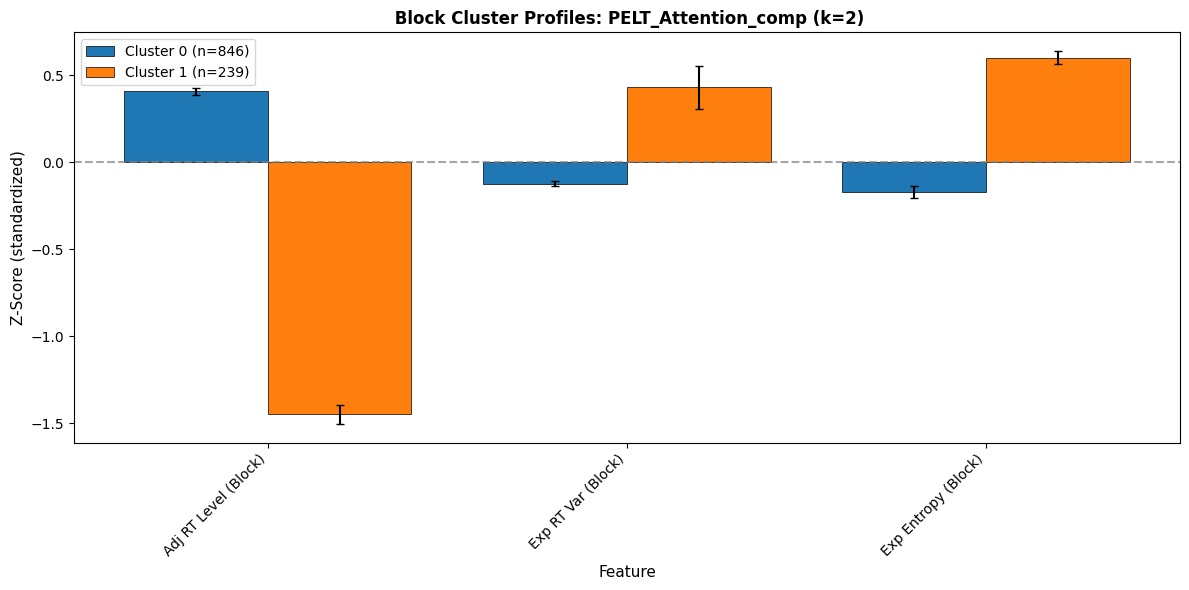

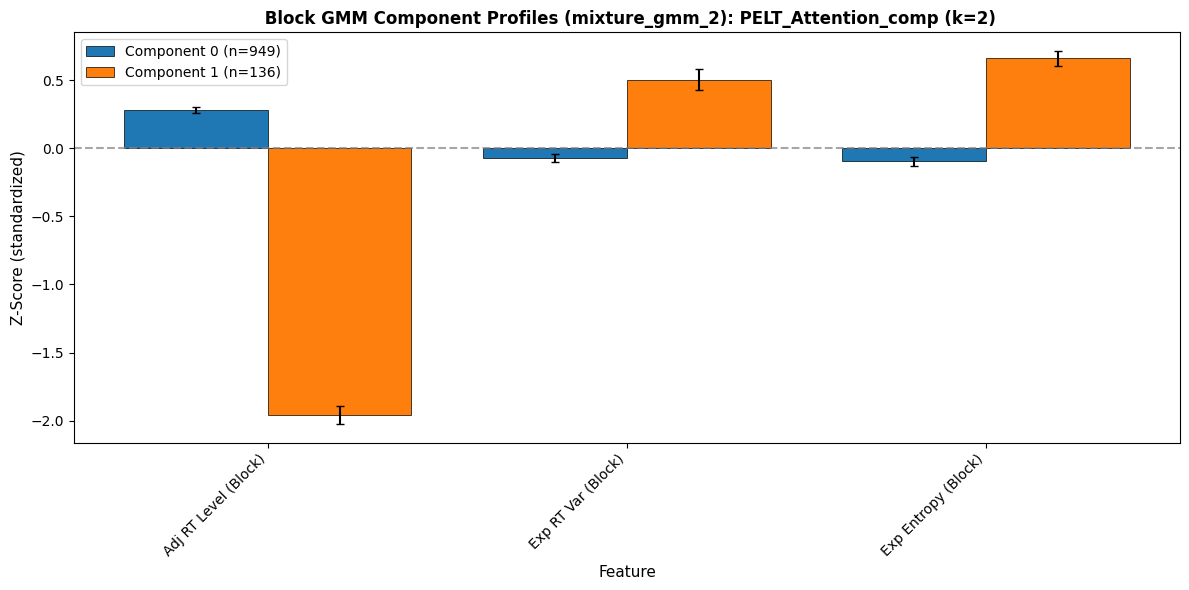

In [21]:
# [notebook only] LVL_2 REPORTING: BLOCK CLUSTER PROFILES
# =============================================================================
# The dynamic-block solutions on the classification features: per cluster, the z-score of its mean (cluster mean -
# mean over blocks, in SDs over blocks) with its SEM, and n per cluster. k-means: one figure per k in CLUSTER_K_LIST
# (Step 1-4's cluster_results). GMM: one figure per fitted GMM, on the GMM's own features, each block in the component
# of its largest posterior (with two components, P(inattentive) > .5: the flags of Step 5). Draws only.

def plot_participant_cluster_profiles(cluster_results, feature_cols, feature_labels, k=3,
                                      title="Block Cluster Profiles", unit="Cluster"):
    """Plot Z-score profiles for each cluster."""
    if k not in cluster_results:
        print(f"k={k} not in results.")
        return None
    
    res = cluster_results[k]
    clustered = res["clustered_data"]
    available = [c for c in feature_cols if c in clustered.columns]
    available_labels = [feature_labels[feature_cols.index(c)] for c in available]
    
    # Add n_trials if available
    plot_cols = available.copy()
    plot_labels = available_labels.copy()
    if "n_trials" in clustered.columns:
        plot_cols.append("n_trials")
        plot_labels.append("n_trials")
    
    # Compute Z-scores
    cluster_means = clustered.groupby("cluster")[plot_cols].mean()
    cluster_stds = clustered.groupby("cluster")[plot_cols].std()
    cluster_counts = clustered.groupby("cluster").size()
    
    overall_mean = clustered[plot_cols].mean()
    overall_std = clustered[plot_cols].std()
    z_scores = (cluster_means - overall_mean) / overall_std
    z_score_sems = cluster_stds / np.sqrt(cluster_counts.values[:, None])
    z_score_sems = z_score_sems / overall_std
    
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(plot_labels))
    width = 0.8 / k
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    for c in range(k):
        offset = (c - k/2 + 0.5) * width
        label = f"{unit} {c} (n={cluster_counts.get(c, 0)})"
        ax.bar(x + offset, z_scores.loc[c], width, yerr=z_score_sems.loc[c], 
               label=label, color=colors[c % len(colors)], capsize=3, edgecolor='black', linewidth=0.5)
    
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.set_ylabel("Z-Score (standardized)", fontsize=11)
    ax.set_xlabel("Feature", fontsize=11)
    ax.set_title(f" {title}: {ANALYSIS_METHOD} (k={k})", fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(plot_labels, rotation=45, ha="right")
    ax.legend(loc="best")
    plt.tight_layout()
    return fig


if cluster_results is not None:
    for k in CLUSTER_K_LIST:
        fig = plot_participant_cluster_profiles(cluster_results, CLUSTER_FEATURE_COLS, CLUSTER_FEATURE_LABELS, k=k)
        if fig:
            plt.show()
else:
    print("Clustering was skipped (insufficient data) -- no k-means profiles.")

_gmm_drawn = set()
for _arm, _res in gmm_results_by_method.get(ANALYSIS_METHOD, {}).items():
    _base = _arm.split("·")[0]                      # the labelling rules of one fit share its components
    if _base in _gmm_drawn:
        continue
    _gmm_drawn.add(_base)
    _k = int(_res["gmm"].n_components)
    _cl = _res["selection_df"].rename(columns={"_component": "cluster"})
    fig = plot_participant_cluster_profiles({_k: {"clustered_data": _cl}}, CLUSTER_FEATURE_COLS, CLUSTER_FEATURE_LABELS,
                                            k=_k, title=f"Block GMM Component Profiles ({_base})", unit="Component")
    if fig:
        plt.show()


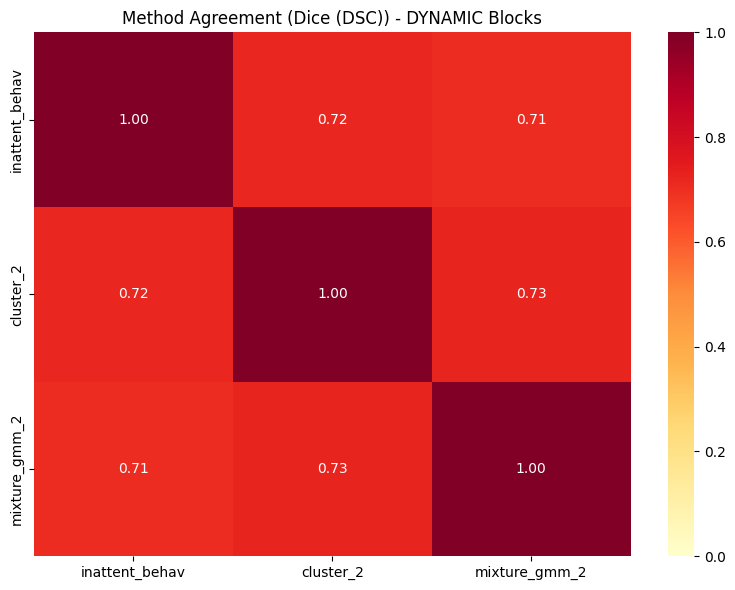

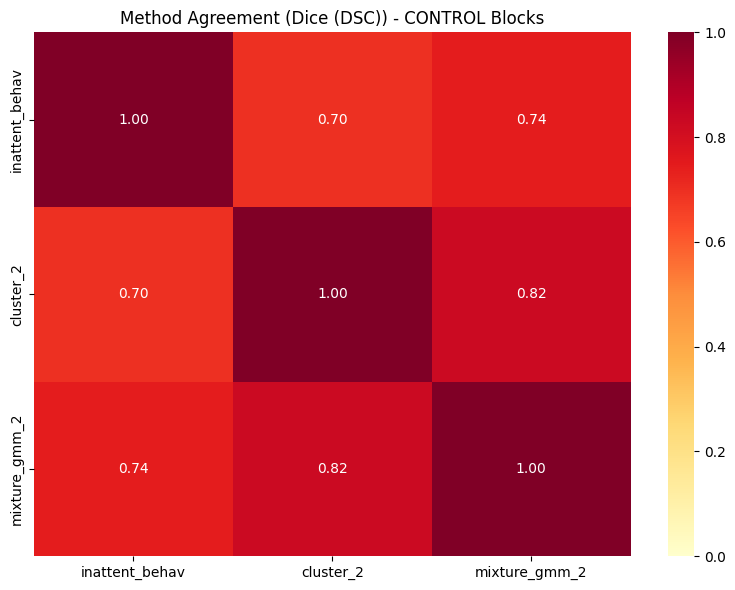

In [22]:
# [notebook only] LVL_2 REPORTING: METHOD AGREEMENT
# =============================================================================
# Overlap (LVL_2_CONFIG["overlap_stat"]: Jaccard or Dice) of the blocks each removal method flags, between every pair
# of methods: dynamic blocks, then control blocks (Step 5's bad_blocks_by_method). Draws only.
import seaborn as sns


def get_flagged_blocks(bad_blocks_dict, block_type, detection_method):
    """Extract unique (id, session, block) tuples flagged by a method.
    
    Args:
        bad_blocks_dict: bad_blocks_by_method dictionary
        block_type: "dynamic", "control", or "participant" (which block definition)
        detection_method: "inattent_behav", "mixture_gmm", "cluster"
    
    Note: Normalizes types to (str, str, int) for consistent comparison across methods.
    """
    # Map block_type to the actual method name used in bad_blocks_by_method
    method_mapping = {
        "dynamic": ANALYSIS_METHOD,
        "control": CONTROL_METHOD,
        "participant": "participant"
    }
    method_name = method_mapping.get(block_type, block_type)
    
    if method_name not in bad_blocks_dict:
        return set()
    if detection_method not in bad_blocks_dict[method_name]:
        return set()
    
    bad_df = bad_blocks_dict[method_name][detection_method]
    if isinstance(bad_df, pd.DataFrame) and len(bad_df) > 0:
        if all(c in bad_df.columns for c in ["id", "session", "block"]):
            # Normalize types for consistent comparison
            # Convert id and session to string, block to int
            return set(zip(
                bad_df["id"].astype(str), 
                bad_df["session"].astype(str), 
                bad_df["block"].astype(float).astype(int)
            ))
    return set()


# Detection methods to analyze
detection_methods = []
for rm in REMOVAL_METHODS:
    if rm not in ["dynamic", "control", "participant", "none"]:
        detection_methods.append(rm)

for bt in ["dynamic", "control"]:
    flagged_by_method = {dm: get_flagged_blocks(bad_blocks_by_method, bt, dm) for dm in detection_methods}
    methods_with_data = [m for m in detection_methods if len(flagged_by_method[m]) > 0]
    if len(methods_with_data) >= 2:
        overlap_matrix = pd.DataFrame(index=methods_with_data, columns=methods_with_data, dtype=float)
        for m1 in methods_with_data:
            for m2 in methods_with_data:
                overlap_matrix.loc[m1, m2] = set_overlap(flagged_by_method[m1], flagged_by_method[m2], empty=1.0)
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(overlap_matrix.astype(float), annot=True, cmap="YlOrRd",
                    vmin=0, vmax=1, ax=ax, fmt=".2f")
        ax.set_title(f"Method Agreement ({overlap_stat_name()}) - {bt.upper()} Blocks")
        plt.tight_layout()
        plt.show()
    else:
        print(f"{bt}: fewer than two removal methods flag blocks -- no agreement heatmap")


In [23]:
# [cell 49]
# =============================================================================
# STEP 5d: H2 INPUTS -- THE RUN'S DATASETS, FLAGGED UNITS, POSTERIORS AND BLOCK TABLES
# =============================================================================
# The inputs of the H2 tests and the classification summaries (Step 5e) and the post hoc analyses (Step 10), built
# from Step 5's fits:
#   DATASETS  the run's datasets: the T2 run is "T2 calibration", the T3 run "T3 only"
#   FLAGS     the flagged units of every arm and design: block keys "id_session_block" (dynamic, control),
#             session keys "id_session", participant ids (every participant with a flagged session)
#   POST      the GMM's P(inattentive) of every unit it was fitted on, per design
#   BLOCKS    per dataset x carried solution: the dynamic blocks with their features and the solution's flag
# Every random stream below is keyed by its dataset and solution labels, so a run reproduces the values it would
# have in any other order. POST_HOC collects the result tables and POST_REPLICATES the bootstrap replicates the
# final report needs across runs; Step 12 writes both.
import zlib
from statsmodels.stats.multitest import multipletests

SEED = int(LVL_2_CONFIG["random_seed"])
B = int(LVL_2_CONFIG["h2_boot_n"])
B_ARI = int(LVL_2_CONFIG["stability_refits"])
MIN_COVERAGE = float(LVL_2_CONFIG["h2_min_coverage"])
MIN_STIM_A = int(LVL_2_CONFIG["h2_robustness_a_min_stimuli"])
N_SPLITS = int(LVL_2_CONFIG["h2_robustness_b_splits"])
MIN_UNITS = int(LVL_2_CONFIG["h2_robustness_b_min_raters"])
POSTERIOR_THRESHOLDS = tuple(float(t) for t in LVL_2_CONFIG["gmm_posterior_thresholds"])
MIN_REMOVAL_UNITS = int(LVL_2_CONFIG["irr_min_units"])
NULL_REPS = {g: int(n) for g, n in LVL_2_CONFIG["irr_null_reps"].items()}
SCALES = list(LVL_2_CONFIG["scale_ranges"])
SCALE_RANGES, SCALE_TYPES = LVL_2_CONFIG["scale_ranges"], LVL_2_CONFIG["scale_types"]
BLOCK_COL, CONTROL_COL = f"block_{ANALYSIS_METHOD}", f"block_{CONTROL_METHOD}"
POST_HOC, POST_REPLICATES = {}, {}

RUN_KEY = "both" if len(conditions) > 1 else str(conditions[0])
DATASETS = {"T2": {"T2 calibration": ("T2", ["T2"], "independent")},
            "T3": {"T3 only": ("T3", ["T3"], "independent")},
# [pooled pathway: practical-application folder] the T2 + T3 run: the pooled fit, overall and restricted to each condition
#>             "both": {"Pooled, overall": ("both", ["T2", "T3"], "pooled"),
#>                      "Pooled, T2": ("both", ["T2"], "pooled-derived"),
#>                      "Pooled, T3": ("both", ["T3"], "pooled-derived")},
            }[RUN_KEY]
DS = list(DATASETS)
FDF = {RUN_KEY: features_df}
COND_OF = features_df.drop_duplicates("id").set_index("id")["condition"].to_dict()
key3 = lambda i, s, b: f"{int(float(i))}_{int(float(s))}_{int(float(b))}"
DESIGNS = ["dynamic", "control", "session", "participant"]
_DESIGN_SRC = {"dynamic": ANALYSIS_METHOD, "control": CONTROL_METHOD, "session": "participant"}

# the carried solutions (one k-means and one GMM arm) and the behavioural heuristic
SOLUTION_LABEL = {**{f"cluster_{k}": f"k-means ({k})" for k in CLUSTER_K_LIST},
                  **{f"mixture_gmm_{k}": f"GMM ({k})" for k in GMM_K_LIST}}
PICKS = {SOLUTION_LABEL[a]: (RUN_KEY, a) for a in REMOVAL_METHODS if a in SOLUTION_LABEL}
P0 = {sol: 1.0 / int(arm.rsplit("_", 1)[1]) for sol, (_, arm) in PICKS.items()}
ARMS = {**{sol: arm for sol, (_, arm) in PICKS.items()}, "Heuristic": "inattent_behav"}


def _flag_sets(arm):
    """Flagged units of one arm in every design (FLAGS layout)."""
    out = {}
    for des, src_ in _DESIGN_SRC.items():
        bb = bad_blocks_by_method.get(src_, {}).get(arm, pd.DataFrame())
        if bb is None or not len(bb):
            out[des] = set()
        elif des == "session":
            out[des] = {f"{int(i)}_{int(s)}" for i, s in bb[["id", "session"]].values}
        else:
            out[des] = {key3(i, s, b) for i, s, b in bb[["id", "session", "block"]].values}
    out["participant"] = {int(k.split("_")[0]) for k in out["session"]}
    return out


FLAGS = {RUN_KEY: {arm: _flag_sets(arm) for arm in ARMS.values()}}

# posteriors of the GMM arms, per design (unit key -> P(inattentive))
POST = {}
for _arm in [a for a in REMOVAL_METHODS if a.startswith("mixture_gmm")]:
    for des, src_ in _DESIGN_SRC.items():
        d = gmm_block_df_by_method.get(src_, {}).get(_arm)
        if d is None:
            continue
        keys = ([key3(i, s, b) for i, s, b in d[["id", "session", "block"]].values] if des != "session"
                else [f"{int(i)}_{int(s)}" for i, s in d[["id", "session"]].values])
        POST.setdefault(_arm, {})[des] = pd.Series(d["p_inattentive"].to_numpy(float), index=keys)
    for des in _DESIGN_SRC:
        p_ = POST.get(_arm, {}).get(des)
        if p_ is not None and not (p_.index.is_unique and p_.between(0, 1).all()):
            raise ValueError(f"{_arm} {des}: posteriors are not one per unit within [0, 1]")

# ---- block tables of the carried solutions: features of every dynamic block, the solution's flag ----------------
FEAT_LABELS = {
    "RT level": [("Composite (adj. log-RT residual)", "adj_rt_level_block"), ("Log RT (log s)", "logrt_level"),
                 ("Raw RT (s)", "rawrt_level")],
    "RT variance": [("Extremized", "exp_rt_var"), ("Box-Cox transformed", "rt_var_tr"),
                    ("Composite (age-adjusted)", "rt_var_composite"), ("Log RT variance", "logrt_var"),
                    ("Raw RT variance (s²)", "rawrt_var")],
    "Entropy": [("Extremized", "exp_entropy"), ("Box-Cox transformed", "entropy_tr"),
                ("Composite (age-adjusted)", "entropy_composite"), ("Raw (unadjusted mean)", "entropy_raw")],
    "RT level per scale": [(s, f"rt_level_{s}") for s in SCALES],
    "RT variance per scale": [(s, f"rt_var_{s}_preadj") for s in SCALES],
    "Entropy per scale": [(s, f"entropy_{s}_preadj") for s in SCALES]}


def block_features(solution):
    """The run's dynamic block matrix (Step 5) with the composites before the transform, the solution's extremized
    features and the block means of raw and log RT."""
    arm = PICKS[solution][1]
    bm = block_matrices[ANALYSIS_METHOD].copy()
    bm["rt_var_composite"], bm["entropy_composite"] = bm["rt_var_block"], bm["entropy_block"]
    gm = "_gmm" if arm.startswith("mixture") else ""
    bm["exp_rt_var"], bm["exp_entropy"] = bm[f"exp_rt_var_block{gm}"], bm[f"exp_entropy_block{gm}"]
    bm["entropy_raw"] = bm[[f"entropy_{s}_preadj" for s in SCALES]].mean(axis=1)
    f = FDF[RUN_KEY].dropna(subset=[BLOCK_COL]).copy()
    rt = f[[f"{s}_rt" for s in SCALES]].to_numpy(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        lrt = np.log(np.where(rt > 0, rt, np.nan))
    f["_raw"], f["_log"] = np.nanmean(rt, 1), np.nanmean(lrt, 1)
    f["_rti"] = f[[f"{s}_rt_input" for s in SCALES]].mean(axis=1)
    for i, s in enumerate(SCALES):
        f[f"_r_{s}"], f[f"_l_{s}"] = rt[:, i], lrt[:, i]
    g = f.groupby(["id", "session", BLOCK_COL])
    x = pd.DataFrame({"rawrt_level": g["_raw"].mean(), "logrt_level": g["_log"].mean(),
                      "rawrt_var": g[[f"_r_{s}" for s in SCALES]].var().mean(axis=1),
                      "logrt_var": g[[f"_l_{s}" for s in SCALES]].var().mean(axis=1), "_adj_check": g["_rti"].mean(),
                      **{f"rt_level_{s}": g[f"{s}_rt_input"].mean() for s in SCALES},
                      "condition": g["condition"].first()}).reset_index().rename(columns={BLOCK_COL: "block"})
    bm = bm.merge(x, on=["id", "session", "block"], how="left")
    bm["key"] = [key3(i, s, b) for i, s, b in bm[["id", "session", "block"]].values]
    return bm


BLOCKS = {}            # (dataset, solution) -> block table with features and the flag
for ds, (cd, conds, _) in DATASETS.items():
    for sol, (_, arm) in PICKS.items():
        bm = block_features(sol)
        bm = bm[bm.condition.isin(conds)].copy()
        bm["flagged"] = bm.key.isin(FLAGS[cd][arm]["dynamic"])
        _want = {k for k in FLAGS[cd][arm]["dynamic"] if COND_OF.get(int(k.split("_")[0])) in conds}
        if not (_want <= set(bm.key) and int(bm.flagged.sum()) == len(_want)):
            raise ValueError(f"{ds} {sol}: flagged blocks missing from the block table")
        if not np.allclose(bm.adj_rt_level_block, bm._adj_check, equal_nan=True):
            raise ValueError(f"{ds} {sol}: adj_rt_level_block is not the block mean of the stimulus means of rt_input")
        BLOCKS[(ds, sol)] = bm
print(f"STEP 5d: run {RUN_KEY}; datasets {DS}; solutions {list(PICKS)}; "
      + "; ".join(f"{sol} {len(FLAGS[RUN_KEY][arm]['dynamic'])} flagged dynamic blocks" for sol, (_, arm) in PICKS.items()))


STEP 5d: run T3; datasets ['T3 only']; solutions ['k-means (2)', 'GMM (2)']; k-means (2) 239 flagged dynamic blocks; GMM (2) 136 flagged dynamic blocks


In [24]:
# [cell 50]
# =============================================================================
# STEP 5e: H2 TESTS AND THE CARRIED SOLUTIONS
# =============================================================================
# Per dataset of this run (Step 5d) and carried solution:
#   H2 size     flagged share of the dynamic blocks vs the equal-profile share 1/k, one-sided, participant-cluster
#               bootstrap (participants resampled with all their blocks)
#   H2 speed    flagged - unflagged block RT level (adj_rt_level_block), one-sided, the same resamples
#   H2 IRR      Krippendorff's alpha of flagged vs unflagged responses per scale x condition, mean over the cells,
#               two-sided, stimulus-paired bootstrap (one stimulus resample per condition and replicate, raters fixed);
#               a row is excluded from inference when either matrix of a cell rates < h2_min_coverage of the stimuli
#               at least twice
#   robustness  A: participants with >= h2_robustness_a_min_stimuli flagged and unflagged stimuli; B: rater-disjoint
#               halves of the flagged participants (a split enters only when both matrices of every cell rate
#               >= h2_min_coverage of the stimuli at least twice); C: trial-weighted and participant-weighted shares
#   then the descriptive alpha of every cell, the overlap (DSC) with the behavioural heuristic, the stability refits,
#   the labelled component of every fit, the heuristic as a classifier and the block feature tables. q (row) = BH
#   over a row's tests; BH across datasets is the final report's.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score


def smad(x):
    """Scaled MAD = 1.4826 x median absolute deviation."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if len(x) else np.nan


def summ(x):
    """n, median, Q1, Q3, scaled MAD of the finite values of x."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if not len(x):
        return dict(n=0, median=np.nan, q1=np.nan, q3=np.nan, smad=np.nan)
    return dict(n=len(x), median=np.median(x), q1=np.percentile(x, 25), q3=np.percentile(x, 75), smad=smad(x))


def summ_str(x, nd=3):
    """'median [Q1, Q3] (sMAD)' of x."""
    s = summ(x)
    return "—" if not s["n"] else f"{s['median']:.{nd}f} [{s['q1']:.{nd}f}, {s['q3']:.{nd}f}] ({s['smad']:.{nd}f})"


def p_one_less(star, null=0.0):
    """One-sided bootstrap p for H1: estimate < null: (#{star >= null} + 1) / (B + 1)."""
    star = np.asarray(star, float); star = star[np.isfinite(star)]
    return (np.sum(star >= null) + 1) / (len(star) + 1) if len(star) else np.nan


def p_two(star, null=0.0):
    """Two-sided bootstrap p: 2 x the smaller tail, each with the +1 correction, capped at 1."""
    star = np.asarray(star, float); star = star[np.isfinite(star)]
    if not len(star):
        return np.nan
    n = len(star)
    return min(1.0, 2 * min((np.sum(star <= null) + 1) / (n + 1), (np.sum(star >= null) + 1) / (n + 1)))


def bh(p):
    """Benjamini-Hochberg q-values; NaN stays NaN."""
    p = np.asarray(p, float); q = np.full(len(p), np.nan); ok = np.isfinite(p)
    if ok.any():
        q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q


def ci(star, lo=2.5, hi=97.5):
    star = np.asarray(star, float); star = star[np.isfinite(star)]
    return (np.percentile(star, lo), np.percentile(star, hi)) if len(star) else (np.nan, np.nan)


def ci_str(lo, hi, nd=3):
    return "—" if not (np.isfinite(lo) and np.isfinite(hi)) else f"[{lo:.{nd}f}, {hi:.{nd}f}]"


CATS = {s: np.arange(SCALE_RANGES[s][0], SCALE_RANGES[s][1] + 1, dtype=float) for s in SCALES}
LEVEL = {s: SCALE_TYPES[s] if SCALE_TYPES[s] in ("nominal", "ordinal") else "interval" for s in SCALES}
UNIVERSE = {c: np.array(sorted(features_df.loc[features_df.condition == c, "stim_label"].dropna().unique()))
            for c in conditions}
# the stimulus resamples of Step 8 (item_boot_weights, seeded by the condition's position among the handoff's
# sorted condition labels)
W_COND = {c: item_boot_weights(len(UNIVERSE[c]), B, SEED, BOOT_CONDITION_INDEX[c]) for c in conditions}


def response_rows(cd_run, cond, scale, ids=None, fdf=None):
    """The scale's responses in one condition: rows, stimulus index, category index, and the repeat mask
    (False for a masked repeat exposure). ids: keep only these participants; fdf: the frames to read (default FDF)."""
    f = (FDF if fdf is None else fdf)[cd_run]
    f = f[(f.condition == cond) & f[f"{scale}_response"].notna()]
    if ids is not None:
        f = f[f.id.isin(ids)]
    item = pd.Index(UNIVERSE[cond]).get_indexer(f.stim_label)
    cat = (f[f"{scale}_response"].to_numpy(float) - CATS[scale][0]).astype(int)
    assert (item >= 0).all() and (cat >= 0).all() and (cat < len(CATS[scale])).all()
    return f, item, cat, ~f["_repeat"].to_numpy(bool)


def cell_alpha(N, scale, cond, boot=True):
    a = alpha_counts(N, LEVEL[scale], CATS[scale])
    return a, (alpha_counts(N, LEVEL[scale], CATS[scale], W=W_COND[cond]) if boot else None)


def cluster_boot(bm, key, p0):
    """Participant-cluster bootstrap of the size shares and the speed contrast of one block table."""
    g = bm.groupby("id"); ids = g.size().index
    nb, nf = g.size().to_numpy(float), g.flagged.sum().to_numpy(float)
    tb = g.n_trials.sum().to_numpy(float)
    tf = bm[bm.flagged].groupby("id").n_trials.sum().reindex(ids, fill_value=0).to_numpy(float)
    x = bm.adj_rt_level_block
    agg = lambda sel, v: v[sel].groupby(bm.id[sel]).sum().reindex(ids, fill_value=0).to_numpy(float)
    Sf, Su = agg(bm.flagged, x), agg(~bm.flagged, x); Qf, Qu = agg(bm.flagged, x ** 2), agg(~bm.flagged, x ** 2)
    Nf, Nu = nf, nb - nf
    rng = np.random.default_rng([SEED, zlib.crc32(key.encode())])
    W = rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids)), size=B).astype(float)

    def stats_(w):
        nf_, nu_ = w @ Nf, w @ Nu
        mf, mu = (w @ Sf) / nf_, (w @ Su) / nu_
        vf, vu = (w @ Qf - nf_ * mf ** 2) / (nf_ - 1), (w @ Qu - nu_ * mu ** 2) / (nu_ - 1)
        sd = np.sqrt(((nf_ - 1) * vf + (nu_ - 1) * vu) / (nf_ + nu_ - 2))
        return dict(share_blocks=(w @ nf) / (w @ nb), share_trials=(w @ tf) / (w @ tb), share_ptw=(w @ (nf / nb)) / w.sum(-1),
                    delta=mf - mu, d=(mf - mu) / sd)
    with np.errstate(invalid="ignore", divide="ignore"):
        pt = {k: float(v) for k, v in stats_(np.ones(len(ids))).items()}
        bt = stats_(W)
    return pt, bt, len(ids)


def irr_contrast(ds, sol, ids=None, flagged_keys=None, fdf=None):
    """Cells of alpha flagged vs unflagged (per scale x condition) and the row contrast with its bootstrap."""
    cd, conds, _ = DATASETS[ds]; arm = PICKS[sol][1]
    fl = FLAGS[cd][arm]["dynamic"] if flagged_keys is None else flagged_keys
    cells = []
    for cond in conds:
        for s in SCALES:
            f, item, cat, irr = response_rows(cd, cond, s, ids, fdf)
            k = np.array([key3(i, ss, b) for i, ss, b in f[["id", "session", BLOCK_COL]].values])
            isf = np.isin(k, list(fl))
            I, Cn = len(UNIVERSE[cond]), len(CATS[s])
            Nf, Nu = counts_table(item, cat, I, Cn, isf & irr), counts_table(item, cat, I, Cn, ~isf & irr)
            Na = counts_table(item, cat, I, Cn, irr)
            af, bf = cell_alpha(Nf, s, cond); au, bu = cell_alpha(Nu, s, cond)
            cells.append(dict(cond=cond, scale=s, a_all=alpha_counts(Na, LEVEL[s], CATS[s]), a_f=af, a_u=au, bf=bf, bu=bu,
                              n_f=int((isf & irr).sum()), n_u=int((~isf & irr).sum()), n_masked=int((~irr).sum()),
                              raters_f=f.id[isf & irr].nunique(), raters_u=f.id[~isf & irr].nunique(),
                              cov_f=coverage(Nf), cov_u=coverage(Nu), stim_f=int((Nf.sum(1) > 0).sum()),
                              stim_u=int((Nu.sum(1) > 0).sum())))
    star = np.mean([c["bf"] for c in cells], 0) - np.mean([c["bu"] for c in cells], 0)
    return cells, star


def h2_rows(store, p0map):
    size, speed, irr = [], [], []
    for (ds, sol), r in store.items():
        pt, bt, p0 = r["pt"], r["bt"], p0map[sol]; bm = r.get("bm", BLOCKS.get((ds, sol)))
        size.append({"Dataset": ds, "Solution": sol, "p0": p0, "Participants": r["P"], "Blocks": len(bm),
                     "Flagged blocks": int(bm.flagged.sum()), "Share (blocks)": pt["share_blocks"],
                     "95% upper bound": np.percentile(bt["share_blocks"], 95), "Share − p0": pt["share_blocks"] - p0,
                     "Share / p0": pt["share_blocks"] / p0, "p": p_one_less(bt["share_blocks"], p0)})
        f, u = bm.loc[bm.flagged, "adj_rt_level_block"], bm.loc[~bm.flagged, "adj_rt_level_block"]
        speed.append({"Dataset": ds, "Solution": sol, "Participants": r["P"], "Flagged Mdn [Q1, Q3] (sMAD)": summ_str(f),
                      "Flagged M (SD)": f"{f.mean():.3f} ({f.std(ddof=1):.3f})", "Unflagged M (SD)": f"{u.mean():.3f} ({u.std(ddof=1):.3f})",
                      "Unflagged Mdn [Q1, Q3] (sMAD)": summ_str(u), "Δ (flagged − unflagged)": pt["delta"],
                      "95% upper bound": np.percentile(bt["delta"][np.isfinite(bt["delta"])], 95),
                      "exp(Δ) (RT ratio)": np.exp(pt["delta"]), "d": pt["d"],
                      "d 95% upper bound": np.percentile(bt["d"][np.isfinite(bt["d"])], 95), "p": p_one_less(bt["delta"], 0.0)})
        c = r["cells"]; af, au = np.mean([x["a_f"] for x in c]), np.mean([x["a_u"] for x in c])
        cov_ok = min(min(x["cov_f"], x["cov_u"]) for x in c) >= MIN_COVERAGE       # both matrices of every cell
        lo, hi = ci(r["irr_star"]) if cov_ok else (np.nan, np.nan)
        irr.append({"Dataset": ds, "Solution": sol, "Cells": len(c), "α flagged (mean of cells)": af,
                    "α unflagged (mean of cells)": au, "Δα": af - au, "95% CI": ci_str(lo, hi),
                    "α ratio (flagged / unflagged)": af / au, "α flagged across cells Mdn [Q1, Q3] (sMAD)": summ_str([x["a_f"] for x in c]),
                    "α flagged across cells M (SD)": f"{af:.3f} ({np.std([x['a_f'] for x in c], ddof=1):.3f})",
                    "α unflagged across cells M (SD)": f"{au:.3f} ({np.std([x['a_u'] for x in c], ddof=1):.3f})",
                    "α unflagged across cells Mdn [Q1, Q3] (sMAD)": summ_str([x["a_u"] for x in c]),
                    "Min coverage flagged": min(x["cov_f"] for x in c), "Min coverage unflagged": min(x["cov_u"] for x in c),
                    "p": p_two(r["irr_star"]) if cov_ok else np.nan})
    size, speed, irr = pd.DataFrame(size), pd.DataFrame(speed), pd.DataFrame(irr)
    for i in range(len(size)):
        size.loc[i, "q (row)"], speed.loc[i, "q (row)"], irr.loc[i, "q (row)"] = bh([size.p[i], speed.p[i], irr.p[i]])
    speed["Direction"] = np.where(speed["Δ (flagged − unflagged)"] < 0, "flagged faster", "flagged slower")
    irr["Direction"] = np.where(irr.p.isna(), "excluded (coverage)",
                                np.where(irr["Δα"] < 0, "flagged less reliable", "flagged more reliable"))
    size["Direction"] = np.where(size["Share (blocks)"] < size.p0, "minority", "not a minority")
    return size, speed, irr


# ---- H2 primary ------------------------------------------------------------------------------------------------
H2 = {}
for ds in DS:
    for sol in PICKS:
        pt, bt, P = cluster_boot(BLOCKS[(ds, sol)], f"h2|{ds}|{sol}", P0[sol])
        cells, star = irr_contrast(ds, sol)
        H2[(ds, sol)] = dict(pt=pt, bt=bt, P=P, cells=cells, irr_star=star)
H2_SIZE, H2_SPEED, H2_IRR = h2_rows(H2, P0)
POST_HOC.update(h2_size=H2_SIZE, h2_speed=H2_SPEED, h2_irr=H2_IRR)

# ---- robustness A: participants with >= MIN_STIM_A flagged AND unflagged stimuli --------------------------------
def stim_counts(ds, sol):
    cd, conds, _ = DATASETS[ds]; fl = FLAGS[cd][PICKS[sol][1]]["dynamic"]
    f = FDF[cd]; f = f[f.condition.isin(conds) & f[BLOCK_COL].notna()]
    isf = pd.Series([key3(i, s, b) in fl for i, s, b in f[["id", "session", BLOCK_COL]].values], index=f.index)
    return isf.groupby(f.id).agg(flagged="sum", total="size").assign(unflagged=lambda d: d.total - d.flagged)


HA = {}
for ds in DS:
    for sol in PICKS:
        sc = stim_counts(ds, sol); ids = set(sc.index[(sc.flagged >= MIN_STIM_A) & (sc.unflagged >= MIN_STIM_A)])
        bmA = BLOCKS[(ds, sol)][BLOCKS[(ds, sol)].id.isin(ids)]
        pt, bt, P = cluster_boot(bmA, f"h2A|{ds}|{sol}", P0[sol])
        cells, star = irr_contrast(ds, sol, ids=ids)
        HA[(ds, sol)] = dict(pt=pt, bt=bt, P=P, cells=cells, irr_star=star, bm=bmA)
A_SIZE, A_SPEED, A_IRR = h2_rows(HA, P0)
rows = []
for i in range(len(A_SIZE)):
    q = bh([A_SIZE.p[i], A_SPEED.p[i], A_IRR.p[i]])
    ds, sol = A_SIZE.Dataset[i], A_SIZE.Solution[i]
    for (test, est, bound, p, qq, prim) in (
            ("size (blocks), one-sided", A_SIZE["Share (blocks)"][i], f"≤ {A_SIZE['95% upper bound'][i]:.3f}", A_SIZE.p[i], q[0], H2_SIZE["Share (blocks)"][i]),
            ("speed Δ, one-sided", A_SPEED["Δ (flagged − unflagged)"][i], f"≤ {A_SPEED['95% upper bound'][i]:.3f}", A_SPEED.p[i], q[1], H2_SPEED["Δ (flagged − unflagged)"][i]),
            ("IRR Δα, two-sided", A_IRR["Δα"][i], A_IRR["95% CI"][i], A_IRR.p[i], q[2], H2_IRR["Δα"][i])):
        rows.append({"Dataset": ds, "Solution": sol, "Participants": A_SIZE.Participants[i],
                     "Participants (full sample)": H2_SIZE.Participants[i], "Test": test, "Estimate": est,
                     "Bound / 95% CI": bound, "Full-sample estimate": prim, "Change": est - prim, "p": p, "q (row)": qq})
POST_HOC["h2_robustness_a"] = pd.DataFrame(rows)


# ---- robustness B: rater-disjoint split within the flagged participants (IRR) ------------------------------------
def robustness_b(ds, sol):
    cd, conds, _ = DATASETS[ds]; arm = PICKS[sol][1]; fl = FLAGS[cd][arm]["dynamic"]
    ids = np.array(sorted(BLOCKS[(ds, sol)].loc[BLOCKS[(ds, sol)].flagged, "id"].unique()))
    rng = np.random.default_rng([SEED, zlib.crc32(f"h2B|{ds}|{sol}".encode())])
    per = B // N_SPLITS
    data = {}
    for cond in conds:
        for s in SCALES:
            f, item, cat, irr = response_rows(cd, cond, s)
            k = np.array([key3(i, ss, b) for i, ss, b in f[["id", "session", BLOCK_COL]].values])
            data[(cond, s)] = (f.id.to_numpy(), item, cat, np.isin(k, list(fl)), irr)
    point, star, cov_ok, half_n = [], [], [], []
    for sp in range(N_SPLITS):
        perm = rng.permutation(ids); h1, h2 = set(perm[: len(ids) // 2]), set(perm[len(ids) // 2:])
        half_n.append(min(len(h1), len(h2)))
        dp, ds_, ok = [], [], True
        for (cond, s), (rid, item, cat, isf, irr) in data.items():
            I, Cn = len(UNIVERSE[cond]), len(CATS[s])
            Nu = counts_table(item, cat, I, Cn, np.isin(rid, list(h1)) & ~isf & irr)
            Nf = counts_table(item, cat, I, Cn, np.isin(rid, list(h2)) & isf & irr)
            ok &= coverage(Nu) >= MIN_COVERAGE and coverage(Nf) >= MIN_COVERAGE
            Wb = W_COND[cond][sp * per:(sp + 1) * per]
            dp.append(alpha_counts(Nf, LEVEL[s], CATS[s]) - alpha_counts(Nu, LEVEL[s], CATS[s]))
            ds_.append(alpha_counts(Nf, LEVEL[s], CATS[s], W=Wb) - alpha_counts(Nu, LEVEL[s], CATS[s], W=Wb))
        point.append(np.mean(dp)); star.append(np.mean(ds_, 0)); cov_ok.append(ok)
    used = [i for i, ok in enumerate(cov_ok) if ok]          # the splits that meet the coverage floor
    star = np.concatenate([star[i] for i in used]) if used else np.array([np.nan])
    return {"Dataset": ds, "Solution": sol, "Flagged participants": len(ids), "Raters per half (min)": min(half_n),
            "Splits": N_SPLITS, "Splits meeting the coverage floor (%)": 100 * np.mean(cov_ok),
            "Δα (mean over splits)": np.mean([point[i] for i in used]) if used else np.nan,
            "95% CI": ci_str(*ci(star)), "p": p_two(star) if used else np.nan,
            "Eligible": min(half_n) >= MIN_UNITS}


ROB_B = pd.DataFrame([robustness_b(ds, sol) for ds in DS for sol in PICKS])
ROB_B["q (row)"] = ROB_B.p
ROB_B.loc[~ROB_B.Eligible, ["p", "q (row)"]] = np.nan
POST_HOC["h2_robustness_b"] = ROB_B

# ---- robustness C: trial-weighted prevalence and the participant-weighted sensitivity (primary resamples) --------
rows = []
for (ds, sol), r in H2.items():
    for lab, k in (("trial-weighted (robustness C)", "share_trials"), ("participant-weighted (sensitivity)", "share_ptw")):
        rows.append({"Dataset": ds, "Solution": sol, "Estimand": lab, "p0": P0[sol], "Share": r["pt"][k],
                     "95% upper bound": np.percentile(r["bt"][k], 95), "Share − p0": r["pt"][k] - P0[sol],
                     "Block-weighted share (primary)": r["pt"]["share_blocks"], "p": p_one_less(r["bt"][k], P0[sol])})
ROB_C = pd.DataFrame(rows); ROB_C["q (row)"] = ROB_C.p
POST_HOC["h2_robustness_c"] = ROB_C

# ---- descriptive alpha: all, flagged and unflagged responses, per cell and across the cells ----------------------
rows, srows = [], []
for (ds, sol), r in H2.items():
    for c in r["cells"]:
        rows.append({"Dataset": ds, "Solution": sol, "Condition": c["cond"], "Scale": c["scale"], "α all": c["a_all"],
                     "α flagged": c["a_f"], "α unflagged": c["a_u"], "Responses flagged": c["n_f"],
                     "Responses unflagged": c["n_u"], "Raters flagged": c["raters_f"], "Raters unflagged": c["raters_u"],
                     "Stimuli rated (flagged)": c["stim_f"], "Coverage flagged": c["cov_f"], "Coverage unflagged": c["cov_u"]})
    srows.append({"Dataset": ds, "Solution": sol, "Cells": len(r["cells"]),
                  "α all Mdn [Q1, Q3] (sMAD)": summ_str([c["a_all"] for c in r["cells"]]),
                  "α flagged Mdn [Q1, Q3] (sMAD)": summ_str([c["a_f"] for c in r["cells"]]),
                  "α unflagged Mdn [Q1, Q3] (sMAD)": summ_str([c["a_u"] for c in r["cells"]]),
                  "Responses flagged": sum(c["n_f"] for c in r["cells"]), "Responses unflagged": sum(c["n_u"] for c in r["cells"])})
POST_HOC.update(alpha_cells=pd.DataFrame(rows), alpha_summary=pd.DataFrame(srows))


# ---- overlap (DSC) with the behavioural heuristic: dynamic blocks with a participant bootstrap; every design ------
def dsc_boot(ds, sol):
    cd, conds, _ = DATASETS[ds]; A = FLAGS[cd][PICKS[sol][1]]["dynamic"]; Gs = FLAGS[cd]["inattent_behav"]["dynamic"]
    bm = BLOCKS[(ds, sol)]
    c = pd.DataFrame({"id": bm.id, "cond": bm.condition, "i": bm.key.isin(A & Gs), "a": bm.key.isin(A), "g": bm.key.isin(Gs)})
    tot = np.zeros((B, 3)); pt = c[["i", "a", "g"]].sum().to_numpy(float)
    for cond, g in c.groupby("cond"):
        C3 = g.groupby("id")[["i", "a", "g"]].sum().to_numpy(float)
        W = np.random.default_rng([SEED, zlib.crc32(f"dsc|{ds}|{sol}|{cond}".encode())]).multinomial(len(C3), np.full(len(C3), 1 / len(C3)), size=B)
        tot += W @ C3
    return 2 * pt[0] / (pt[1] + pt[2]), 2 * tot[:, 0] / (tot[:, 1] + tot[:, 2]), int(pt[1]), int(pt[2])


DSCB = {(ds, sol): dsc_boot(ds, sol) for ds in DS for sol in PICKS}
rows = []
for (ds, sol), (v, bt, na, ng) in DSCB.items():
    lo, hi = ci(bt)
    rows.append({"Dataset": ds, "Solution": sol, "Flagged": na, "Heuristic flagged": ng, "DSC": v, "95% CI": ci_str(lo, hi)})
    POST_REPLICATES[f"dsc|{ds}|{sol}"] = bt
POST_HOC["dsc_dynamic"] = pd.DataFrame(rows)


def _units_in(cd, conds, des):
    """Every unit of the design in the dataset's conditions (keys as in FLAGS)."""
    f = FDF[cd]; f = f[f.condition.isin(conds)]
    if des == "participant":
        return set(int(i) for i in f.id.unique())
    if des == "session":
        return {f"{int(i)}_{int(s)}" for i, s in f[["id", "session"]].drop_duplicates().values}
    col = BLOCK_COL if des == "dynamic" else CONTROL_COL
    x = f.dropna(subset=[col])[["id", "session", col]].drop_duplicates()
    return {key3(i, s, b) for i, s, b in x.values}


rows = []
for ds, (cd, conds, _) in DATASETS.items():
    for sol, (_, arm) in PICKS.items():
        for des in DESIGNS:
            U = _units_in(cd, conds, des)
            A, G = FLAGS[cd][arm][des] & U, FLAGS[cd]["inattent_behav"][des] & U
            rows.append({"Dataset": ds, "Solution": sol, "Design": des, "Units": len(U), "Flagged": len(A),
                         "Heuristic flagged": len(G), "Both": len(A & G),
                         "DSC": 2 * len(A & G) / (len(A) + len(G)) if (A or G) else np.nan})
POST_HOC["dsc_designs"] = pd.DataFrame(rows)


# ---- stability: refits on blocks resampled with replacement (the LVL2 sweep report's runner, same seeds) ---------
def _ari_chunk(kind, Xs, k, ref, bs, seed, gargs, cond):
    out = []
    for b in bs:
        rng = np.random.RandomState(seed + b)
        idx = rng.choice(len(Xs), size=len(Xs), replace=True)
        if kind == "cluster":
            lab = KMeans(n_clusters=k, random_state=seed + b, n_init=10).fit_predict(Xs[idx])
        else:
            lab = GaussianMixture(n_components=k, covariance_type=gargs[1], random_state=seed + b, n_init=gargs[2],
                                  max_iter=gargs[3]).fit(Xs[idx]).predict(Xs[idx])
        r = [adjusted_rand_score(ref[idx], lab)]
        for c in ("T2", "T3"):
            m = cond[idx] == c
            r.append(adjusted_rand_score(ref[idx][m], lab[m]) if m.sum() > 1 else np.nan)
        # the refit's fastest component (column 0 = adj_rt_level_block, standardised): its share of the resampled
        # blocks, and whether its other two features lie above their means
        Xb = Xs[idx]; mu = pd.DataFrame(Xb).groupby(lab).mean(); f = mu[0].idxmin()
        r += [float(np.mean(lab == f)), float(mu.loc[f, 1] > Xb[:, 1].mean() and mu.loc[f, 2] > Xb[:, 2].mean())]
        out.append(r)
    return out


_GMM_ARGS = (int(LVL_2_CONFIG["random_seed"]), LVL_2_CONFIG["mixture_gmm_covariance_type"],
             int(LVL_2_CONFIG["mixture_gmm_n_init"]), int(LVL_2_CONFIG["mixture_gmm_max_iter"]))


def stability(arm):
    fam, k = arm.rsplit("_", 1); k = int(k); bm = block_matrices[ANALYSIS_METHOD]
    if fam == "cluster":
        X = bm[CLUSTER_FEATURE_COLS].dropna(); Xs = StandardScaler().fit_transform(X)
        ref = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(Xs); seed = SEED
    else:
        X = bm[GMM_FEATURE_COLS].dropna(); Xv = X.to_numpy(float)
        sd = Xv.std(axis=0, ddof=1); sd[sd == 0] = 1.0; Xs = (Xv - Xv.mean(axis=0)) / sd; g = _GMM_ARGS
        ref = GaussianMixture(n_components=k, covariance_type=g[1], random_state=g[0], n_init=g[2],
                              max_iter=g[3]).fit(Xs).predict(Xs); seed = g[0]
    cond = bm.loc[X.index, "id"].map(COND_OF).to_numpy()
    chunks = np.array_split(np.arange(B_ARI), N_JOBS * 2 if N_JOBS > 0 else 2)
    res = Parallel(n_jobs=N_JOBS)(delayed(_ari_chunk)(fam, Xs, k, ref, c, seed, _GMM_ARGS, cond) for c in chunks)
    A = np.array([r for part in res for r in part], float)
    return {"all": A[:, 0], "T2": A[:, 1], "T3": A[:, 2], "fast_share": A[:, 3], "fast_profile": A[:, 4], "n": len(X),
            "n_T2": int((cond == "T2").sum()), "n_T3": int((cond == "T3").sum())}


def ari_row(ds, label, status, a, n):
    s = summ(a); a = a[np.isfinite(a)]
    return {"Dataset": ds, "Solution": label, "Status": status, "Blocks": n, "Refits": len(a), "Median": s["median"],
            "Q1": s["q1"], "Q3": s["q3"], "sMAD": s["smad"], "Mean": a.mean(), "SD": a.std(ddof=1),
            "2.5%": np.percentile(a, 2.5), "97.5%": np.percentile(a, 97.5), "Refits ARI < .50 (%)": 100 * (a < .5).mean()}


_t0 = datetime.now()
ARI = {arm: stability(arm) for _, arm in PICKS.values()}
print(f"stability: {len(ARI)} fits x {B_ARI:,} refits in {(datetime.now() - _t0).total_seconds():.0f} s")
rows = []
for ds in DS:
    cd, conds, kind = DATASETS[ds]
    for sol, (_, arm) in PICKS.items():
        v = ARI[arm]
        a, n = (v["all"], v["n"]) if len(conds) > 1 or cd != "both" else (v[conds[0]], v[f"n_{conds[0]}"])
        rows.append(ari_row(ds, sol, ("refit on this dataset" if cd != "both" else
                                      ("pooled fit, all blocks" if len(conds) > 1 else f"pooled fit, {conds[0]} blocks")), a, n))
POST_HOC["stability"] = pd.DataFrame(rows)
for _, arm in PICKS.values():
    POST_REPLICATES[f"ari|{arm}"] = ARI[arm]["all"]

# ---- the labelled component of every fit: speed ranking, margin, profile; the refits' fastest component ----------
# SPEED_LABELS ([cell 38]) holds every labelling of Step 5 in its order: per design (dynamic, control, session) the
# k-means fits of CLUSTER_K_LIST, then the GMM fits of GMM_K_LIST. P(labelled stays fastest) resamples participants
# with the partition held fixed, one stream per fit.
_srcs = [s for s in block_matrices if s in (ANALYSIS_METHOD, CONTROL_METHOD, "participant")]
_fits = [("k-means", int(k)) for k in CLUSTER_K_LIST] + [("GMM", int(k)) for k in GMM_K_LIST]
if len(SPEED_LABELS) != len(_srcs) * len(_fits):
    raise ValueError(f"expected {len(_srcs) * len(_fits)} labellings in SPEED_LABELS, found {len(SPEED_LABELS)}")
for j, c in enumerate(SPEED_LABELS):
    if c["labeller"] != _fits[j % len(_fits)][0]:
        raise ValueError(f"labelling {j}: {c['labeller']} where {_fits[j % len(_fits)][0]} was expected")
    c["source"], c["k"] = _srcs[j // len(_fits)], _fits[j % len(_fits)][1]
_SRC_DES = {v: k for k, v in _DESIGN_SRC.items()}
_FITDS = DS[0]                                       # the dataset that is the whole fit
rows, comp_rows = [], []
for sol, (_, arm) in PICKS.items():
    fam, k_ = ("k-means" if arm.startswith("cluster") else "GMM"), int(arm.rsplit("_", 1)[1])
    for des, src_ in _DESIGN_SRC.items():
        c = [x for x in SPEED_LABELS if x["source"] == src_ and x["labeller"] == fam and x["k"] == k_]
        if len(c) != 1:
            raise ValueError(f"{sol} {des}: {len(c)} labellings")
        c = c[0]; u = c["units"]
        means = u.groupby("component")["adj_rt_level_block"].mean().sort_values()
        fast, nxt = means.index[0], means.index[1]
        if int(fast) != c["label"]:
            raise ValueError(f"{sol} {des}: the labelled component is not the fastest")
        prof = u.loc[u.component == fast, LVL2_FEATURE_COLS].mean() - u[LVL2_FEATURE_COLS].mean()
        comps = list(means.index); pid = u["id"].to_numpy(); up = np.unique(pid)
        Sm = np.zeros((len(up), len(comps))); Cm = np.zeros((len(up), len(comps)))
        ix = np.searchsorted(up, pid); cx = u["component"].map({cc: j for j, cc in enumerate(comps)}).to_numpy()
        np.add.at(Sm, (ix, cx), u["adj_rt_level_block"].to_numpy(float)); np.add.at(Cm, (ix, cx), 1.0)
        W = np.random.default_rng([SEED, zlib.crc32(f"comp|{_FITDS}|{sol}|{des}".encode())]).multinomial(
            len(up), np.full(len(up), 1 / len(up)), size=B)
        with np.errstate(invalid="ignore", divide="ignore"):
            Mb = (W @ Sm) / (W @ Cm)
        stays = np.mean(Mb[:, 0] < np.nanmin(np.where(np.isnan(Mb[:, 1:]), np.inf, Mb[:, 1:]), axis=1))
        n_f, n_n = int((u.component == fast).sum()), int((u.component == nxt).sum())
        rows.append({"Dataset": _FITDS, "Solution": sol, "Design": des, "Units": len(u), "Components": len(comps),
                     "Labelled (fastest) n": n_f, "Labelled (fastest) %": 100 * n_f / len(u), "Labelled mean speed": means.iloc[0],
                     "Next-fastest n": n_n, "Next-fastest %": 100 * n_n / len(u), "Next-fastest mean speed": means.iloc[1],
                     "Margin": means.iloc[1] - means.iloc[0], "P(labelled stays fastest)": stays,
                     "Labelled Δ Exp RT var": prof["exp_rt_var_block"], "Labelled Δ Exp entropy": prof["exp_entropy_block"],
                     "Both above the grand mean": bool(prof["exp_rt_var_block"] > 0 and prof["exp_entropy_block"] > 0)})
        cm = u.groupby("component")[LVL2_FEATURE_COLS].agg(["mean", "std", "size"])
        for cc in comps:
            comp_rows.append({"Solution": sol, "Design": des, "Component": int(cc), "Speed rank": comps.index(cc) + 1,
                              "Labelled": bool(cc == fast), "Units": int(cm.loc[cc, ("adj_rt_level_block", "size")]),
                              **{f"{f} mean": cm.loc[cc, (f, "mean")] for f in LVL2_FEATURE_COLS},
                              **{f"{f} SD": cm.loc[cc, (f, "std")] for f in LVL2_FEATURE_COLS}})
POST_HOC.update(labelled_components=pd.DataFrame(rows), components=pd.DataFrame(comp_rows))
rows = []
for sol, (_, arm) in PICKS.items():
    a = ARI[arm]; sh, pr = a["fast_share"], a["fast_profile"]
    full = next(r for r in POST_HOC["labelled_components"].to_dict("records") if r["Solution"] == sol and r["Design"] == "dynamic")
    rows.append({"Dataset": _FITDS, "Solution": sol, "Refits": int(np.isfinite(sh).sum()),
                 "Full-data labelled share (%)": full["Labelled (fastest) %"],
                 "Refit fastest-component share: Mdn (%)": 100 * np.nanmedian(sh),
                 "5% (%)": 100 * np.nanpercentile(sh, 5), "95% (%)": 100 * np.nanpercentile(sh, 95),
                 "Refits with share < 10% (%)": 100 * np.nanmean(sh < .10),
                 "Refits whose fastest component lies above the mean on both other features (%)": 100 * np.nanmean(pr)})
POST_HOC["stability_fastest"] = pd.DataFrame(rows)

# ---- the behavioural heuristic as a classifier: the three primary tests on the blocks its rule flags --------------
HEUR_LAB, HEUR_P0 = "Heuristic (a-priori)", 0.5
_KM = next(sol for sol, (_, a) in PICKS.items() if a.startswith("cluster"))
_hstore = {}
for ds in DS:
    _keys = FLAGS[DATASETS[ds][0]]["inattent_behav"]["dynamic"]
    _bm = BLOCKS[(ds, _KM)].copy()
    _bm["flagged"] = _bm.key.isin(_keys)
    BLOCKS[(ds, HEUR_LAB)] = _bm
    _pt, _bt, _P = cluster_boot(_bm, f"heur|{ds}", HEUR_P0)
    _cells, _star = irr_contrast(ds, _KM, flagged_keys=_keys)
    _hstore[(ds, HEUR_LAB)] = dict(pt=_pt, bt=_bt, P=_P, cells=_cells, irr_star=_star, bm=_bm)
H2H_SIZE, H2H_SPEED, H2H_IRR = h2_rows(_hstore, {HEUR_LAB: HEUR_P0})
H2H_SIZE["Cohen's h"] = (2 * np.arcsin(np.sqrt(H2H_SIZE["Share (blocks)"])) - 2 * np.arcsin(np.sqrt(HEUR_P0)))
POST_HOC.update(heuristic_size=H2H_SIZE, heuristic_speed=H2H_SPEED, heuristic_irr=H2H_IRR)


# ---- block counts and feature tables of the carried solutions ------------------------------------------------------
def feature_table(family):
    rows = []
    for ds in DS:
        for sol in PICKS:
            bm = BLOCKS[(ds, sol)]
            for grp, sel in (("overall", slice(None)), ("flagged", bm.flagged), ("unflagged", ~bm.flagged)):
                d = bm.loc[sel]
                rows.append({"Dataset": ds, "Solution": sol, "Group": grp, "Blocks": len(d),
                             **{lab: summ_str(d[col], 3) for lab, col in FEAT_LABELS[family]}})
    return pd.DataFrame(rows)


rows = []
for ds in DS:
    for sol in PICKS:
        bm = BLOCKS[(ds, sol)]; nf = int(bm.flagged.sum()); n = len(bm)
        pf = bm.groupby("id").flagged.any()
        rows.append({"Dataset": ds, "Solution": sol, "Blocks": n, "Flagged n (%)": f"{nf} ({100 * nf / n:.1f})",
                     "Unflagged n (%)": f"{n - nf} ({100 * (n - nf) / n:.1f})", "Participants": len(pf),
                     "Participants with ≥ 1 flagged block": int(pf.sum()),
                     "Trials in flagged blocks n": int(bm.loc[bm.flagged, "n_trials"].sum()),
                     "Trials, all blocks": int(bm.n_trials.sum()),
                     "Trials in flagged blocks (%)": 100 * bm.loc[bm.flagged, "n_trials"].sum() / bm.n_trials.sum(),
                     "Flagged median RT level (composite)": np.median(bm.loc[bm.flagged, "adj_rt_level_block"].dropna()),
                     "Flagged median RT variance (composite)": np.median(bm.loc[bm.flagged, "rt_var_composite"].dropna()),
                     "Flagged median entropy (composite)": np.median(bm.loc[bm.flagged, "entropy_composite"].dropna()),
                     "Unflagged median RT level (composite)": np.median(bm.loc[~bm.flagged, "adj_rt_level_block"].dropna())})
POST_HOC["block_counts"] = pd.DataFrame(rows)
for i, fam in enumerate(FEAT_LABELS):
    POST_HOC[f"block_features_{i}"] = feature_table(fam)
print("STEP 5e: H2 " + "; ".join(f"{r.Dataset} {r.Solution}: share {r['Share (blocks)']:.3f} (q {r['q (row)']:.3g})"
                                 for _, r in H2_SIZE.iterrows()))


stability: 2 fits x 5,000 refits in 28 s
STEP 5e: H2 T3 only k-means (2): share 0.220 (q 0.00015); T3 only GMM (2): share 0.125 (q 0.00015)


In [25]:
# [cell 52]
# =============================================================================
# STEP 8: MULTI-METRIC x MULTI-DESIGN REMOVAL COMPARISON
# =============================================================================
# One table answering, for every (scale, condition, removal_method, design):
#   Baseline      : metric on the unscreened data -- the reference (one per scale x
#                   condition, shared by the four designs)
#   Post          : metric after this design/method removes its flagged units
#   Improvement   : Post - Baseline
#   dRef_Flagged  : Baseline - Post, the flagged removal's reference-relative change
#   Null          : metric after each matched RANDOM removal (irr_null_reps replicates
#                   per metric group), drawn within the scored condition:
#                     dynamic / control : sample as many sessions as hold flagged
#                                         blocks, pool their trials, shuffle, remove
#                                         exactly as many trials as were flagged
#                     session           : remove as many random whole sessions as were
#                                         flagged
#                     participant       : remove as many random whole participants as
#                                         were flagged
#                   One trial-level removal per replicate is applied to every scale
#                   (trials with missing responses stay in the trial index).
#   dRef_Null_Mean: mean of Baseline - Null over the valid replicates
#   D             : per replicate (Baseline - Null) - (Baseline - Post) = Post - Null;
#                   positive = the flagged removal leaves the higher metric
#   Excess        : mean D;  D_Lo / D_Hi : empirical mm_plot_ci% interval of D
#   P_MC          : two-sided Monte Carlo p, 2 x min(#{D <= 0} + 1, #{D >= 0} + 1) / (R + 1)
#   *_PerTrial    : the same per trial removed, each removal by its own count:
#                   (Post - Base) / trials_flagged - (Null - Base) / trials_replicate
#                   (Excess_PerTrial, DpT_Lo / DpT_Hi, P_MC_PerTrial)
#   Null_Valid / Null_Invalid : replicates with a defined metric / without (too few
#                   trials in the sampled sessions, or the metric undefined). Invalid
#                   replicates are counted, never redrawn or zero-filled; the D
#                   statistics need >= 10 valid replicates.
#   Improvement_PerTrial : Improvement / Trials_Removed
#   Per-trial values are absolute changes in the metric per trial removed (alpha units for
#   Alpha). Pct_Removed is the share of the condition's trials removed, a descriptive volume.
#   Improvement_CI_* / Improvement_P_Boot : stimulus-paired bootstrap of Improvement
#                   (mm_plot_ci percentile interval, two-sided p with the +1 correction); the
#                   rows over cells (_step8_null_overall.csv) have the same for the mean over
#                   their cells, of Improvement and of Improvement_PerTrial
#   Coverage_Post : share of the cell's stimuli rated at least twice after the removal
# D's interval and P_MC describe the random-removal null conditional on the observed
# data; they are not participant-level confidence intervals.
# Metrics: Krippendorff's alpha (primary), ICC(#,1) and ICC(#,k) (REML, form
# from irr_icc_form; the pair comes from ONE variance-component fit), Fleiss'
# kappa, and between-/within-rater split-half r_SB. Every metric is scored on the
# same random removals (replicate r is the same removal for every metric and scale;
# a metric group with fewer irr_null_reps uses the first replicates).
# Repeat exposures ([cell 29]) are masked out of every metric; removal volumes
# count every trial.
# THE BOOTSTRAP (vs baseline). One stimulus resample per condition and replicate
# (item_boot_weights, [cell 37]), shared by every scale, design, removal method
# and metric. alpha and kappa score each resample from the item x category
# counts; ICC and split-half put each resampled stimulus copy in as a separate
# stimulus. Step 9 reads the replicates (MM_BOOT) for the vs-baseline design
# contrasts and the D distributions (MM_NULLD) for the between-design contrasts.
# Outputs: _step8_multimetric.csv (one row per comparison), _step8_null_overall.csv
# (the same per condition and over all conditions, D averaged over the scale cells
# within each replicate) and _step8_null_iterations.npz (every null replicate's
# metrics and trials removed, from which every D statistic can be recomputed).
# Designs
#   dynamic     : block_<ANALYSIS_METHOD>   (data-driven CPD blocks)
#   control     : block_<CONTROL_METHOD>    (matched fixed-width control blocks)
#   session     : flagged (id, session) pairs only
#   participant : every session of a flagged rater (full rater removal)
# session and participant share the same labeller output; participant is the
# collapse of session up to the rater.
# =============================================================================

_MM_FORM = LVL_2_CONFIG["irr_icc_form"]
_MM_ITEM_COL = "stim_label"
# Split-half: one split set per scale x condition (splithalf_split_set, [cell 37]) of splithalf_bootstrap_reps random
# splits, seeded by splithalf_seed with the scale and condition. The cell's baseline, its post-removal values and every
# matched-null and bootstrap replicate are scored on that same split set.
import zlib
_MM_SH_SPLITS = int(LVL_2_CONFIG["splithalf_bootstrap_reps"])
_MM_SH_SEED = int(LVL_2_CONFIG["splithalf_seed"])
_MM_CI = float(LVL_2_CONFIG["mm_plot_ci"])
_MM_LO, _MM_HI = (100 - _MM_CI) / 2, 100 - (100 - _MM_CI) / 2
_MM_METRICS = ["Alpha", f"{_MM_FORM}_1", f"{_MM_FORM}_k", "Kappa", "SH_Between", "SH_Within"]
_MM_SWITCH = dict(zip(_MM_METRICS, ["alpha", "icc", "icc", "kappa", "splithalf_between", "splithalf_within"]))
_MM_BGROUP = dict(zip(_MM_METRICS, ["alpha", "icc", "icc", "kappa", "splithalf", "splithalf"]))
_MM_ON = {m: bool(LVL_2_CONFIG[f"irr_mm_{_MM_SWITCH[m]}"]) for m in _MM_METRICS}
_MM_BOOT = LVL_2_CONFIG["irr_boot"]
for _g in ("alpha", "kappa", "icc", "splithalf"):
    if not isinstance(_MM_BOOT.get(_g), dict) or set(_MM_BOOT[_g]) != {"n", "vs_baseline", "design"}:
        raise ValueError(f"LVL_2_CONFIG['irr_boot']['{_g}'] must be a dict with exactly the keys "
                         f"n, vs_baseline, design; got {_MM_BOOT.get(_g)!r}")
_MM_NREPS_CFG = LVL_2_CONFIG["irr_null_reps"]
if (not isinstance(_MM_NREPS_CFG, dict) or set(_MM_NREPS_CFG) != {"alpha", "kappa", "icc", "splithalf"}
        or any(int(v) < 10 for v in _MM_NREPS_CFG.values())):
    raise ValueError("LVL_2_CONFIG['irr_null_reps'] must be a dict with the keys alpha, kappa, icc, splithalf, "
                     f"each >= 10; got {_MM_NREPS_CFG!r}")
_MM_NREPS = {m: int(_MM_NREPS_CFG[_MM_BGROUP[m]]) if _MM_ON[m] else 0 for m in _MM_METRICS}
_MM_RMAX = max(_MM_NREPS.values())
_MM_HREPS = max([_MM_NREPS[m] for m in _MM_METRICS if _MM_BGROUP[m] in ("icc", "splithalf")] or [0])
_MM_MIN_VALID = 10                   # valid null replicates needed for the D statistics
# Bootstrap replicates per metric: 0 when the metric is off or none of its tests is on.
_MM_BN = {m: (int(_MM_BOOT[_MM_BGROUP[m]]["n"]) if _MM_ON[m] and any(
              _MM_BOOT[_MM_BGROUP[m]][t] for t in ("vs_baseline", "design")) else 0)
          for m in _MM_METRICS}
_MM_BMAX = max(_MM_BN.values())
_MM_HEAVY = [m for m in _MM_METRICS if _MM_BN[m] and _MM_BGROUP[m] in ("icc", "splithalf")]
_MM_CHUNK = 50                       # replicates per parallel task while ICC / split-half are scored
_MM_CHUNK_LIGHT = 1000               # replicates per task beyond them (alpha / kappa only)

print("=" * 120)
print(f"STEP 8: MULTI-METRIC x MULTI-DESIGN COMPARISON  (ICC form: {_MM_FORM})")
print("=" * 120)
print(f"Metrics      : Krippendorff alpha, {_MM_FORM}(,1), {_MM_FORM}(,k), Fleiss kappa,\n"
      f"               between-/within-rater split-half r_SB ({_MM_SH_SPLITS} splits, one split set per scale x condition "
      f"for the baseline, post-removal, null and bootstrap scores; seed {_MM_SH_SEED})")
print(f"Designs      : dynamic, control, session, participant")
print("Null reps    : " + ", ".join(f"{m} {_MM_NREPS[m]}" for m in _MM_METRICS)
      + "  (matched random removal within the condition: block designs = trials from as many sessions as hold "
        "flagged blocks; session / participant = as many whole units)")
print("Bootstrap    : " + "; ".join(
    f"{m} {_MM_BN[m]} ({', '.join(t for t in ('vs_baseline', 'design') if _MM_BOOT[_MM_BGROUP[m]][t])})"
    if _MM_BN[m] else f"{m} off" for m in _MM_METRICS) + "\n")


_MM_DESIGNS = [
    ("dynamic",     ANALYSIS_METHOD, f"block_{ANALYSIS_METHOD}"),
    ("control",     CONTROL_METHOD,  f"block_{CONTROL_METHOD}"),
    ("session",     "participant",   None),
    ("participant", "participant",   None),
]


def _mm_keys(df, design, block_col):
    """Unit of every row: rater, rater x session, or rater x session x block."""
    k = df["id"].astype(str)
    if design == "participant":
        return k
    k = k + "_" + df["session"].astype(float).astype(int).astype(str)
    if design == "session":
        return k
    return k + "_" + df[block_col].astype(float).astype(int).astype(str)


def _mm_trials(cond):
    """The scored condition's trials, missing responses included: per design the unit of every
    trial (units in order of first appearance) and the session / participant codes the matched
    nulls sample from. Every scale's responses index into these trials."""
    f = features_df[features_df["condition"] == cond] if "condition" in features_df.columns else features_df
    t = {"n": len(f), "units": {}}
    for design, _, block_col in _MM_DESIGNS:
        if block_col is not None and block_col not in f.columns:
            continue
        codes, uniq = pd.factorize(_mm_keys(f, design, block_col))
        t["units"][design] = {"code": codes, "uniq": pd.Index(uniq)}
    t["session"], t["participant"] = t["units"]["session"]["code"], t["units"]["participant"]["code"]
    return t


def _mm_cell(scale, cond, scale_type):
    """One scale x condition as long arrays of its responses, with the trial (row of the
    condition, as in _mm_trials) of every response. Every response is kept, so removal volumes
    count the repeat exposures; `irr` is False for a repeat exposure and keeps it out of every
    metric."""
    f = features_df[features_df["condition"] == cond] if "condition" in features_df.columns else features_df
    rc = f"{scale}_response"
    resp = f[rc].notna().to_numpy()
    universe = pd.Index(sorted(f[_MM_ITEM_COL].dropna().unique()))
    vals = f[rc].to_numpy(dtype=float)[resp]
    cats, cat = np.unique(vals, return_inverse=True)
    return {"item": universe.get_indexer(f[_MM_ITEM_COL][resp]), "cat": cat, "cats": cats,
            "rater": f["id"].to_numpy()[resp], "val": vals, "n_items": len(universe),
            "trial": np.flatnonzero(resp),
            "irr": (~f["_repeat"].to_numpy(dtype=bool)[resp]) if "_repeat" in f.columns else np.ones(len(vals), bool),
            "level": scale_type if scale_type in ("nominal", "ordinal") else "interval",
            "nominal": scale_type == "nominal"}


def _mm_add_split_set(c, scale, cond):
    """The cell's split set (splithalf_split_set), when a split-half metric is on and the scale is not nominal."""
    if not c["nominal"] and (_MM_ON["SH_Between"] or _MM_ON["SH_Within"]):
        c["sh"] = splithalf_split_set(c["rater"], c["irr"], _MM_SH_SPLITS,
                                      [_MM_SH_SEED, zlib.crc32(f"{scale}|{cond}".encode())])
    return c


def _mm_score(c, keep, groups=None):
    """(alpha, icc_1, icc_k, kappa, sh_between, sh_within) of the responses in `keep`
    (repeat exposures already masked). A metric switched off (irr_mm_*), or whose group is not
    in `groups` (None = every group), is NaN; ICC and split-half average category codes, so they
    are NaN for a nominal scale."""
    on = {m: _MM_ON[m] and (groups is None or _MM_BGROUP[m] in groups) for m in _MM_METRICS}
    out = np.full(6, np.nan)
    N = counts_table(c["item"], c["cat"], c["n_items"], len(c["cats"]), keep)
    if on["Alpha"]:
        out[0] = alpha_counts(N, c["level"], c["cats"])
    if on["Kappa"]:
        out[3] = kappa_counts(N)
    if c["nominal"]:
        return out
    it, ra, v = c["item"][keep], c["rater"][keep], c["val"][keep]
    if on[f"{_MM_FORM}_1"]:
        out[1], out[2] = icc_long(it, ra, v, _MM_FORM)
    if on["SH_Between"]:
        out[4] = sh_between(c["sh"]["code"][keep], it, v, c["sh"]["H"])
    if on["SH_Within"]:
        out[5] = sh_within(c["sh"]["code"][keep], v, c["sh"]["L"], np.flatnonzero(keep), _MM_SH_SPLITS)
    return out


def _mm_boot_vec(c, keep, W, metrics):
    """alpha / kappa of the responses in `keep` on every stimulus resample (rows of W)."""
    N = counts_table(c["item"], c["cat"], c["n_items"], len(c["cats"]), keep)
    out = {}
    if "Alpha" in metrics:
        out["Alpha"] = alpha_counts(N, c["level"], c["cats"], W=W[:_MM_BN["Alpha"]])
    if "Kappa" in metrics:
        out["Kappa"] = kappa_counts(N, W=W[:_MM_BN["Kappa"]])
    return out


def _mm_boot_heavy(c, keep, W_rows, b0, metrics):
    """ICC / split-half of the responses in `keep` on resamples b0 .. b0 + len(W_rows) - 1
    (each metric up to its own replicate count); every resampled stimulus copy enters as a
    separate stimulus, scored on the cell's split set. Returns {metric: array}."""
    it, ra, v = c["item"][keep], c["rater"][keep], c["val"][keep]
    if "sh" in c:
        sh_code, sh_resp = c["sh"]["code"][keep], np.flatnonzero(keep)
    out = {}
    for grp in ("icc", "splithalf"):
        ms = [m for m in metrics if _MM_BGROUP[m] == grp]
        hi = max(0, min(len(W_rows), _MM_BN[ms[0]] - b0)) if ms else 0
        for m in ms:
            out[m] = np.full(hi, np.nan)
        for j in range(hi):
            rows, ni = expand_items(it, W_rows[j])
            if f"{_MM_FORM}_1" in ms:
                out[f"{_MM_FORM}_1"][j], out[f"{_MM_FORM}_k"][j] = icc_long(ni, ra[rows], v[rows], _MM_FORM)
            if "SH_Between" in ms:
                out["SH_Between"][j] = sh_between(sh_code[rows], ni, v[rows], c["sh"]["H"])
            if "SH_Within" in ms:
                _w = np.asarray(W_rows[j]).astype(np.int64)
                _cols = splithalf_copy_columns(c["sh"], sh_resp[rows], ni - (np.cumsum(_w) - _w)[it][rows])
                out["SH_Within"][j] = sh_within(sh_code[rows], v[rows], c["sh"]["L"], _cols, _MM_SH_SPLITS)
    return out


def _mm_null_task(cells, draw, n_draw, n_trials, r0, r1):
    """Matched random removals r0 .. r1 - 1 of one condition x design x matched quantity: per
    replicate the trials removed (NaN = invalid replicate) and the six metrics of every scale cell
    in `cells` on the remaining trials (NaN when undefined). Each metric group is scored only
    below its irr_null_reps."""
    vals = np.full((r1 - r0, len(cells), len(_MM_METRICS)), np.nan)
    n_removed = np.full(r1 - r0, np.nan)
    for r, drop in null_removal_masks(draw, n_draw, n_trials, r1, RANDOM_SEED, r0):
        if drop is None:
            continue
        n_removed[r - r0] = drop.sum()
        groups = {g for g, n in _MM_NREPS_CFG.items() if r < int(n)}
        for j, c in enumerate(cells):
            vals[r - r0, j] = _mm_score(c, ~drop[c["trial"]] & c["irr"], groups)
    return vals, n_removed


def _mm_p_two(star):
    """Two-sided bootstrap p of 0: 2 x the smaller tail, each with the +1 correction, capped at 1."""
    star = np.asarray(star, float); star = star[np.isfinite(star)]
    if not len(star):
        return np.nan
    n = len(star)
    return min(1.0, 2 * min((np.sum(star <= 0) + 1) / (n + 1), (np.sum(star >= 0) + 1) / (n + 1)))


def _mm_d_cols(row, tag, base, post, nv, n_post, n_null):
    """The flagged-vs-random columns of one metric (a cell, or a cell average) from its null
    values nv (one per replicate, NaN = invalid) and the trials removed by the flagged removal
    (n_post) and by each replicate (n_null); returns the D and per-trial D replicates."""
    ok = np.isfinite(nv)
    d, dp = null_d(base, post, nv), null_d(base, post, nv, n_post, n_null)
    s, sp = null_d_summary(d, _MM_CI, _MM_MIN_VALID), null_d_summary(dp, _MM_CI, _MM_MIN_VALID)
    if not np.isfinite(base):        # metric not defined for this scale (ICC / split-half on a nominal scale)
        s["n_valid"] = s["n_invalid"] = 0
    row.update({f"{tag}_Baseline": base, f"{tag}_Post": post, f"{tag}_Improvement": post - base,
                f"{tag}_dRef_Flagged": base - post,
                f"{tag}_Null_Value_Mean": float(nv[ok].mean()) if ok.any() else np.nan,
                f"{tag}_dRef_Null_Mean": float((base - nv[ok]).mean()) if ok.any() else np.nan,
                f"{tag}_Null_Mean": float((nv[ok] - base).mean()) if ok.any() else np.nan,
                f"{tag}_Excess": s["mean"], f"{tag}_D_Lo": s["lo"], f"{tag}_D_Hi": s["hi"],
                f"{tag}_P_MC": s["p"], f"{tag}_D_Excludes_0": s["excludes_0"],
                f"{tag}_Excess_PerTrial": sp["mean"], f"{tag}_DpT_Lo": sp["lo"], f"{tag}_DpT_Hi": sp["hi"],
                f"{tag}_P_MC_PerTrial": sp["p"],
                f"{tag}_Null_Valid": s["n_valid"], f"{tag}_Null_Invalid": s["n_invalid"],
                f"{tag}_Improvement_PerTrial": (post - base) / n_post if n_post > 0 else np.nan})
    return d, dp


# ---- 1. trials, cells, baselines and the comparisons ---------------------------------
# One flagged trial mask per (condition, removal method, design), shared by every scale.
# Two removal methods that flag the SAME units share their post-removal scores, and two
# comparisons with the same (condition, design, units sampled, trials removed) share their
# nulls: the null seeds (RANDOM_SEED + 7919 * r) never depend on the method's name. So a
# multi-rule run (cluster_3·speed / ·size / ·irr) pays only for the flag sets that differ.
_MM_TRIALS = {cond: _mm_trials(cond) for cond in conditions}
_MM_CELLS, _MM_BASE, _MM_W, _MM_COMP = {}, {}, {}, []
for scale in scales:
    scale_type = LVL_2_CONFIG["scale_types"][scale]
    if f"{scale}_response" not in features_df.columns:
        continue
    for cond in conditions:
        c = _mm_cell(scale, cond, scale_type)
        if len(c["val"]) == 0:
            continue
        c = _mm_add_split_set(c, scale, cond)
        base = _mm_score(c, c["irr"])
        if not np.isfinite(base).any():
            continue
        _MM_CELLS[(scale, cond)], _MM_BASE[(scale, cond)] = c, base
        if cond not in _MM_W:
            _MM_W[cond] = item_boot_weights(c["n_items"], max(_MM_BMAX, 1), RANDOM_SEED, BOOT_CONDITION_INDEX[cond])
_MM_SCALES = {cond: [s for s in scales if (s, cond) in _MM_CELLS] for cond in conditions}
_MM_FLAG = {}                        # (cond, removal_method, design) -> the flagged removal
_MM_POST, _MM_NULL = {}, {}          # post key -> flagged trial mask; null key -> draw codes
for cond, T in _MM_TRIALS.items():
    if not _MM_SCALES[cond]:
        continue
    for removal_method in removal_methods:
        for design, source, block_col in _MM_DESIGNS:
            if design not in T["units"]:
                continue
            bad = bad_blocks_by_method.get(source, {}).get(removal_method, pd.DataFrame())
            if bad is None or len(bad) == 0:
                continue
            u = T["units"][design]
            fmask = u["uniq"].isin(set(_mm_keys(bad, design, "block")))
            drop = fmask[u["code"]]
            if not drop.any():
                continue
            draw, n_draw, n_trials = matched_null_draw(design, drop, T["session"], T["participant"])
            pk = (design, cond, frozenset(u["uniq"][fmask]))
            nk = (cond, design, n_draw, n_trials)
            _MM_POST.setdefault(pk, drop)
            _MM_NULL.setdefault(nk, draw)
            _MM_FLAG[(cond, removal_method, design)] = dict(
                n_flagged=len(bad), units_flagged=int(fmask.sum()), units_total=len(u["uniq"]), n_draw=n_draw,
                trials_removed=int(drop.sum()), n_trials_null=n_trials, pk=pk, nk=nk)
for scale in scales:
    for cond in conditions:
        if (scale, cond) not in _MM_CELLS:
            continue
        for removal_method in removal_methods:
            for design, _, _ in _MM_DESIGNS:
                fl = _MM_FLAG.get((cond, removal_method, design))
                if fl is not None:
                    _MM_COMP.append(dict(scale=scale, cond=cond, removal_method=removal_method, design=design, **fl))

# ---- 2. post-removal scores, nulls and bootstrap replicates, in parallel ------------
_tasks, _meta = [], []
_MM_KEEP = {}                        # (post key, scale) -> responses kept by the flagged removal
for pk, drop in _MM_POST.items():
    for scale in _MM_SCALES[pk[1]]:
        c = _MM_CELLS[(scale, pk[1])]
        _MM_KEEP[(pk, scale)] = ~drop[c["trial"]]
        _tasks.append(delayed(_mm_score)(c, _MM_KEEP[(pk, scale)] & c["irr"]))
        _meta.append(("post", (pk, scale), 0))
# every response set that gets bootstrap replicates: (key, keep mask with repeats masked, cell)
_KEEPS = ([(("base",) + ck, c["irr"], ck) for ck, c in _MM_CELLS.items()]
          + [(("post", pk, s), keep & _MM_CELLS[(s, pk[1])]["irr"], (s, pk[1])) for (pk, s), keep in _MM_KEEP.items()])
for key, kp, ck in _KEEPS:
    if _MM_CELLS[ck]["nominal"] or not _MM_HEAVY:
        continue
    for b0 in range(0, max(_MM_BN[m] for m in _MM_HEAVY), _MM_CHUNK):
        _tasks.append(delayed(_mm_boot_heavy)(_MM_CELLS[ck], kp, _MM_W[ck[1]][b0:b0 + _MM_CHUNK], b0, _MM_HEAVY))
        _meta.append(("boot", key, b0))
for nk, draw in _MM_NULL.items():
    cond, design, n_draw, n_trials = nk
    cells = [_MM_CELLS[(s, cond)] for s in _MM_SCALES[cond]]
    r0 = 0
    while r0 < _MM_RMAX:
        r1 = min(r0 + (_MM_CHUNK if r0 < _MM_HREPS else _MM_CHUNK_LIGHT), _MM_RMAX)
        _tasks.append(delayed(_mm_null_task)(cells, draw, n_draw, n_trials, r0, r1))
        _meta.append(("null", nk, r0))
        r0 = r1
print(f"Running {len(_tasks):,} tasks ({len(_MM_POST)} post-removal sets, {len(_MM_NULL)} null sets, "
      f"{_MM_RMAX:,} replicates each) on {N_JOBS} workers...")
_t0 = datetime.now()
_res = Parallel(n_jobs=N_JOBS, backend="loky")(_tasks)
print(f"  done in {(datetime.now() - _t0).total_seconds():,.0f} s")

_POST, _NULLV, _NULLN, _BOOT = {}, {}, {}, {}
for (kind, key, r0), r in zip(_meta, _res):
    if kind == "post":
        _POST[key] = r
    elif kind == "boot":
        for m, x in r.items():
            _BOOT.setdefault(key, {}).setdefault(m, {})[r0] = x
    else:
        _NULLV.setdefault(key, {})[r0] = r[0]
        _NULLN.setdefault(key, {})[r0] = r[1]
_NULLV = {k: np.concatenate([v[r0] for r0 in sorted(v)]) for k, v in _NULLV.items()}   # R x scales x metrics
_NULLN = {k: np.concatenate([v[r0] for r0 in sorted(v)]) for k, v in _NULLN.items()}   # R trials removed
for k in _BOOT:
    for m, x in _BOOT[k].items():
        _BOOT[k][m] = np.concatenate([x[b0] for b0 in sorted(x)])
for key, kp, ck in _KEEPS:
    _BOOT.setdefault(key, {}).update(
        _mm_boot_vec(_MM_CELLS[ck], kp, _MM_W[ck[1]], [m for m in ("Alpha", "Kappa") if _MM_BN[m]]))

# ---- 3. one row per comparison --------------------------------------------------------
MM_BOOT = {}                         # (scale, cond, removal_method, design) -> vs-baseline replicates, for Step 9
MM_NULLD = {}                        # (metric, removal_method, condition, outcome, design) -> (D, D per trial), for Step 9
mm_rows = []
for cm in _MM_COMP:
    ck = (cm["scale"], cm["cond"]); c = _MM_CELLS[ck]
    base, post = _MM_BASE[ck], _POST[(cm["pk"], cm["scale"])]
    nullv = _NULLV[cm["nk"]][:, _MM_SCALES[cm["cond"]].index(cm["scale"]), :]
    n_trials_cond = _MM_TRIALS[cm["cond"]]["n"]
    pct_removed = 100.0 * cm["trials_removed"] / n_trials_cond
    keep = _MM_KEEP[(cm["pk"], cm["scale"])]
    store = {}
    row = {"Scale": cm["scale"], "Condition": cm["cond"], "Removal_Method": cm["removal_method"],
           "Design": cm["design"], "N_Units_Flagged": cm["n_flagged"], "Units_Flagged_Condition": cm["units_flagged"],
           "Units_Total_Condition": cm["units_total"], "Null_Units_Sampled": cm["n_draw"], "Trials_Removed": cm["trials_removed"], "Pct_Removed": pct_removed,
           "Responses_Removed": int((~keep).sum()), "Null_Trials_Removed_Mean": float(np.nanmean(_NULLN[cm["nk"]])),
           "Coverage_Post": coverage(counts_table(c["item"], c["cat"], c["n_items"], len(c["cats"]), keep & c["irr"]))}
    for j, tag in enumerate(_MM_METRICS):
        R_m = _MM_NREPS[tag]
        d, dp = _mm_d_cols(row, tag, base[j], post[j], nullv[:R_m, j], cm["trials_removed"], _NULLN[cm["nk"]][:R_m])
        MM_NULLD[(tag, cm["removal_method"], cm["cond"], cm["scale"], cm["design"])] = (d, dp)
        imp_b = None
        bb, pb = _BOOT.get(("base",) + ck, {}).get(tag), _BOOT.get(("post", cm["pk"], cm["scale"]), {}).get(tag)
        if bb is not None and pb is not None:
            imp_b = pb - bb
        on = _MM_BOOT[_MM_BGROUP[tag]]["vs_baseline"]
        ok = imp_b[np.isfinite(imp_b)] if (on and imp_b is not None) else np.array([])
        row[f"{tag}_Improvement_CI_Low"], row[f"{tag}_Improvement_CI_High"] = (
            np.percentile(ok, [_MM_LO, _MM_HI]) if len(ok) >= 20 else (np.nan, np.nan))
        row[f"{tag}_Improvement_P_Boot"] = _mm_p_two(ok) if len(ok) >= 20 else np.nan
        store[tag] = {"imp": imp_b}
    MM_BOOT[(cm["scale"], cm["cond"], cm["removal_method"], cm["design"])] = store
    mm_rows.append(row)
    print(f"  {cm['scale']:11s} {cm['cond']:3s} {cm['removal_method']:15s} {cm['design']:12s} "
          f"removed {pct_removed:5.1f}%  "
          f"dAlpha={row['Alpha_Improvement']:+.4f} (D {row['Alpha_Excess']:+.4f}, p {row['Alpha_P_MC']:.4f})  "
          f"d{_MM_FORM}1={row[f'{_MM_FORM}_1_Improvement']:+.4f} "
          f"(D {row[f'{_MM_FORM}_1_Excess']:+.4f})")

multimetric_df = pd.DataFrame(mm_rows)

# ---- 4. overall: the scale cells averaged within every replicate ------------------------
# Per condition, and over all conditions when there are several. A replicate is invalid
# for the average when any of its cells is (cells where the metric is undefined throughout,
# e.g. ICC on a nominal scale, are left out of the average).
_mm_over_rows = []
_MM_OUTCOMES = [(cond, [cond]) for cond in conditions if _MM_SCALES[cond]]
if len(_MM_OUTCOMES) > 1:
    _MM_OUTCOMES.append(("all", [cond for cond, _ in _MM_OUTCOMES]))
for removal_method in removal_methods:
    for design, _, _ in _MM_DESIGNS:
        for lab, conds in _MM_OUTCOMES:
            comps = [cm for cm in _MM_COMP if cm["removal_method"] == removal_method and cm["design"] == design
                     and cm["cond"] in conds]
            if not comps:
                continue
            fls = [_MM_FLAG[(cond, removal_method, design)] for cond in conds
                   if (cond, removal_method, design) in _MM_FLAG]
            row = {"Condition": lab, "Outcome": "overall", "Removal_Method": removal_method, "Design": design,
                   "Cells": len(comps), "Units_Flagged_Condition": sum(f["units_flagged"] for f in fls),
                   "Units_Total_Condition": sum(f["units_total"] for f in fls),
                   "Null_Units_Sampled": sum(f["n_draw"] for f in fls),
                   "Trials_Removed": sum(f["trials_removed"] for f in fls),
                   "Null_Trials_Removed_Mean": float(sum(np.nanmean(_NULLN[f["nk"]]) for f in fls))}
            for j, tag in enumerate(_MM_METRICS):
                cs = [cm for cm in comps if np.isfinite(_MM_BASE[(cm["scale"], cm["cond"])][j])]
                if not cs:
                    continue
                key = lambda cm: (tag, removal_method, cm["cond"], cm["scale"], design)
                d = np.mean([MM_NULLD[key(cm)][0] for cm in cs], axis=0)
                dp = np.mean([MM_NULLD[key(cm)][1] for cm in cs], axis=0)
                s, sp = null_d_summary(d, _MM_CI, _MM_MIN_VALID), null_d_summary(dp, _MM_CI, _MM_MIN_VALID)
                b = float(np.mean([_MM_BASE[(cm["scale"], cm["cond"])][j] for cm in cs]))
                p = float(np.mean([_POST[(cm["pk"], cm["scale"])][j] for cm in cs]))
                ipt = float(np.mean([(_POST[(cm["pk"], cm["scale"])][j] - _MM_BASE[(cm["scale"], cm["cond"])][j])
                                     / cm["trials_removed"] for cm in cs]))
                row.update({f"{tag}_Cells": len(cs), f"{tag}_Baseline": b, f"{tag}_Post": p,
                            f"{tag}_Improvement": p - b, f"{tag}_Improvement_PerTrial": ipt, f"{tag}_dRef_Flagged": b - p,
                            f"{tag}_Null_Value_Mean": p - s["mean"], f"{tag}_dRef_Null_Mean": b - (p - s["mean"]),
                            f"{tag}_Excess": s["mean"], f"{tag}_D_Lo": s["lo"], f"{tag}_D_Hi": s["hi"],
                            f"{tag}_P_MC": s["p"], f"{tag}_D_Excludes_0": s["excludes_0"],
                            f"{tag}_Excess_PerTrial": sp["mean"], f"{tag}_DpT_Lo": sp["lo"], f"{tag}_DpT_Hi": sp["hi"],
                            f"{tag}_P_MC_PerTrial": sp["p"], f"{tag}_Null_Valid": s["n_valid"],
                            f"{tag}_Null_Invalid": s["n_invalid"]})
                MM_NULLD[(tag, removal_method, lab, "overall", design)] = (d, dp)
                # stimulus-paired bootstrap of the change over the row's cells (and per trial removed)
                bs = [(_BOOT.get(("base", cm["scale"], cm["cond"]), {}).get(tag),
                       _BOOT.get(("post", cm["pk"], cm["scale"]), {}).get(tag), cm["trials_removed"]) for cm in cs]
                if _MM_BOOT[_MM_BGROUP[tag]]["vs_baseline"] and all(bb is not None and pb is not None for bb, pb, _ in bs):
                    for col, x in ((f"{tag}_Improvement", np.mean([pb - bb for bb, pb, _ in bs], axis=0)),
                                   (f"{tag}_Improvement_PerTrial", np.mean([(pb - bb) / t_ for bb, pb, t_ in bs], axis=0))):
                        ok = x[np.isfinite(x)]
                        row[f"{col}_CI_Low"], row[f"{col}_CI_High"] = (np.percentile(ok, [_MM_LO, _MM_HI])
                                                                       if len(ok) >= 20 else (np.nan, np.nan))
                        row[f"{col}_P_Boot"] = _mm_p_two(ok) if len(ok) >= 20 else np.nan
            _mm_over_rows.append(row)
mm_null_overall_df = pd.DataFrame(_mm_over_rows)


def _mm_save_null():
    """Write _step8_null_overall.csv and _step8_null_iterations.npz: every null replicate's metrics
    (replicates x scales x metrics; NaN = invalid / not scored) and trials removed, with the index
    that maps each comparison to its null set."""
    _out = LVL_OUTS / f"{LVL2_RUN_TAG}_step8_null_overall.csv"
    mm_null_overall_df.to_csv(_out, index=False)
    print(f"Saved: {_out}  ({len(mm_null_overall_df)} rows)")
    _nks = list(_MM_NULL)
    _out = LVL_OUTS / f"{LVL2_RUN_TAG}_step8_null_iterations.npz"
    np.savez_compressed(_out, **{f"null_{i}": _NULLV[nk] for i, nk in enumerate(_nks)},
                        **{f"trials_removed_{i}": _NULLN[nk] for i, nk in enumerate(_nks)},
                        index=np.array(json.dumps({
                            "metrics": _MM_METRICS, "seed": int(RANDOM_SEED), "reps": _MM_NREPS,
                            "sets": [{"key": i, "condition": nk[0], "design": nk[1], "units_sampled": nk[2],
                                      "trials_removed": nk[3], "scales": _MM_SCALES[nk[0]],
                                      "trials_in_condition": int(_MM_TRIALS[nk[0]]["n"])} for i, nk in enumerate(_nks)],
                            "comparisons": [{"scale": cm["scale"], "condition": cm["cond"],
                                             "removal_method": cm["removal_method"], "design": cm["design"],
                                             "null_key": _nks.index(cm["nk"])} for cm in _MM_COMP]})))
    print(f"Saved: {_out}  ({len(_nks)} null sets)")


# -----------------------------------------------------------------------------
# Summary A: per-design means across scales/conditions, per metric
# -----------------------------------------------------------------------------
if len(multimetric_df) == 0:
    print("\n[8] No rows produced -- check bad_blocks_by_method / block columns.")
else:
    _metrics = ["Alpha", f"{_MM_FORM}_1", f"{_MM_FORM}_k", "Kappa", "SH_Between", "SH_Within"]
    print("\n" + "=" * 120)
    print("A. DESIGN x REMOVAL METHOD -- mean over scales x conditions")
    print("=" * 120)
    hdr = (f"{'Removal':16s} {'Design':12s} {'%Rem':>6s}" +
           "".join(f" | {m:>10s} {'D':>8s} {'p':>6s} {'perT':>8s}" for m in _metrics))
    print(hdr); print("-" * len(hdr))
    for rm in removal_methods:
        for design, _, _ in _MM_DESIGNS:
            sub = multimetric_df[(multimetric_df["Removal_Method"] == rm) &
                                 (multimetric_df["Design"] == design)]
            if len(sub) == 0:
                continue
            line = f"{rm:16s} {design:12s} {sub['Pct_Removed'].mean():6.1f}"
            for m in _metrics:
                line += (f" | {sub[f'{m}_Improvement'].mean():>10.4f}"
                         f" {sub[f'{m}_Excess'].mean():>8.4f}"
                         f" {sub[f'{m}_P_MC'].mean():>6.3f}"
                         f" {1e6 * sub[f'{m}_Improvement_PerTrial'].mean():>8.2f}")
            print(line)
    print("\nD = post - matched random removal (mean over replicates); p = two-sided Monte Carlo p (mean over cells);")
    print("perT = improvement per trial removed (x 10^-6). Per-cell values: _step8_multimetric.csv; cells averaged within")
    print("every replicate: _step8_null_overall.csv.")
    _inv = multimetric_df[[f"{m}_Null_Invalid" for m in _metrics]].sum()
    if _inv.sum():
        print("\nINVALID null replicates (metric undefined, or too few trials in the sampled sessions):")
        print(_inv[_inv > 0].to_string())

    # -------------------------------------------------------------------------
    # Summary B: metric agreement -- do alpha and ICC rank designs the same way?
    # -------------------------------------------------------------------------
    print("\n" + "=" * 120)
    print("B. METRIC AGREEMENT (Spearman rho over all rows; do the metrics rank removals alike?)")
    print("=" * 120)
    from scipy.stats import spearmanr as _sr
    for i in range(len(_metrics)):
        for j in range(i + 1, len(_metrics)):
            x = multimetric_df[f"{_metrics[i]}_Improvement"]
            y = multimetric_df[f"{_metrics[j]}_Improvement"]
            ok = x.notna() & y.notna()
            if ok.sum() >= 5:
                rho, p = _sr(x[ok], y[ok])
                print(f"  {_metrics[i]:>12s} vs {_metrics[j]:<12s}  rho={rho:+.3f}  p={p:.2e}  n={int(ok.sum())}")

    _out = LVL_OUTS / f"{LVL2_RUN_TAG}_step8_multimetric.csv"
    multimetric_df.to_csv(_out, index=False)
    print(f"\nSaved: {_out}  ({len(multimetric_df)} rows)")
    _mm_save_null()



STEP 8: MULTI-METRIC x MULTI-DESIGN COMPARISON  (ICC form: ICC2)
Metrics      : Krippendorff alpha, ICC2(,1), ICC2(,k), Fleiss kappa,
               between-/within-rater split-half r_SB (1000 splits, one split set per scale x condition for the baseline, post-removal, null and bootstrap scores; seed 26)
Designs      : dynamic, control, session, participant
Null reps    : Alpha 10000, ICC2_1 1000, ICC2_k 1000, Kappa 1000, SH_Between 1000, SH_Within 1000  (matched random removal within the condition: block designs = trials from as many sessions as hold flagged blocks; session / participant = as many whole units)
Bootstrap    : Alpha 10000 (vs_baseline, design); ICC2_1 1000 (vs_baseline, design); ICC2_k 1000 (vs_baseline, design); Kappa 1000 (vs_baseline, design); SH_Between 1000 (vs_baseline, design); SH_Within 1000 (vs_baseline, design)

Running 1,448 tasks (12 post-removal sets, 12 null sets, 10,000 replicates each) on 10 workers...
  done in 13,625 s
  valence     T3  inattent_behav  

In [26]:
# [cell 53]
# =============================================================================
# STEP 9: MULTI-METRIC DESIGN HEAD-TO-HEAD TESTS
# =============================================================================
# Reads multimetric_df, MM_BOOT and MM_NULLD (8). For every IRR metric it tests dynamic against
# each other design on four quantities; the next cell (notebook only) draws them.
#
# THE FOUR QUANTITIES, in this order (rate / total against the matched null, then against the
# uncleaned baseline).
#   Excess per trial : D per trial removed, each removal by its own count:
#                      (Post - Base) / trials_flagged - (Null - Base) / trials_replicate.
#   Excess           : mean D = Post - matched random removal. What selection buys beyond
#                      removing that much data at random.
#   Per trial        : Improvement / Trials_Removed.
#   Improvement      : Post - Baseline. Rises with removal volume.
#
# ELIGIBILITY. A design is tested and drawn only when its minority profile -- the smaller of
# its flagged and unflagged units (blocks, sessions or participants) in the conditions of the
# comparison -- has at least irr_min_units units. Otherwise it is degenerate: it gets no test
# and its bar slot stays empty, so the figures of different runs line up.
#
# THE FIGURE TESTS (all four panels). Dynamic vs control / session / participant: the mean
# over the shared (Scale, Condition) cells of dynamic - other, with its stimulus-paired
# bootstrap from the Step 8 replicates (MM_BOOT). Every design is scored on the same stimulus
# resamples, so replicate b of the contrast is the mean over cells of dynamic_b - other_b.
# Per cell, replicate b of
#   Improvement      : Post_b - Base_b
#   Per trial        : Improvement_b / Trials_Removed      (the design's trials removed, held fixed)
#   Excess           : Improvement_b - Null_Mean          (the design's mean change under its matched
#                                                         random removals, held fixed)
#   Excess per trial : (Improvement_b - Improvement) / Trials_Removed + Excess_PerTrial
# Per-trial quantities are absolute changes in the metric per trial removed; the figures show them
# x 10^6.
# CI = mm_plot_ci percentile interval; p = two-sided bootstrap p, 2 x the smaller tail with the
# +1 correction; q = BH over the eligible tests of one panel (3 comparisons x the removal
# methods), per metric x quantity x scope. Scope: the run's condition, or with several
# conditions all of them (the main figure) and each one (the by-condition figure).
#
# THE NULL D-DIFFERENCE CONTRASTS (separate table). Every pair of eligible designs, per metric
# x removal method x outcome (each scale cell, each condition's overall and, with several
# conditions, the overall over all of them) x quantity (Excess, Excess per trial). Each design's D
# replicates (Step 8) are resampled independently, with replacement (irr_between_draws draws
# each); contrast_b = D*_A,b - D*_B,b, positive = A beats its own matched null by more than B.
# Mean, mm_plot_ci% interval and two-sided p of the contrast draws. Replicate numbers of
# different designs are never paired. The interval and p reflect the spread of the two
# null-relative distributions, not participant-level sampling uncertainty. q = BH over the
# pairs within metric x removal x outcome x quantity.
# A comparison without enough valid replicates gets NaN.
# THE PER-CELL TESTS (separate table). The figure test's construction in each scale x condition cell alone:
# dynamic - other in the cell, with the cell's stimulus-paired replicates; q = BH over the cells of one
# metric x quantity x condition x removal method x comparison.
# Outputs: _step9_design_tests.csv (figure tests), _step9_cell_tests.csv (per cell), _step9_null_contrasts.csv and
# _step9_design_summary.csv (the bars).
# =============================================================================
import zlib

_MMP_CI = float(LVL_2_CONFIG["mm_plot_ci"])
_MMP_LO, _MMP_HI = (100 - _MMP_CI) / 2, 100 - (100 - _MMP_CI) / 2
_MMP_DRAWS = int(LVL_2_CONFIG["irr_between_draws"])
_MMP_MIN_UNITS = int(LVL_2_CONFIG["irr_min_units"])

_MMP_ALL = [c[:-12] for c in multimetric_df.columns if c.endswith("_Improvement")]
_MMP_METRICS = LVL_2_CONFIG["mm_plot_metrics"] or _MMP_ALL
_MMP_METRICS = [m for m in _MMP_METRICS if m in _MMP_ALL]

_MMP_COLORS = {"dynamic": "#3498db", "control": "#e74c3c",
               "session": "#9b59b6", "participant": "#2ecc71"}
_MMP_DESIGNS = ["dynamic", "control", "session", "participant"]   # fixed slots in every figure
_MMP_OTHERS = _MMP_DESIGNS[1:]
_MMP_PAIRS = [(a, b) for i, a in enumerate(_MMP_DESIGNS) for b in _MMP_DESIGNS[i + 1:]]
_MMP_RMS = list(removal_methods)
_MMP_CELL = ["Scale", "Condition"]
_MMP_CONDS = [c for c in conditions if c in set(multimetric_df["Condition"])]
_MMP_SCOPES = {"all": _MMP_CONDS} if len(_MMP_CONDS) > 1 else {}
_MMP_SCOPES.update({c: [c] for c in _MMP_CONDS})
_MMP_MAIN = "all" if len(_MMP_CONDS) > 1 else _MMP_CONDS[0]       # scope of the main figure
_MMP_UNITS = (multimetric_df.groupby(["Removal_Method", "Design", "Condition"])
              [["Units_Flagged_Condition", "Units_Total_Condition"]].first())
_MMP_ROW = {(r["Scale"], r["Condition"], r["Removal_Method"], r["Design"]): r for _, r in multimetric_df.iterrows()}

print("=" * 110)
print(f"STEP 9: MULTI-METRIC DESIGN TESTS  (figure tests: stimulus-paired bootstrap, BH within panel; "
      f"null D-difference: independent resampling, {_MMP_DRAWS:,} draws; {_MMP_CI:.0f}% intervals; "
      f"designs need >= {_MMP_MIN_UNITS} units in the minority profile)")
print(f"metrics: {_MMP_METRICS}")
print("=" * 110)


def _mmp_minority(rm, design, conds):
    """The smaller of the design's flagged and unflagged units over `conds` (NaN when the design
    has no comparison there)."""
    keys = [(rm, design, c) for c in conds if (rm, design, c) in _MMP_UNITS.index]
    if not keys:
        return np.nan
    u = _MMP_UNITS.loc[keys].sum()
    return float(min(u["Units_Flagged_Condition"], u["Units_Total_Condition"] - u["Units_Flagged_Condition"]))


def _mmp_eligible(rm, design, conds):
    m = _mmp_minority(rm, design, conds)
    return bool(np.isfinite(m) and m >= _MMP_MIN_UNITS)


def _mmp_values(metric, quantity, rm, design, conds=None):
    """One value per (Scale, Condition) cell for this metric/quantity/removal/design (the cells
    of `conds`; None = every condition)."""
    sub = multimetric_df[(multimetric_df["Removal_Method"] == rm) &
                         (multimetric_df["Design"] == design)]
    if conds is not None:
        sub = sub[sub["Condition"].isin(conds)]
    if quantity == "Improvement":
        v = sub[f"{metric}_Improvement"]
    elif quantity == "Excess":
        v = sub[f"{metric}_Excess"]
    elif quantity == "Excess per trial":
        v = sub[f"{metric}_Excess_PerTrial"]
    else:                                     # per trial removed
        v = sub[f"{metric}_Improvement_PerTrial"]
    return sub[_MMP_CELL].assign(value=v.values).set_index(_MMP_CELL)["value"]


def _mmp_stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def _mmp_reps(metric, quantity, rm, design, cell):
    """Stimulus-resample replicates of one cell's quantity (MM_BOOT and the cell's Step 8 row),
    centred on the cell's value, or None."""
    st = MM_BOOT.get((cell[0], cell[1], rm, design))
    if st is None or metric not in st or st[metric]["imp"] is None:
        return None
    x = st[metric]["imp"]
    if quantity == "Improvement":
        return x
    r = _MMP_ROW[(cell[0], cell[1], rm, design)]
    if quantity == "Per trial":
        return x / r["Trials_Removed"]
    if quantity == "Excess":
        return x - r[f"{metric}_Null_Mean"]
    if quantity == "Excess per trial":
        return (x - r[f"{metric}_Improvement"]) / r["Trials_Removed"] + r[f"{metric}_Excess_PerTrial"]
    return None


def _mmp_design_test(metric, quantity, rm, other, conds):
    """dynamic - other over the (Scale, Condition) cells of `conds` that both designs have, with
    its stimulus-paired bootstrap. Everything NaN when no cell is shared; CI / p NaN without
    replicates."""
    dyn = _mmp_values(metric, quantity, rm, "dynamic", conds).dropna()
    oth = _mmp_values(metric, quantity, rm, other, conds).dropna()
    idx = dyn.index.intersection(oth.index)
    res = dict(n_cells=len(idx), mean_a=np.nan, mean_b=np.nan, diff=np.nan, ci_low=np.nan, ci_high=np.nan,
               p=np.nan, n_boot=0)
    if len(idx) == 0:
        return res
    res.update(mean_a=float(dyn.loc[idx].mean()), mean_b=float(oth.loc[idx].mean()),
               diff=float((dyn.loc[idx] - oth.loc[idx]).mean()))
    if metric not in _MM_BGROUP or not _MM_BOOT[_MM_BGROUP[metric]]["design"]:
        return res
    reps = [(_mmp_reps(metric, quantity, rm, "dynamic", c), _mmp_reps(metric, quantity, rm, other, c))
            for c in idx]
    if any(a is None or b is None for a, b in reps):
        return res
    with np.errstate(invalid="ignore"):
        d = np.mean([a - b for a, b in reps], axis=0)
    d = d[np.isfinite(d)]
    if len(d) < 20:
        return res
    lo, hi = np.percentile(d, [_MMP_LO, _MMP_HI])
    res.update(ci_low=float(lo), ci_high=float(hi), p=_mm_p_two(d), n_boot=len(d))
    return res


# Two reference points: the matched random-removal null (what SELECTION buys) and
# the uncleaned baseline (what REMOVAL buys). Null-referenced panels come first, and within
# each reference the rate precedes the total. This order is used for every metric's
# figures and for the tests / summary tables below.
QUANTITIES = ["Excess per trial", "Excess", "Per trial", "Improvement"]
QUANT_TITLES = {
    "Excess per trial": "Improvement per trial removed (x 10^-6), vs matched null",
    "Excess":           "Total improvement vs matched null",
    "Per trial":        "Improvement per trial removed (x 10^-6), vs baseline",
    "Improvement":      "Total improvement vs baseline",
}
_MMP_SHOW = {"Excess per trial": 1e6, "Per trial": 1e6}   # display factor of the per-trial panels

# ---- the figure tests: dynamic vs each other design, BH within each panel -------------------
_mmp_rows = []
for _metric in _MMP_METRICS:
    for _q in QUANTITIES:
        for _scope, _sc in _MMP_SCOPES.items():
            part = []
            for _rm in _MMP_RMS:
                for _other in _MMP_OTHERS:
                    ma, mb = _mmp_minority(_rm, "dynamic", _sc), _mmp_minority(_rm, _other, _sc)
                    ok = _mmp_eligible(_rm, "dynamic", _sc) and _mmp_eligible(_rm, _other, _sc)
                    res = (_mmp_design_test(_metric, _q, _rm, _other, _sc) if ok else
                           dict(n_cells=0, mean_a=np.nan, mean_b=np.nan, diff=np.nan, ci_low=np.nan, ci_high=np.nan,
                                p=np.nan, n_boot=0))
                    part.append({"Metric": _metric, "Quantity": _q, "Condition": _scope, "Removal_Method": _rm,
                                 "Comparison": f"dynamic vs {_other}", "Test": "stimulus-paired bootstrap",
                                 "Eligible": ok, "Minority_Units_a": ma, "Minority_Units_b": mb,
                                 "n_cells": res["n_cells"], "mean_a": res["mean_a"], "mean_b": res["mean_b"],
                                 "diff": res["diff"], "ci_low": res["ci_low"], "ci_high": res["ci_high"],
                                 "p": res["p"],
                                 "excludes_0": ((res["ci_low"] > 0 or res["ci_high"] < 0)
                                                if np.isfinite(res["ci_low"]) else np.nan),
                                 "n_boot": res["n_boot"]})
            ps = np.array([r["p"] for r in part], float); ok_p = np.isfinite(ps)
            qs = np.full(len(part), np.nan)
            if ok_p.any():
                qs[ok_p] = fdrcorrection(ps[ok_p])[1]
            for r, q in zip(part, qs):
                r["q"] = q; r["stars"] = _mmp_stars(q)
            _mmp_rows += part
mm_design_tests = pd.DataFrame(_mmp_rows)
_mmp_out = LVL_OUTS / f"{LVL2_RUN_TAG}_step9_design_tests.csv"
mm_design_tests.to_csv(_mmp_out, index=False)
print(f"figure tests -> {_mmp_out}  ({len(mm_design_tests)} rows)")

# ---- the per-cell tests: dynamic vs each other design in every scale x condition cell -----------------------
_mmc_rows = []
for _metric in _MMP_METRICS:
    if _metric not in _MM_BGROUP or not _MM_BOOT[_MM_BGROUP[_metric]]["design"]:
        continue
    for _q in QUANTITIES:
        for _cond in _MMP_CONDS:
            for _rm in _MMP_RMS:
                for _other in _MMP_OTHERS:
                    if not (_mmp_eligible(_rm, "dynamic", [_cond]) and _mmp_eligible(_rm, _other, [_cond])):
                        continue
                    dyn = _mmp_values(_metric, _q, _rm, "dynamic", [_cond]).dropna()
                    oth = _mmp_values(_metric, _q, _rm, _other, [_cond]).dropna()
                    part = []
                    for cell in dyn.index.intersection(oth.index):
                        a, b = _mmp_reps(_metric, _q, _rm, "dynamic", cell), _mmp_reps(_metric, _q, _rm, _other, cell)
                        if a is None or b is None:
                            continue
                        with np.errstate(invalid="ignore"):
                            d = a - b
                        d = d[np.isfinite(d)]
                        lo, hi = np.percentile(d, [_MMP_LO, _MMP_HI]) if len(d) >= 20 else (np.nan, np.nan)
                        part.append({"Metric": _metric, "Quantity": _q, "Condition": _cond, "Scale": cell[0],
                                     "Removal_Method": _rm, "Comparison": f"dynamic vs {_other}",
                                     "mean_a": float(dyn.loc[cell]), "mean_b": float(oth.loc[cell]),
                                     "diff": float(dyn.loc[cell] - oth.loc[cell]), "ci_low": float(lo), "ci_high": float(hi),
                                     "p": _mm_p_two(d) if len(d) >= 20 else np.nan, "n_boot": len(d)})
                    ps = np.array([r["p"] for r in part], float); ok_p = np.isfinite(ps)
                    qs = np.full(len(part), np.nan)
                    if ok_p.any():
                        qs[ok_p] = fdrcorrection(ps[ok_p])[1]
                    for r, q in zip(part, qs):
                        r["q"] = q
                    _mmc_rows += part
mm_cell_tests = pd.DataFrame(_mmc_rows)
_mmc_out = LVL_OUTS / f"{LVL2_RUN_TAG}_step9_cell_tests.csv"
mm_cell_tests.to_csv(_mmc_out, index=False)
print(f"per-cell tests -> {_mmc_out}  ({len(mm_cell_tests)} rows)")

# ---- the null D-difference contrasts: every pair of eligible designs ------------------------
_MMP_NULLQ = {"Excess": 0, "Excess per trial": 1}   # position of the quantity in MM_NULLD's (D, D per trial)
_mmp_null_rows = []
for _metric in _MMP_METRICS:
    for _q in ("Excess per trial", "Excess"):
        for _rm in _MMP_RMS:
            outcomes = sorted({(k[2], k[3]) for k in MM_NULLD if k[0] == _metric and k[1] == _rm},
                              key=lambda o: (o[0] == "all", o[0], o[1] != "overall", o[1]))
            for cond_, out_ in outcomes:
                _sc = _MMP_CONDS if cond_ == "all" else [cond_]
                _elig = [d for d in _MMP_DESIGNS if _mmp_eligible(_rm, d, _sc)]
                part = []
                for a, b in _MMP_PAIRS:
                    ka, kb = (_metric, _rm, cond_, out_, a), (_metric, _rm, cond_, out_, b)
                    if a not in _elig or b not in _elig or ka not in MM_NULLD or kb not in MM_NULLD:
                        continue
                    res = between_contrast(MM_NULLD[ka][_MMP_NULLQ[_q]], MM_NULLD[kb][_MMP_NULLQ[_q]], _MMP_DRAWS,
                                           [int(RANDOM_SEED), zlib.crc32(f"{_metric}|{_q}|{_rm}|{cond_}|{out_}|{a}|{b}".encode())],
                                           _MMP_CI, _MM_MIN_VALID)
                    part.append({"Metric": _metric, "Quantity": _q, "Removal_Method": _rm, "Condition": cond_,
                                 "Outcome": out_, "Comparison": f"{a} vs {b}",
                                 "Test": "independent resampling of D", "mean_a": res["mean_a"],
                                 "mean_b": res["mean_b"], "diff": res["diff"], "ci_low": res["lo"],
                                 "ci_high": res["hi"], "p": res["p"], "excludes_0": res["excludes_0"],
                                 "n_draws": res["n_draws"], "n_valid_a": res["n_valid_a"],
                                 "n_valid_b": res["n_valid_b"]})
                ps = np.array([r["p"] for r in part], float); ok_p = np.isfinite(ps)
                qs = np.full(len(part), np.nan)
                if ok_p.any():
                    qs[ok_p] = fdrcorrection(ps[ok_p])[1]
                for r, q in zip(part, qs):
                    r["q"] = q; r["stars"] = _mmp_stars(q)
                _mmp_null_rows += part
mm_null_contrasts = pd.DataFrame(_mmp_null_rows)
_mmn_out = LVL_OUTS / f"{LVL2_RUN_TAG}_step9_null_contrasts.csv"
mm_null_contrasts.to_csv(_mmn_out, index=False)
print(f"null D-difference contrasts -> {_mmn_out}  ({len(mm_null_contrasts)} rows)")

# Means / SDs per metric x quantity x scope x removal x design, the table half of the figures.
_mm_desc_rows = []
for _metric in _MMP_METRICS:
    for _q in QUANTITIES:
        for _scope, _sc in _MMP_SCOPES.items():
            for _rm in _MMP_RMS:
                for _d in _MMP_DESIGNS:
                    v = _mmp_values(_metric, _q, _rm, _d, _sc)
                    _mm_desc_rows.append({"Metric": _metric, "Quantity": _q, "Condition": _scope,
                                          "Removal_Method": _rm, "Design": _d,
                                          "Eligible": _mmp_eligible(_rm, _d, _sc),
                                          "n_cells": v.notna().sum(), "mean": v.mean(),
                                          "sd": v.std(ddof=1), "sem": v.sem()})
mm_design_summary = pd.DataFrame(_mm_desc_rows)
_mms_out = LVL_OUTS / f"{LVL2_RUN_TAG}_step9_design_summary.csv"
mm_design_summary.to_csv(_mms_out, index=False)
print(f"means/SDs -> {_mms_out}  ({len(mm_design_summary)} rows)")

print("\nSTEP 9 COMPLETE")


STEP 9: MULTI-METRIC DESIGN TESTS  (figure tests: stimulus-paired bootstrap, BH within panel; null D-difference: independent resampling, 10,000 draws; 95% intervals; designs need >= 3 units in the minority profile)
metrics: ['Alpha', 'ICC2_1', 'ICC2_k', 'Kappa', 'SH_Between', 'SH_Within']
figure tests -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv2_out_PELT_Attention_comp_T3_20261107_192158_step9_design_tests.csv  (216 rows)
per-cell tests -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv2_out_PELT_Attention_comp_T3_20261107_192158_step9_cell_tests.csv  (728 rows)
null D-difference contrasts -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv2_out_PELT_Attention_comp_T3_20261107_192158_step9_null_contrasts.csv  (936 rows)
means/SDs -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv2_out_PELT_Attention_comp_T3_20261107_192158_step9_design_summary.csv  (288 rows)

S

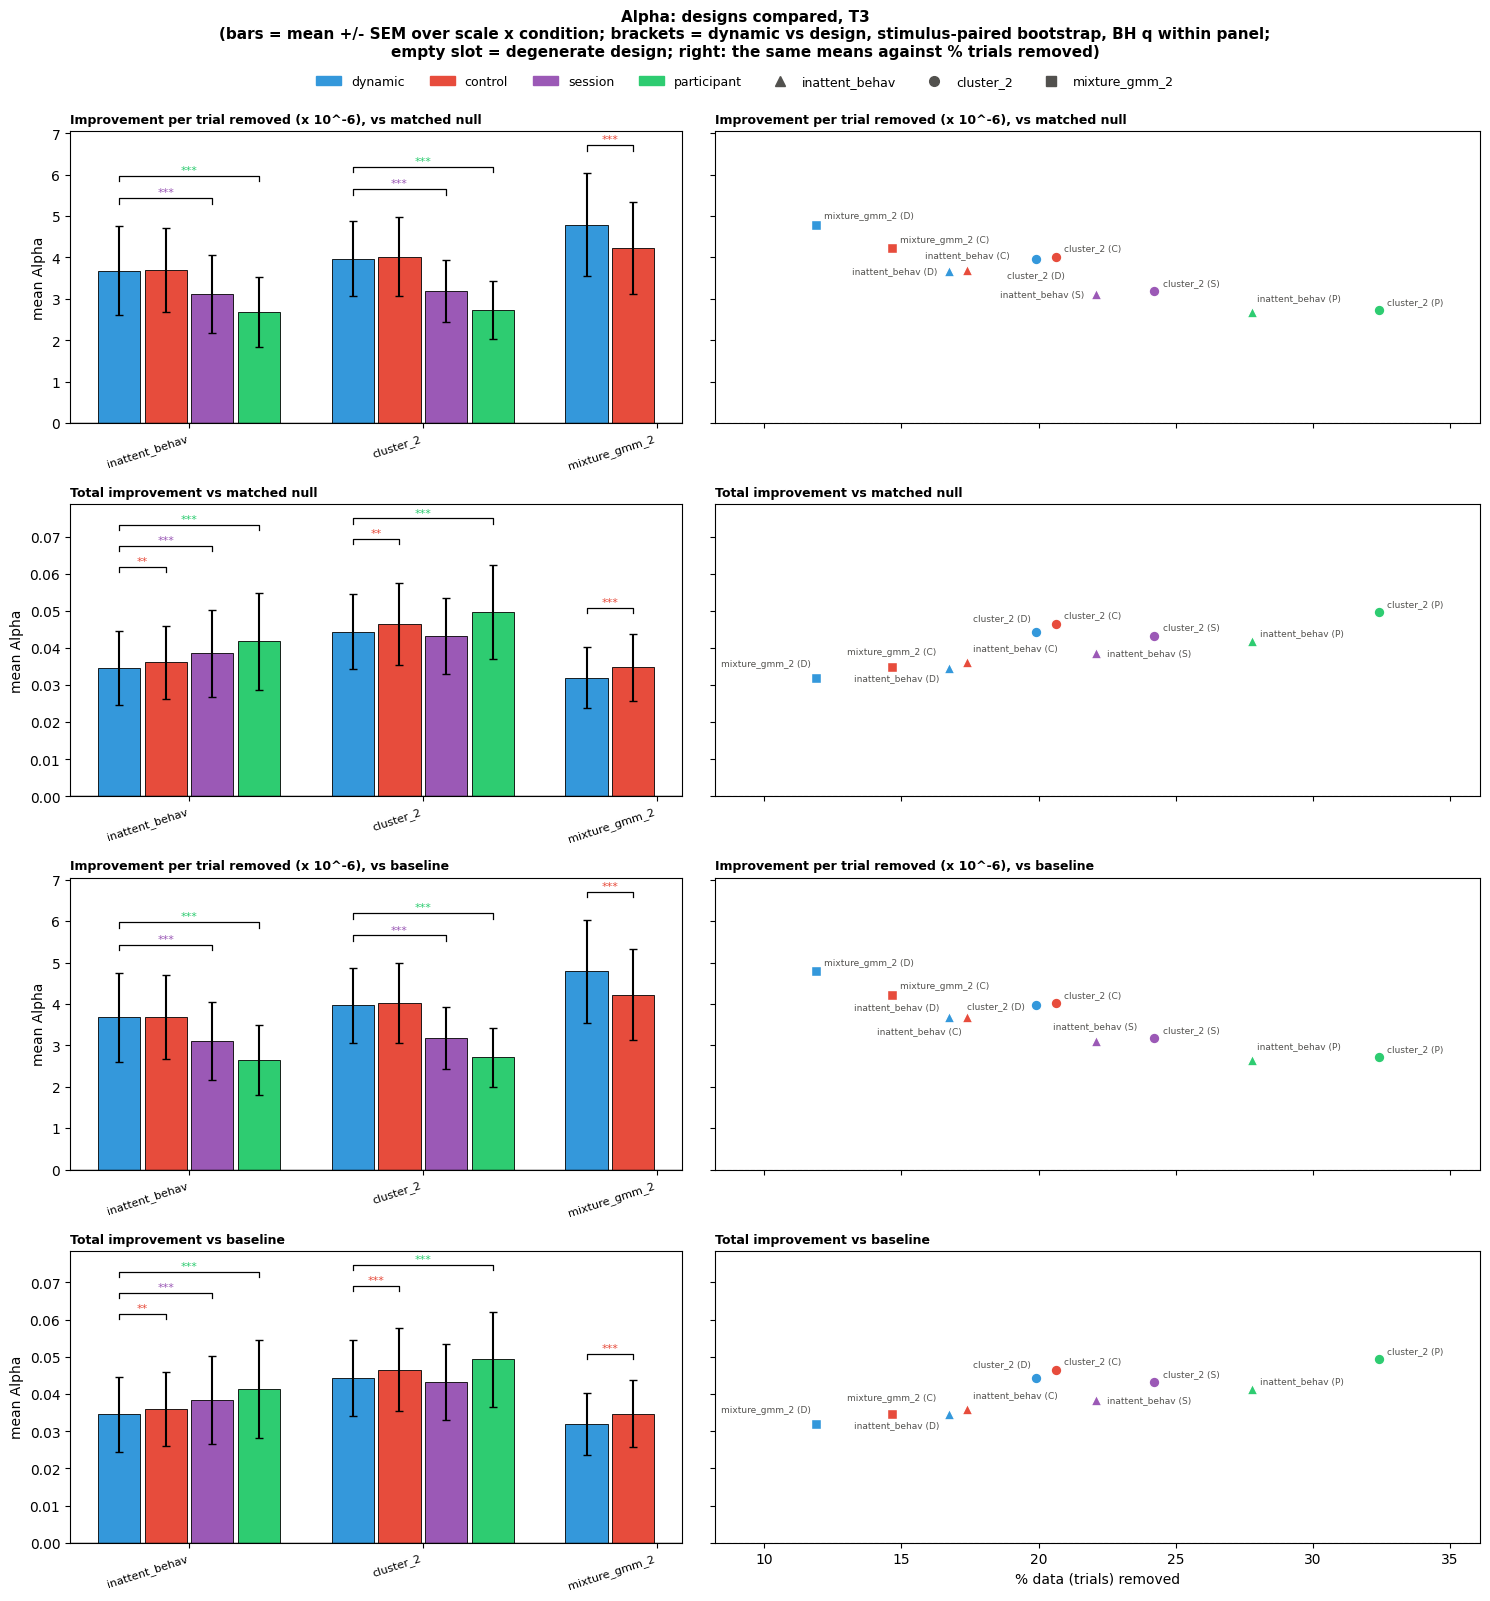


--- Alpha: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible     mean_a     mean_b        diff      ci_low     ci_high          p          q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True 3.6819e-06 3.6958e-06 -1.3924e-08 -1.2181e-07  9.1093e-08    0.80652    0.80652      
Excess per trial        T3 inattent_behav     dynamic vs session      True 3.6819e-06 3.1108e-06  5.7116e-07  4.3367e-07  7.0655e-07 0.00019998 0.00027997   ***
Excess per trial        T3 inattent_behav dynamic vs participant      True 3.6819e-06 2.6771e-06  1.0048e-06  8.4233e-07  1.1596e-06 0.00019998 0.00027997   ***
Excess per trial        T3      cluster_2     dynamic vs control      True 3.9669e-06 4.0154e-06 -4.8542e-08 -1.5197e-07  5.2578e-08    0.35396    0.41296      
Excess per trial        T3      cluster_2     dynamic vs session      True 3.9669e-06  3.182e-06  7.8494e-07  6.6097e-07  9.0749e-07 0.00019998 0.

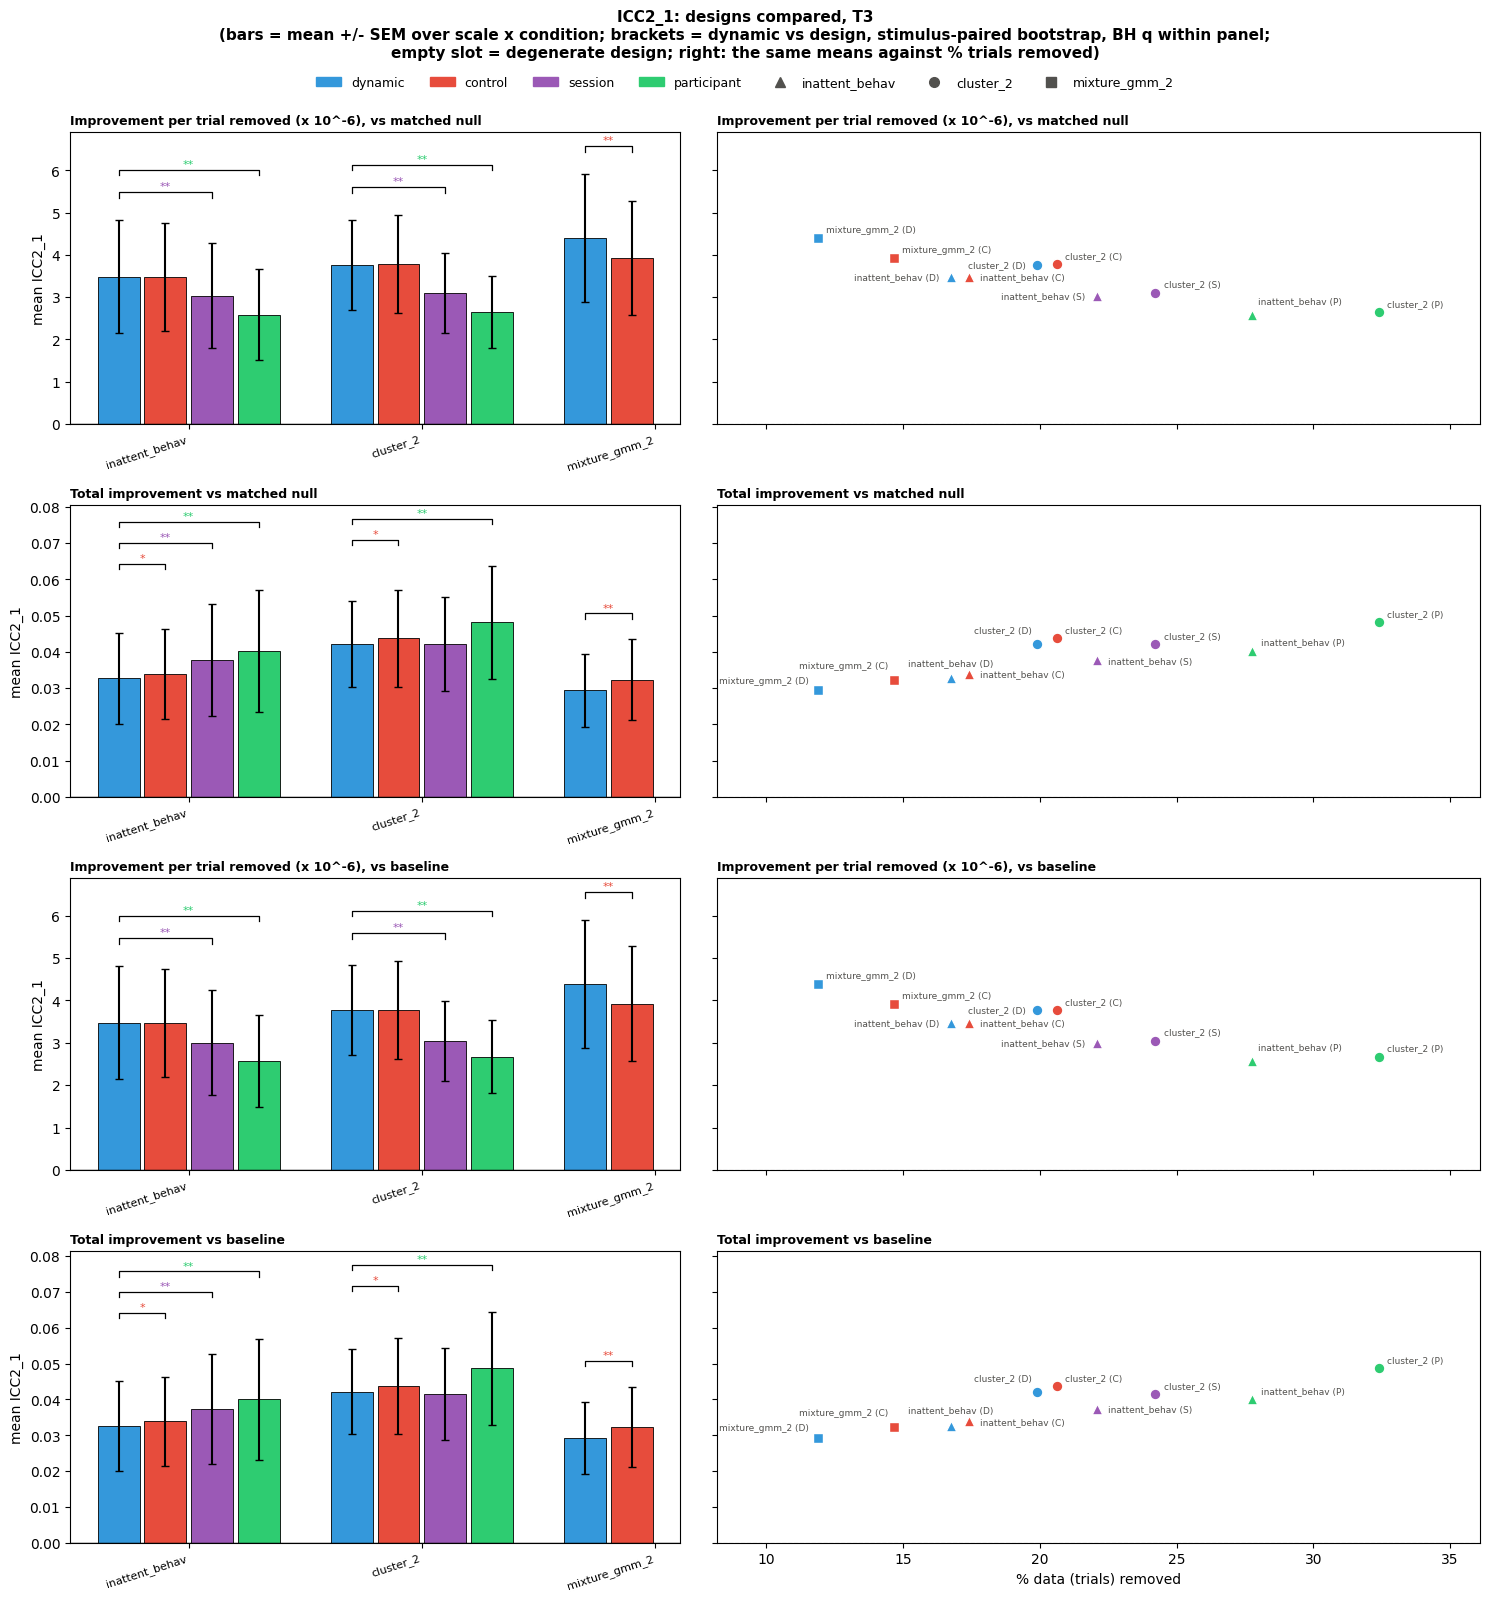


--- ICC2_1: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible     mean_a     mean_b        diff      ci_low     ci_high        p         q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True 3.4813e-06 3.4735e-06  7.7882e-09 -1.1872e-07    1.18e-07  0.97502   0.97502      
Excess per trial        T3 inattent_behav     dynamic vs session      True 3.4813e-06 3.0358e-06  4.4549e-07  2.7185e-07  5.7079e-07 0.001998 0.0027972    **
Excess per trial        T3 inattent_behav dynamic vs participant      True 3.4813e-06 2.5831e-06  8.9817e-07  7.1402e-07  1.0517e-06 0.001998 0.0027972    **
Excess per trial        T3      cluster_2     dynamic vs control      True 3.7714e-06 3.7762e-06 -4.8365e-09 -1.1808e-07  1.0486e-07  0.85714   0.97502      
Excess per trial        T3      cluster_2     dynamic vs session      True 3.7714e-06 3.0982e-06  6.7316e-07  5.2561e-07  7.9347e-07 0.001998 0.0027972    **
Ex

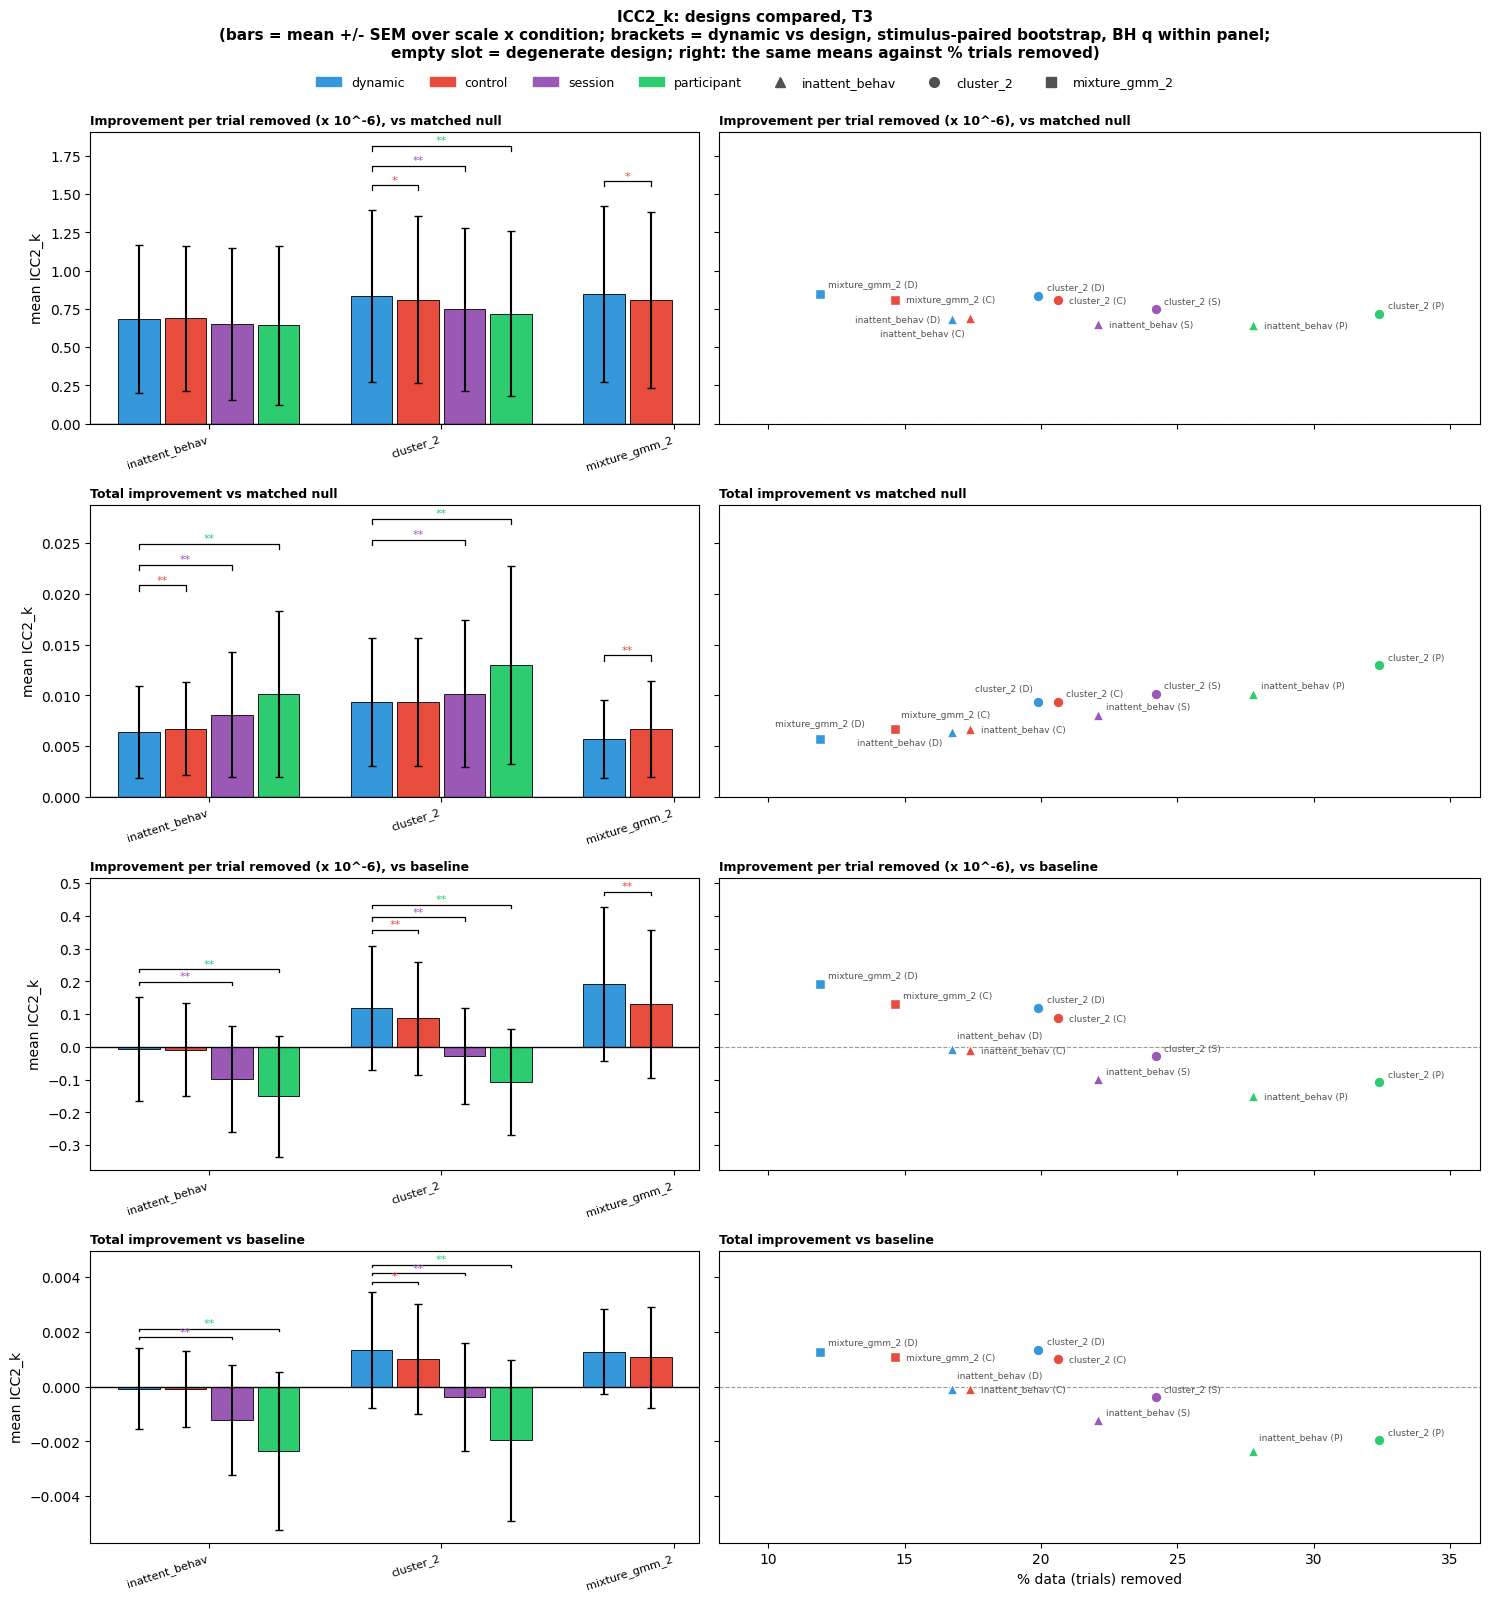


--- ICC2_k: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible      mean_a      mean_b        diff      ci_low     ci_high        p         q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True  6.8373e-07  6.8801e-07 -4.2848e-09 -3.1388e-08  1.9851e-08  0.67732   0.67732      
Excess per trial        T3 inattent_behav     dynamic vs session      True  6.8373e-07  6.5325e-07   3.048e-08  -1.043e-08  6.6805e-08  0.13586   0.15851      
Excess per trial        T3 inattent_behav dynamic vs participant      True  6.8373e-07   6.442e-07  3.9526e-08 -6.8368e-09  8.3249e-08 0.091908   0.12867      
Excess per trial        T3      cluster_2     dynamic vs control      True  8.3394e-07  8.0898e-07  2.4959e-08  2.9347e-09  4.9684e-08  0.01998  0.034965     *
Excess per trial        T3      cluster_2     dynamic vs session      True  8.3394e-07  7.4741e-07  8.6528e-08  5.4055e-08  1.2371e-07 0.001998  0.006

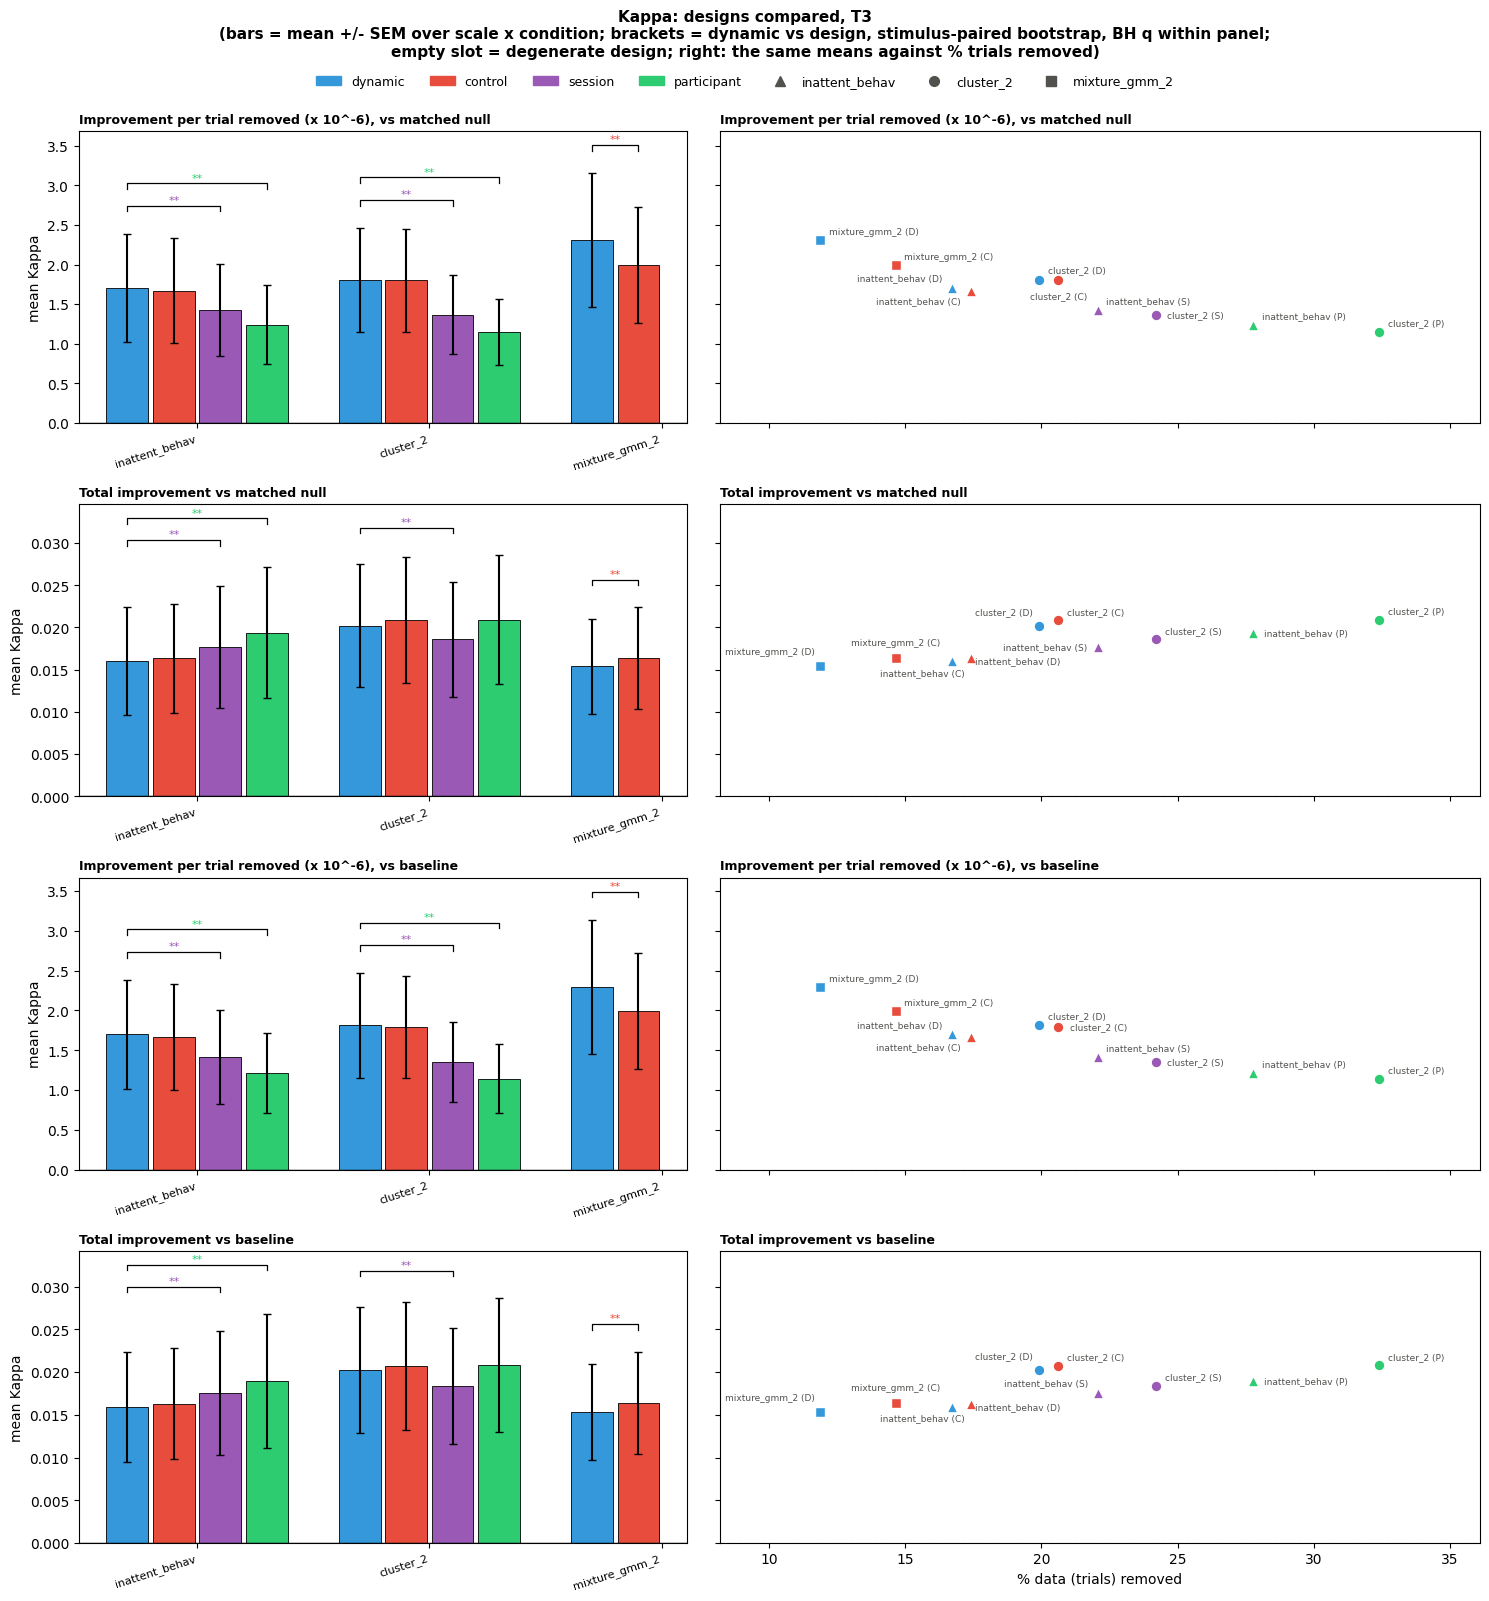


--- Kappa: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible     mean_a     mean_b        diff      ci_low     ci_high        p         q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True 1.7026e-06 1.6723e-06  3.0261e-08 -2.6516e-08  8.9998e-08  0.27373   0.31935      
Excess per trial        T3 inattent_behav     dynamic vs session      True 1.7026e-06  1.427e-06  2.7557e-07  1.9787e-07  3.5166e-07 0.001998 0.0027972    **
Excess per trial        T3 inattent_behav dynamic vs participant      True 1.7026e-06 1.2415e-06  4.6109e-07  3.7298e-07  5.5035e-07 0.001998 0.0027972    **
Excess per trial        T3      cluster_2     dynamic vs control      True 1.8082e-06 1.7994e-06  8.7996e-09 -4.7154e-08  5.8916e-08  0.74925   0.74925      
Excess per trial        T3      cluster_2     dynamic vs session      True 1.8082e-06 1.3671e-06  4.4115e-07  3.6962e-07   5.146e-07 0.001998 0.0027972    **
Exc

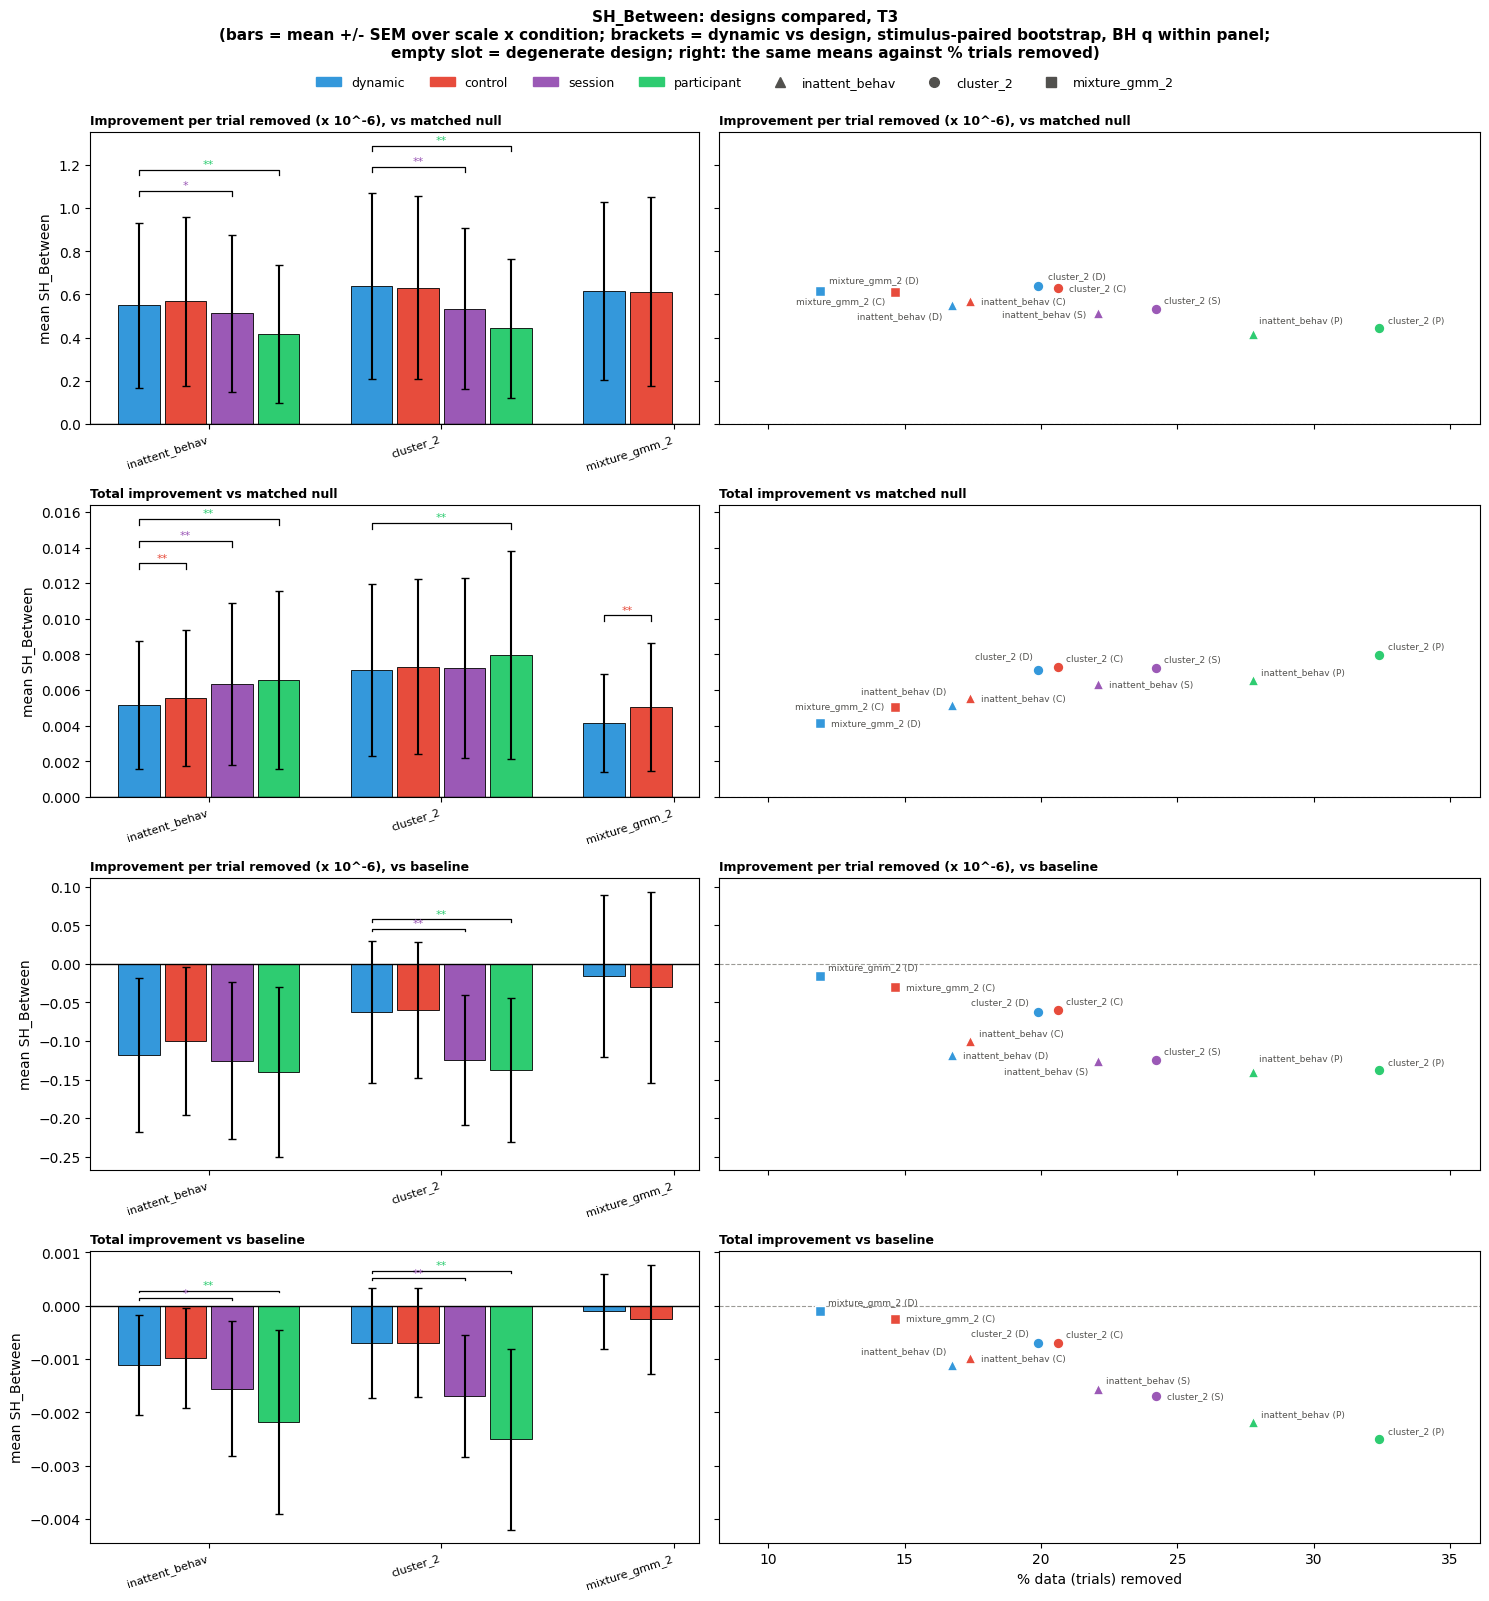


--- SH_Between: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible      mean_a      mean_b        diff      ci_low     ci_high        p         q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True  5.4939e-07  5.6849e-07 -1.9099e-08 -3.9401e-08  6.4159e-10 0.067932  0.095105      
Excess per trial        T3 inattent_behav     dynamic vs session      True  5.4939e-07  5.1159e-07  3.7802e-08  6.9176e-09  6.4742e-08 0.025974  0.045455     *
Excess per trial        T3 inattent_behav dynamic vs participant      True  5.4939e-07  4.1584e-07  1.3354e-07  9.7385e-08  1.6773e-07 0.001998  0.004662    **
Excess per trial        T3      cluster_2     dynamic vs control      True   6.387e-07  6.3108e-07  7.6202e-09 -1.1681e-08  2.6751e-08  0.44955   0.52448      
Excess per trial        T3      cluster_2     dynamic vs session      True   6.387e-07  5.3436e-07  1.0434e-07  8.2018e-08  1.3212e-07 0.001998  0

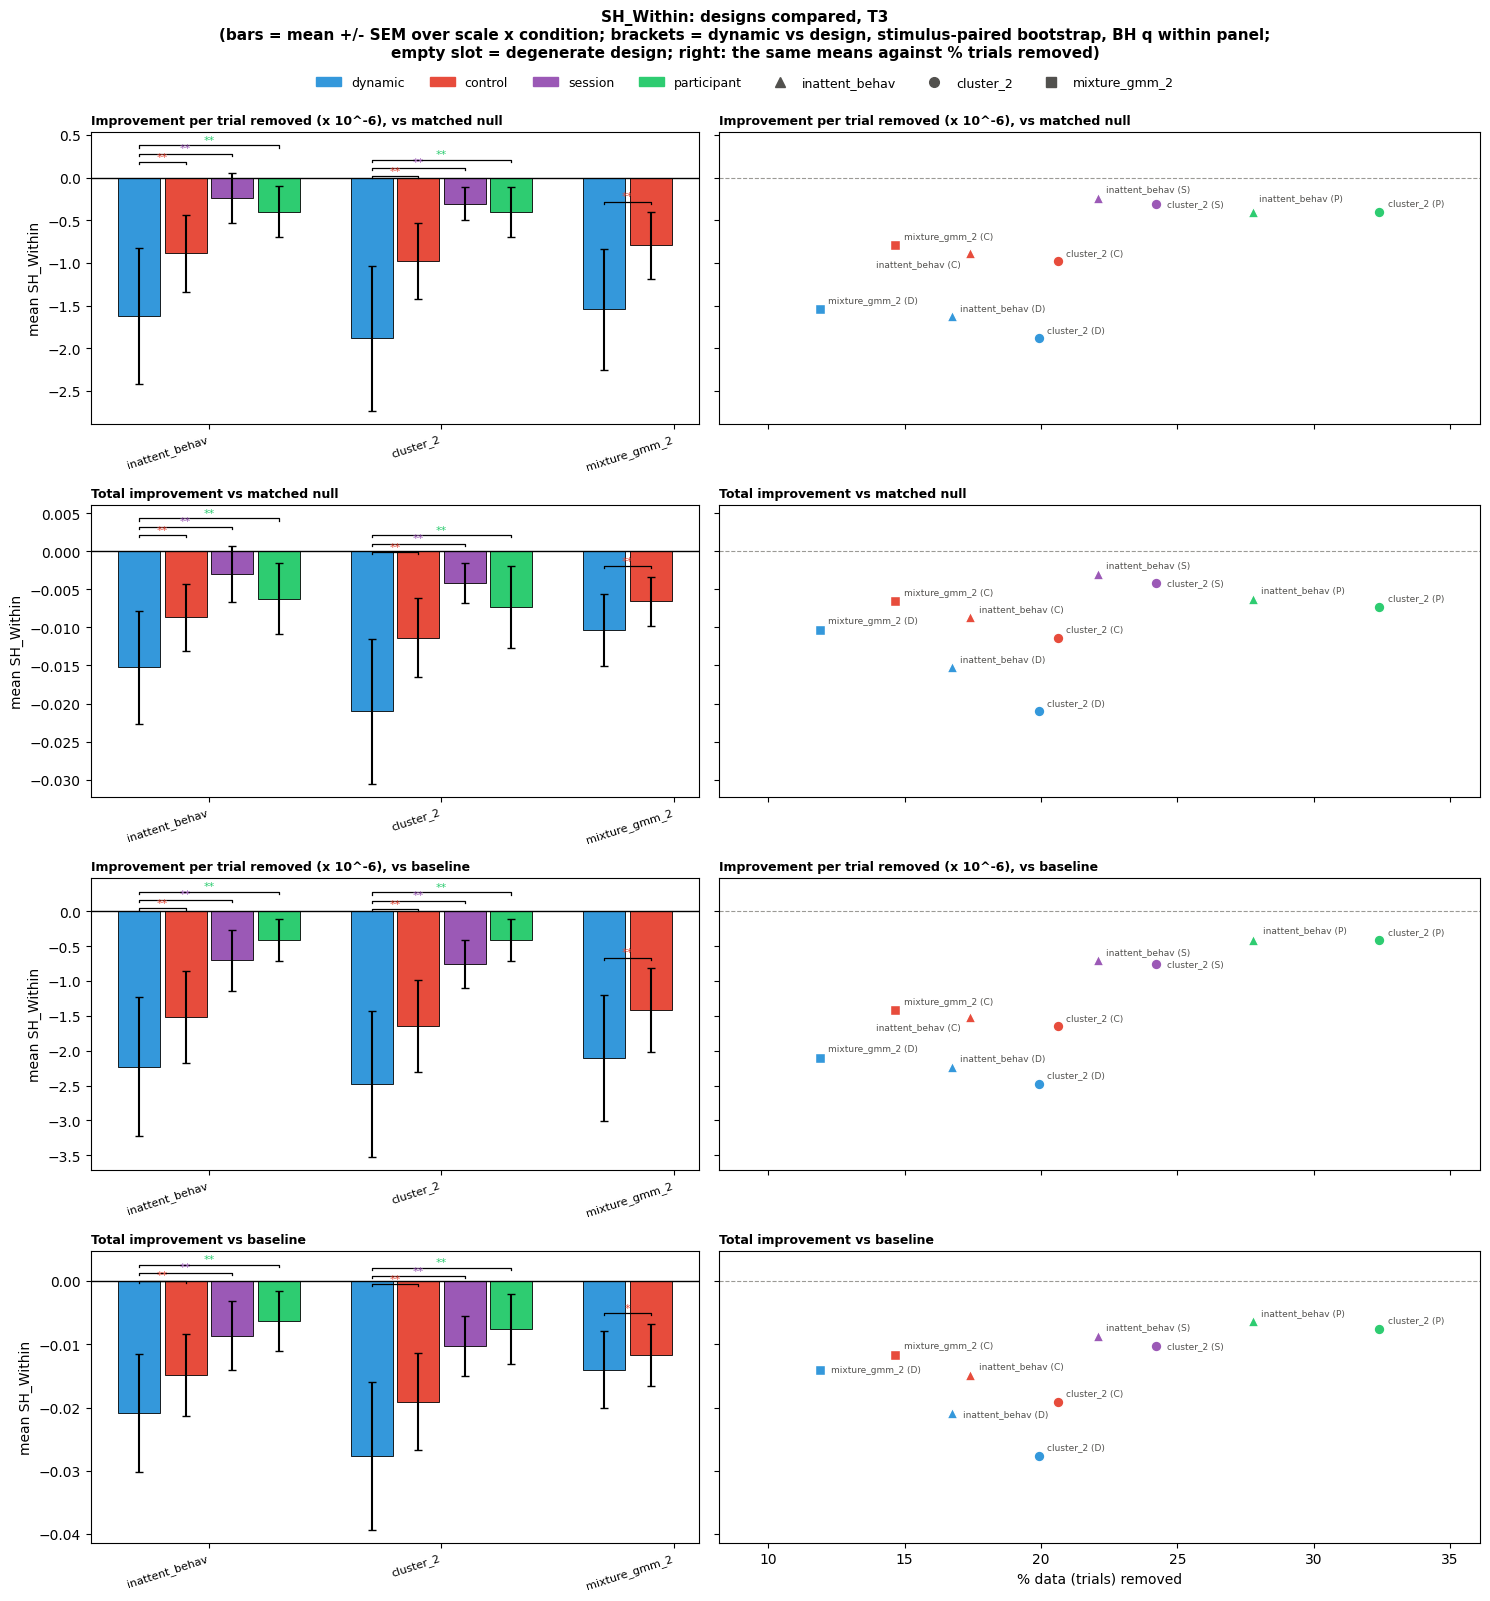


--- SH_Within: figure tests (dynamic vs design) ---
        Quantity Condition Removal_Method             Comparison  Eligible      mean_a      mean_b        diff      ci_low     ci_high        p        q stars
Excess per trial        T3 inattent_behav     dynamic vs control      True -1.6228e-06 -8.8778e-07 -7.3497e-07 -1.0217e-06 -4.0865e-07 0.001998 0.001998    **
Excess per trial        T3 inattent_behav     dynamic vs session      True -1.6228e-06 -2.3719e-07 -1.3856e-06 -1.6445e-06 -9.5239e-07 0.001998 0.001998    **
Excess per trial        T3 inattent_behav dynamic vs participant      True -1.6228e-06 -3.9836e-07 -1.2244e-06 -1.4763e-06 -7.7973e-07 0.001998 0.001998    **
Excess per trial        T3      cluster_2     dynamic vs control      True -1.8804e-06  -9.788e-07 -9.0156e-07 -1.2202e-06 -5.1031e-07 0.001998 0.001998    **
Excess per trial        T3      cluster_2     dynamic vs session      True -1.8804e-06 -3.0444e-07 -1.5759e-06 -1.8367e-06 -1.1201e-06 0.001998 0.001998

,Metric,Quantity,Condition,Removal_Method,Design,Eligible,n_cells,mean,sd,sem
0,Alpha,Excess per trial,T3,inattent_behav,dynamic,True,5,0.000004,0.000002,1.072762e-06
1,Alpha,Excess per trial,T3,inattent_behav,control,True,5,0.000004,0.000002,1.014473e-06
2,Alpha,Excess per trial,T3,inattent_behav,session,True,5,0.000003,0.000002,9.465198e-07
3,Alpha,Excess per trial,T3,inattent_behav,participant,True,5,0.000003,0.000002,8.429194e-07
4,Alpha,Excess per trial,T3,cluster_2,dynamic,True,5,0.000004,0.000002,9.063496e-07
...,...,...,...,...,...,...,...,...,...,...
283,SH_Within,Improvement,T3,cluster_2,participant,True,4,-0.007569,0.010969,5.484326e-03
284,SH_Within,Improvement,T3,mixture_gmm_2,dynamic,True,4,-0.014006,0.012081,6.040470e-03
285,SH_Within,Improvement,T3,mixture_gmm_2,control,True,4,-0.011663,0.009902,4.951236e-03
286,SH_Within,Improvement,T3,mixture_gmm_2,session,False,0,NaN,NaN,NaN


,Metric,Quantity,Condition,Removal_Method,Comparison,Test,Eligible,Minority_Units_a,Minority_Units_b,n_cells,mean_a,mean_b,diff,ci_low,ci_high,p,excludes_0,n_boot,q,stars
0,Alpha,Excess per trial,T3,inattent_behav,dynamic vs control,stimulus-paired bootstrap,True,184.0,193.0,5,0.000004,0.000004,-1.392431e-08,-1.218108e-07,9.109303e-08,0.806519,False,10000,0.806519,
1,Alpha,Excess per trial,T3,inattent_behav,dynamic vs session,stimulus-paired bootstrap,True,184.0,62.0,5,0.000004,0.000003,5.711599e-07,4.336693e-07,7.065470e-07,0.000200,True,10000,0.000280,***
2,Alpha,Excess per trial,T3,inattent_behav,dynamic vs participant,stimulus-paired bootstrap,True,184.0,40.0,5,0.000004,0.000003,1.004780e-06,8.423305e-07,1.159637e-06,0.000200,True,10000,0.000280,***
3,Alpha,Excess per trial,T3,cluster_2,dynamic vs control,stimulus-paired bootstrap,True,239.0,238.0,5,0.000004,0.000004,-4.854245e-08,-1.519683e-07,5.257850e-08,0.353965,False,10000,0.412959,
4,Alpha,Excess per trial,T3,cluster_2,dynamic vs session,stimulus-paired bootstrap,True,239.0,68.0,5,0.000004,0.000003,7.849403e-07,6.609653e-07,9.074854e-07,0.000200,True,10000,0.000280,***
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,SH_Within,Improvement,T3,cluster_2,dynamic vs session,stimulus-paired bootstrap,True,239.0,68.0,4,-0.027633,-0.010235,-1.739760e-02,-2.038124e-02,-1.245529e-02,0.001998,True,1000,0.002331,**
212,SH_Within,Improvement,T3,cluster_2,dynamic vs participant,stimulus-paired bootstrap,True,239.0,46.0,4,-0.027633,-0.007569,-2.006434e-02,-2.327667e-02,-1.482848e-02,0.001998,True,1000,0.002331,**
213,SH_Within,Improvement,T3,mixture_gmm_2,dynamic vs control,stimulus-paired bootstrap,True,136.0,167.0,4,-0.014006,-0.011663,-2.343542e-03,-4.624866e-03,-2.675486e-04,0.019980,True,1000,0.019980,*
214,SH_Within,Improvement,T3,mixture_gmm_2,dynamic vs session,stimulus-paired bootstrap,False,136.0,1.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,


In [27]:
# [notebook only] STEP 9 FIGURES: DESIGNS COMPARED, AS BARS AND AGAINST THE SHARE OF TRIALS REMOVED
# =============================================================================
# One figure per IRR metric and scope (the run's condition; with several conditions, all of them first, then each one),
# then the metric's figure tests and null D-difference contrasts as tables. Rows: the four quantities of Step 9 (per
# trial and total, against the matched null, then against the baseline). Left: bars = mean ± SEM over the scope's
# (Scale, Condition) cells per removal method x design; brackets = dynamic vs each other design (the figure tests of
# [cell 53], BH q within panel); an empty slot = a degenerate design. Right: the same means against the % of trials
# the design removes in the scope's conditions (Step 8); colour = design, marker = removal method. Draws only.
import matplotlib.transforms as _mtr


def _mmp_panel(ax, metric, quantity, scope, sig=True):
    """Grouped bars (removal x design) over the cells of `scope` + brackets for dynamic vs each
    design (the scope's figure tests, BH q). A degenerate design's slot stays empty."""
    conds = _MMP_SCOPES[scope]
    x = np.arange(len(_MMP_RMS))
    w = 0.8 / len(_MMP_DESIGNS)
    tops = []
    for j, d in enumerate(_MMP_DESIGNS):
        means, sems = [], []
        for rm in _MMP_RMS:
            v = _mmp_values(metric, quantity, rm, d, conds) * _MMP_SHOW.get(quantity, 1.0)
            ok = _mmp_eligible(rm, d, conds)
            means.append(v.mean() if ok else np.nan); sems.append(v.sem() if ok else np.nan)
        pos = x - 0.4 + w * (j + 0.5)
        ax.bar(pos, means, w * 0.9, yerr=sems, capsize=3, label=d,
               color=_MMP_COLORS[d], edgecolor="black", linewidth=0.6)
        tops.append(np.array(means, float) + np.nan_to_num(np.array(sems, float)))
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels(_MMP_RMS, rotation=18, ha="right", fontsize=8)
    ax.set_title(QUANT_TITLES.get(quantity, quantity), fontweight="bold",
                 loc="left", fontsize=9)

    stack = np.vstack(tops)
    if sig and np.isfinite(stack).any():
        # Brackets: dynamic vs each other design, stacked above the tallest bar in the group.
        span = max(np.nanmax(stack) - min(0, np.nanmin(stack)), 1e-9)
        step = 0.09 * span
        dyn_pos = x - 0.4 + w * 0.5
        T = mm_design_tests
        for gi, rm in enumerate(_MMP_RMS):
            col = stack[:, gi]
            if not np.isfinite(col).any():
                continue
            base = np.nanmax(col)
            lvl = 0
            for j, d in enumerate(_MMP_DESIGNS):
                if d == "dynamic":
                    continue
                row = T[(T["Metric"] == metric) & (T["Quantity"] == quantity) & (T["Condition"] == scope) &
                        (T["Removal_Method"] == rm) & (T["Comparison"] == f"dynamic vs {d}")]
                st = row["stars"].iloc[0] if len(row) else ""
                if not st:
                    continue
                lvl += 1
                y = base + step * lvl
                x2 = x[gi] - 0.4 + w * (j + 0.5)
                ax.plot([dyn_pos[gi], dyn_pos[gi], x2, x2],
                        [y, y + step * 0.25, y + step * 0.25, y], lw=0.9, color="black")
                ax.text((dyn_pos[gi] + x2) / 2, y + step * 0.28, st, ha="center",
                        va="bottom", fontsize=8, color=_MMP_COLORS[d])
    ax.margins(y=0.22)


def _bbox_overlap(a, b):
    dx = min(a.x1, b.x1) - max(a.x0, b.x0)
    dy = min(a.y1, b.y1) - max(a.y0, b.y0)
    return dx * dy if dx > 0 and dy > 0 else 0.0


def place_labels(ax, xs, ys, labels, fontsize=6.5, color="#666666"):
    """Annotate without overlaps. Searches rings of candidate offsets outward from each
    point and keeps the first placement that collides with nothing already placed; when
    a label has to sit far from its marker a thin leader line is drawn so the pairing
    stays unambiguous. Falls back to the least-overlapping candidate if every ring is
    blocked."""
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    cands = [(0, 0, 6, 3, "left", "bottom")]
    for rad in (8, 16, 26, 38, 52, 68):
        for ang in range(0, 360, 30):
            a = np.deg2rad(ang)
            dx, dy = rad * np.cos(a), rad * np.sin(a)
            ha = "left" if dx > 2 else ("right" if dx < -2 else "center")
            va = "bottom" if dy > 2 else ("top" if dy < -2 else "center")
            cands.append((rad, ang, dx, dy, ha, va))
    taken = []
    for x, y in zip(xs, ys):                      # markers are obstacles too
        px, py = ax.transData.transform((x, y))
        taken.append(_mtr.Bbox.from_bounds(px - 5, py - 5, 10, 10))
    for i in np.argsort(ys)[::-1]:                # densest region first
        best = None
        for rad, ang, dx, dy, ha, va in cands:
            t = ax.annotate(labels[i], (xs[i], ys[i]), textcoords="offset points",
                            xytext=(dx, dy), fontsize=fontsize, color=color,
                            ha=ha, va=va, annotation_clip=False,
                            arrowprops=dict(arrowstyle="-", lw=0.4, color="#b6b5b0",
                                            shrinkA=0, shrinkB=2) if rad >= 26 else None)
            bb = t.get_window_extent(rend).expanded(1.04, 1.20)
            ov = sum(_bbox_overlap(bb, o) for o in taken)
            if best is None or ov < best[1]:
                if best is not None:
                    best[0].remove()
                best = (t, ov, bb)
            else:
                t.remove()
            if ov == 0:
                break
        taken.append(best[2])


_MMP_N = (multimetric_df.groupby(["Removal_Method", "Design", "Condition"])[["Trials_Removed", "Pct_Removed"]].first())


def _mmp_pct(rm, design, conds):
    """% of the trials of `conds` that the design removes (each condition's trials = removed / share removed)."""
    keys = [(rm, design, c) for c in conds if (rm, design, c) in _MMP_N.index]
    if not keys:
        return np.nan
    t = _MMP_N.loc[keys]
    n = (100 * t["Trials_Removed"] / t["Pct_Removed"]).sum()
    return float(100 * t["Trials_Removed"].sum() / n) if n > 0 else np.nan


_MMP_MARKERS = dict(zip(_MMP_RMS, ["^", "o", "s", "D", "v", "P", "X", "*"]))


def _mmp_scatter(ax, metric, quantity, scope):
    """The bar means of `scope` against the % of trials each design removes; one point per removal method x design."""
    conds = _MMP_SCOPES[scope]
    xs, ys, labs = [], [], []
    for rm in _MMP_RMS:
        for d in _MMP_DESIGNS:
            v = _mmp_values(metric, quantity, rm, d, conds) * _MMP_SHOW.get(quantity, 1.0)
            if not _mmp_eligible(rm, d, conds) or not v.notna().any():
                continue
            x, y = _mmp_pct(rm, d, conds), float(v.mean())
            ax.scatter(x, y, s=60, marker=_MMP_MARKERS[rm], color=_MMP_COLORS[d], edgecolor="white", linewidth=1.0,
                       zorder=3)
            xs.append(x); ys.append(y); labs.append(f"{rm} ({d[0].upper()})")
    ax.axhline(0, color="#9b9a95", lw=0.8, ls="--")
    ax.margins(x=0.18)
    if xs:
        place_labels(ax, np.asarray(xs), np.asarray(ys), labs, fontsize=6.5, color="#52514e")


_MMP_ORDER = [_MMP_MAIN] + [s_ for s_ in _MMP_SCOPES if s_ != _MMP_MAIN]
_MMP_SCOPE_LAB = {s_: ("all conditions (" + ", ".join(_MMP_SCOPES[s_]) + ")" if s_ == "all" else s_) for s_ in _MMP_ORDER}
for _metric in _MMP_METRICS:
    for _scope in _MMP_ORDER:
        fig, axes = plt.subplots(len(QUANTITIES), 2, figsize=(15, 4.0 * len(QUANTITIES)), sharey="row",
                                 gridspec_kw={"width_ratios": [1, 1.25]})
        for row_i, q in enumerate(QUANTITIES):
            _mmp_panel(axes[row_i, 0], _metric, q, _scope)
            axes[row_i, 0].set_ylabel(f"mean {_metric}")
            if row_i:
                axes[row_i, 1].sharex(axes[0, 1])
            _mmp_scatter(axes[row_i, 1], _metric, q, _scope)
            axes[row_i, 1].set_title(QUANT_TITLES.get(q, q), fontweight="bold", loc="left", fontsize=9)
            if row_i < len(QUANTITIES) - 1:
                axes[row_i, 1].tick_params(labelbottom=False)
        axes[-1, 1].set_xlabel("% data (trials) removed")
        _st = fig.suptitle(f"{_metric}: designs compared, {_MMP_SCOPE_LAB[_scope]}\n(bars = mean +/- SEM over scale x "
                           f"condition; brackets = dynamic vs design, stimulus-paired bootstrap, BH q within panel;\nempty "
                           f"slot = degenerate design; right: the same means against % trials removed)", fontsize=11,
                           fontweight="bold", y=0.998)
        fig.canvas.draw()
        _inv = fig.transFigure.inverted()
        _leg = fig.legend([plt.Rectangle((0, 0), 1, 1, color=_MMP_COLORS[d]) for d in _MMP_DESIGNS]
                          + [plt.Line2D([], [], ls="", marker=_MMP_MARKERS[rm], color="#52514e", ms=7) for rm in _MMP_RMS],
                          _MMP_DESIGNS + list(_MMP_RMS), loc="upper center", ncol=len(_MMP_DESIGNS) + len(_MMP_RMS),
                          fontsize=9, frameon=False,
                          bbox_to_anchor=(0.5, _inv.transform(_st.get_window_extent())[0, 1] - 0.003))
        fig.canvas.draw()
        _st.set_in_layout(False)                      # the rect below already leaves the title's room
        fig.tight_layout(rect=(0, 0, 1, _inv.transform(_leg.get_window_extent())[0, 1] - 0.003))
        _st.set_in_layout(True)
        plt.show()

    _t = mm_design_tests[mm_design_tests["Metric"] == _metric]
    print(f"\n--- {_metric}: figure tests (dynamic vs design) ---")
    print(_t[["Quantity", "Condition", "Removal_Method", "Comparison", "Eligible", "mean_a", "mean_b", "diff",
              "ci_low", "ci_high", "p", "q", "stars"]]
          .to_string(index=False, float_format=lambda v: f"{v:,.5g}"))
    _n = mm_null_contrasts[(mm_null_contrasts["Metric"] == _metric) & (mm_null_contrasts["Outcome"] == "overall")] \
        if len(mm_null_contrasts) else mm_null_contrasts
    print(f"\n--- {_metric}: null D-difference contrasts (overall outcomes; per-scale rows in the CSV) ---")
    if len(_n):
        print(_n[["Quantity", "Removal_Method", "Condition", "Comparison", "mean_a", "mean_b", "diff", "ci_low",
                  "ci_high", "p", "q", "stars"]]
              .to_string(index=False, float_format=lambda v: f"{v:,.5g}"))

display(mm_design_summary)
display(mm_design_tests)


In [28]:
# [cell 54]
# =============================================================================
# STEP 10: POST HOC ANALYSES -- GMM POSTERIOR THRESHOLDS, REPEAT EXPOSURES
# =============================================================================
# The alpha removal comparisons of Step 8 (same estimator, units, matched-null draws, seeds and stimulus resamples)
# recomputed with other flags or data:
#   GMM thresholds   a unit is flagged when the GMM's P(inattentive) > t (gmm_posterior_thresholds; .5 = the primary
#                    flags): the posterior distribution, the H2 tests of Step 5e, the H3 comparisons, eligibility and
#                    the DSC with the behavioural heuristic; at t = .5 the comparisons reproduce Step 8 (checked)
#   repeat exposures the session-2 data of the participants shown repeated stimuli dropped: the H2 IRR contrast and
#                    the H3 comparisons (runs with T2 data)
# Per trial = the change divided by the trials removed (vs the null, each removal by its own count); per-trial
# estimates and intervals are x 10^-6 (keys imp_t, exc_t). Eligibility: a design needs >= irr_min_units units in its
# minority profile and >= h2_min_coverage of the stimuli rated at least twice in every post-removal cell.
H3_ARMS = {sol: arm for sol, (_, arm) in PICKS.items()}


def h3_cond_data(cd, cond, *, fdf=None):
    """One condition: the trials (missing responses included), per design the unit of every trial (units in order of
    first appearance, as Step 8's nulls draw them), the session / participant codes the matched nulls sample from,
    and per scale the responses with the trial of every response. fdf: the frames (default FDF)."""
    f = (FDF if fdf is None else fdf)[cd]; f = f[f.condition == cond]
    assert f[BLOCK_COL].notna().all() and f[CONTROL_COL].notna().all()
    keys = {"dynamic": [key3(i, s, b) for i, s, b in f[["id", "session", BLOCK_COL]].values],
            "control": [key3(i, s, b) for i, s, b in f[["id", "session", CONTROL_COL]].values],
            "session": [f"{int(i)}_{int(s)}" for i, s in f[["id", "session"]].values],
            "participant": [int(i) for i in f.id.values]}
    out = {"n": len(f), "units": {}, "scales": {}}
    for des, k in keys.items():
        codes, uniq = pd.factorize(pd.Series(k))
        out["units"][des] = dict(code=codes, uniq=list(uniq))
    out["session"], out["participant"] = out["units"]["session"]["code"], out["units"]["participant"]["code"]
    for s in SCALES:
        resp = f[f"{s}_response"].notna().to_numpy()
        sc = {"item": pd.Index(UNIVERSE[cond]).get_indexer(f.stim_label[resp]),
              "cat": (f[f"{s}_response"][resp].to_numpy(float) - CATS[s][0]).astype(int),
              "rater": f.id[resp].to_numpy(), "val": f[f"{s}_response"][resp].to_numpy(float),
              "irr": ~f["_repeat"][resp].to_numpy(bool), "trial": np.flatnonzero(resp)}
        out["scales"][s] = sc
    return out


def flagged_mask(uniq, des, cd, arm, flags=None):
    fl = (FLAGS if flags is None else flags)[cd][arm][des]
    return np.array([u in fl for u in uniq])


def alpha_job(scs, n_trials, code, fmask, session, participant, des, W, R, seed0):
    """One condition x solution x design, every scale: the reference and post-removal alpha, coverage, the % of
    responses removed and the stimulus-resample replicates; then the alpha of every scale after each of R matched
    random removals (NaN = invalid replicate) and the trials each removed."""
    drop = fmask[code]
    out = dict(units_flagged=int(fmask.sum()), units=len(fmask), trials_removed=int(drop.sum()), n_trials=n_trials,
               pct_t=100 * drop.sum() / n_trials, scales=[])
    for item, cat, irr, trial, I, C, level, cats in scs:
        keep = ~drop[trial]
        N0, N1 = counts_table(item, cat, I, C, irr), counts_table(item, cat, I, C, keep & irr)
        sc = dict(base=alpha_counts(N0, level, cats), post=alpha_counts(N1, level, cats), removed=int((~keep).sum()),
                  pct=100 * (~keep).sum() / len(keep), cov_post=coverage(N1), cov_base=coverage(N0))
        if drop.any() and not drop.all():
            sc["base_b"], sc["post_b"] = alpha_counts(N0, level, cats, W=W), alpha_counts(N1, level, cats, W=W)
        out["scales"].append(sc)
    if not drop.any() or drop.all():
        return out
    draw, n_draw, n_null = matched_null_draw(des, drop, session, participant)
    null, n_rem = np.full((R, len(scs)), np.nan), np.full(R, np.nan)
    for r, d in null_removal_masks(draw, n_draw, n_null, R, seed0):
        if d is None:
            continue
        n_rem[r] = d.sum()
        for j, (item, cat, irr, trial, I, C, level, cats) in enumerate(scs):
            null[r, j] = alpha_counts(counts_table(item, cat, I, C, ~d[trial] & irr), level, cats)
    out.update(n_draw=n_draw, n_trials_null=n_null, null=null, n_null_removed=n_rem)
    return out


def run_h3(*, tag="full", fdf=None, flags=None, arms=None):
    """Every condition x solution x design of this run, one record per scale cell with the cell's D replicates
    (D = flagged - random, and D per trial removed, each removal by its own trial count). fdf: the frames (default
    FDF); flags: FLAGS layout; arms: {label: arm}."""
    tasks, meta = [], []
    for cond in conditions:
        for mlab, arm in (H3_ARMS if arms is None else arms).items():
            dat = h3_cond_data(RUN_KEY, cond, fdf=fdf)
            scs = [(sc["item"], sc["cat"], sc["irr"], sc["trial"], len(UNIVERSE[cond]), len(CATS[s]), LEVEL[s], CATS[s])
                   for s, sc in dat["scales"].items()]
            for des in DESIGNS:
                u = dat["units"][des]; fm = flagged_mask(u["uniq"], des, RUN_KEY, arm, flags)
                tasks.append(delayed(alpha_job)(scs, dat["n"], u["code"], fm, dat["session"], dat["participant"], des,
                                                W_COND[cond], NULL_REPS["alpha"], SEED))
                meta.append(dict(run=RUN_KEY, cond=cond, method=mlab, design=des,
                                 units_minority=min(int(fm.sum()), int((~fm).sum()))))
    t0 = datetime.now()
    res = Parallel(n_jobs=N_JOBS, max_nbytes="1M")(tasks)
    print(f"H3 {tag}: {len(tasks)} condition x solution x design jobs in {(datetime.now() - t0).total_seconds():.0f} s")
    cells = []
    for m, r in zip(meta, res):
        for j, s in enumerate(SCALES):
            c = {**m, "scale": s, **r["scales"][j],
                 **{k: r[k] for k in ("units_flagged", "units", "trials_removed", "n_trials", "pct_t")}}
            if "null" in r:
                c.update(null=r["null"][:, j], n_null_removed=r["n_null_removed"], n_draw=r["n_draw"],
                         n_trials_null=r["n_trials_null"])
                c["d"] = null_d(c["base"], c["post"], c["null"])
                c["dp"] = null_d(c["base"], c["post"], c["null"], c["trials_removed"], c["n_null_removed"])
            cells.append(c)
    return cells


OUTCOMES = SCALES + ["overall"]
H3_LAB = {"imp": "Overall vs baseline", "imp_t": "Per-trial vs baseline (× 10⁻⁶)", "exc": "Overall vs null (D)",
          "exc_t": "Per-trial vs null (D per trial, × 10⁻⁶)"}


def h3_rows(cells_list, tag):
    """Dataset x solution x design x outcome rows (each scale over the row's conditions; overall = every cell of the
    row). Vs null: the cells' D averaged within each replicate, its mean, empirical 95% interval and two-sided Monte
    Carlo p; D per trial the same. Vs baseline (overall rows): the stimulus-paired bootstrap. q = BH within dataset x
    solution x outcome across the eligible designs. Returns the rows and the exclusions."""
    C_ = {(c["run"], c["cond"], c["method"], c["scale"], c["design"]): c for c in cells_list}
    rows, excl = [], []
    for ds, (cd, conds, kind) in DATASETS.items():
        for mlab in sorted({c["method"] for c in cells_list}, key=list(PICKS).index):
            for des in DESIGNS:
                if any((cd, cond, mlab, s, des) not in C_ for cond in conds for s in SCALES):
                    continue
                cs = [C_[(cd, cond, mlab, s, des)] for cond in conds for s in SCALES]
                units = {cond: C_[(cd, cond, mlab, SCALES[0], des)] for cond in conds}
                nflag = sum(u["units_flagged"] for u in units.values()); ntot = sum(u["units"] for u in units.values())
                minority = min(nflag, ntot - nflag)
                reason = []
                if minority < MIN_REMOVAL_UNITS:
                    reason.append(f"minority profile {minority} < {MIN_REMOVAL_UNITS} units ({nflag} of {ntot} flagged)")
                if any("null" not in c for c in cs):
                    reason.append("no responses removed, or all removed")
                elif min(c["cov_post"] for c in cs) < MIN_COVERAGE:
                    reason.append(f"post-removal coverage {min(c['cov_post'] for c in cs):.2f} < {MIN_COVERAGE:.2f}")
                base = dict(Dataset=ds, Solution=mlab, Design=des, **{"Units flagged / total": f"{nflag} / {ntot}"},
                            **{"% responses removed": np.mean([c["pct"] for c in cs])})
                if reason:
                    excl.append({**base, "Analysis": tag, "Reason": "; ".join(reason)})
                    continue
                u0 = list(units.values())
                vol = {"Units sampled per random removal": sum(u["n_draw"] for u in u0),
                       "Trials removed (flagged)": sum(u["trials_removed"] for u in u0),
                       "Trials removed (random, mean)": float(sum(np.nanmean(u["n_null_removed"]) for u in u0))}
                tr = np.array([c["trials_removed"] for c in cs], float)
                b0 = np.array([c["base"] for c in cs]); p1 = np.array([c["post"] for c in cs])
                imp = p1 - b0
                st = {"imp": np.mean([c["post_b"] - c["base_b"] for c in cs], 0),
                      "imp_t": 1e6 * np.mean([(c["post_b"] - c["base_b"]) / c["trials_removed"] for c in cs], 0)}
                vsb = {"imp est": imp.mean(), "imp_t est": 1e6 * (imp / tr).mean(),
                       "imp CI": ci_str(*ci(st["imp"]), 4), "imp_t CI": ci_str(*ci(st["imp_t"]), 2),
                       **{f"{k} p": p_two(st[k]) for k in st}}
                for out_ in OUTCOMES:
                    sel = cs if out_ == "overall" else [c for c in cs if c["scale"] == out_]
                    d, dp = np.mean([c["d"] for c in sel], 0), np.mean([c["dp"] for c in sel], 0)
                    s, sp = null_d_summary(d), null_d_summary(dp)
                    b, p = float(np.mean([c["base"] for c in sel])), float(np.mean([c["post"] for c in sel]))
                    nl = np.mean([c["null"] for c in sel], 0); nl = nl[np.isfinite(nl)]
                    rows.append({**base, "Outcome": out_, "Cells": len(sel), "Reference α": b, "Post α": p,
                                 "Δα flagged (ref − post)": b - p, "Random α (mean)": nl.mean() if len(nl) else np.nan,
                                 "Δα random (ref − random, mean)": b - nl.mean() if len(nl) else np.nan,
                                 "exc est": s["mean"], "exc CI": ci_str(s["lo"], s["hi"], 4), "exc p": s["p"],
                                 "exc excludes 0": s["excludes_0"], "exc_t est": 1e6 * sp["mean"],
                                 "exc_t CI": ci_str(1e6 * sp["lo"], 1e6 * sp["hi"], 2), "exc_t p": sp["p"],
                                 "Valid iterations": s["n_valid"], "Invalid iterations": s["n_invalid"], **vol,
                                 "Min coverage (post)": min(c["cov_post"] for c in sel),
                                 "Responses removed": int(sum(c["removed"] for c in sel)),
                                 **(vsb if out_ == "overall" else {"imp est": np.nan, "imp_t est": np.nan, "imp CI": "—",
                                                                   "imp_t CI": "—", "imp p": np.nan, "imp_t p": np.nan})})
    T = pd.DataFrame(rows)
    for _, g in T.groupby(["Dataset", "Solution", "Outcome"]):
        for k in ("imp", "imp_t", "exc", "exc_t"):
            T.loc[g.index, f"{k} q"] = bh(g[f"{k} p"].to_numpy())
    return T, pd.DataFrame(excl)


# ---- the primary removal comparisons (every participant), in the layout of the variants below -------------------------
_T, _X = h3_rows(run_h3(tag="primary"), "primary")
POST_HOC.update(h3_primary=_T, h3_primary_excluded=_X)

# ---- GMM posterior thresholds --------------------------------------------------------------------------------------
GMM_LAB = next(sol for sol, (_, a) in PICKS.items() if a.startswith("mixture_gmm"))
GMM_ARM = PICKS[GMM_LAB][1]
UNIT_LAB = {"dynamic": "dynamic blocks", "control": "control blocks", "session": "sessions"}
_tlab = lambda t: f"> {t:g}".replace("0.", ".")


def flags_at(t):
    """Flag sets (FLAGS layout) of the GMM solution at P(inattentive) > t; participant removal flags every
    participant with a session above t."""
    f = {des: set(POST[GMM_ARM][des].index[POST[GMM_ARM][des] > t]) for des in UNIT_LAB}
    f["participant"] = {int(k.split("_")[0]) for k in f["session"]}
    return {RUN_KEY: {GMM_ARM: f}}


FLAGS_T = {t: flags_at(t) for t in POSTERIOR_THRESHOLDS}
if 0.5 in FLAGS_T and not all(FLAGS_T[0.5][RUN_KEY][GMM_ARM][d] == FLAGS[RUN_KEY][GMM_ARM][d] for d in DESIGNS):
    raise ValueError("P(inattentive) > .5 does not reproduce the GMM flags of Step 5")
_in_conds = lambda keys, conds: np.array([COND_OF.get(int(str(k).split("_")[0])) in conds for k in keys], bool)
EDGES = np.linspace(0, 1, 11)
_e = lambda v: "0" if v == 0 else ("1" if v == 1 else f"{v:.1f}".lstrip("0"))
rows_a, rows_b = [], []
for ds, (cd, conds, _) in DATASETS.items():
    for des in UNIT_LAB:
        p = POST[GMM_ARM][des]; p = p[_in_conds(p.index, conds)]
        POST_REPLICATES[f"posterior|{ds}|{des}"] = p.to_numpy()
        n_all = len(_units_in(cd, conds, des))
        r = {"Dataset": ds, "Units": UNIT_LAB[des], "Units in data": n_all, "Units with a posterior": len(p),
             "Min": p.min(), "Q1": p.quantile(.25), "Median": p.median(), "Q3": p.quantile(.75), "Max": p.max(), "Mean": p.mean()}
        for t in POSTERIOR_THRESHOLDS:
            k = int((p > t).sum()); r[f"Flagged at {_tlab(t)}"] = k; r[f"Flagged at {_tlab(t)} (%)"] = 100 * k / max(len(p), 1)
        rows_a.append(r)
        h = np.histogram(p, bins=EDGES)[0]
        rows_b.append({"Dataset": ds, "Units": UNIT_LAB[des], "Units with a posterior": len(p),
                       **{f"{_e(a)}–{_e(b)}": int(c) for a, b, c in zip(EDGES[:-1], EDGES[1:], h)}})
POST_HOC.update(gmm_posterior_summary=pd.DataFrame(rows_a), gmm_posterior_counts=pd.DataFrame(rows_b))

# H2 at each threshold (dynamic blocks) and the DSC with the heuristic
rows, drows = [], []
for t in POSTERIOR_THRESHOLDS:
    store = {}
    for ds in DS:
        cd = DATASETS[ds][0]; fl = FLAGS_T[t][cd][GMM_ARM]["dynamic"]
        bm = BLOCKS[(ds, GMM_LAB)].copy(); bm["flagged"] = bm.key.isin(fl)
        pt, bt, P = cluster_boot(bm, f"h2|{ds}|{GMM_LAB}", P0[GMM_LAB])
        cells, star = irr_contrast(ds, GMM_LAB, flagged_keys=fl)
        store[(ds, GMM_LAB)] = dict(pt=pt, bt=bt, P=P, cells=cells, irr_star=star, bm=bm)
        G = FLAGS[cd]["inattent_behav"]["dynamic"] & set(bm.key); A = fl & set(bm.key)
        drows.append({"Dataset": ds, "P(inattentive)": _tlab(t), "Flagged blocks": len(A), "Heuristic flagged": len(G),
                      "Both": len(A & G), "DSC": 2 * len(A & G) / (len(A) + len(G)) if (A or G) else np.nan})
    sz, sp, ir = h2_rows(store, P0)
    if t == 0.5:
        _prim = {"size": H2_SIZE[H2_SIZE.Solution == GMM_LAB].reset_index(drop=True),
                 "speed": H2_SPEED[H2_SPEED.Solution == GMM_LAB].reset_index(drop=True),
                 "irr": H2_IRR[H2_IRR.Solution == GMM_LAB].reset_index(drop=True)}
        _dv = max(np.nanmax(np.abs(x[c].to_numpy(float) - _prim[n][c].to_numpy(float)))
                  for x, n, c in ((sz, "size", "Share (blocks)"), (sp, "speed", "Δ (flagged − unflagged)"), (ir, "irr", "Δα")))
        if _dv > 1e-12:
            raise ValueError(f"H2 at P(inattentive) > .5 does not reproduce Step 5e (max |diff| {_dv:.1e})")
    for i in range(len(sz)):
        rows.append({"Dataset": sz.Dataset[i], "P(inattentive)": _tlab(t), "Flagged blocks": int(sz["Flagged blocks"][i]),
                     "Blocks": int(sz["Blocks"][i]), "Share (blocks)": sz["Share (blocks)"][i], "Size p": sz.p[i],
                     "Size q": sz["q (row)"][i], "Speed Δ": sp["Δ (flagged − unflagged)"][i], "Speed p": sp.p[i],
                     "Speed q": sp["q (row)"][i], "Δα": ir["Δα"][i], "Δα 95% CI": ir["95% CI"][i], "IRR p": ir.p[i],
                     "IRR q": ir["q (row)"][i], "Min coverage flagged": ir["Min coverage flagged"][i],
                     "Min coverage unflagged": ir["Min coverage unflagged"][i]})
POST_HOC.update(gmm_threshold_h2=pd.DataFrame(rows), gmm_threshold_dsc=pd.DataFrame(drows))

# H3 alpha comparisons at each threshold; at .5 they reproduce Step 8's GMM cells of every single-condition dataset
# (the T2 and T3 runs; the pooled run's datasets span both conditions or come from the pooled fit)
H3P = {t: h3_rows(run_h3(tag=f"GMM posterior {_tlab(t)}", flags=FLAGS_T[t], arms={GMM_LAB: GMM_ARM}),
                  f"GMM posterior {_tlab(t)}") for t in POSTERIOR_THRESHOLDS}
POST_HOC["gmm_threshold_h3"] = pd.concat([T.assign(**{"P(inattentive)": _tlab(t)}) for t, (T, X) in H3P.items()],
                                         ignore_index=True)
POST_HOC["gmm_threshold_h3_excluded"] = pd.concat([X.assign(**{"P(inattentive)": _tlab(t)}) for t, (T, X) in H3P.items()
                                                   if len(X)], ignore_index=True) if any(len(X) for _, X in H3P.values()) else pd.DataFrame()
if 0.5 in H3P:
    _o = H3P[0.5][0]; _o = _o[_o.Outcome != "overall"]
    _m = multimetric_df[(multimetric_df.Removal_Method == GMM_ARM)]
    _single = [ds for ds in DS if DATASETS[ds][2] != "pooled-derived" and len(DATASETS[ds][1]) == 1]
    _dev = []
    for _, r in _o[_o.Dataset.isin(_single)].iterrows():
        r8 = _m[(_m.Scale == r.Outcome) & (_m.Condition == DATASETS[r.Dataset][1][0]) & (_m.Design == r.Design)]
        if len(r8):
            r8 = r8.iloc[0]
            _dev += [abs(r["Reference α"] - r8.Alpha_Baseline), abs(r["Post α"] - r8.Alpha_Post),
                     abs(r["exc est"] - r8.Alpha_Excess), abs(r["exc_t est"] - 1e6 * r8.Alpha_Excess_PerTrial),
                     abs(r["exc p"] - r8.Alpha_P_MC)]
    if _single and (not _dev or max(_dev) > 1e-9):
        raise ValueError(f"the alpha engine at P(inattentive) > .5 does not reproduce Step 8 "
                         f"({len(_dev)} values, max |diff| {max(_dev) if _dev else np.nan:.1e})")
    if _single:
        print(f"alpha engine = Step 8 at the primary GMM flags ({len(_dev)} values, max |diff| {max(_dev):.1e})")
rows_u = []
for ds in DS:
    for des in DESIGNS:
        for t in POSTERIOR_THRESHOLDS:
            T_, X_ = H3P[t]
            r_ = T_[(T_.Dataset == ds) & (T_.Design == des)] if len(T_) else T_
            x_ = X_[(X_.Dataset == ds) & (X_.Design == des)] if len(X_) else X_
            src = r_.iloc[0] if len(r_) else (x_.iloc[0] if len(x_) else None)
            rows_u.append({"Dataset": ds, "Design": des, "P(inattentive)": _tlab(t),
                           "Units flagged / total": src["Units flagged / total"] if src is not None else "—",
                           "% responses removed": src["% responses removed"] if src is not None else np.nan,
                           "Status": "tested" if len(r_) else ("excluded: " + x_.iloc[0]["Reason"] if len(x_) else "—")})
POST_HOC["gmm_threshold_units"] = pd.DataFrame(rows_u)

# ---- repeat exposures: the session-2 data of the participants shown repeated stimuli dropped ------------------------
REPEAT_IDS = sorted(int(i) for i in features_df.loc[features_df["_repeat"].astype(bool), "id"].unique())
_DS_REP = [ds for ds in DS if "T2" in DATASETS[ds][1]]
if REPEAT_IDS and _DS_REP:
    FDF_S = {RUN_KEY: features_df[~(features_df["id"].isin(REPEAT_IDS) & (features_df["session"] == 2))].copy()}
    print(f"repeat exposures: participants {REPEAT_IDS}; session-2 rows dropped: {len(features_df) - len(FDF_S[RUN_KEY])}")
    rows = []
    for ds in _DS_REP:
        for sol in PICKS:
            cells, star = irr_contrast(ds, sol, fdf=FDF_S)
            p_ = H2_IRR[(H2_IRR.Dataset == ds) & (H2_IRR.Solution == sol)].iloc[0]
            est = np.mean([c["a_f"] for c in cells]) - np.mean([c["a_u"] for c in cells])
            rows.append({"Dataset": ds, "Solution": sol, "Δα (primary)": p_["Δα"], "95% CI (primary)": p_["95% CI"],
                         "p (primary)": p_["p"], "Δα (session 2 dropped)": est, "95% CI (session 2 dropped)": ci_str(*ci(star)),
                         "p (session 2 dropped)": p_two(star), "Difference": est - p_["Δα"]})
    POST_HOC["repeat_exposure_h2"] = pd.DataFrame(rows)
    _T, _X = h3_rows(run_h3(tag="sensitivity (repeat-exposure session 2 dropped)", fdf=FDF_S),
                     "sensitivity (repeat-exposure session 2 dropped)")
    POST_HOC.update(repeat_exposure_h3=_T[_T.Dataset.isin(_DS_REP)].reset_index(drop=True), repeat_exposure_h3_excluded=_X)
POST_HOC["repeat_exposures"] = (features_df[features_df["_repeat"].astype(bool)].groupby(["condition", "id"])
                                .agg(sessions=("session", lambda s: ", ".join(map(str, sorted(set(s))))),
                                     masked_stimuli=("stim_label", "size")).reset_index())
print("STEP 10 COMPLETE:", sorted(POST_HOC))


H3 primary: 8 condition x solution x design jobs in 99 s
H3 GMM posterior > .5: 4 condition x solution x design jobs in 45 s
H3 GMM posterior > .7: 4 condition x solution x design jobs in 59 s
H3 GMM posterior > .8: 4 condition x solution x design jobs in 77 s
H3 GMM posterior > .9: 4 condition x solution x design jobs in 47 s
alpha engine = Step 8 at the primary GMM flags (50 values, max |diff| 0.0e+00)
STEP 10 COMPLETE: ['alpha_cells', 'alpha_summary', 'block_counts', 'block_features_0', 'block_features_1', 'block_features_2', 'block_features_3', 'block_features_4', 'block_features_5', 'components', 'dsc_designs', 'dsc_dynamic', 'gmm_posterior_counts', 'gmm_posterior_summary', 'gmm_threshold_dsc', 'gmm_threshold_h2', 'gmm_threshold_h3', 'gmm_threshold_h3_excluded', 'gmm_threshold_units', 'h2_irr', 'h2_robustness_a', 'h2_robustness_b', 'h2_robustness_c', 'h2_size', 'h2_speed', 'h3_primary', 'h3_primary_excluded', 'heuristic_irr', 'heuristic_size', 'heuristic_speed', 'labelled_componen

In [29]:
# [cell 56]
# =============================================================================
# STEP 12: EXPORT ANNOTATED DATA WITH BAD BLOCK FLAGS
# =============================================================================

print("=" * 120)
print("STEP 12: EXPORT ANNOTATED DATA")
print("=" * 120)

from collections import OrderedDict

# -----------------------------------------------------------------------------
# 0. MODULE-LEVEL HELPERS
# -----------------------------------------------------------------------------
def _key_part(s):
    """Normalize an id/session column to Int64-as-str, or to plain str when it is not integer-valued."""
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().all() and ((num % 1) == 0).all():
        return num.astype("Int64").astype(str)
    return s.astype(str)


def _triples(df, b_col):
    """Extract normalized (id, session, block) triples as a Python set."""
    t = df[["id", "session", b_col]].dropna().copy()
    t.columns = ["id", "session", "block"]
    t["id"] = _key_part(t["id"])
    t["session"] = _key_part(t["session"])
    t["block"] = t["block"].astype(float).astype(int).astype(str)
    return set(map(tuple, t.itertuples(index=False, name=None)))


# -----------------------------------------------------------------------------
# 1. Load original all_subjects_long.csv
# -----------------------------------------------------------------------------
# Read the SAME input file the pipeline ran on (INPUT_LONG_PATH), so the block merge
# matches the analysed cohort. A different file leaves most rows unmatched, which the
# assertion below catches. If the import cell has not run, the cell stops.
try:
    original_long_path = INPUT_LONG_PATH
except NameError:
    raise NameError(
        "INPUT_LONG_PATH is not defined -- run cell 3 (data import) before this cell. "
        "It is the single source of truth for the raw input file."
    )
if not original_long_path.exists():
    raise FileNotFoundError(f"Original file not found at {original_long_path}")

original_long_df = pd.read_csv(original_long_path)
print(f"Loaded original data: {len(original_long_df)} rows, {len(original_long_df.columns)} columns")
# Keep only the LVL_2-selected conditions (LVL_2_CONFIG["conditions"]): the blocks were built
# for those alone, so rows of any other condition could never match the block labels below.
if "condition" in original_long_df.columns:
    _n_all = len(original_long_df)
    original_long_df = original_long_df[
        original_long_df["condition"].isin(LVL_2_CONFIG["conditions"])].reset_index(drop=True)
    print(f"Restricted to LVL_2 conditions {LVL_2_CONFIG['conditions']}: "
          f"{len(original_long_df):,} of {_n_all:,} rows")
# Only the analysed participants (LVL_0's inclusion rules): a participant LVL_0 excluded has no blocks.
_n_all = len(original_long_df)
original_long_df = original_long_df[original_long_df["id"].isin(features_df["id"].unique())].reset_index(drop=True)
print(f"Restricted to the analysed participants: {len(original_long_df):,} of {_n_all:,} rows")
print(f"Columns: {list(original_long_df.columns)}")

# -----------------------------------------------------------------------------
# 2. Create block assignment lookup from long_df_with_blocks
# -----------------------------------------------------------------------------
block_cols = [c for c in long_df_with_blocks.columns if c.startswith("block_")]
print(f"\nBlock columns available: {len(block_cols)} columns")
print(f"  ({block_cols[:5]}{'...' if len(block_cols) > 5 else ''})")

merge_cols = ["id", "session", "stim_order"]
if "scale" in long_df_with_blocks.columns:
    merge_cols.append("scale")

# --- Dtype normalization for merge keys ---
for col in merge_cols:
    if col in original_long_df.columns and col in long_df_with_blocks.columns:
        a = pd.to_numeric(original_long_df[col], errors="coerce")
        b = pd.to_numeric(long_df_with_blocks[col], errors="coerce")
        is_int_like = (
            a.notna().all() and b.notna().all()
            and ((a % 1) == 0).all() and ((b % 1) == 0).all()
        )
        if is_int_like:
            original_long_df[col] = a.astype("Int64").astype(str)
            long_df_with_blocks[col] = b.astype("Int64").astype(str)
        else:
            original_long_df[col] = original_long_df[col].astype(str)
            long_df_with_blocks[col] = long_df_with_blocks[col].astype(str)

# Select lookup columns
drift_cols = [c for c in ["predicted_rt", "drift_residual", "drift_residual_abs"]
              if c in long_df_with_blocks.columns]
block_merge_cols = merge_cols + block_cols + drift_cols
block_lookup = long_df_with_blocks[block_merge_cols].drop_duplicates()

# Merge
annotated_df = original_long_df.merge(block_lookup, on=merge_cols, how="left")
print(f"After block merge: {len(annotated_df)} rows")

# -----------------------------------------------------------------------------
# 2a. UNMATCHED ROW DIAGNOSTICS
# -----------------------------------------------------------------------------
unmatched = annotated_df[block_cols[0]].isna().sum() if block_cols else 0
n_total = len(annotated_df)
pct_unmatched = 100 * unmatched / n_total if n_total else 0
n_orig_ids = original_long_df["id"].nunique()
n_block_ids = long_df_with_blocks["id"].nunique()

print(f"Merge coverage: {n_total - unmatched}/{n_total} rows matched "
      f"({100 - pct_unmatched:.2f}%); {unmatched} unmatched ({pct_unmatched:.2f}%)")
print(f"  unique ids: original={n_orig_ids}, blocks={n_block_ids} "
      f"(diff={n_orig_ids - n_block_ids} participant(s) filtered upstream)")

# Diagnose WHY rows are unmatched
if unmatched > 0:
    unmatched_df = annotated_df[annotated_df[block_cols[0]].isna()].copy()
    print(f"\n--- Unmatched row diagnostics ---")
    print(f"  Unique unmatched participant IDs: {sorted(unmatched_df['id'].unique())}")
    print(f"  Unmatched session distribution: {unmatched_df['session'].value_counts().to_dict()}")
    if "stim_order" in unmatched_df.columns:
        stim_range = f"{unmatched_df['stim_order'].min()}-{unmatched_df['stim_order'].max()}"
        print(f"  Unmatched stim_order range: {stim_range}")
        # Most common stim_orders among unmatched — practice trials = low numbers
        top_orders = unmatched_df["stim_order"].value_counts().head(5).to_dict()
        print(f"  Top stim_orders among unmatched: {top_orders}")
    if "scale" in unmatched_df.columns:
        print(f"  Unmatched scale distribution: {unmatched_df['scale'].value_counts().to_dict()}")

if pct_unmatched > 10:
    raise AssertionError(
        f"Block merge failed for {unmatched}/{n_total} rows ({pct_unmatched:.1f}%). "
        "Expected at most a few percent from upstream filtering."
    )

# -----------------------------------------------------------------------------
# 3. Add bad block flag columns for each removal method × block type
# -----------------------------------------------------------------------------
print("\n--- Adding bad block flag columns ---")

removal_methods_used = [
    rm for rm in REMOVAL_METHODS
    if rm not in ["dynamic", "control", "participant", "none"]
]
print(f"  Removal methods to flag: {removal_methods_used}")

block_type_configs = {"dynamic": ANALYSIS_METHOD, "control": CONTROL_METHOD}

for removal_method in removal_methods_used:
    for block_type, method_key in block_type_configs.items():
        col_name = f"{removal_method}_bb_{block_type}"
        annotated_df[col_name] = 0

        if method_key not in bad_blocks_by_method:
            print(f"  {col_name}: method_key '{method_key}' not in bad_blocks_by_method, skipping")
            continue
        if removal_method not in bad_blocks_by_method[method_key]:
            print(f"  {col_name}: removal_method '{removal_method}' not found for {method_key}, skipping")
            continue

        bad_blocks = bad_blocks_by_method[method_key][removal_method]
        if not isinstance(bad_blocks, pd.DataFrame) or len(bad_blocks) == 0:
            print(f"  {col_name}: no bad blocks found (empty or not DataFrame)")
            continue

        block_col = f"block_{method_key}"
        if block_col not in annotated_df.columns:
            print(f"  {col_name}: block column '{block_col}' not in annotated_df, skipping")
            continue

        # Build lookup keys
        bad_blocks_copy = bad_blocks.copy()
        bad_blocks_copy["_bad_key"] = (
            _key_part(bad_blocks_copy["id"]) + "_" +
            _key_part(bad_blocks_copy["session"]) + "_" +
            bad_blocks_copy["block"].astype(float).astype(int).astype(str)
        )
        bad_keys = set(bad_blocks_copy["_bad_key"])

        annotated_df["_temp_key"] = (
            _key_part(annotated_df["id"]) + "_" +
            _key_part(annotated_df["session"]) + "_" +
            annotated_df[block_col].fillna(-999).astype(float).astype(int).astype(str)
        )

        mask = annotated_df["_temp_key"].isin(bad_keys)
        annotated_df.loc[mask, col_name] = 1
        flagged_count = mask.sum()
        annotated_df = annotated_df.drop(columns=["_temp_key"])

        print(f"  {col_name}: {flagged_count} trials flagged "
              f"({100*flagged_count/len(annotated_df):.1f}%) from {len(bad_blocks)} bad blocks")

# -----------------------------------------------------------------------------
# 3b. SESSION- and PARTICIPANT-LEVEL removal flags
# -----------------------------------------------------------------------------
# The flags above are per DETECTED block (dynamic / control). The session and
# participant designs of the IRR comparison are added here, so every arm of the
# "dynamic vs control vs session vs participant" comparison can be reproduced from this file.
# HOW THE PARTICIPANT ARM WORKS. Cell 39 builds the participant matrix
# with group_cols = ['id', 'condition', 'session'] and block = 0, so each row is
# ONE SESSION, not one participant. The labelers therefore already produce a
# per-session verdict -- it is only the participant removal rule (Step 8, cell 52)
# that collapses it, dropping every session of any participant with a flagged
# session. Hence:
#   {rm}_bb_session      = 1 if THIS trial's session-block was flagged  (finer)
#   {rm}_bb_participant  = 1 if ANY of this participant's sessions was flagged
#                          (reproduces the participant arm of the IRR comparison)
# The session flag costs nothing -- it is the labeler's own output, ungrouped. It
# is arguably the better unit: T2/T3 are different conditions and sessions 1/2 are
# timepoints within condition, so a participant careless only at session 2 is
# currently removed wholesale.
print("\n--- Adding session / participant removal flags ---")
for removal_method in removal_methods_used:
    sess_col, part_col = f"{removal_method}_bb_session", f"{removal_method}_bb_participant"
    annotated_df[sess_col] = 0
    annotated_df[part_col] = 0

    bad = bad_blocks_by_method.get("participant", {}).get(removal_method)
    if not isinstance(bad, pd.DataFrame) or len(bad) == 0:
        print(f"  {sess_col} / {part_col}: no participant-level bad blocks; left at 0")
        continue

    _bad_sess = set(_key_part(bad["id"]) + "_" + _key_part(bad["session"]))
    _tmp = _key_part(annotated_df["id"]) + "_" + _key_part(annotated_df["session"])
    annotated_df.loc[_tmp.isin(_bad_sess), sess_col] = 1

    _bad_ids = set(_key_part(bad["id"]))
    annotated_df.loc[_key_part(annotated_df["id"]).isin(_bad_ids), part_col] = 1

    _ns, _npt = int(annotated_df[sess_col].sum()), int(annotated_df[part_col].sum())
    print(f"  {sess_col}:     {_ns:7,d} trials ({100*_ns/len(annotated_df):5.1f}%) "
          f"from {len(_bad_sess)} flagged session(s)")
    print(f"  {part_col}: {_npt:7,d} trials ({100*_npt/len(annotated_df):5.1f}%) "
          f"from {len(_bad_ids)} flagged participant(s)")

# -----------------------------------------------------------------------------
# 3a. CONSENSUS COLUMNS — any detector flagged? how many agreed?
# -----------------------------------------------------------------------------
print("\n--- Adding consensus columns ---")

for block_type in ["dynamic", "control"]:
    flag_cols = [c for c in annotated_df.columns if c.endswith(f"_bb_{block_type}")]
    if flag_cols:
        annotated_df[f"consensus_bad_{block_type}"] = (
            annotated_df[flag_cols].fillna(0).max(axis=1).astype(int)
        )
        annotated_df[f"detector_agreement_{block_type}"] = (
            annotated_df[flag_cols].fillna(0).sum(axis=1).astype(int)
        )
        n_consensus = annotated_df[f"consensus_bad_{block_type}"].sum()
        print(f"  consensus_bad_{block_type}: {n_consensus} trials flagged by >=1 detector")

# Full consensus across ALL block types and detectors.
# Restrict to the BLOCK-based designs. Section 3b above adds
# {rm}_bb_session / {rm}_bb_participant, which also contain "_bb_"; a bare
# `"_bb_" in c` would make consensus_bad_any 1 for every trial of any participant
# flagged at participant level, whether or not that trial's block was flagged.
all_flag_cols = [c for c in annotated_df.columns
                 if c.endswith(("_bb_dynamic", "_bb_control"))]
if all_flag_cols:
    annotated_df["consensus_bad_any"] = (
        annotated_df[all_flag_cols].fillna(0).max(axis=1).astype(int)
    )

# -----------------------------------------------------------------------------
# 3b. FLAG SANITY CHECK
# -----------------------------------------------------------------------------
print("\n--- Flag sanity check ---")
_flag_sanity_failures = []

for removal_method in removal_methods_used:
    for block_type, method_key in block_type_configs.items():
        col_name = f"{removal_method}_bb_{block_type}"
        if col_name not in annotated_df.columns:
            continue
        block_col = f"block_{method_key}"
        if block_col not in annotated_df.columns:
            continue

        expected_df = bad_blocks_by_method.get(method_key, {}).get(
            removal_method, pd.DataFrame()
        )
        if not isinstance(expected_df, pd.DataFrame) or len(expected_df) == 0:
            n_flagged = int((annotated_df[col_name] == 1).sum())
            if n_flagged > 0:
                _flag_sanity_failures.append(
                    f"{col_name}: {n_flagged} trials flagged but bad_blocks_by_method "
                    f"has no entries for ({method_key}, {removal_method})"
                )
            continue

        expected_set = _triples(expected_df, "block")
        flagged_set = _triples(
            annotated_df.loc[annotated_df[col_name] == 1], block_col
        )
        extras = flagged_set - expected_set
        missing = expected_set - flagged_set

        if extras:
            _flag_sanity_failures.append(
                f"{col_name}: {len(extras)} (id,session,block) triples flagged "
                f"in CSV but not present in bad_blocks_by_method. "
                f"Sample: {list(sorted(extras))[:3]}"
            )
        if missing:
            print(f"  {col_name}: {len(missing)}/{len(expected_set)} expected "
                  f"block triples have no surviving trials in annotated_df")
        else:
            print(f"  {col_name}: OK — all {len(expected_set)} expected blocks represented")

if _flag_sanity_failures:
    for _msg in _flag_sanity_failures:
        print(f"  [FAIL] {_msg}")
    raise AssertionError(
        "Flag sanity check failed: CSV contains flagged trials not in bad_blocks_by_method."
    )
print("--- Flag sanity check passed ---")

# -----------------------------------------------------------------------------
# 4. Add invalid_resp column
# -----------------------------------------------------------------------------
print("\n--- Adding invalid_resp column ---")
scale_ranges = LVL_2_CONFIG["scale_ranges"]
annotated_df["invalid_resp"] = 0

for scale_name, (min_val, max_val) in scale_ranges.items():
    mask = (annotated_df["scale"] == scale_name) & (
        (annotated_df["response"] < min_val) | (annotated_df["response"] > max_val)
    )
    annotated_df.loc[mask, "invalid_resp"] = 1

invalid_count = annotated_df["invalid_resp"].sum()
print(f"  invalid_resp: {invalid_count} trials flagged ({100*invalid_count/len(annotated_df):.2f}%)")

# -----------------------------------------------------------------------------
# 5. EXPORT ANNOTATED TRIAL-LEVEL CSV + PARQUET
# -----------------------------------------------------------------------------
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
base_name = f"{LVL2_RUN_TAG}_annotated"

# Build export column list (preserve order, deduplicate)
original_cols = list(original_long_df.columns)
new_cols = []
for rm in removal_methods_used:
    # session / participant join the two block-based designs
    for bt in ["dynamic", "control", "session", "participant"]:
        new_cols.append(f"{rm}_bb_{bt}")
# Consensus columns
for bt in ["dynamic", "control"]:
    new_cols.extend([f"consensus_bad_{bt}", f"detector_agreement_{bt}"])
new_cols.append("consensus_bad_any")
new_cols.append("invalid_resp")
# Export the BLOCK IDs alongside the bad-block flags, so per-block work needs no join
# back to long_with_blocks.csv (block_lookup already merged them into annotated_df).
# Guarded by a membership test: ANALYSIS_METHOD's fixed control is created in cell 23,
# so both names exist by here, but a config that skips the control stage must not
# KeyError on export.
for _bcol in (f"block_{ANALYSIS_METHOD}", f"block_Fixed_{ANALYSIS_METHOD}_based"):
    if _bcol in annotated_df.columns:
        new_cols.append(_bcol)
    else:
        print(f"  [export] NOTE: {_bcol} not in annotated_df -- block IDs not exported")
for dc in ["predicted_rt", "drift_residual", "drift_residual_abs"]:
    if dc in annotated_df.columns and dc not in original_cols:
        new_cols.append(dc)

# Deduplicate while preserving order
_export_cols_ordered = list(dict.fromkeys(original_cols + new_cols))
export_cols = [c for c in _export_cols_ordered if c in annotated_df.columns]

# --- CSV ---
output_path = LVL_OUTS / f"{base_name}.csv"
annotated_df[export_cols].to_csv(output_path, index=False)
print(f"\n*** Exported CSV: {output_path} ***")
print(f"    Rows: {len(annotated_df)}, Columns: {len(export_cols)}")

# --- Parquet (faster I/O, preserves dtypes, compressed) ---
try:
    parquet_path = output_path.with_suffix(".parquet")
    annotated_df[export_cols].to_parquet(
        parquet_path, index=False, compression="zstd"
    )
    csv_mb = output_path.stat().st_size / 1e6
    pq_mb = parquet_path.stat().st_size / 1e6
    print(f"*** Exported Parquet: {parquet_path} ({pq_mb:.1f} MB vs {csv_mb:.1f} MB CSV) ***")
except Exception as _e:
    print(f"  [INFO] Parquet export skipped: {_e}")

# -----------------------------------------------------------------------------
# 5a. PARTICIPANT-LEVEL SUMMARY
# -----------------------------------------------------------------------------
print("\n--- Exporting participant-level summary ---")

# Determine which consensus columns actually exist
consensus_dynamic_col = "consensus_bad_dynamic" if "consensus_bad_dynamic" in annotated_df.columns else None
consensus_control_col = "consensus_bad_control" if "consensus_bad_control" in annotated_df.columns else None

participant_summary = annotated_df.groupby("id").agg(
    n_trials=("response", "size"),
    n_sessions=("session", "nunique"),
    n_invalid=("invalid_resp", "sum"),
    pct_invalid=("invalid_resp", lambda x: 100 * x.mean()),
    mean_response=("response", "mean"),
    response_sd=("response", "std"),
    mean_rt=("rt_sec", "mean"),
    rt_median=("rt_sec", "median"),
    rt_cv=("rt_sec", lambda x: 100 * x.std() / x.mean() if x.mean() > 0 else 0),
    **({
        "n_consensus_bad_dynamic": (consensus_dynamic_col, "sum"),
        "pct_consensus_bad_dynamic": (consensus_dynamic_col, lambda x: 100 * x.mean()),
    } if consensus_dynamic_col else {}),
    **({
        "n_consensus_bad_control": (consensus_control_col, "sum"),
        "pct_consensus_bad_control": (consensus_control_col, lambda x: 100 * x.mean()),
    } if consensus_control_col else {}),
    **{f"n_{rm}_bb_dynamic": (f"{rm}_bb_dynamic", "sum")
       for rm in removal_methods_used if f"{rm}_bb_dynamic" in annotated_df.columns},
    **{f"n_{rm}_bb_control": (f"{rm}_bb_control", "sum")
       for rm in removal_methods_used if f"{rm}_bb_control" in annotated_df.columns},
).reset_index()

summary_path = LVL_OUTS / f"{LVL2_RUN_TAG}_participant_summary.csv"
participant_summary.to_csv(summary_path, index=False)
print(f"*** Exported participant summary: {summary_path} ***")
print(f"    Participants: {len(participant_summary)}, Columns: {len(participant_summary.columns)}")

# -----------------------------------------------------------------------------
# 6. EXPORT CONFIGURATION + DATA DICTIONARY
# -----------------------------------------------------------------------------
config_filename = f"{LVL2_RUN_TAG}_config.json"
config_path = LVL_OUTS / config_filename

config_doc = OrderedDict([
    ("export_timestamp", timestamp),
    ("analysis_method", ANALYSIS_METHOD),
    ("control_method", CONTROL_METHOD),
    ("removal_methods_flagged", removal_methods_used),
    ("scale_ranges", LVL_2_CONFIG["scale_ranges"]),
    ("scale_types", LVL_2_CONFIG["scale_types"]),
    ("detector_settings", OrderedDict([
        ("inattent_behav", TRIAL_MARKER_CONFIG),   # every heuristic setting with its source ([cell 29])
        ("cluster", {
            "k_list": LVL_2_CONFIG["cluster_k_list"],
            "best_k_metric": LVL_2_CONFIG["cluster_best_k_metric"],
            "worst_cluster_idx": LVL_2_CONFIG["worst_cluster_idx"],
        }),
        ("mixture_gmm", {
            "threshold": 0.5,
            "k_list": LVL_2_CONFIG["gmm_k_list"],
            "best_k_metric": LVL_2_CONFIG["gmm_best_k_metric"],
            "covariance_type": LVL_2_CONFIG["mixture_gmm_covariance_type"],
            "features": LVL_2_CONFIG["cluster_features"],
        }),
    ])),
    ("bad_blocks_summary", {}),
    ("data_summary", {
        "n_participants": int(annotated_df["id"].nunique()),
        "n_trials": len(annotated_df),
        "n_sessions": int(annotated_df["session"].nunique()),
        "n_unmatched_rows": int(unmatched),
        "pct_unmatched": round(float(pct_unmatched), 4),
    }),
])

# Bad blocks summary
for method_key in [ANALYSIS_METHOD, CONTROL_METHOD, "participant"]:
    if method_key in bad_blocks_by_method:
        config_doc["bad_blocks_summary"][method_key] = {}
        for rm, bad_df in bad_blocks_by_method[method_key].items():
            n_bad = len(bad_df) if isinstance(bad_df, pd.DataFrame) else 0
            n_total = len(block_matrices.get(method_key, []))
            config_doc["bad_blocks_summary"][method_key][rm] = {
                "n_bad": n_bad,
                "n_total": n_total,
                "pct": round(100 * n_bad / n_total, 2) if n_total > 0 else 0,
            }

with open(config_path, 'w') as f:
    json.dump(config_doc, f, indent=2, default=str)
print(f"*** Exported config: {config_path} ***")

# --- Data dictionary ---
data_dict = OrderedDict()
for c in export_cols:
    if c in ["id", "age", "sex", "condition", "session", "scale",
             "stim_order", "resp_order", "stim_label", "trial_label",
             "response", "rt_sec"]:
        continue  # Self-explanatory original columns
    desc = {
        "invalid_resp": "Binary flag: response falls outside the valid range for its scale",
        "predicted_rt": ("RT predicted by LVL_0's trial-level drift model, in the RT representation LVL_1 "
                         "analysed (LVL_1_CONFIG feature_rt_transform, recorded in the LVL_1 handoff's "
                         "_meta.json): seconds for 'raw', natural-log seconds for 'log', Box-Cox units for "
                         "'boxcox'"),
        "drift_residual": ("Drift-model residual (observed minus predicted RT) in the same representation as "
                           "predicted_rt; with LVL_1's age_adjust_drift_residuals, after LVL_0 removes its "
                           "linear age trend"),
        "drift_residual_abs": "Absolute value of drift_residual (same representation)",
        # Passthrough covariates carried from INPUT_LONG_PATH. They survive the block
        # merge intact; all six participant-level fields are constant within id.
        "gender": ("Self-reported gender identity (female / male / non-binary / other). "
                   "Distinct from `sex`, which is binary; use this one for identity."),
        "S1_S2_mins": ("Elapsed time between session 1 and session 2, in minutes. "
                       "Constant within participant; NaN for the single-session "
                       "participants."),
        "S1_S2_hours": "Elapsed time between session 1 and session 2, in hours (= S1_S2_mins / 60).",
        "same_day": ("Binary flag: 1 if both sessions were completed on the same "
                     "calendar day. NaN for single-session participants."),
        "anx_raw": ("Anxiety questionnaire raw summed score. Administered once, so "
                    "constant within participant across sessions and blocks."),
        "anx_t": ("Anxiety T-score (normed, M=50 SD=10). Constant within participant. "
                  "Use in place of anx_raw for between-subject comparisons."),
        "dep_raw": ("Depression questionnaire raw summed score. Administered once, so "
                    "constant within participant across sessions and blocks."),
        "dep_t": ("Depression T-score (normed, M=50 SD=10). Constant within participant. "
                  "Use in place of dep_raw for between-subject comparisons."),
    }.get(c)
    if desc is None:
        if c.endswith("_bb_dynamic"):
            method = c.replace("_bb_dynamic", "")
            desc = f"Binary flag: block flagged by the removal method '{method}' (dynamic/{ANALYSIS_METHOD} blocks)"
        elif c.endswith("_bb_control"):
            method = c.replace("_bb_control", "")
            desc = f"Binary flag: block flagged by the removal method '{method}' (control/{CONTROL_METHOD} blocks)"
        # The session/participant removal designs (section 3b). Without a branch here
        # a column falls through to desc = "" and the `if desc:` guard below drops it;
        # the uncovered-column check at the end of this section stops on that.
        elif c.endswith("_bb_session"):
            method = c.replace("_bb_session", "")
            desc = (f"Binary flag: this trial's SESSION was flagged by '{method}' "
                    f"(session-level removal design). [cell 39] builds the participant "
                    f"matrix with one row per id x condition x session, so this is the "
                    f"labeller's own verdict left ungrouped -- strictly finer than "
                    f"_bb_participant.")
        elif c.endswith("_bb_participant"):
            method = c.replace("_bb_participant", "")
            desc = (f"Binary flag: ANY session of this participant was flagged by "
                    f"'{method}' (participant-level removal design). Reproduces the "
                    f"participant design of the Step 8 removal comparison ([cell 52]): every session "
                    f"of a participant careless in any one session is dropped. "
                    f"Superset of _bb_session.")
        elif c.startswith("consensus_bad_"):
            bt = c.replace("consensus_bad_", "")
            if bt == "any":
                desc = (f"Binary flag: >=1 removal method flagged this trial's block under "
                        f"EITHER block-based design (dynamic or control). Does NOT "
                        f"include the session/participant designs -- see "
                        f"*_bb_session / *_bb_participant for those.")
            else:
                desc = f"Binary flag: >=1 removal method flagged this trial's {bt} block"
        elif c.startswith("detector_agreement_"):
            bt = c.replace("detector_agreement_", "")
            desc = (f"Count of removal methods (0-{len(removal_methods_used)}: "
                    f"{', '.join(removal_methods_used)}) that flagged this trial's "
                    f"{bt} block")
        elif c.startswith("block_"):
            desc = f"Block assignment from {c.replace('block_', '')} segmentation model"
        else:
            desc = ""
    if desc:
        data_dict[c] = desc

# --- Uncovered-column check --------------------------------------------------
# `if desc:` above is a silent drop: a column added to the export without a matching
# branch would vanish from the dictionary with no warning. Every exported column must
# either be documented or be on the self-explanatory list.
_self_explanatory = {"id", "age", "sex", "condition", "session", "scale",
                     "stim_order", "resp_order", "stim_label", "trial_label",
                     "response", "rt_sec"}
_undocumented = [c for c in export_cols
                 if c not in data_dict and c not in _self_explanatory]
if _undocumented:
    print(f"  [WARN] {len(_undocumented)} exported column(s) have no data-dictionary "
          f"entry: {_undocumented}")
    print(f"         Add a branch in the `desc` lookup above.")
else:
    print(f"  Data dictionary covers all {len(export_cols)} exported columns "
          f"({len(data_dict)} described, {len(_self_explanatory & set(export_cols))} "
          f"self-explanatory).")

if data_dict:
    dict_path = LVL_OUTS / f"{LVL2_RUN_TAG}_data_dictionary.csv"
    pd.DataFrame({"column": list(data_dict.keys()),
                  "description": list(data_dict.values())}).to_csv(dict_path, index=False)
    print(f"*** Exported data dictionary: {dict_path} ***")

print("\n" + "=" * 120)
print("EXPORT COMPLETE")
print("=" * 120)
# =============================================================================
# LVL_2 PARAMETER / STATISTICAL-RESULTS MANIFEST
# =============================================================================
_LVL2_STAT_FRAMES = ["multimetric_df", "mm_null_overall_df", "mm_design_tests", "mm_null_contrasts"]
_lvl2_stats = {}
for _name in _LVL2_STAT_FRAMES:
    _obj = globals().get(_name)
    if isinstance(_obj, pd.DataFrame) and len(_obj):
        _lvl2_stats[_name] = _obj
_lvl2_stats["bad_blocks_summary"] = config_doc["bad_blocks_summary"]

# --- Steps 5d-5e and 10: one CSV per table, the bootstrap replicates, the dynamic blocks ---
for _k, _df in POST_HOC.items():
    _df.to_csv(LVL_OUTS / f"{LVL2_RUN_TAG}_post_{_k}.csv", index=False)
np.savez_compressed(LVL_OUTS / f"{LVL2_RUN_TAG}_post_replicates.npz",
                    index=np.array(json.dumps(list(POST_REPLICATES))),
                    **{f"r{_i}": np.asarray(_v, float) for _i, _v in enumerate(POST_REPLICATES.values())})
_ub = block_matrices[ANALYSIS_METHOD]
_u = _ub[[c for c in ["id", "session", "block", "n_trials"] + LVL2_FEATURE_COLS + GMM_FEATURE_COLS
          + ["rt_var_block", "entropy_block", "rt_var_centered", "entropy_centered"] if c in _ub.columns]].copy()
_u = _u.loc[:, ~_u.columns.duplicated()]
_u.insert(3, "condition", _u["id"].map(COND_OF))
_ukey = pd.Series([key3(i, ss, b) for i, ss, b in _u[["id", "session", "block"]].values], index=_u.index)
for _arm in ARMS.values():
    _u[f"flag_{_arm}"] = _ukey.isin(FLAGS[RUN_KEY][_arm]["dynamic"])
for _arm, _pp in POST.items():
    _u[f"p_inattentive_{_arm}"] = _ukey.map(_pp["dynamic"])
for _lab in SPEED_LABELS:
    if _lab.get("source") == ANALYSIS_METHOD:
        _arm = f"{'cluster' if _lab['labeller'] == 'k-means' else 'mixture_gmm'}_{_lab['k']}"
        _cmap = {key3(i, ss, b): int(cc) for i, ss, b, cc in _lab["units"][["id", "session", "block", "component"]].values}
        _u[f"component_{_arm}"] = _ukey.map(_cmap)
        _u[f"labelled_{_arm}"] = _u[f"component_{_arm}"] == _lab["label"]
_u.to_csv(LVL_OUTS / f"{LVL2_RUN_TAG}_units.csv", index=False)
print(f"post hoc exports: {len(POST_HOC)} tables, {len(POST_REPLICATES)} replicate sets, {len(_u):,} dynamic blocks")

# --- index of the post hoc exports: file, rows and content of each (the data dictionary of these files) ---
_POST_DOC = {
    "h2_size": "H2 size: flagged share of the dynamic blocks against p0 (participant-cluster bootstrap bound and p; BH within row)",
    "h2_speed": "H2 speed: Adj RT Level (Block) of flagged vs unflagged blocks (participant-cluster bootstrap; Δ, d, bounds)",
    "h2_irr": "H2 IRR: Krippendorff α of flagged vs unflagged responses per condition x scale cell, mean over cells "
              "(stimulus-paired bootstrap CI and p; coverage floor h2_min_coverage)",
    "h2_robustness_a": "H2 robustness A: the participants with >= h2_robustness_a_min_stimuli flagged and unflagged stimuli",
    "h2_robustness_b": "H2 robustness B: IRR contrast over rater-disjoint splits within the flagged participants",
    "h2_robustness_c": "H2 robustness C: trial-weighted prevalence and the participant-weighted sensitivity of the size test",
    "alpha_cells": "Descriptive α per condition x scale: all, flagged and unflagged responses; responses, raters, coverage",
    "alpha_summary": "Descriptive α across the cells: Mdn [Q1, Q3] (sMAD) of all, flagged and unflagged responses",
    "dsc_dynamic": "DSC of the flagged dynamic blocks with the behavioural heuristic (participant-cluster bootstrap 95% CI)",
    "dsc_designs": "DSC with the behavioural heuristic per design",
    "stability": "Cluster stability of the carried fits: ARI of stability_refits refits on resampled blocks",
    "labelled_components": "Per fit and design: the labelled (fastest) component, the next-fastest, the speed margin, "
                           "the refit share in which the labelled component stays fastest, its profile",
    "components": "Per fit and design: every component's units and mean (SD) block features, with its speed rank",
    "stability_fastest": "Across the refits: the share of blocks in the fastest component and its profile",
    "heuristic_size": "The behavioural heuristic as a classifier: H2 size test of the blocks its rule flags",
    "heuristic_speed": "The behavioural heuristic as a classifier: H2 speed test",
    "heuristic_irr": "The behavioural heuristic as a classifier: H2 IRR test",
    "block_counts": "Per carried solution: blocks, flagged blocks, participants, trials in flagged blocks, flagged medians",
    "block_features": "Block features of flagged vs unflagged blocks (_0 RT level, _1 RT variance, _2 entropy, _3-_5 "
                      "per scale)",
    "h3_primary": "H3 removal comparisons, every participant: reference, post and matched-random α per scale and "
                  "overall; vs null (D, D per trial) and vs baseline (overall rows), with intervals, p and q",
    "gmm_posterior_summary": "GMM posterior P(inattentive) per design: distribution and units flagged at each threshold",
    "gmm_posterior_counts": "GMM posterior per design in tenths",
    "gmm_threshold_h2": "H2 size, speed and IRR at each GMM posterior threshold",
    "gmm_threshold_dsc": "DSC with the behavioural heuristic at each GMM posterior threshold",
    "gmm_threshold_h3": "H3 (Step 8 quantities) at each GMM posterior threshold",
    "gmm_threshold_units": "Units flagged and responses removed at each GMM posterior threshold, with eligibility",
    "repeat_exposure_h2": "H2 IRR with the repeated-exposure sessions dropped, beside the primary",
    "repeat_exposure_h3": "H3 (Step 8 quantities) with the repeated-exposure sessions dropped",
    "repeat_exposures": "Participants whose session 2 repeated session-1 stimuli, and the masked second exposures",
}


def _doc(k):
    if k in _POST_DOC:
        return _POST_DOC[k]
    if k.endswith("_excluded") and k.removesuffix("_excluded") in _POST_DOC:
        return _POST_DOC[k.removesuffix("_excluded")] + " (comparisons excluded as ineligible, with the reason)"
    return _POST_DOC.get(k.rstrip("0123456789").rstrip("_"), "")


_p9 = LVL_OUTS / f"{LVL2_RUN_TAG}_step9_cell_tests.csv"
_nodoc = [k for k in POST_HOC if not _doc(k)]
if _nodoc:
    raise SystemExit(f"post hoc tables without an index entry: {_nodoc}")
pd.DataFrame([{"file": f"{LVL2_RUN_TAG}_post_{k}.csv", "rows": len(d), "content": _doc(k)} for k, d in POST_HOC.items()]
             + [{"file": f"{LVL2_RUN_TAG}_post_replicates.npz", "rows": len(POST_REPLICATES),
                 "content": "Bootstrap replicates behind the post hoc intervals: 'index' (JSON list of names), r0..rN"},
                {"file": f"{LVL2_RUN_TAG}_units.csv", "rows": len(_u),
                 "content": "Every dynamic block: features, flags, GMM posteriors, components"},
                {"file": _p9.name, "rows": len(pd.read_csv(_p9)) if _p9.exists() else np.nan,
                 "content": "Step 9 per condition x scale design tests"}]
             ).to_csv(LVL_OUTS / f"{LVL2_RUN_TAG}_post_index.csv", index=False)

dump_level_json(
    "LVL_2",
    LVL_2_CONFIG,
    results=_lvl2_stats,
    extra={
        "annotated_long_csv": str(output_path),
        "participant_summary_csv": str(summary_path),
        "config_json": str(config_path),
        "analysis_method": ANALYSIS_METHOD,
        "control_method": CONTROL_METHOD,
        "n_rows": int(len(annotated_df)),
        "n_participants": int(annotated_df["id"].nunique()),
    },
    name=LVL2_RUN_TAG,
)

STEP 12: EXPORT ANNOTATED DATA
Loaded original data: 571268 rows, 20 columns
Restricted to LVL_2 conditions ['T3']: 284,691 of 571,268 rows
Restricted to the analysed participants: 280,694 of 284,691 rows
Columns: ['id', 'age', 'sex', 'gender', 'condition', 'session', 'scale', 'stim_order', 'resp_order', 'stim_label', 'trial_label', 'response', 'rt_sec', 'S1_S2_mins', 'S1_S2_hours', 'same_day', 'anx_raw', 'anx_t', 'dep_raw', 'dep_t']

Block columns available: 49 columns
  (['block_HMM_2_Adj_RT_Level_Stim', 'block_HMM_3_Adj_RT_Level_Stim', 'block_HMM_2_Adj_RT_Var_win', 'block_HMM_3_Adj_RT_Var_win', 'block_HMM_2_Entropy_win']...)
After block merge: 280694 rows
Merge coverage: 280694/280694 rows matched (100.00%); 0 unmatched (0.00%)
  unique ids: original=143, blocks=143 (diff=0 participant(s) filtered upstream)

--- Adding bad block flag columns ---
  Removal methods to flag: ['inattent_behav', 'cluster_2', 'mixture_gmm_2']
  inattent_behav_bb_dynamic: 46947 trials flagged (16.7%) from 

PosixPath('/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv2_out_PELT_Attention_comp_T3_20261107_192158_parameters.json')

In [30]:
# [notebook only] LVL_2 EXPORT LINEAGE
# =============================================================================
# Adds this run's inputs to the Step 12 export config ([cell 56], config_path), so an exported
# file traces back through its branch:
#   <run tag>_config.json -> lvl1_input -> lv1_out_<ts>_meta.json (LVL_1 config, lvl0_input)
#   -> lv0_out_<ts>.csv -> lv0_out_<ts>_parameters.json (LVL_0 config)
if "config_path" not in globals() or not Path(config_path).is_file():
    print("LVL_2 export lineage skipped: the Step 12 export did not run.")
else:
    with open(config_path) as _f:
        _cfg_doc = json.load(_f)
    _cfg_doc["lvl1_input"] = Path(LVL1_HANDOFF).name
    _cfg_doc["lvl1_input_path"] = str(Path(LVL1_HANDOFF).resolve())
    _cfg_doc["lvl0_input"] = LVL1_META.get("lvl0_input")   # None when the handoff meta has no lvl0_input (e.g. lvl1.py --export)
    with open(config_path, "w") as _f:
        json.dump(_cfg_doc, _f, indent=2, default=str)
    print(f"lineage -> {Path(config_path).name}: lvl1_input={_cfg_doc['lvl1_input']}, "
          f"lvl0_input={_cfg_doc['lvl0_input']}")

lineage -> lv2_out_PELT_Attention_comp_T3_20261107_192158_config.json: lvl1_input=lv1_out_20261106_190046, lvl0_input=lv0_out_20261106_180438.csv
